# NOTEBOOK 08 — MODEL TRAINING AND OPTIMIZATION

## 1. Mục tiêu

Triển khai huấn luyện và tối ưu các mô hình thuộc kiến trúc Two-stage Pipeline cho bài toán phát hiện, định vị và phân loại tổn thương Mass trên ảnh X-quang tuyến vú.

- Stage 1 — YOLOv5n: Phát hiện và định vị tổn thương Mass.
- Stage 2 — VGG16, ResNet50 và InceptionV3: So sánh khả năng phân loại tổn thương Mass thành BENIGN và MALIGNANT.

## 2. Phạm vi dữ liệu

Sử dụng Mass Experimental Dataset đã được xây dựng và kiểm tra tại Notebook 05, cùng dữ liệu ảnh và nhãn phát hiện đã chuẩn hóa tại Notebook 06.

- Tổng số annotation: 1.696.
- Tổng số ảnh DICOM duy nhất: 1.592.
- Train: 1.054 annotations.
- Validation: 264 annotations.
- Test: 378 annotations.
- Phân chia dữ liệu theo Patient ID, không thay đổi các tập dữ liệu đã xác lập.

## 3. Nguyên tắc thực nghiệm

- Giữ nguyên phân chia Train, Validation và Test.
- Không sử dụng Test để huấn luyện hoặc lựa chọn siêu tham số.
- Đảm bảo ảnh, bounding box và nhãn tương ứng chính xác.
- Giữ nguyên ba nhãn pathology gốc; sử dụng ánh xạ nhị phân riêng cho bài toán phân loại.
- Ghi nhận cấu hình, random seed, batch size, image size, optimizer, learning rate, thời gian huấn luyện và bộ nhớ GPU.
- So sánh các mô hình trên cùng phạm vi dữ liệu và điều kiện thực nghiệm phù hợp.
- Lưu checkpoint và lịch sử huấn luyện để phục vụ đánh giá, phân tích lỗi tại Notebook 09.

## 4. Giới hạn

- Phần cứng sử dụng GPU NVIDIA GeForce RTX 4050 Laptop GPU với VRAM khoảng 6 GB.
- Cấu hình huấn luyện phải được kiểm chứng thực tế về khả năng sử dụng bộ nhớ và thời gian.
- YOLOv5n đảm nhiệm phát hiện và định vị Mass, không thay thế các mô hình phân loại.
- VGG16, ResNet50 và InceptionV3 đảm nhiệm phân loại BENIGN/MALIGNANT trên vùng Mass.
- Kết quả thực nghiệm không được diễn giải như một hệ thống chẩn đoán y khoa độc lập.

In [3]:
# 08.1 — Kiểm tra môi trường và phần cứng

import sys
import platform
import importlib.util
import subprocess
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
DATA_ROOT = PROJECT_ROOT / "Data"
PROCESSED_ROOT = DATA_ROOT / "processed"

NB06_OUTPUT = PROCESSED_ROOT / "nb06_detection_dataset"
NB08_OUTPUT = PROCESSED_ROOT / "nb08_model_training"

NB08_OUTPUT.mkdir(parents=True, exist_ok=True)

print("=== THÔNG TIN HỆ THỐNG ===")
print("Operating system:", platform.platform())
print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Project root:", PROJECT_ROOT)
print("Project root exists:", PROJECT_ROOT.exists())

print("\n=== KIỂM TRA THƯ VIỆN ===")

package_names = [
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "cv2",
    "PIL",
    "pydicom",
    "yaml",
    "matplotlib",
    "seaborn",
    "tqdm",
    "ultralytics"
]

package_audit = []

for package_name in package_names:
    try:
        available = importlib.util.find_spec(package_name) is not None
    except (ImportError, ModuleNotFoundError, ValueError):
        available = False

    package_audit.append({
        "package": package_name,
        "installed": available
    })

package_audit_df = pd.DataFrame(package_audit)

display(package_audit_df)

print("\n=== KIỂM TRA PYTORCH VÀ GPU ===")

try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("PyTorch CUDA version:", torch.version.cuda)

    if torch.cuda.is_available():
        gpu_properties = torch.cuda.get_device_properties(0)

        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU capability:", torch.cuda.get_device_capability(0))
        print(
            "Total VRAM (GB):",
            round(gpu_properties.total_memory / (1024 ** 3), 3)
        )
        print(
            "Allocated VRAM (GB):",
            round(torch.cuda.memory_allocated(0) / (1024 ** 3), 3)
        )
        print(
            "Reserved VRAM (GB):",
            round(torch.cuda.memory_reserved(0) / (1024 ** 3), 3)
        )
    else:
        print("GPU CUDA không khả dụng.")

except Exception as error:
    print("Không thể kiểm tra PyTorch:", repr(error))

print("\n=== KIỂM TRA NVIDIA-SMI ===")

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=30
    )

    print(result.stdout if result.returncode == 0 else result.stderr)

except Exception as error:
    print("Không thể chạy nvidia-smi:", repr(error))

print("\n=== KIỂM TRA DỮ LIỆU NOTEBOOK 06 ===")

expected_files = [
    NB06_OUTPUT / "nb06_7_detection_image_manifest.csv",
    NB06_OUTPUT / "nb06_7_detection_annotations.csv",
    NB06_OUTPUT / "nb06_7_detection_dataset_complete.csv"
]

data_file_audit = []

for file_path in expected_files:
    data_file_audit.append({
        "file_name": file_path.name,
        "exists": file_path.exists(),
        "size_mb": (
            round(file_path.stat().st_size / (1024 ** 2), 3)
            if file_path.exists()
            else None
        ),
        "file_path": str(file_path)
    })

data_file_audit_df = pd.DataFrame(data_file_audit)

display(data_file_audit_df)

print("\n=== THƯ MỤC NOTEBOOK 08 ===")
print(NB08_OUTPUT)
print("Output directory exists:", NB08_OUTPUT.exists())

=== THÔNG TIN HỆ THỐNG ===
Operating system: Windows-10-10.0.26300-SP0
Python version: 3.11.18
Python executable: c:\Users\HOANG YEN\miniconda3\envs\cbis-thesis\python.exe
Project root: C:\Breast-Cancer-CBIS-DDSM
Project root exists: True

=== KIỂM TRA THƯ VIỆN ===


,package,installed
0,torch,True
1,torchvision,True
2,numpy,True
3,pandas,True
4,cv2,True
5,PIL,True
6,pydicom,True
7,yaml,True
8,matplotlib,True
9,seaborn,False



=== KIỂM TRA PYTORCH VÀ GPU ===
PyTorch version: 2.5.1+cu121
CUDA available: True
PyTorch CUDA version: 12.1
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU capability: (8, 9)
Total VRAM (GB): 5.997
Allocated VRAM (GB): 0.0
Reserved VRAM (GB): 0.0

=== KIỂM TRA NVIDIA-SMI ===
Sun Nov 15 00:18:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 592.82                 Driver Version: 592.82         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   0000

,file_name,exists,size_mb,file_path
0,nb06_7_detection_image_manifest.csv,False,None,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...
1,nb06_7_detection_annotations.csv,False,None,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...
2,nb06_7_detection_dataset_complete.csv,False,None,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...



=== THƯ MỤC NOTEBOOK 08 ===
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training
Output directory exists: True


In [4]:
# 08.2 — Kiểm tra dữ liệu đầu vào huấn luyện

import numpy as np

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
PROCESSED_ROOT = PROJECT_ROOT / "Data" / "processed"

NB06_OUTPUT = PROCESSED_ROOT / "nb06_detection_dataset"
NB06_DETECTION_OUTPUT = NB06_OUTPUT / "nb06_7_detection_dataset"

IMAGE_MANIFEST_PATH = (
    NB06_DETECTION_OUTPUT / "nb06_7_detection_image_manifest.csv"
)

ANNOTATIONS_PATH = (
    NB06_DETECTION_OUTPUT / "nb06_7_detection_annotations.csv"
)

COMPLETE_DATASET_PATH = (
    NB06_DETECTION_OUTPUT / "nb06_7_detection_dataset_complete.csv"
)

NB08_OUTPUT = PROCESSED_ROOT / "nb08_model_training"
NB08_OUTPUT.mkdir(parents=True, exist_ok=True)

# 1. Đọc dữ liệu

image_manifest_df = pd.read_csv(IMAGE_MANIFEST_PATH)
detection_annotations_df = pd.read_csv(ANNOTATIONS_PATH)
detection_complete_df = pd.read_csv(COMPLETE_DATASET_PATH)

print("=== KÍCH THƯỚC DỮ LIỆU ===")

dataset_shape_df = pd.DataFrame([
    {
        "dataset": "Image Manifest",
        "rows": len(image_manifest_df),
        "columns": len(image_manifest_df.columns)
    },
    {
        "dataset": "Detection Annotations",
        "rows": len(detection_annotations_df),
        "columns": len(detection_annotations_df.columns)
    },
    {
        "dataset": "Complete Dataset",
        "rows": len(detection_complete_df),
        "columns": len(detection_complete_df.columns)
    }
])

display(dataset_shape_df)

# 2. Kiểm tra cấu trúc cột

print("\n=== CỘT IMAGE MANIFEST ===")
print(image_manifest_df.columns.tolist())

print("\n=== CỘT DETECTION ANNOTATIONS ===")
print(detection_annotations_df.columns.tolist())

print("\n=== CỘT COMPLETE DATASET ===")
print(detection_complete_df.columns.tolist())

# 3. Kiểm tra số lượng theo split

split_summary_df = (
    detection_annotations_df
    .groupby("dataset_split")
    .agg(
        annotations=("annotation_id", "count"),
        unique_images=("image_id", "nunique"),
        unique_patients=("patient_id", "nunique")
    )
    .reset_index()
)

print("\n=== PHÂN BỐ DETECTION ANNOTATIONS ===")
display(split_summary_df)

# 4. Kiểm tra pathology

pathology_summary_df = (
    detection_annotations_df
    .groupby(["dataset_split", "pathology"])
    .size()
    .reset_index(name="annotations")
)

print("\n=== PHÂN BỐ PATHOLOGY ===")
display(pathology_summary_df)

# 5. Kiểm tra tính duy nhất và liên kết

integrity_checks = []

def add_check(name, actual, expected, passed):
    integrity_checks.append({
        "check": name,
        "actual": actual,
        "expected": expected,
        "status": "PASS" if passed else "CHECK"
    })

add_check(
    "Image manifest count",
    len(image_manifest_df),
    1592,
    len(image_manifest_df) == 1592
)

add_check(
    "Annotation count",
    len(detection_annotations_df),
    1696,
    len(detection_annotations_df) == 1696
)

add_check(
    "Unique image IDs",
    image_manifest_df["image_id"].nunique(),
    len(image_manifest_df),
    image_manifest_df["image_id"].is_unique
)

add_check(
    "Unique annotation IDs",
    detection_annotations_df["annotation_id"].nunique(),
    len(detection_annotations_df),
    detection_annotations_df["annotation_id"].is_unique
)

add_check(
    "Missing annotation IDs",
    int(detection_annotations_df["annotation_id"].isna().sum()),
    0,
    detection_annotations_df["annotation_id"].notna().all()
)

add_check(
    "Missing image IDs in annotations",
    int(detection_annotations_df["image_id"].isna().sum()),
    0,
    detection_annotations_df["image_id"].notna().all()
)

# 6. Kiểm tra liên kết Image ID

manifest_image_ids = set(image_manifest_df["image_id"].dropna())
annotation_image_ids = set(detection_annotations_df["image_id"].dropna())

unmatched_image_ids = annotation_image_ids - manifest_image_ids

add_check(
    "Annotation image IDs matched to manifest",
    len(unmatched_image_ids),
    0,
    len(unmatched_image_ids) == 0
)

# 7. Kiểm tra bounding box

bbox_columns = ["x_min", "y_min", "x_max", "y_max"]

missing_bbox_values = int(
    detection_annotations_df[bbox_columns].isna().any(axis=1).sum()
)

invalid_bbox = (
    (detection_annotations_df["x_min"] >= detection_annotations_df["x_max"])
    | (detection_annotations_df["y_min"] >= detection_annotations_df["y_max"])
)

add_check(
    "Missing bounding boxes",
    missing_bbox_values,
    0,
    missing_bbox_values == 0
)

add_check(
    "Invalid bounding boxes",
    int(invalid_bbox.sum()),
    0,
    int(invalid_bbox.sum()) == 0
)

# 8. Kiểm tra normalized coordinates

normalized_bbox_columns = [
    "bbox_x_center_norm",
    "bbox_y_center_norm",
    "bbox_width_norm",
    "bbox_height_norm"
]

normalized_values = detection_annotations_df[
    normalized_bbox_columns
]

normalized_valid = (
    normalized_values.notna().all().all()
    and normalized_values.ge(0).all().all()
    and normalized_values.le(1).all().all()
)

add_check(
    "Normalized bounding box coordinates",
    int(normalized_values.notna().all(axis=1).sum()),
    len(detection_annotations_df),
    normalized_valid
)

# 9. Kiểm tra Patient-level leakage

split_patients = {
    split: set(
        detection_annotations_df.loc[
            detection_annotations_df["dataset_split"] == split,
            "patient_id"
        ].dropna()
    )
    for split in detection_annotations_df["dataset_split"].unique()
}

split_names = ["train", "validation", "test"]

patient_overlap_records = []

for i, split_a in enumerate(split_names):
    for split_b in split_names[i + 1:]:
        overlap = split_patients.get(split_a, set()) & split_patients.get(
            split_b, set()
        )

        patient_overlap_records.append({
            "split_a": split_a,
            "split_b": split_b,
            "overlapping_patients": len(overlap)
        })

patient_overlap_df = pd.DataFrame(patient_overlap_records)

print("\n=== PATIENT-LEVEL OVERLAP ===")
display(patient_overlap_df)

no_patient_leakage = (
    patient_overlap_df["overlapping_patients"].eq(0).all()
)

add_check(
    "Patient-level split leakage",
    int(patient_overlap_df["overlapping_patients"].sum()),
    0,
    no_patient_leakage
)

# 10. Kiểm tra đường dẫn ảnh

image_path_column = "normalized_image_path"

manifest_paths = image_manifest_df[image_path_column].dropna()

image_path_records = [
    {
        "path": path,
        "exists": Path(path).is_file()
    }
    for path in manifest_paths
]

image_path_audit_df = pd.DataFrame(image_path_records)

existing_image_count = (
    int(image_path_audit_df["exists"].sum())
    if not image_path_audit_df.empty else 0
)

add_check(
    "Normalized image files",
    existing_image_count,
    len(image_manifest_df),
    (
        len(image_path_audit_df) == len(image_manifest_df)
        and existing_image_count == len(image_manifest_df)
    )
)

# 11. Tổng hợp integrity report

integrity_report_df = pd.DataFrame(integrity_checks)

print("\n=== DATA INTEGRITY REPORT ===")
display(integrity_report_df)

print("\n=== TỔNG KẾT ===")
print("Total checks:", len(integrity_report_df))
print("PASS:", (integrity_report_df["status"] == "PASS").sum())
print("CHECK:", (integrity_report_df["status"] == "CHECK").sum())

# 12. Lưu báo cáo

dataset_shape_df.to_csv(
    NB08_OUTPUT / "nb08_2_dataset_shape_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

split_summary_df.to_csv(
    NB08_OUTPUT / "nb08_2_detection_split_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

pathology_summary_df.to_csv(
    NB08_OUTPUT / "nb08_2_pathology_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

patient_overlap_df.to_csv(
    NB08_OUTPUT / "nb08_2_patient_overlap_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

integrity_report_df.to_csv(
    NB08_OUTPUT / "nb08_2_integrity_report.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu báo cáo tại:", NB08_OUTPUT)

=== KÍCH THƯỚC DỮ LIỆU ===


,dataset,rows,columns
0,Image Manifest,1592,12
1,Detection Annotations,1696,30
2,Complete Dataset,1696,43



=== CỘT IMAGE MANIFEST ===
['image_id', 'full_image_path', 'normalized_image_path', 'patient_id', 'dataset_split', 'image_view', 'laterality', 'image_height', 'image_width', 'annotation_count', 'normalized_image_copy_count', 'shared_image']

=== CỘT DETECTION ANNOTATIONS ===
['annotation_id', 'image_id', 'patient_id', 'dataset_split', 'normalized_image_path', 'image_height', 'image_width', 'image_view', 'laterality', 'lesion_label', 'lesion_label_id', 'pathology', 'pathology_label_id', 'lesion_candidate_id', 'abnormality_id', 'mass_shape', 'mass_margins', 'x_min', 'y_min', 'x_max', 'y_max', 'bbox_width', 'bbox_height', 'bbox_center_x', 'bbox_center_y', 'bbox_x_center_norm', 'bbox_y_center_norm', 'bbox_width_norm', 'bbox_height_norm', 'alignment_review_status']

=== CỘT COMPLETE DATASET ===
['annotation_id', 'patient_id', 'dataset_split', 'pathology', 'full_image_path', 'normalized_mask_path', 'bbox_status', 'x_min', 'y_min', 'x_max', 'y_max', 'bbox_width', 'bbox_height', 'bbox_area', 

,dataset_split,annotations,unique_images,unique_patients
0,test,378,361,201
1,train,1054,982,552
2,validation,264,249,139



=== PHÂN BỐ PATHOLOGY ===


,dataset_split,pathology,annotations
0,test,BENIGN,194
1,test,BENIGN_WITHOUT_CALLBACK,37
2,test,MALIGNANT,147
3,train,BENIGN,463
4,train,BENIGN_WITHOUT_CALLBACK,83
5,train,MALIGNANT,508
6,validation,BENIGN,114
7,validation,BENIGN_WITHOUT_CALLBACK,21
8,validation,MALIGNANT,129



=== PATIENT-LEVEL OVERLAP ===


,split_a,split_b,overlapping_patients
0,train,validation,0
1,train,test,0
2,validation,test,0



=== DATA INTEGRITY REPORT ===


,check,actual,expected,status
0,Image manifest count,1592,1592,PASS
1,Annotation count,1696,1696,PASS
2,Unique image IDs,1592,1592,PASS
3,Unique annotation IDs,1696,1696,PASS
4,Missing annotation IDs,0,0,PASS
5,Missing image IDs in annotations,0,0,PASS
6,Annotation image IDs matched to manifest,0,0,PASS
7,Missing bounding boxes,0,0,PASS
8,Invalid bounding boxes,0,0,PASS
9,Normalized bounding box coordinates,1696,1696,PASS



=== TỔNG KẾT ===
Total checks: 12
PASS: 12
CHECK: 0

Đã lưu báo cáo tại: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training


In [8]:
# 08.3 — Xây dựng Detection Dataset cho YOLOv5n

from PIL import Image
import hashlib
import os
import yaml

# 1. Cấu hình thư mục

YOLO_DATASET_ROOT = NB08_OUTPUT / "nb08_3_yolo_dataset"
IMAGE_ROOT = YOLO_DATASET_ROOT / "images"
LABEL_ROOT = YOLO_DATASET_ROOT / "labels"
SPLITS = ["train", "validation", "test"]

for split in SPLITS:
    (IMAGE_ROOT / split).mkdir(parents=True, exist_ok=True)
    (LABEL_ROOT / split).mkdir(parents=True, exist_ok=True)

# 2. Chuẩn hóa dữ liệu

manifest = image_manifest_df.copy()
annotations = detection_annotations_df.copy()

manifest["image_id"] = manifest["image_id"].astype(str)
annotations["image_id"] = annotations["image_id"].astype(str)

manifest["dataset_split"] = manifest["dataset_split"].str.lower()
annotations["dataset_split"] = annotations["dataset_split"].str.lower()

if manifest["image_id"].duplicated().any():
    raise ValueError("Image ID bị trùng trong Image Manifest.")

if annotations["annotation_id"].duplicated().any():
    raise ValueError("Annotation ID bị trùng.")

if set(manifest["dataset_split"].dropna().unique()) != set(SPLITS):
    raise ValueError("Image Manifest có split không hợp lệ.")

if set(annotations["dataset_split"].dropna().unique()) != set(SPLITS):
    raise ValueError("Detection Annotations có split không hợp lệ.")

manifest_map = manifest.set_index("image_id")

if not set(annotations["image_id"]).issubset(set(manifest["image_id"])):
    raise ValueError("Có annotation không tìm thấy Image ID tương ứng.")

# 3. Kiểm tra split và Patient ID giữa hai bảng

annotation_split_counts = (
    annotations.groupby("image_id")["dataset_split"].nunique()
)

if (annotation_split_counts > 1).any():
    raise ValueError("Một ảnh xuất hiện ở nhiều dataset split.")

for row in annotations.itertuples(index=False):
    manifest_row = manifest_map.loc[row.image_id]

    if row.dataset_split != manifest_row["dataset_split"]:
        raise ValueError(
            f"Split không khớp tại Image ID: {row.image_id}"
        )

    if str(row.patient_id) != str(manifest_row["patient_id"]):
        raise ValueError(
            f"Patient ID không khớp tại Image ID: {row.image_id}"
        )

# 4. Phân tích ảnh dùng chung

annotation_count_by_image = (
    annotations.groupby("image_id")
    .size()
)

shared_image_ids = set(
    annotation_count_by_image[
        annotation_count_by_image > 1
    ].index
)

path_map = manifest.set_index("image_id")["normalized_image_path"]

annotations["manifest_image_path"] = (
    annotations["image_id"].map(path_map)
)

annotations["path_match"] = (
    annotations["normalized_image_path"].astype(str)
    == annotations["manifest_image_path"].astype(str)
)

mismatch_df = annotations[
    ~annotations["path_match"]
].copy()

mismatch_outside_shared = mismatch_df[
    ~mismatch_df["image_id"].isin(shared_image_ids)
]

if not mismatch_outside_shared.empty:
    raise ValueError(
        "Có đường dẫn không khớp ngoài nhóm ảnh dùng chung."
    )

print("=== SHARED IMAGE AUDIT ===")
print("Unique images:", len(manifest))
print("Shared images:", len(shared_image_ids))
print("Annotations with different paths:", len(mismatch_df))

# 5. Kiểm tra pixel giữa các bản ảnh dùng chung

def get_image_signature(file_path):
    file_path = Path(file_path)

    if not file_path.is_file():
        raise FileNotFoundError(file_path)

    with Image.open(file_path) as image:
        grayscale = image.convert("L")
        pixel_bytes = grayscale.tobytes()

        return {
            "width": grayscale.width,
            "height": grayscale.height,
            "pixel_hash": hashlib.sha256(pixel_bytes).hexdigest()
        }

signature_cache = {}

def cached_signature(file_path):
    file_path = str(Path(file_path).resolve())

    if file_path not in signature_cache:
        signature_cache[file_path] = get_image_signature(file_path)

    return signature_cache[file_path]

shared_image_audit_records = []

for image_id in sorted(shared_image_ids):

    canonical_path = Path(path_map.loc[image_id])

    canonical_signature = cached_signature(canonical_path)

    group = annotations[
        annotations["image_id"] == image_id
    ]

    unique_annotation_paths = (
        group["normalized_image_path"].dropna().astype(str).unique()
    )

    comparison_results = []

    for annotation_path in unique_annotation_paths:
        current_signature = cached_signature(annotation_path)

        same_dimensions = (
            current_signature["width"] == canonical_signature["width"]
            and current_signature["height"] == canonical_signature["height"]
        )

        same_pixels = (
            current_signature["pixel_hash"]
            == canonical_signature["pixel_hash"]
        )

        comparison_results.append(
            same_dimensions and same_pixels
        )

    shared_image_audit_records.append({
        "image_id": image_id,
        "annotation_count": len(group),
        "unique_annotation_paths": len(unique_annotation_paths),
        "canonical_image_path": str(canonical_path),
        "all_copies_pixel_identical": all(comparison_results)
    })

shared_image_audit_df = pd.DataFrame(
    shared_image_audit_records
)

print("\n=== PIXEL EQUIVALENCE AUDIT ===")
display(shared_image_audit_df.head(20))

failed_shared_images = shared_image_audit_df[
    ~shared_image_audit_df["all_copies_pixel_identical"]
]

if not failed_shared_images.empty:
    raise ValueError(
        f"Có {len(failed_shared_images)} ảnh dùng chung "
        "không đồng nhất nội dung pixel."
    )

# 6. Kiểm tra đường dẫn và bounding box

manifest["source_image_path"] = (
    manifest["normalized_image_path"].apply(
        lambda value: str(Path(value).resolve())
    )
)

missing_images = [
    path for path in manifest["source_image_path"]
    if not Path(path).is_file()
]

if missing_images:
    raise FileNotFoundError(
        f"Có {len(missing_images)} ảnh đại diện không tồn tại."
    )

annotation_paths = (
    annotations["normalized_image_path"].dropna().unique()
)

missing_annotation_images = [
    path for path in annotation_paths
    if not Path(path).is_file()
]

if missing_annotation_images:
    raise FileNotFoundError(
        f"Có {len(missing_annotation_images)} đường dẫn annotation không tồn tại."
    )

bbox_columns = [
    "bbox_x_center_norm",
    "bbox_y_center_norm",
    "bbox_width_norm",
    "bbox_height_norm"
]

bbox_values = annotations[bbox_columns].to_numpy(dtype=float)

if not np.isfinite(bbox_values).all():
    raise ValueError("Bounding box có giá trị không hữu hạn.")

if (bbox_values < 0).any() or (bbox_values > 1).any():
    raise ValueError("Normalized bounding box nằm ngoài [0, 1].")

if (
    (annotations["bbox_width_norm"] <= 0).any()
    or (annotations["bbox_height_norm"] <= 0).any()
):
    raise ValueError("Bounding box có width hoặc height không hợp lệ.")

if (
    annotations["lesion_label_id"].astype(int).unique().tolist() != [0]
):
    raise ValueError("Detection Dataset phải chỉ có class Mass ID 0.")

# 7. Tạo tên file ảnh ổn định

manifest = manifest.sort_values(
    ["dataset_split", "image_id"]
).reset_index(drop=True)

manifest["image_file_name"] = (
    manifest["image_id"] + ".png"
)

if manifest["image_file_name"].duplicated().any():
    raise ValueError("Tên file ảnh đích bị trùng.")

# 8. Gom annotations theo Image ID

annotations_by_image = {
    image_id: group.copy()
    for image_id, group in annotations.groupby("image_id")
}

image_records = []
label_records = []
storage_records = []

for row in manifest.itertuples(index=False):

    source_path = Path(row.source_image_path)
    split = row.dataset_split

    destination_image = (
        IMAGE_ROOT / split / row.image_file_name
    )

    destination_label = (
        LABEL_ROOT / split /
        f"{Path(row.image_file_name).stem}.txt"
    )

    # Dùng một ảnh đại diện từ Image Manifest

    if destination_image.exists():

        source_signature = cached_signature(source_path)
        destination_signature = cached_signature(destination_image)

        if source_signature != destination_signature:
            raise ValueError(
                f"Ảnh đích đã tồn tại nhưng nội dung khác nguồn: "
                f"{destination_image}"
            )

        storage_method = "existing_identical_file"

    else:
        os.link(source_path, destination_image)
        storage_method = "hard_link"

    # Gom tất cả bounding box của ảnh

    image_annotations = annotations_by_image.get(
        row.image_id,
        pd.DataFrame()
    )

    label_lines = []

    for annotation in image_annotations.itertuples(index=False):

        label_lines.append(
            "0 "
            f"{annotation.bbox_x_center_norm:.8f} "
            f"{annotation.bbox_y_center_norm:.8f} "
            f"{annotation.bbox_width_norm:.8f} "
            f"{annotation.bbox_height_norm:.8f}"
        )

        label_records.append({
            "annotation_id": annotation.annotation_id,
            "image_id": row.image_id,
            "dataset_split": split,
            "class_id": 0,
            "pathology": annotation.pathology,
            "yolo_label_path": str(destination_label)
        })

    destination_label.write_text(
        "\n".join(label_lines),
        encoding="utf-8"
    )

    image_records.append({
        "image_id": row.image_id,
        "image_file_name": row.image_file_name,
        "dataset_split": split,
        "source_image_path": str(source_path),
        "yolo_image_path": str(destination_image),
        "yolo_label_path": str(destination_label),
        "annotation_count": len(image_annotations),
        "patient_id": row.patient_id,
        "image_view": row.image_view,
        "laterality": row.laterality
    })

    storage_records.append({
        "image_id": row.image_id,
        "storage_method": storage_method
    })

yolo_image_manifest_df = pd.DataFrame(image_records)
yolo_label_manifest_df = pd.DataFrame(label_records)
yolo_storage_audit_df = pd.DataFrame(storage_records)

# 9. Tạo cấu hình YOLO

yaml_config = {
    "path": YOLO_DATASET_ROOT.as_posix(),
    "train": "images/train",
    "val": "images/validation",
    "test": "images/test",
    "nc": 1,
    "names": ["mass"]
}

yaml_path = YOLO_DATASET_ROOT / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        yaml_config,
        file,
        sort_keys=False,
        allow_unicode=True
    )

# 10. Kiểm tra ảnh và nhãn sau khi tạo

dataset_audit_records = []

for split in SPLITS:

    split_images = yolo_image_manifest_df[
        yolo_image_manifest_df["dataset_split"] == split
    ]

    split_labels = yolo_label_manifest_df[
        yolo_label_manifest_df["dataset_split"] == split
    ]

    image_files = list((IMAGE_ROOT / split).glob("*.png"))
    label_files = list((LABEL_ROOT / split).glob("*.txt"))

    annotation_count_in_labels = 0
    invalid_label_lines = 0

    for label_file in label_files:

        lines = [
            line.strip()
            for line in label_file.read_text(
                encoding="utf-8"
            ).splitlines()
            if line.strip()
        ]

        annotation_count_in_labels += len(lines)

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                invalid_label_lines += 1
                continue

            try:
                values = np.array(
                    [float(value) for value in parts],
                    dtype=float
                )

                if (
                    not np.isfinite(values).all()
                    or values[0] != 0
                    or (values[1:] < 0).any()
                    or (values[1:] > 1).any()
                    or (values[3:] <= 0).any()
                ):
                    invalid_label_lines += 1

            except Exception:
                invalid_label_lines += 1

    dataset_audit_records.append({
        "dataset_split": split,
        "manifest_images": len(split_images),
        "created_images": len(image_files),
        "created_label_files": len(label_files),
        "annotations_expected": len(split_labels),
        "annotations_in_labels": annotation_count_in_labels,
        "invalid_label_lines": invalid_label_lines,
        "image_count_match": len(image_files) == len(split_images),
        "annotation_count_match": (
            annotation_count_in_labels == len(split_labels)
        )
    })

yolo_dataset_audit_df = pd.DataFrame(dataset_audit_records)

# 11. Tổng hợp

print("=== YOLO DATASET SUMMARY ===")

display(
    yolo_image_manifest_df.groupby("dataset_split")
    .agg(
        unique_images=("image_id", "nunique"),
        patients=("patient_id", "nunique"),
        annotations=("annotation_count", "sum")
    )
    .reset_index()
)

print("\n=== YOLO DATASET AUDIT ===")
display(yolo_dataset_audit_df)

print("\n=== SHARED IMAGE PIXEL AUDIT ===")
print("Shared images checked:", len(shared_image_audit_df))
print("Pixel-equivalent images:", int(
    shared_image_audit_df["all_copies_pixel_identical"].sum()
))

print("\n=== STORAGE AUDIT ===")
display(
    yolo_storage_audit_df["storage_method"].value_counts()
)

print("\n=== YAML CONFIGURATION ===")
print(yaml_path.read_text(encoding="utf-8"))

# 12. Lưu manifest và báo cáo

yolo_image_manifest_df.to_csv(
    YOLO_DATASET_ROOT / "dataset_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

yolo_label_manifest_df.to_csv(
    YOLO_DATASET_ROOT / "label_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

yolo_dataset_audit_df.to_csv(
    YOLO_DATASET_ROOT / "dataset_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

shared_image_audit_df.to_csv(
    YOLO_DATASET_ROOT / "shared_image_pixel_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

yolo_storage_audit_df.to_csv(
    YOLO_DATASET_ROOT / "storage_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== HOÀN TẤT ===")
print("Images:", len(yolo_image_manifest_df))
print("Annotations:", len(yolo_label_manifest_df))
print("Output:", YOLO_DATASET_ROOT)

=== SHARED IMAGE AUDIT ===
Unique images: 1592
Shared images: 71
Annotations with different paths: 104

=== PIXEL EQUIVALENCE AUDIT ===


,image_id,annotation_count,unique_annotation_paths,canonical_image_path,all_copies_pixel_identical
0,IMG_000014,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
1,IMG_000015,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
2,IMG_000034,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
3,IMG_000035,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
4,IMG_000067,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
5,IMG_000068,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
6,IMG_000188,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
7,IMG_000199,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
8,IMG_000200,2,2,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True
9,IMG_000214,3,3,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06...,True


=== YOLO DATASET SUMMARY ===


,dataset_split,unique_images,patients,annotations
0,test,361,201,378
1,train,982,552,1054
2,validation,249,139,264



=== YOLO DATASET AUDIT ===


,dataset_split,manifest_images,created_images,created_label_files,annotations_expected,annotations_in_labels,invalid_label_lines,image_count_match,annotation_count_match
0,train,982,982,982,1054,1054,0,True,True
1,validation,249,249,249,264,264,0,True,True
2,test,361,361,361,378,378,0,True,True



=== SHARED IMAGE PIXEL AUDIT ===
Shared images checked: 71
Pixel-equivalent images: 71

=== STORAGE AUDIT ===


storage_method
hard_link    1592
Name: count, dtype: int64


=== YAML CONFIGURATION ===
path: C:/Breast-Cancer-CBIS-DDSM/Data/processed/nb08_model_training/nb08_3_yolo_dataset
train: images/train
val: images/validation
test: images/test
nc: 1
names:
- mass


=== HOÀN TẤT ===
Images: 1592
Annotations: 1696
Output: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset


**Hard_link** giúp tái sử dụng file ảnh nguồn mà không tạo thêm một bản sao dung lượng lớn. Các file nhãn YOLO vẫn được tạo riêng cho từng ảnh.

In [ ]:
# 08.4 — Thiết lập môi trường YOLOv5n

import sys
import subprocess
import json
import platform
import tempfile
from datetime import datetime
import torch
import torchvision
import requests
from packaging.requirements import Requirement

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLOV5_ROOT = PROJECT_ROOT / "external" / "yolov5"
NB08_OUTPUT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

EXPECTED_PYTHON_ENV = "cbis-thesis"
YOLOV5_TAG = "v7.0"
WEIGHT_URL = (
    "https://github.com/ultralytics/yolov5/"
    "releases/download/v7.0/yolov5n.pt"
)
WEIGHT_PATH = YOLOV5_ROOT / "yolov5n.pt"

NB08_OUTPUT.mkdir(parents=True, exist_ok=True)

print("=== 08.4.1 — KIỂM TRA MÔI TRƯỜNG ===")

python_executable = Path(sys.executable)
environment_valid = EXPECTED_PYTHON_ENV.lower() in str(
    python_executable
).lower()

print("Python executable:", python_executable)
print("Python version:", platform.python_version())
print("Expected environment:", EXPECTED_PYTHON_ENV)
print("Environment valid:", environment_valid)

if not environment_valid:
    raise RuntimeError(
        "Kernel hiện tại không phải cbis-thesis. "
        "Hãy chuyển Jupyter kernel sang cbis-thesis rồi chạy lại cell."
    )

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(f"Không tìm thấy project: {PROJECT_ROOT}")

if not YOLOV5_ROOT.exists():
    raise FileNotFoundError(f"Không tìm thấy repository: {YOLOV5_ROOT}")

if not (YOLOV5_ROOT / "train.py").exists():
    raise FileNotFoundError("Repository không có train.py")

if not (YOLOV5_ROOT / "models" / "yolov5n.yaml").exists():
    raise FileNotFoundError("Không tìm thấy cấu hình models/yolov5n.yaml")

print("\n=== 08.4.2 — CỐ ĐỊNH PHIÊN BẢN YOLOV5 ===")

git_status = subprocess.run(
    ["git", "status", "--porcelain"],
    cwd=YOLOV5_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

if git_status:
    raise RuntimeError(
        "Repository có thay đổi chưa commit. "
        "Không tự động checkout để tránh ghi đè dữ liệu."
    )

subprocess.run(
    ["git", "fetch", "--tags", "origin"],
    cwd=YOLOV5_ROOT,
    check=True
)

subprocess.run(
    ["git", "checkout", "--detach", YOLOV5_TAG],
    cwd=YOLOV5_ROOT,
    check=True
)

yolov5_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=YOLOV5_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

yolov5_tag = subprocess.run(
    ["git", "describe", "--tags", "--exact-match", "HEAD"],
    cwd=YOLOV5_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

print("YOLOv5 tag:", yolov5_tag)
print("YOLOv5 commit:", yolov5_commit)

if yolov5_tag != YOLOV5_TAG:
    raise RuntimeError("Phiên bản YOLOv5 không đúng tag yêu cầu.")

print("\n=== 08.4.3 — CÀI ĐẶT DEPENDENCIES ===")

requirements_path = YOLOV5_ROOT / "requirements.txt"

if not requirements_path.exists():
    raise FileNotFoundError("Không tìm thấy requirements.txt")

requirements = []

with open(requirements_path, "r", encoding="utf-8") as file:
    for line in file:
        line = line.split("#", 1)[0].strip()

        if not line:
            continue

        requirement = Requirement(line)

        if requirement.name.lower() in {"torch", "torchvision"}:
            continue

        requirements.append(str(requirement))

print("Số dependencies cần kiểm tra:", len(requirements))
print("PyTorch và TorchVision được giữ nguyên.")

with tempfile.NamedTemporaryFile(
    mode="w",
    suffix=".txt",
    encoding="utf-8",
    delete=False
) as temp_file:
    temp_requirements_path = Path(temp_file.name)
    temp_file.write("\n".join(requirements))

try:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--upgrade-strategy",
            "only-if-needed",
            "-r",
            str(temp_requirements_path)
        ],
        check=True
    )
finally:
    if temp_requirements_path.exists():
        temp_requirements_path.unlink()

print("\n=== 08.4.4 — KIỂM TRA PYTORCH VÀ CUDA ===")

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA không khả dụng. Chưa thể tiếp tục thiết lập GPU.")

gpu_name = torch.cuda.get_device_name(0)
gpu_properties = torch.cuda.get_device_properties(0)
gpu_memory_gb = gpu_properties.total_memory / (1024 ** 3)

print("GPU:", gpu_name)
print("GPU memory:", round(gpu_memory_gb, 3), "GB")

if "4050" not in gpu_name:
    print("WARNING: GPU hiện tại khác RTX 4050 đã ghi nhận trước đó.")

print("\n=== 08.4.5 — TẢI PRETRAINED CHECKPOINT ===")

if WEIGHT_PATH.exists() and WEIGHT_PATH.stat().st_size > 1_000_000:
    print("Đã có checkpoint, giữ nguyên:", WEIGHT_PATH)
else:
    temporary_weight_path = WEIGHT_PATH.with_suffix(".download")

    if temporary_weight_path.exists():
        temporary_weight_path.unlink()

    response = requests.get(
        WEIGHT_URL,
        stream=True,
        timeout=(30, 180)
    )
    response.raise_for_status()

    with open(temporary_weight_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

    if temporary_weight_path.stat().st_size < 1_000_000:
        temporary_weight_path.unlink(missing_ok=True)
        raise RuntimeError("Checkpoint tải về có dung lượng bất thường.")

    temporary_weight_path.replace(WEIGHT_PATH)

print("Checkpoint:", WEIGHT_PATH)
print("Checkpoint size (MB):", round(WEIGHT_PATH.stat().st_size / (1024 ** 2), 3))

weight_sha256 = hashlib.sha256(WEIGHT_PATH.read_bytes()).hexdigest()
print("Checkpoint SHA256:", weight_sha256)

print("\n=== 08.4.6 — KIỂM TRA CHECKPOINT VÀ KIẾN TRÚC ===")

if str(YOLOV5_ROOT) not in sys.path:
    sys.path.insert(0, str(YOLOV5_ROOT))

from models.yolo import Model

checkpoint = torch.load(
    WEIGHT_PATH,
    map_location="cpu",
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise TypeError("Checkpoint không có cấu trúc dictionary.")

if "model" not in checkpoint:
    raise KeyError("Checkpoint không chứa model.")

pretrained_model = checkpoint["model"]

if pretrained_model is None:
    raise ValueError("Model trong checkpoint không hợp lệ.")

print("Checkpoint model:", type(pretrained_model).__name__)
print("Pretrained classes:", getattr(pretrained_model, "nc", None))
print("Checkpoint epoch:", checkpoint.get("epoch", "Không có thông tin"))

model_config_path = YOLOV5_ROOT / "models" / "yolov5n.yaml"

detection_model = Model(
    cfg=str(model_config_path),
    ch=3,
    nc=1
)

parameter_count = sum(
    parameter.numel()
    for parameter in detection_model.parameters()
)

print("Detection architecture:", model_config_path.name)
print("Detection classes:", detection_model.yaml["nc"])
print("Model parameters:", f"{parameter_count:,}")

if detection_model.yaml["nc"] != 1:
    raise RuntimeError("YOLOv5n chưa được cấu hình đúng một class Mass.")

print("\n=== 08.4.7 — KIỂM TRA FORWARD PASS ===")

detection_model.eval()

dummy_input = torch.zeros(
    1, 3, 640, 640,
    dtype=torch.float32
)

with torch.inference_mode():
    dummy_output = detection_model(dummy_input)

print("Input shape:", tuple(dummy_input.shape))
print("Forward pass: SUCCESS")
print("Output type:", type(dummy_output).__name__)

del dummy_input, dummy_output, detection_model, pretrained_model, checkpoint

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n=== 08.4.8 — XUẤT BÁO CÁO MÔI TRƯỜNG ===")

environment_records = [
    ("python_version", platform.python_version()),
    ("python_executable", str(python_executable)),
    ("pytorch_version", torch.__version__),
    ("torchvision_version", torchvision.__version__),
    ("torch_cuda_version", torch.version.cuda),
    ("cuda_available", torch.cuda.is_available()),
    ("gpu_name", gpu_name),
    ("gpu_memory_gb", round(gpu_memory_gb, 3)),
    ("yolov5_tag", yolov5_tag),
    ("yolov5_commit", yolov5_commit),
    ("pretrained_checkpoint", str(WEIGHT_PATH)),
    ("checkpoint_size_mb", round(WEIGHT_PATH.stat().st_size / (1024 ** 2), 3)),
    ("checkpoint_sha256", weight_sha256),
    ("model_architecture", "YOLOv5n"),
    ("detection_classes", 1),
    ("forward_pass", "SUCCESS"),
    ("setup_timestamp", datetime.now().isoformat(timespec="seconds"))
]

environment_report_df = pd.DataFrame(
    environment_records,
    columns=["metric", "value"]
)

environment_report_path = (
    NB08_OUTPUT / "nb08_4_yolov5_environment_report.csv"
)

environment_report_df.to_csv(
    environment_report_path,
    index=False,
    encoding="utf-8-sig"
)

display(environment_report_df)

print("\nHOÀN TẤT 08.4")
print("YOLOv5 source:", YOLOV5_ROOT)
print("Pretrained weights:", WEIGHT_PATH)
print("Environment report:", environment_report_path)


=== 08.4.1 — KIỂM TRA MÔI TRƯỜNG ===
Python executable: c:\Users\HOANG YEN\miniconda3\envs\cbis-thesis\python.exe
Python version: 3.11.18
Expected environment: cbis-thesis
Environment valid: True

=== 08.4.2 — CỐ ĐỊNH PHIÊN BẢN YOLOV5 ===
YOLOv5 tag: v7.0
YOLOv5 commit: 915bbf294bb74c859f0b41f1c23bc395014ea679

=== 08.4.3 — CÀI ĐẶT DEPENDENCIES ===
Số dependencies cần kiểm tra: 15
PyTorch và TorchVision được giữ nguyên.


Overriding model.yaml nc=80 with nc=1

                 from  n    params  module                                  arguments                     
  0                -1  1      1760  models.common.Conv                      [3, 16, 6, 2, 2]              
  1                -1  1      4672  models.common.Conv                      [16, 32, 3, 2]                
  2                -1  1      4800  models.common.C3                        [32, 32, 1]                   
  3                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  4                -1  2     29184  models.common.C3                        [64, 64, 2]                   
  5                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  6                -1  3    156928  models.common.C3                        [128, 128, 3]                 
  7                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]             


=== 08.4.4 — KIỂM TRA PYTORCH VÀ CUDA ===
PyTorch: 2.5.1+cu121
TorchVision: 0.20.1+cu121
Torch CUDA: 12.1
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 5.997 GB

=== 08.4.5 — TẢI PRETRAINED CHECKPOINT ===
Đã có checkpoint, giữ nguyên: C:\Breast-Cancer-CBIS-DDSM\external\yolov5\yolov5n.pt
Checkpoint: C:\Breast-Cancer-CBIS-DDSM\external\yolov5\yolov5n.pt
Checkpoint size (MB): 3.874
Checkpoint SHA256: 4f180cf23ba0717ada0badd6c685026d73d48f184d00fc159c2641284b2ac0a3

=== 08.4.6 — KIỂM TRA CHECKPOINT VÀ KIẾN TRÚC ===
Checkpoint model: DetectionModel
Pretrained classes: 80
Checkpoint epoch: -1


 14                -1  1      8320  models.common.Conv                      [128, 64, 1, 1]               
 15                -1  1         0  torch.nn.modules.upsampling.Upsample    [None, 2, 'nearest']          
 16           [-1, 4]  1         0  models.common.Concat                    [1]                           
 17                -1  1     22912  models.common.C3                        [128, 64, 1, False]           
 18                -1  1     36992  models.common.Conv                      [64, 64, 3, 2]                
 19          [-1, 14]  1         0  models.common.Concat                    [1]                           
 20                -1  1     74496  models.common.C3                        [128, 128, 1, False]          
 21                -1  1    147712  models.common.Conv                      [128, 128, 3, 2]              
 22          [-1, 10]  1         0  models.common.Concat                    [1]                           
 23                -1  1    296448  m

Detection architecture: yolov5n.yaml
Detection classes: 1
Model parameters: 1,765,270

=== 08.4.7 — KIỂM TRA FORWARD PASS ===
Input shape: (1, 3, 640, 640)
Forward pass: SUCCESS
Output type: tuple

=== 08.4.8 — XUẤT BÁO CÁO MÔI TRƯỜNG ===


,metric,value
0,python_version,3.11.18
1,python_executable,c:\Users\HOANG YEN\miniconda3\envs\cbis-thesis...
2,pytorch_version,2.5.1+cu121
3,torchvision_version,0.20.1+cu121
4,torch_cuda_version,12.1
5,cuda_available,True
6,gpu_name,NVIDIA GeForce RTX 4050 Laptop GPU
7,gpu_memory_gb,5.997
8,yolov5_tag,v7.0
9,yolov5_commit,915bbf294bb74c859f0b41f1c23bc395014ea679



HOÀN TẤT 08.4
YOLOv5 source: C:\Breast-Cancer-CBIS-DDSM\external\yolov5
Pretrained weights: C:\Breast-Cancer-CBIS-DDSM\external\yolov5\yolov5n.pt
Environment report: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_4_yolov5_environment_report.csv


In [12]:
# 08.4.6 — Khắc phục pkg_resources và kiểm tra YOLOv5n

import sys
import subprocess
import importlib
import torch
from pathlib import Path
from datetime import datetime

print("=== KHẮC PHỤC SETUPTOOLS ===")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "setuptools==80.9.0"
    ],
    check=True
)

importlib.invalidate_caches()

import pkg_resources

print("setuptools:", importlib.metadata.version("setuptools"))
print("pkg_resources:", "import thành công")

print("\n=== KIỂM TRA YOLOV5 CHECKPOINT ===")

if str(YOLOV5_ROOT) not in sys.path:
    sys.path.insert(0, str(YOLOV5_ROOT))

from models.yolo import Model

checkpoint = torch.load(
    WEIGHT_PATH,
    map_location="cpu",
    weights_only=False
)

if not isinstance(checkpoint, dict) or checkpoint.get("model") is None:
    raise RuntimeError("Checkpoint YOLOv5n không hợp lệ.")

pretrained_model = checkpoint["model"]

print("Checkpoint:", WEIGHT_PATH.name)
print("Pretrained model:", type(pretrained_model).__name__)
print("Pretrained classes:", getattr(pretrained_model, "nc", None))
print("Checkpoint epoch:", checkpoint.get("epoch"))

print("\n=== KHỞI TẠO YOLOV5N CHO MASS DETECTION ===")

model_config_path = YOLOV5_ROOT / "models" / "yolov5n.yaml"

detection_model = Model(
    cfg=str(model_config_path),
    ch=3,
    nc=1
)

parameter_count = sum(
    parameter.numel()
    for parameter in detection_model.parameters()
)

print("Architecture:", model_config_path.name)
print("Number of classes:", detection_model.yaml["nc"])
print("Parameters:", f"{parameter_count:,}")

if detection_model.yaml["nc"] != 1:
    raise RuntimeError("Model phải có đúng 1 class: mass.")

print("\n=== KIỂM TRA FORWARD PASS ===")

detection_model.eval()

dummy_input = torch.zeros(
    1, 3, 640, 640,
    dtype=torch.float32
)

with torch.inference_mode():
    dummy_output = detection_model(dummy_input)

print("Input shape:", tuple(dummy_input.shape))
print("Forward pass: SUCCESS")
print("Output type:", type(dummy_output).__name__)

del dummy_input, dummy_output, detection_model
del pretrained_model, checkpoint

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n=== XUẤT BÁO CÁO MÔI TRƯỜNG ===")

environment_records = [
    ("python_version", sys.version.split()[0]),
    ("pytorch_version", torch.__version__),
    ("torchvision_version", torchvision.__version__),
    ("setuptools_version", importlib.metadata.version("setuptools")),
    ("pkg_resources", "available"),
    ("yolov5_tag", YOLOV5_TAG),
    ("yolov5_commit", yolov5_commit),
    ("model_architecture", "YOLOv5n"),
    ("detection_classes", 1),
    ("model_parameters", parameter_count),
    ("gpu_name", torch.cuda.get_device_name(0)),
    ("gpu_memory_gb", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 3
    )),
    ("cuda_available", torch.cuda.is_available()),
    ("forward_pass", "SUCCESS"),
    ("checkpoint_sha256", weight_sha256),
    ("setup_timestamp", datetime.now().isoformat(timespec="seconds"))
]

environment_report_df = pd.DataFrame(
    environment_records,
    columns=["metric", "value"]
)

environment_report_path = (
    NB08_OUTPUT / "nb08_4_yolov5_environment_report.csv"
)

environment_report_df.to_csv(
    environment_report_path,
    index=False,
    encoding="utf-8-sig"
)

display(environment_report_df)

print("\nHOÀN TẤT 08.4")
print("Environment report:", environment_report_path)


=== KHẮC PHỤC SETUPTOOLS ===


C:\Users\HOANG YEN\AppData\Local\Temp\ipykernel_32032\355168561.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


setuptools: 80.9.0
pkg_resources: import thành công

=== KIỂM TRA YOLOV5 CHECKPOINT ===


Overriding model.yaml nc=80 with nc=1

                 from  n    params  module                                  arguments                     
  0                -1  1      1760  models.common.Conv                      [3, 16, 6, 2, 2]              
  1                -1  1      4672  models.common.Conv                      [16, 32, 3, 2]                
  2                -1  1      4800  models.common.C3                        [32, 32, 1]                   
  3                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  4                -1  2     29184  models.common.C3                        [64, 64, 2]                   
  5                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  6                -1  3    156928  models.common.C3                        [128, 128, 3]                 
  7                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]             

Checkpoint: yolov5n.pt
Pretrained model: DetectionModel
Pretrained classes: 80
Checkpoint epoch: -1

=== KHỞI TẠO YOLOV5N CHO MASS DETECTION ===


  8                -1  1    296448  models.common.C3                        [256, 256, 1]                 
  9                -1  1    164608  models.common.SPPF                      [256, 256, 5]                 
 10                -1  1     33024  models.common.Conv                      [256, 128, 1, 1]              
 11                -1  1         0  torch.nn.modules.upsampling.Upsample    [None, 2, 'nearest']          
 12           [-1, 6]  1         0  models.common.Concat                    [1]                           
 13                -1  1     90880  models.common.C3                        [256, 128, 1, False]          
 14                -1  1      8320  models.common.Conv                      [128, 64, 1, 1]               
 15                -1  1         0  torch.nn.modules.upsampling.Upsample    [None, 2, 'nearest']          
 16           [-1, 4]  1         0  models.common.Concat                    [1]                           
 17                -1  1     22912  m

Architecture: yolov5n.yaml
Number of classes: 1
Parameters: 1,765,270

=== KIỂM TRA FORWARD PASS ===
Input shape: (1, 3, 640, 640)
Forward pass: SUCCESS
Output type: tuple

=== XUẤT BÁO CÁO MÔI TRƯỜNG ===


,metric,value
0,python_version,3.11.18
1,pytorch_version,2.5.1+cu121
2,torchvision_version,0.20.1+cu121
3,setuptools_version,80.9.0
4,pkg_resources,available
5,yolov5_tag,v7.0
6,yolov5_commit,915bbf294bb74c859f0b41f1c23bc395014ea679
7,model_architecture,YOLOv5n
8,detection_classes,1
9,model_parameters,1765270



HOÀN TẤT 08.4
Environment report: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_4_yolov5_environment_report.csv


In [14]:
# 08.5 — YOLOv5n Training Feasibility Test

import time
import yaml

print("=== YOLOv5n TRAINING FEASIBILITY TEST ===")

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLOV5_ROOT = PROJECT_ROOT / "external" / "yolov5"

NB08_OUTPUT = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
)

YOLO_DATASET_ROOT = NB08_OUTPUT / "nb08_3_yolo_dataset"
DATA_YAML_PATH = YOLO_DATASET_ROOT / "data.yaml"

IMG_SIZE = 640
BATCH_SIZE = 1
WORKERS = 0
DEVICE = torch.device("cuda:0")

NB08_OUTPUT.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("CUDA không khả dụng.")

if not YOLOV5_ROOT.exists():
    raise FileNotFoundError(f"Không tìm thấy YOLOv5 repository: {YOLOV5_ROOT}")

if not DATA_YAML_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy data.yaml: {DATA_YAML_PATH}")

if str(YOLOV5_ROOT) not in sys.path:
    sys.path.insert(0, str(YOLOV5_ROOT))

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(DEVICE))
print("GPU VRAM:", round(torch.cuda.get_device_properties(DEVICE).total_memory / (1024 ** 3), 3), "GB")

print("\n=== KIỂM TRA DATASET CONFIGURATION ===")

with open(DATA_YAML_PATH, "r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

dataset_root = Path(data_config["path"])

if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML_PATH.parent / dataset_root).resolve()

train_images_path = dataset_root / data_config["train"]
val_images_path = dataset_root / data_config["val"]

if not train_images_path.exists():
    raise FileNotFoundError(f"Không tìm thấy Train images: {train_images_path}")

if not val_images_path.exists():
    raise FileNotFoundError(f"Không tìm thấy Validation images: {val_images_path}")

if int(data_config["nc"]) != 1:
    raise ValueError("Dataset phải có đúng một class.")

if list(data_config["names"]) != ["mass"]:
    raise ValueError("Tên class trong data.yaml không đúng.")

print("Dataset root:", dataset_root)
print("Train path:", train_images_path)
print("Validation path:", val_images_path)
print("Number of classes:", data_config["nc"])
print("Class names:", data_config["names"])

print("\n=== KHỞI TẠO YOLOV5 DATALOADER ===")

from utils.dataloaders import create_dataloader

stride = 32

train_loader, train_dataset = create_dataloader(
    path=str(train_images_path),
    imgsz=IMG_SIZE,
    batch_size=BATCH_SIZE,
    stride=stride,
    single_cls=True,
    hyp=None,
    augment=False,
    cache=False,
    rect=False,
    rank=-1,
    workers=WORKERS,
    image_weights=False,
    quad=False,
    prefix="Train feasibility: ",
    shuffle=False
)

val_loader, val_dataset = create_dataloader(
    path=str(val_images_path),
    imgsz=IMG_SIZE,
    batch_size=BATCH_SIZE,
    stride=stride,
    single_cls=True,
    hyp=None,
    augment=False,
    cache=False,
    rect=True,
    rank=-1,
    workers=WORKERS,
    image_weights=False,
    quad=False,
    prefix="Validation feasibility: ",
    shuffle=False
)

print("Train images:", len(train_dataset))
print("Train batches:", len(train_loader))
print("Validation images:", len(val_dataset))
print("Validation batches:", len(val_loader))

if len(train_loader) == 0 or len(val_loader) == 0:
    raise RuntimeError("Train hoặc Validation DataLoader không có batch.")

print("\n=== KIỂM TRA TRAIN BATCH ===")

images, targets, image_paths, shapes = next(iter(train_loader))

print("Image tensor shape:", tuple(images.shape))
print("Image dtype:", images.dtype)
print("Image pixel range:", int(images.min()), int(images.max()))
print("Target tensor shape:", tuple(targets.shape))
print("Target classes:", targets[:, 1].unique().tolist())
print("Images in batch:", len(image_paths))
print("Annotations in batch:", len(targets))

if tuple(images.shape[1:]) != (3, IMG_SIZE, IMG_SIZE):
    raise ValueError("Kích thước ảnh đầu vào không đúng.")

if len(targets) == 0:
    raise ValueError("Batch không có bounding box.")

if not torch.all(targets[:, 1] == 0):
    raise ValueError("Phát hiện class ID khác 0.")

if not torch.isfinite(targets).all():
    raise ValueError("Targets chứa giá trị không hợp lệ.")

print("\n=== KHỞI TẠO YOLOV5N VÀ NẠP PRETRAINED WEIGHTS ===")

from models.yolo import Model
from utils.general import intersect_dicts
from utils.loss import ComputeLoss

MODEL_CONFIG_PATH = YOLOV5_ROOT / "models" / "yolov5n.yaml"
WEIGHT_PATH = YOLOV5_ROOT / "yolov5n.pt"
HYP_PATH = YOLOV5_ROOT / "data" / "hyps" / "hyp.scratch-low.yaml"

for path in [MODEL_CONFIG_PATH, WEIGHT_PATH, HYP_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

with open(HYP_PATH, "r", encoding="utf-8") as file:
    hyp = yaml.safe_load(file)

model = Model(
    cfg=str(MODEL_CONFIG_PATH),
    ch=3,
    nc=1
).to(DEVICE)

checkpoint = torch.load(
    WEIGHT_PATH,
    map_location="cpu",
    weights_only=False
)

pretrained_state = checkpoint["model"].float().state_dict()

transfer_state = intersect_dicts(
    pretrained_state,
    model.state_dict(),
    exclude=["anchor"]
)

transfer_count = len(transfer_state)

model.load_state_dict(
    transfer_state,
    strict=False
)

model.hyp = hyp
model.train()

compute_loss = ComputeLoss(model)

print("Pretrained parameters transferred:", transfer_count)
print("Total model parameters:", sum(p.numel() for p in model.parameters()))
print("Model device:", next(model.parameters()).device)

if transfer_count == 0:
    raise RuntimeError("Không nạp được pretrained parameters.")

print("\n=== FORWARD, LOSS, BACKWARD VÀ OPTIMIZER STEP ===")

images_gpu = images.to(
    DEVICE,
    non_blocking=True
).float() / 255.0

targets_gpu = targets.to(
    DEVICE,
    non_blocking=True
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.001,
    momentum=0.9
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(DEVICE)
torch.cuda.synchronize()

memory_before_mb = (
    torch.cuda.memory_allocated(DEVICE) / (1024 ** 2)
)

start_time = time.perf_counter()

optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    predictions = model(images_gpu)
    loss, loss_items = compute_loss(
        predictions,
        targets_gpu
    )

if not torch.isfinite(loss):
    raise RuntimeError("Training loss không hữu hạn.")

scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()

torch.cuda.synchronize()

elapsed_seconds = time.perf_counter() - start_time

peak_allocated_mb = (
    torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 2)
)

peak_reserved_mb = (
    torch.cuda.max_memory_reserved(DEVICE) / (1024 ** 2)
)

memory_after_mb = (
    torch.cuda.memory_allocated(DEVICE) / (1024 ** 2)
)

free_memory_bytes, total_memory_bytes = torch.cuda.mem_get_info(DEVICE)

free_memory_mb = free_memory_bytes / (1024 ** 2)
total_memory_mb = total_memory_bytes / (1024 ** 2)

loss_values = (
    loss_items.detach()
    .float()
    .cpu()
    .numpy()
    .tolist()
)

print("Forward pass: SUCCESS")
print("Loss calculation: SUCCESS")
print("Backward pass: SUCCESS")
print("Optimizer step: SUCCESS")
print("Total loss:", float(loss.detach().cpu()))
print("Loss components:", loss_values)
print("Training step time:", round(elapsed_seconds, 3), "seconds")
print("GPU memory before:", round(memory_before_mb, 2), "MB")
print("GPU memory after:", round(memory_after_mb, 2), "MB")
print("Peak allocated:", round(peak_allocated_mb, 2), "MB")
print("Peak reserved:", round(peak_reserved_mb, 2), "MB")
print("Free GPU memory:", round(free_memory_mb, 2), "MB")

print("\n=== KIỂM TRA VALIDATION DATALOADER ===")

val_images, val_targets, val_paths, val_shapes = next(iter(val_loader))

print("Validation image shape:", tuple(val_images.shape))
print("Validation target shape:", tuple(val_targets.shape))
print("Validation images:", len(val_paths))
print("Validation annotations:", len(val_targets))

if len(val_targets) == 0:
    raise RuntimeError("Validation batch không có bounding box.")

print("\n=== TỔNG HỢP TRAINING FEASIBILITY ===")

feasibility_records = [
    ("dataset_yaml_exists", "PASS"),
    ("train_dataset_images", len(train_dataset)),
    ("train_dataloader_batches", len(train_loader)),
    ("validation_dataset_images", len(val_dataset)),
    ("validation_dataloader_batches", len(val_loader)),
    ("image_size", IMG_SIZE),
    ("batch_size", BATCH_SIZE),
    ("workers", WORKERS),
    ("train_batch_image_read", "PASS"),
    ("train_batch_label_read", "PASS"),
    ("pretrained_parameters_transferred", transfer_count),
    ("forward_pass", "PASS"),
    ("loss_calculation", "PASS"),
    ("backward_pass", "PASS"),
    ("optimizer_step", "PASS"),
    ("validation_batch_read", "PASS"),
    ("training_step_seconds", round(elapsed_seconds, 3)),
    ("gpu_memory_before_mb", round(memory_before_mb, 2)),
    ("gpu_peak_allocated_mb", round(peak_allocated_mb, 2)),
    ("gpu_peak_reserved_mb", round(peak_reserved_mb, 2)),
    ("gpu_free_after_step_mb", round(free_memory_mb, 2)),
    ("gpu_total_memory_mb", round(total_memory_mb, 2)),
    ("feasibility_status", "PASS"),
    ("timestamp", datetime.now().isoformat(timespec="seconds"))
]

feasibility_report_df = pd.DataFrame(
    feasibility_records,
    columns=["metric", "value"]
)

feasibility_report_path = (
    NB08_OUTPUT / "nb08_5_yolov5_training_feasibility.csv"
)

feasibility_report_df.to_csv(
    feasibility_report_path,
    index=False,
    encoding="utf-8-sig"
)

display(feasibility_report_df)

print("\nHOÀN THÀNH NOTEBOOK 08.5")
print("Report:", feasibility_report_path)
print("Đây là một optimizer step thử nghiệm, chưa phải huấn luyện chính thức.")

del images_gpu, targets_gpu
del predictions, loss, loss_items
del optimizer, scaler, model, compute_loss
del checkpoint, pretrained_state, transfer_state

torch.cuda.empty_cache()


=== YOLOv5n TRAINING FEASIBILITY TEST ===
Python: 3.11.18
PyTorch: 2.5.1+cu121
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU VRAM: 5.997 GB

=== KIỂM TRA DATASET CONFIGURATION ===
Dataset root: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset
Train path: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\images\train
Validation path: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\images\validation
Number of classes: 1
Class names: ['mass']

=== KHỞI TẠO YOLOV5 DATALOADER ===


Train feasibility: Scanning C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\labels\train... 982 images, 0 backgrounds, 0 corrupt: 100%|██████████| 982/982 00:26
Train feasibility: New cache created: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\labels\train.cache
Validation feasibility: Scanning C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\labels\validation... 249 images, 0 backgrounds, 0 corrupt: 100%|██████████| 249/249 00:17
Validation feasibility: New cache created: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\labels\validation.cache


Train images: 982
Train batches: 982
Validation images: 249
Validation batches: 249

=== KIỂM TRA TRAIN BATCH ===


Overriding model.yaml nc=80 with nc=1

                 from  n    params  module                                  arguments                     
  0                -1  1      1760  models.common.Conv                      [3, 16, 6, 2, 2]              
  1                -1  1      4672  models.common.Conv                      [16, 32, 3, 2]                
  2                -1  1      4800  models.common.C3                        [32, 32, 1]                   
  3                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  4                -1  2     29184  models.common.C3                        [64, 64, 2]                   
  5                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  6                -1  3    156928  models.common.C3                        [128, 128, 3]                 
  7                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]             

Image tensor shape: (1, 3, 640, 640)
Image dtype: torch.uint8
Image pixel range: 0 255
Target tensor shape: (1, 6)
Target classes: [0.0]
Images in batch: 1
Annotations in batch: 1

=== KHỞI TẠO YOLOV5N VÀ NẠP PRETRAINED WEIGHTS ===


 20                -1  1     74496  models.common.C3                        [128, 128, 1, False]          
 21                -1  1    147712  models.common.Conv                      [128, 128, 3, 2]              
 22          [-1, 10]  1         0  models.common.Concat                    [1]                           
 23                -1  1    296448  models.common.C3                        [256, 256, 1, False]          
 24      [17, 20, 23]  1      8118  models.yolo.Detect                      [1, [[10, 13, 16, 30, 33, 23], [30, 61, 62, 45, 59, 119], [116, 90, 156, 198, 373, 326]], [64, 128, 256]]
YOLOv5n summary: 214 layers, 1765270 parameters, 1765270 gradients, 4.2 GFLOPs



Pretrained parameters transferred: 342
Total model parameters: 1765270
Model device: cuda:0

=== FORWARD, LOSS, BACKWARD VÀ OPTIMIZER STEP ===
Forward pass: SUCCESS
Loss calculation: SUCCESS
Backward pass: SUCCESS
Optimizer step: SUCCESS
Total loss: 0.15538673102855682
Loss components: [0.12642550468444824, 0.02896123006939888, 0.0]
Training step time: 3.088 seconds
GPU memory before: 11.54 MB
GPU memory after: 25.34 MB
Peak allocated: 94.48 MB
Peak reserved: 124.0 MB
Free GPU memory: 4920.0 MB

=== KIỂM TRA VALIDATION DATALOADER ===
Validation image shape: (1, 3, 640, 512)
Validation target shape: (1, 6)
Validation images: 1
Validation annotations: 1

=== TỔNG HỢP TRAINING FEASIBILITY ===


,metric,value
0,dataset_yaml_exists,PASS
1,train_dataset_images,982
2,train_dataloader_batches,982
3,validation_dataset_images,249
4,validation_dataloader_batches,249
5,image_size,640
6,batch_size,1
7,workers,0
8,train_batch_image_read,PASS
9,train_batch_label_read,PASS



HOÀN THÀNH NOTEBOOK 08.5
Report: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_5_yolov5_training_feasibility.csv
Đây là một optimizer step thử nghiệm, chưa phải huấn luyện chính thức.


In [ ]:
# 08.6.1 — YOLOv5n Baseline Training and Optimization

import subprocess
from pathlib import Path
from datetime import datetime

print("=== YOLOv5n BASELINE TRAINING ===")

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLOV5_ROOT = PROJECT_ROOT / "external" / "yolov5"

NB08_OUTPUT = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
)

YOLO_DATASET_ROOT = NB08_OUTPUT / "nb08_3_yolo_dataset"
DATA_YAML_PATH = YOLO_DATASET_ROOT / "data.yaml"

WEIGHT_PATH = YOLOV5_ROOT / "yolov5n.pt"
HYP_PATH = YOLOV5_ROOT / "data" / "hyps" / "hyp.scratch-low.yaml"
TRAIN_SCRIPT = YOLOV5_ROOT / "train.py"

BASELINE_ROOT = NB08_OUTPUT / "nb08_6_yolov5_baseline"

IMG_SIZE = 640
BATCH_SIZE = 4
MAX_EPOCHS = 30
OPTIMIZER = "SGD"
WORKERS = 0
PATIENCE = 10
SEED = 42
DEVICE = "0"

NB08_OUTPUT.mkdir(parents=True, exist_ok=True)
BASELINE_ROOT.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", __import__("torch").__version__)

import torch

if not torch.cuda.is_available():
    raise RuntimeError("CUDA không khả dụng.")

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU VRAM:",
    round(
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3),
        3
    ),
    "GB"
)

print("\n=== KIỂM TRA DATASET VÀ TRAINING CONFIGURATION ===")

required_paths = [
    YOLOV5_ROOT,
    DATA_YAML_PATH,
    WEIGHT_PATH,
    HYP_PATH,
    TRAIN_SCRIPT
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

if str(YOLOV5_ROOT) not in sys.path:
    sys.path.insert(0, str(YOLOV5_ROOT))

with open(DATA_YAML_PATH, "r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

dataset_root = Path(data_config["path"])

if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML_PATH.parent / dataset_root).resolve()

train_dir = dataset_root / data_config["train"]
val_dir = dataset_root / data_config["val"]
test_dir = dataset_root / data_config["test"]

for path in [train_dir, val_dir, test_dir]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy dataset directory: {path}")

if int(data_config["nc"]) != 1:
    raise ValueError("Dataset phải có đúng một class.")

if list(data_config["names"]) != ["mass"]:
    raise ValueError("Class name không đúng.")

print("Train directory:", train_dir)
print("Validation directory:", val_dir)
print("Test directory:", test_dir)
print("Number of classes:", data_config["nc"])
print("Class names:", data_config["names"])
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Optimizer:", OPTIMIZER)
print("Workers:", WORKERS)
print("Early stopping patience:", PATIENCE)
print("Random seed:", SEED)
print("Hyperparameter file:", HYP_PATH)

print("\n=== KIỂM TRA NUMPY COMPATIBILITY ===")

print("NumPy version:", np.__version__)
print("Original np.trapz available:", hasattr(np, "trapz"))
print("np.trapezoid available:", hasattr(np, "trapezoid"))

if not hasattr(np, "trapezoid"):
    raise RuntimeError(
        "NumPy không có np.trapezoid. "
        "Không thể áp dụng compatibility patch."
    )

print("\n=== CHUẨN BỊ THƯ MỤC THÍ NGHIỆM ===")

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

run_name = f"yolov5n_baseline_640_b4_{timestamp}"
run_dir = BASELINE_ROOT / run_name

run_dir.mkdir(parents=True, exist_ok=False)

compat_dir = run_dir / "numpy_compat"
compat_dir.mkdir(parents=True, exist_ok=True)

sitecustomize_path = compat_dir / "sitecustomize.py"

sitecustomize_code = """
import numpy as np

if not hasattr(np, "trapz") and hasattr(np, "trapezoid"):
    np.trapz = np.trapezoid
"""

sitecustomize_path.write_text(
    sitecustomize_code,
    encoding="utf-8"
)

log_path = run_dir / "training_console.log"

print("Run name:", run_name)
print("Run directory:", run_dir)
print("NumPy compatibility file:", sitecustomize_path)

print("\n=== KIỂM TRA COMPATIBILITY PATCH TRONG TIẾN TRÌNH RIÊNG ===")

training_env = os.environ.copy()

existing_pythonpath = training_env.get("PYTHONPATH", "")

pythonpath_entries = [
    str(compat_dir),
    str(YOLOV5_ROOT)
]

if existing_pythonpath:
    pythonpath_entries.append(existing_pythonpath)

training_env["PYTHONPATH"] = os.pathsep.join(pythonpath_entries)

compat_test = subprocess.run(
    [
        sys.executable,
        "-c",
        (
            "import numpy as np; "
            "print('NumPy:', np.__version__); "
            "print('np.trapz available:', hasattr(np, 'trapz')); "
            "print('np.trapezoid available:', hasattr(np, 'trapezoid')); "
            "assert hasattr(np, 'trapz'); "
            "print('Compatibility: PASS')"
        )
    ],
    cwd=str(YOLOV5_ROOT),
    env=training_env,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print(compat_test.stdout)

if compat_test.returncode != 0:
    print(compat_test.stderr)
    raise RuntimeError("NumPy compatibility test thất bại.")

print("\n=== CHUẨN BỊ TRAINING COMMAND ===")

command = [
    sys.executable,
    str(TRAIN_SCRIPT),
    "--data", str(DATA_YAML_PATH),
    "--weights", str(WEIGHT_PATH),
    "--imgsz", str(IMG_SIZE),
    "--batch-size", str(BATCH_SIZE),
    "--epochs", str(MAX_EPOCHS),
    "--optimizer", OPTIMIZER,
    "--workers", str(WORKERS),
    "--patience", str(PATIENCE),
    "--seed", str(SEED),
    "--device", DEVICE,
    "--project", str(BASELINE_ROOT),
    "--name", run_name,
    "--hyp", str(HYP_PATH),
    "--exist-ok"
]

print("Command:")
print(subprocess.list2cmdline(command))

configuration_records = [
    ("model", "YOLOv5n"),
    ("dataset", str(DATA_YAML_PATH)),
    ("pretrained_weights", str(WEIGHT_PATH)),
    ("image_size", IMG_SIZE),
    ("batch_size", BATCH_SIZE),
    ("maximum_epochs", MAX_EPOCHS),
    ("optimizer", OPTIMIZER),
    ("workers", WORKERS),
    ("early_stopping_patience", PATIENCE),
    ("random_seed", SEED),
    ("device", DEVICE),
    ("numpy_version", np.__version__),
    ("numpy_compatibility", "np.trapz -> np.trapezoid"),
    ("pytorch_version", torch.__version__),
    ("gpu", torch.cuda.get_device_name(0)),
    ("run_name", run_name),
    ("run_directory", str(run_dir)),
    ("timestamp", datetime.now().isoformat(timespec="seconds"))
]

configuration_df = pd.DataFrame(
    configuration_records,
    columns=["parameter", "value"]
)

configuration_path = run_dir / "training_configuration.csv"

configuration_df.to_csv(
    configuration_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n=== KHỞI CHẠY HUẤN LUYỆN YOLOv5n ===")
print("Training có thể kéo dài nhiều giờ.")
print("Console log:", log_path)

start_time = time.perf_counter()

return_code = None

try:
    with open(
        log_path,
        "w",
        encoding="utf-8",
        errors="replace"
    ) as log_file:

        process = subprocess.Popen(
            command,
            cwd=str(YOLOV5_ROOT),
            env=training_env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
            bufsize=1
        )

        for line in process.stdout:
            log_file.write(line)
            log_file.flush()
            print(line, end="")

        return_code = process.wait()

except KeyboardInterrupt:
    print("\nTraining bị ngắt thủ công.")
    if "process" in locals() and process.poll() is None:
        process.terminate()
        try:
            process.wait(timeout=30)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()

    raise

finally:
    training_seconds = time.perf_counter() - start_time

print("\n=== KẾT QUẢ QUÁ TRÌNH HUẤN LUYỆN ===")

print("Return code:", return_code)
print("Training time:", round(training_seconds / 60, 2), "minutes")
print("Console log:", log_path)

checkpoint_files = [
    path for path in run_dir.rglob("*.pt")
    if path.is_file()
]

print("\n=== CHECKPOINT FILES ===")

for path in checkpoint_files:
    print(
        path,
        round(path.stat().st_size / (1024 ** 2), 2),
        "MB"
    )

results_csv = run_dir / "results.csv"

print("\n=== TRAINING RESULTS ===")

if results_csv.exists():
    results_df = pd.read_csv(results_csv)

    print("Results shape:", results_df.shape)
    display(results_df.tail())

else:
    results_df = pd.DataFrame()
    print("Chưa tìm thấy results.csv.")

if return_code == 0:
    training_status = "SUCCESS"
else:
    training_status = "FAILED"

summary_records = [
    ("training_status", training_status),
    ("return_code", return_code),
    ("training_time_minutes", round(training_seconds / 60, 2)),
    ("run_name", run_name),
    ("run_directory", str(run_dir)),
    ("console_log", str(log_path)),
    ("results_csv_exists", results_csv.exists()),
    ("checkpoint_count", len(checkpoint_files)),
    ("best_checkpoint_exists", (run_dir / "weights" / "best.pt").exists()),
    ("last_checkpoint_exists", (run_dir / "weights" / "last.pt").exists()),
    ("timestamp", datetime.now().isoformat(timespec="seconds"))
]

summary_df = pd.DataFrame(
    summary_records,
    columns=["metric", "value"]
)

summary_path = run_dir / "training_summary.csv"

summary_df.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n=== TRAINING SUMMARY ===")
display(summary_df)

print("\nTraining summary:", summary_path)

if return_code != 0:
    print("\nTRAINING FAILED.")
    print("Giữ nguyên run directory để kiểm tra.")
    print("Không xóa log hoặc checkpoint.")

    raise RuntimeError(
        f"YOLOv5n baseline training thất bại. "
        f"Kiểm tra log: {log_path}"
    )

print("\nYOLOv5n BASELINE TRAINING COMPLETED SUCCESSFULLY.")
print("Best checkpoint:", run_dir / "weights" / "best.pt")
print("Last checkpoint:", run_dir / "weights" / "last.pt")
print("Results:", results_csv)


=== YOLOv5n BASELINE TRAINING ===
Python: 3.11.18
PyTorch: 2.5.1+cu121
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU VRAM: 5.997 GB

=== KIỂM TRA DATASET VÀ TRAINING CONFIGURATION ===
Train directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\images\train
Validation directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\images\validation
Test directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\images\test
Number of classes: 1
Class names: ['mass']
Image size: 640
Batch size: 4
Maximum epochs: 30
Optimizer: SGD
Workers: 0
Early stopping patience: 10
Random seed: 42
Hyperparameter file: C:\Breast-Cancer-CBIS-DDSM\external\yolov5\data\hyps\hyp.scratch-low.yaml

=== KIỂM TRA NUMPY COMPATIBILITY ===
NumPy version: 2.4.6
Original np.trapz available: False
np.trapezoid available: True

=== CHUẨN BỊ THƯ MỤC THÍ NGHIỆM ===
Run name: yolov5n_baseline_640_b4_20261115_013121
Run dir

,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,...,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
25,25,0.049279,0.015142,0,0.59665,...,0.013652,0,0.00208,0.00208,0.00208
26,26,0.048235,0.015151,0,0.62249,...,0.013630,0,0.00175,0.00175,0.00175
27,27,0.048904,0.015624,0,0.65978,...,0.013579,0,0.00142,0.00142,0.00142
28,28,0.048022,0.015335,0,0.67124,...,0.013504,0,0.00109,0.00109,0.00109
29,29,0.047440,0.014497,0,0.68068,...,0.013507,0,0.00076,0.00076,0.00076



=== TRAINING SUMMARY ===


,metric,value
0,training_status,SUCCESS
1,return_code,0
2,training_time_minutes,431.36
3,run_name,yolov5n_baseline_640_b4_20261115_013121
4,run_directory,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...
5,console_log,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...
6,results_csv_exists,True
7,checkpoint_count,2
8,best_checkpoint_exists,True
9,last_checkpoint_exists,True



Training summary: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121\training_summary.csv

YOLOv5n BASELINE TRAINING COMPLETED SUCCESSFULLY.
Best checkpoint: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121\weights\best.pt
Last checkpoint: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121\weights\last.pt
Results: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121\results.csv


In [5]:
# 08.6.2 — Trực quan hóa kết quả huấn luyện YOLOv5n Baseline

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Cấu hình đường dẫn
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
RUN_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_6_yolov5_baseline"
    / "yolov5n_baseline_640_b4_20261115_013121"
)

RESULTS_PATH = RUN_DIR / "results.csv"
OUTPUT_DIR = RUN_DIR / "baseline_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not RESULTS_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy results.csv: {RESULTS_PATH}")

# 2. Đọc và kiểm tra lịch sử huấn luyện
results_df = pd.read_csv(RESULTS_PATH)
results_df.columns = results_df.columns.str.strip()

required_columns = [
    "epoch",
    "train/box_loss",
    "train/obj_loss",
    "val/box_loss",
    "val/obj_loss",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95"
]

missing_columns = [
    col for col in required_columns
    if col not in results_df.columns
]

if missing_columns:
    raise ValueError(f"Thiếu các cột cần thiết: {missing_columns}")

results_df = results_df.sort_values("epoch").reset_index(drop=True)

metric_columns = required_columns[1:]
for col in metric_columns:
    results_df[col] = pd.to_numeric(results_df[col], errors="coerce")

if results_df[metric_columns].isna().any().any():
    raise ValueError("Phát hiện giá trị thiếu hoặc không hợp lệ trong kết quả huấn luyện.")

epochs = results_df["epoch"]

print("=== YOLOv5n BASELINE TRAINING VISUALIZATION ===")
print(f"Run directory: {RUN_DIR}")
print(f"Completed epochs: {len(results_df)}")
print(f"Results shape: {results_df.shape}")

# 3. Biểu đồ Box Loss
plt.figure(figsize=(10, 5))
plt.plot(epochs, results_df["train/box_loss"], label="Train Box Loss")
plt.plot(epochs, results_df["val/box_loss"], label="Validation Box Loss")
plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("YOLOv5n Baseline — Box Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
box_loss_path = OUTPUT_DIR / "nb08_6_2_box_loss.png"
plt.savefig(box_loss_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# 4. Biểu đồ Objectness Loss
plt.figure(figsize=(10, 5))
plt.plot(epochs, results_df["train/obj_loss"], label="Train Objectness Loss")
plt.plot(epochs, results_df["val/obj_loss"], label="Validation Objectness Loss")
plt.xlabel("Epoch")
plt.ylabel("Objectness Loss")
plt.title("YOLOv5n Baseline — Objectness Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
obj_loss_path = OUTPUT_DIR / "nb08_6_2_objectness_loss.png"
plt.savefig(obj_loss_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# 5. Biểu đồ Precision và Recall
plt.figure(figsize=(10, 5))
plt.plot(epochs, results_df["metrics/precision"], label="Precision")
plt.plot(epochs, results_df["metrics/recall"], label="Recall")
plt.xlabel("Epoch")
plt.ylabel("Metric Value")
plt.title("YOLOv5n Baseline — Precision and Recall")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
pr_path = OUTPUT_DIR / "nb08_6_2_precision_recall.png"
plt.savefig(pr_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# 6. Biểu đồ mAP
plt.figure(figsize=(10, 5))
plt.plot(epochs, results_df["metrics/mAP_0.5"], label="mAP@0.5")
plt.plot(epochs, results_df["metrics/mAP_0.5:0.95"], label="mAP@0.5:0.95")
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLOv5n Baseline — Mean Average Precision")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
map_path = OUTPUT_DIR / "nb08_6_2_map.png"
plt.savefig(map_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# 7. Tổng hợp epoch tốt nhất theo từng metric và epoch cuối
metric_mapping = {
    "Precision": "metrics/precision",
    "Recall": "metrics/recall",
    "mAP@0.5": "metrics/mAP_0.5",
    "mAP@0.5:0.95": "metrics/mAP_0.5:0.95"
}

best_rows = []

for metric_name, column in metric_mapping.items():
    best_index = results_df[column].idxmax()
    best_row = results_df.loc[best_index]

    best_rows.append({
        "metric": metric_name,
        "best_epoch": int(best_row["epoch"]),
        "best_value": float(best_row[column])
    })

best_epoch_summary_df = pd.DataFrame(best_rows)

final_row = results_df.iloc[-1]

final_metrics_df = pd.DataFrame([
    {
        "metric": metric_name,
        "final_epoch": int(final_row["epoch"]),
        "final_value": float(final_row[column])
    }
    for metric_name, column in metric_mapping.items()
])

best_epoch_summary_path = OUTPUT_DIR / "nb08_6_2_best_epoch_summary.csv"
final_metrics_path = OUTPUT_DIR / "nb08_6_2_final_metrics.csv"

best_epoch_summary_df.to_csv(best_epoch_summary_path, index=False, encoding="utf-8-sig")
final_metrics_df.to_csv(final_metrics_path, index=False, encoding="utf-8-sig")

# 8. Xuất bảng lịch sử huấn luyện và báo cáo trực quan hóa
history_path = OUTPUT_DIR / "nb08_6_2_training_history.csv"
results_df.to_csv(history_path, index=False, encoding="utf-8-sig")

visualization_report_df = pd.DataFrame([
    {"output": "Box Loss", "file": str(box_loss_path), "status": box_loss_path.exists()},
    {"output": "Objectness Loss", "file": str(obj_loss_path), "status": obj_loss_path.exists()},
    {"output": "Precision and Recall", "file": str(pr_path), "status": pr_path.exists()},
    {"output": "mAP", "file": str(map_path), "status": map_path.exists()},
    {"output": "Best Epoch Summary", "file": str(best_epoch_summary_path), "status": best_epoch_summary_path.exists()},
    {"output": "Final Metrics", "file": str(final_metrics_path), "status": final_metrics_path.exists()},
    {"output": "Training History", "file": str(history_path), "status": history_path.exists()}
])

visualization_report_path = OUTPUT_DIR / "nb08_6_2_visualization_report.csv"
visualization_report_df.to_csv(
    visualization_report_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n=== BEST EPOCH BY METRIC ===")
display(best_epoch_summary_df)

print("\n=== FINAL EPOCH METRICS ===")
display(final_metrics_df)

print("\n=== VISUALIZATION OUTPUT AUDIT ===")
display(visualization_report_df)

if not visualization_report_df["status"].all():
    raise RuntimeError("Có tệp kết quả trực quan hóa chưa được tạo thành công.")

print("\nVISUALIZATION COMPLETED SUCCESSFULLY.")
print(f"Output directory: {OUTPUT_DIR}")

=== YOLOv5n BASELINE TRAINING VISUALIZATION ===
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121
Completed epochs: 30
Results shape: (30, 14)

=== BEST EPOCH BY METRIC ===


,metric,best_epoch,best_value
0,Precision,14,0.73111
1,Recall,1,0.86742
2,mAP@0.5,29,0.59867
3,mAP@0.5:0.95,29,0.25263



=== FINAL EPOCH METRICS ===


,metric,final_epoch,final_value
0,Precision,29,0.68068
1,Recall,29,0.55303
2,mAP@0.5,29,0.59867
3,mAP@0.5:0.95,29,0.25263



=== VISUALIZATION OUTPUT AUDIT ===


,output,file,status
0,Box Loss,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True
1,Objectness Loss,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True
2,Precision and Recall,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True
3,mAP,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True
4,Best Epoch Summary,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True
5,Final Metrics,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True
6,Training History,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True



VISUALIZATION COMPLETED SUCCESSFULLY.
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121\baseline_analysis


### Nhận xét kết quả YOLOv5n Baseline

* **Cấu hình thực nghiệm**: Mô hình YOLOv5n hoàn thành 30 epochs với kích thước ảnh **$640 \times 640\text{ px}$**, `batch_size = 4`, trình tối ưu hóa **SGD** và cố định `seed = 42`.
* **Hiệu suất cực đại trên Validation**:
  * **Precision cao nhất**: **$0,73111$** (ghi nhận tại epoch 14).
  * **Recall cao nhất**: **$0,86742$** (ghi nhận tại epoch 1).
  * **`mAP@0.5` cao nhất**: **$0,59867$** và **`mAP@0.5:0.95`**: **$0,25263$** (cùng đạt được tại epoch 29).
* **Trạng thái tại Epoch cuối**: 
  * Precision đạt $0,68068$ và Recall giảm xuống $0,55303$. Sự sụt giảm đáng kể của Recall so với giai đoạn đầu cho thấy mô hình còn gặp hạn chế trong việc bao phủ và phát hiện đầy đủ tổn thương, đặt ra yêu cầu cần tiếp tục cải thiện ở các bước tối ưu tiếp theo.
* **Tài nguyên trực quan**: Các biểu đồ đánh giá (`Loss`, `Precision`, `Recall`, `mAP`) đã được trích xuất và lưu trữ thành công làm minh chứng thực nghiệm.

---

### Định hướng tiếp theo
* **Lấy làm mốc tham chiếu**: Toàn bộ kết quả trên được chính thức sử dụng làm **Baseline** cho các thí nghiệm đối chứng.
* **Chiến lược tiếp theo**: Tiến hành khảo sát ảnh đầu vào ở **độ phân giải cao hơn** (ví dụ: $1024 \times 1024$) nhằm giảm thiểu tình trạng mất mát thông tin và cải thiện năng lực phát hiện các vùng tổn thương (*Mass*) kích thước nhỏ.
* **Tuân thủ nguyên tắc phương pháp luận**: Mọi quyết định lựa chọn mô hình và cấu hình tiếp tục dựa hoàn toàn trên tập **Validation**; tập **Test** vẫn được bảo lưu tuyệt đối và chưa sử dụng trong giai đoạn này.

In [9]:
# 08.6.3 — Xây dựng kế hoạch thí nghiệm tối ưu YOLOv5n

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
NB08_OUTPUT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

BASELINE_RUN = (
    NB08_OUTPUT
    / "nb08_6_yolov5_baseline"
    / "yolov5n_baseline_640_b4_20261115_013121"
)

BASELINE_RESULTS = BASELINE_RUN / "results.csv"
BASELINE_BEST = BASELINE_RUN / "weights" / "best.pt"
BASELINE_LAST = BASELINE_RUN / "weights" / "last.pt"

OUTPUT_DIR = NB08_OUTPUT / "nb08_6_3_optimization_plan"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Kiểm tra các tệp Baseline
required_files = {
    "results.csv": BASELINE_RESULTS,
    "best.pt": BASELINE_BEST,
    "last.pt": BASELINE_LAST
}

file_audit_df = pd.DataFrame([
    {
        "file": name,
        "path": str(path),
        "exists": path.exists(),
        "size_mb": round(path.stat().st_size / (1024 ** 2), 3)
        if path.exists() else None
    }
    for name, path in required_files.items()
])

if not file_audit_df["exists"].all():
    raise FileNotFoundError(
        "Thiếu tệp Baseline cần thiết:\n"
        + file_audit_df.loc[
            ~file_audit_df["exists"], "path"
        ].to_string(index=False)
    )

# 2. Đọc và chuẩn hóa kết quả Baseline
baseline_results_df = pd.read_csv(BASELINE_RESULTS)
baseline_results_df.columns = (
    baseline_results_df.columns
    .str.strip()
    .str.replace("\ufeff", "", regex=False)
)

required_metrics = [
    "epoch",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95"
]

missing_metrics = [
    col for col in required_metrics
    if col not in baseline_results_df.columns
]

if missing_metrics:
    raise ValueError(
        f"Thiếu metrics: {missing_metrics}\n"
        f"Các cột hiện có: {baseline_results_df.columns.tolist()}"
    )

for col in required_metrics:
    baseline_results_df[col] = pd.to_numeric(
        baseline_results_df[col], errors="coerce"
    )

if baseline_results_df[required_metrics].isna().any().any():
    raise ValueError("Phát hiện giá trị thiếu hoặc không hợp lệ trong metrics.")

baseline_results_df = (
    baseline_results_df
    .sort_values("epoch")
    .reset_index(drop=True)
)

if baseline_results_df.empty:
    raise ValueError("results.csv không có dữ liệu huấn luyện.")

# 3. Tổng hợp Baseline
metric_mapping = {
    "best_precision": "metrics/precision",
    "best_recall": "metrics/recall",
    "best_map50": "metrics/mAP_0.5",
    "best_map50_95": "metrics/mAP_0.5:0.95"
}

baseline_summary = {
    "completed_epochs": len(baseline_results_df),
    "final_epoch": int(baseline_results_df["epoch"].iloc[-1])
}

for metric_name, column in metric_mapping.items():
    best_index = baseline_results_df[column].idxmax()
    baseline_summary[metric_name] = float(
        baseline_results_df.loc[best_index, column]
    )
    baseline_summary[f"{metric_name}_epoch"] = int(
        baseline_results_df.loc[best_index, "epoch"]
    )

# 4. Xây dựng kế hoạch thí nghiệm
experiment_plan_df = pd.DataFrame([
    {
        "experiment_id": "EXP_BASELINE",
        "purpose": "Mốc đối chiếu",
        "image_size": 640,
        "batch_size": 4,
        "epochs": 30,
        "optimizer": "SGD",
        "weights": "yolov5n.pt",
        "status": "COMPLETED",
        "priority": "REFERENCE"
    },
    {
        "experiment_id": "EXP_1024",
        "purpose": "Khảo sát ảnh đầu vào độ phân giải cao",
        "image_size": 1024,
        "batch_size": 1,
        "epochs": 30,
        "optimizer": "SGD",
        "weights": "yolov5n.pt",
        "status": "PENDING_FEASIBILITY_CHECK",
        "priority": "HIGH"
    },
    {
        "experiment_id": "EXP_640_RECALL",
        "purpose": "Khảo sát điều chỉnh hyperparameters để cải thiện Recall",
        "image_size": 640,
        "batch_size": 4,
        "epochs": 30,
        "optimizer": "SGD",
        "weights": "yolov5n.pt",
        "status": "PLANNED",
        "priority": "MEDIUM"
    }
])

# 5. Nguyên tắc so sánh
comparison_rules_df = pd.DataFrame([
    {
        "rule": "Dataset",
        "requirement": "Giữ nguyên Train và Validation của Notebook 06"
    },
    {
        "rule": "Test set",
        "requirement": "Không sử dụng để lựa chọn cấu hình hoặc checkpoint"
    },
    {
        "rule": "Initialization",
        "requirement": "Dùng cùng pretrained yolov5n.pt cho các thí nghiệm so sánh"
    },
    {
        "rule": "Random seed",
        "requirement": "Cố định seed 42"
    },
    {
        "rule": "Evaluation",
        "requirement": "So sánh Precision, Recall, mAP@0.5 và mAP@0.5:0.95 trên Validation"
    },
    {
        "rule": "Resource tracking",
        "requirement": "Ghi nhận thời gian huấn luyện và GPU memory"
    }
])

# 6. Xuất báo cáo
experiment_plan_path = OUTPUT_DIR / "nb08_6_3_experiment_plan.csv"
comparison_rules_path = OUTPUT_DIR / "nb08_6_3_comparison_rules.csv"
baseline_summary_path = OUTPUT_DIR / "nb08_6_3_baseline_reference.csv"
file_audit_path = OUTPUT_DIR / "nb08_6_3_baseline_file_audit.csv"

experiment_plan_df.to_csv(
    experiment_plan_path, index=False, encoding="utf-8-sig"
)
comparison_rules_df.to_csv(
    comparison_rules_path, index=False, encoding="utf-8-sig"
)
pd.DataFrame([baseline_summary]).to_csv(
    baseline_summary_path, index=False, encoding="utf-8-sig"
)
file_audit_df.to_csv(
    file_audit_path, index=False, encoding="utf-8-sig"
)

# 7. Kiểm tra đầu ra
output_paths = [
    experiment_plan_path,
    comparison_rules_path,
    baseline_summary_path,
    file_audit_path
]

output_audit_df = pd.DataFrame([
    {
        "file": path.name,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.exists() else None
    }
    for path in output_paths
])

print("=== YOLOv5n OPTIMIZATION EXPERIMENT PLAN ===")
display(experiment_plan_df)

print("\n=== BASELINE REFERENCE METRICS ===")
display(pd.DataFrame([baseline_summary]))

print("\n=== BASELINE CHECKPOINT AUDIT ===")
display(file_audit_df)

print("\n=== EXPERIMENT COMPARISON RULES ===")
display(comparison_rules_df)

print("\n=== OUTPUT AUDIT ===")
display(output_audit_df)

if not output_audit_df["exists"].all():
    raise RuntimeError("Một số tệp kế hoạch chưa được lưu thành công.")

print("\nOPTIMIZATION EXPERIMENT PLAN CREATED SUCCESSFULLY.")
print(f"Output directory: {OUTPUT_DIR}")

=== YOLOv5n OPTIMIZATION EXPERIMENT PLAN ===


,experiment_id,purpose,image_size,batch_size,epochs,optimizer,weights,status,priority
0,EXP_BASELINE,Mốc đối chiếu,640,4,30,SGD,yolov5n.pt,COMPLETED,REFERENCE
1,EXP_1024,Khảo sát ảnh đầu vào độ phân giải cao,1024,1,30,SGD,yolov5n.pt,PENDING_FEASIBILITY_CHECK,HIGH
2,EXP_640_RECALL,Khảo sát điều chỉnh hyperparameters để cải thi...,640,4,30,SGD,yolov5n.pt,PLANNED,MEDIUM



=== BASELINE REFERENCE METRICS ===


,completed_epochs,final_epoch,best_precision,best_precision_epoch,best_recall,best_recall_epoch,best_map50,best_map50_epoch,best_map50_95,best_map50_95_epoch
0,30,29,0.73111,14,0.86742,1,0.59867,29,0.25263,29



=== BASELINE CHECKPOINT AUDIT ===


,file,path,exists,size_mb
0,results.csv,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True,0.009
1,best.pt,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True,3.607
2,last.pt,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,True,3.607



=== EXPERIMENT COMPARISON RULES ===


,rule,requirement
0,Dataset,Giữ nguyên Train và Validation của Notebook 06
1,Test set,Không sử dụng để lựa chọn cấu hình hoặc checkp...
2,Initialization,Dùng cùng pretrained yolov5n.pt cho các thí ng...
3,Random seed,Cố định seed 42
4,Evaluation,"So sánh Precision, Recall, mAP@0.5 và mAP@0.5:..."
5,Resource tracking,Ghi nhận thời gian huấn luyện và GPU memory



=== OUTPUT AUDIT ===


,file,exists,size_kb
0,nb08_6_3_experiment_plan.csv,True,0.40
1,nb08_6_3_comparison_rules.csv,True,0.42
2,nb08_6_3_baseline_reference.csv,True,0.21
3,nb08_6_3_baseline_file_audit.csv,True,0.50



OPTIMIZATION EXPERIMENT PLAN CREATED SUCCESSFULLY.
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_3_optimization_plan


In [13]:
import inspect
print(inspect.signature(create_dataloader))

(path, imgsz, batch_size, stride, single_cls=False, hyp=None, augment=False, cache=False, pad=0.0, rect=False, rank=-1, workers=8, image_weights=False, quad=False, prefix='', shuffle=False)


In [15]:
# 08.6.4 — YOLOv5n 1024 Training Feasibility Test

from pathlib import Path
import sys
import time
import yaml
import torch
import pandas as pd

# 1. Cấu hình
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLOV5_ROOT = PROJECT_ROOT / "external" / "yolov5"
NB08_OUTPUT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

DATA_YAML = NB08_OUTPUT / "nb08_3_yolo_dataset" / "data.yaml"
PRETRAINED_PATH = YOLOV5_ROOT / "yolov5n.pt"
MODEL_CONFIG = YOLOV5_ROOT / "models" / "yolov5n.yaml"
HYP_PATH = YOLOV5_ROOT / "data" / "hyps" / "hyp.scratch-low.yaml"

OUTPUT_DIR = NB08_OUTPUT / "nb08_6_4_yolov5_1024_feasibility"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 1024
BATCH_SIZE = 1
RANDOM_SEED = 42

# 2. Kiểm tra môi trường và đường dẫn
if not torch.cuda.is_available():
    raise RuntimeError("CUDA không khả dụng.")

required_paths = [
    YOLOV5_ROOT,
    DATA_YAML,
    PRETRAINED_PATH,
    MODEL_CONFIG,
    HYP_PATH
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

if str(YOLOV5_ROOT) not in sys.path:
    sys.path.insert(0, str(YOLOV5_ROOT))

from models.yolo import Model
from utils.dataloaders import create_dataloader
from utils.loss import ComputeLoss
from utils.general import intersect_dicts

device = torch.device("cuda:0")

torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)

data_config = yaml.safe_load(
    DATA_YAML.read_text(encoding="utf-8")
)

hyp = yaml.safe_load(
    HYP_PATH.read_text(encoding="utf-8")
)

dataset_root = Path(data_config["path"])

if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML.parent / dataset_root).resolve()

train_path = Path(data_config["train"])
val_path = Path(data_config["val"])

if not train_path.is_absolute():
    train_path = dataset_root / train_path

if not val_path.is_absolute():
    val_path = dataset_root / val_path

if not train_path.exists():
    raise FileNotFoundError(f"Không tìm thấy Train: {train_path}")

if not val_path.exists():
    raise FileNotFoundError(f"Không tìm thấy Validation: {val_path}")

gpu_name = torch.cuda.get_device_name(0)
gpu_total = (
    torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
)
gpu_free_before = torch.cuda.mem_get_info(device)[0] / (1024 ** 3)

print("=== YOLOv5n 1024 FEASIBILITY TEST ===")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"GPU: {gpu_name}")
print(f"GPU VRAM: {gpu_total:.3f} GB")
print(f"Free VRAM before test: {gpu_free_before:.3f} GB")

# 3. Khởi tạo mô hình và nạp pretrained weights
model = Model(
    str(MODEL_CONFIG),
    ch=3,
    nc=1
).to(device)

model.hyp = hyp
model.gr = 1.0

checkpoint = torch.load(
    PRETRAINED_PATH,
    map_location="cpu",
    weights_only=False
)

pretrained_model = checkpoint["model"].float()

pretrained_state = pretrained_model.state_dict()
model_state = model.state_dict()

transfer_state = intersect_dicts(
    pretrained_state,
    model_state,
    exclude=["anchor"]
)

if not transfer_state:
    raise RuntimeError("Không có pretrained tensor tương thích.")

model.load_state_dict(
    transfer_state,
    strict=False
)

model.train()

transfer_count = len(transfer_state)
number_of_classes = model.yaml["nc"]
number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("\n=== MODEL INITIALIZATION ===")
print("Model: YOLOv5n")
print(f"Classes: {number_of_classes}")
print(f"Layers: {len(model.model)}")
print(f"Parameters: {number_of_parameters:,}")
print(f"Transferred pretrained tensors: {transfer_count}")

if number_of_classes != 1:
    raise RuntimeError("Model chưa được cấu hình đúng một class Mass.")

# 4. Tạo DataLoader

stride = int(model.stride.max())

train_loader, train_dataset = create_dataloader(
    path=str(train_path),
    imgsz=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    stride=stride,
    single_cls=True,
    hyp=hyp,
    augment=True,
    cache=False,
    pad=0.0,
    rect=False,
    rank=-1,
    workers=0,
    image_weights=False,
    quad=False,
    prefix="1024 train: ",
    shuffle=True
)

val_loader, val_dataset = create_dataloader(
    path=str(val_path),
    imgsz=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    stride=stride,
    single_cls=True,
    hyp=hyp,
    augment=False,
    cache=False,
    pad=0.5,
    rect=True,
    rank=-1,
    workers=0,
    image_weights=False,
    quad=False,
    prefix="1024 validation: ",
    shuffle=False
)

# 5. Kiểm tra batch
train_images, train_targets, train_paths, train_shapes = next(
    iter(train_loader)
)

val_images, val_targets, val_paths, val_shapes = next(
    iter(val_loader)
)

train_batch_shape = tuple(train_images.shape)
val_batch_shape = tuple(val_images.shape)

print("\n=== DATALOADER CHECK ===")
print(f"Train images: {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")
print(f"Train batch shape: {train_batch_shape}")
print(f"Validation batch shape: {val_batch_shape}")
print(f"Train targets shape: {tuple(train_targets.shape)}")
print(f"Validation targets shape: {tuple(val_targets.shape)}")

if train_batch_shape != (
    BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE
):
    raise RuntimeError("Train batch không đúng kích thước 1024.")

if train_targets.numel() == 0:
    raise RuntimeError("Batch Train không có bounding box.")

if not torch.all(train_targets[:, 1] == 0):
    raise RuntimeError("Phát hiện class ID khác 0.")

# 6. Kiểm tra Forward, Loss, Backward và Optimizer Step
compute_loss = ComputeLoss(model)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.001,
    momentum=0.937,
    weight_decay=0.0005
)

scaler = torch.cuda.amp.GradScaler(enabled=True)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(device)

images = train_images.to(device).float() / 255.0
targets = train_targets.to(device)

step_start = time.perf_counter()

step_status = "NOT_STARTED"
loss_value = None
loss_items_values = None
error_message = None

try:
    optimizer.zero_grad(set_to_none=True)

    with torch.cuda.amp.autocast(enabled=True):
        predictions = model(images)
        loss, loss_items = compute_loss(
            predictions,
            targets
        )

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    torch.cuda.synchronize()

    step_status = "SUCCESS"
    loss_value = float(loss.detach().cpu())
    loss_items_values = (
        loss_items.detach().cpu().tolist()
    )

except Exception as exc:
    step_status = "FAILED"
    error_message = (
        f"{type(exc).__name__}: {str(exc)}"
    )

step_time = time.perf_counter() - step_start

peak_allocated = (
    torch.cuda.max_memory_allocated(device) / (1024 ** 3)
)

peak_reserved = (
    torch.cuda.max_memory_reserved(device) / (1024 ** 3)
)

gpu_free_after = (
    torch.cuda.mem_get_info(device)[0] / (1024 ** 3)
)

# 7. Tổng hợp kết quả
feasibility_status = (
    "PASS"
    if step_status == "SUCCESS" and transfer_count > 0
    else "CHECK"
)

feasibility_report_df = pd.DataFrame([
    {"metric": "image_size", "value": IMAGE_SIZE},
    {"metric": "batch_size", "value": BATCH_SIZE},
    {"metric": "gpu", "value": gpu_name},
    {"metric": "gpu_total_vram_gb", "value": round(gpu_total, 3)},
    {"metric": "gpu_free_before_gb", "value": round(gpu_free_before, 3)},
    {"metric": "gpu_free_after_gb", "value": round(gpu_free_after, 3)},
    {"metric": "train_images", "value": len(train_dataset)},
    {"metric": "validation_images", "value": len(val_dataset)},
    {"metric": "train_batch_shape", "value": str(train_batch_shape)},
    {"metric": "validation_batch_shape", "value": str(val_batch_shape)},
    {"metric": "train_targets", "value": len(train_targets)},
    {"metric": "pretrained_tensors_transferred", "value": transfer_count},
    {"metric": "training_step_status", "value": step_status},
    {"metric": "loss", "value": loss_value},
    {"metric": "loss_items", "value": str(loss_items_values)},
    {"metric": "step_time_seconds", "value": round(step_time, 3)},
    {"metric": "peak_gpu_allocated_gb", "value": round(peak_allocated, 3)},
    {"metric": "peak_gpu_reserved_gb", "value": round(peak_reserved, 3)},
    {"metric": "feasibility_status", "value": feasibility_status},
    {"metric": "error", "value": error_message}
])

report_path = (
    OUTPUT_DIR / "nb08_6_4_yolov5_1024_feasibility_report.csv"
)

feasibility_report_df.to_csv(
    report_path,
    index=False,
    encoding="utf-8-sig"
)

# 8. Hiển thị kết quả
print("\n=== 1024 TRAINING STEP RESULT ===")
print(f"Status: {step_status}")
print(f"Loss: {loss_value}")
print(f"Step time: {step_time:.3f} seconds")
print(f"Peak GPU allocated: {peak_allocated:.3f} GB")
print(f"Peak GPU reserved: {peak_reserved:.3f} GB")
print(f"Free GPU memory after test: {gpu_free_after:.3f} GB")

if error_message:
    print(f"Error: {error_message}")

print("\n=== FEASIBILITY REPORT ===")
display(feasibility_report_df)

print(f"\nReport saved: {report_path}")
print(f"FEASIBILITY STATUS: {feasibility_status}")


Overriding model.yaml nc=80 with nc=1

                 from  n    params  module                                  arguments                     
  0                -1  1      1760  models.common.Conv                      [3, 16, 6, 2, 2]              
  1                -1  1      4672  models.common.Conv                      [16, 32, 3, 2]                
  2                -1  1      4800  models.common.C3                        [32, 32, 1]                   
  3                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  4                -1  2     29184  models.common.C3                        [64, 64, 2]                   
  5                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  6                -1  3    156928  models.common.C3                        [128, 128, 3]                 
  7                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]             

=== YOLOv5n 1024 FEASIBILITY TEST ===
Python: 3.11.18
PyTorch: 2.5.1+cu121
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU VRAM: 5.997 GB
Free VRAM before test: 4.916 GB


YOLOv5n summary: 214 layers, 1765270 parameters, 1765270 gradients, 4.2 GFLOPs




=== MODEL INITIALIZATION ===
Model: YOLOv5n
Classes: 1
Layers: 25
Parameters: 1,765,270
Transferred pretrained tensors: 342


1024 train: Scanning C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\labels\train.cache... 982 images, 0 backgrounds, 0 corrupt: 100%|██████████| 982/982 00:00
1024 validation: Scanning C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\labels\validation.cache... 249 images, 0 backgrounds, 0 corrupt: 100%|██████████| 249/249 00:00



=== DATALOADER CHECK ===
Train images: 982
Validation images: 249
Train batch shape: (1, 3, 1024, 1024)
Validation batch shape: (1, 3, 1056, 800)
Train targets shape: (2, 6)
Validation targets shape: (1, 6)


C:\Users\HOANG YEN\AppData\Local\Temp\ipykernel_16396\2832408546.py:234: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)
C:\Users\HOANG YEN\AppData\Local\Temp\ipykernel_16396\2832408546.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):



=== 1024 TRAINING STEP RESULT ===
Status: SUCCESS
Loss: 0.1653672158718109
Step time: 1.989 seconds
Peak GPU allocated: 0.218 GB
Peak GPU reserved: 0.240 GB
Free GPU memory after test: 4.686 GB

=== FEASIBILITY REPORT ===


,metric,value
0,image_size,1024
1,batch_size,1
2,gpu,NVIDIA GeForce RTX 4050 Laptop GPU
3,gpu_total_vram_gb,5.997
4,gpu_free_before_gb,4.916
5,gpu_free_after_gb,4.686
6,train_images,982
7,validation_images,249
8,train_batch_shape,"(1, 3, 1024, 1024)"
9,validation_batch_shape,"(1, 3, 1056, 800)"



Report saved: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_4_yolov5_1024_feasibility\nb08_6_4_yolov5_1024_feasibility_report.csv
FEASIBILITY STATUS: PASS


### 08.6.4 — Tóm tắt kiểm tra khả thi YOLOv5n (1024×1024)

| Hạng mục kỹ thuật | Thông số / Kết quả ghi nhận |
| :--- | :--- |
| **Phần cứng thực thi** | NVIDIA GeForce RTX 4050 Laptop GPU (6 GB VRAM) |
| **Cấu hình đầu vào** | Kích thước ảnh: $1024 \times 1024\text{ px}$ \| `batch_size = 1` |
| **Quy mô dữ liệu** | Train: 982 ảnh \| Validation: 249 ảnh (Không có ảnh lỗi/nền) |
| **Khởi tạo mô hình** | 1 lớp (`Mass`), nạp thành công 342 *pretrained tensors* |
| **Kết quả Step Test** | Hoàn tất trơn tru: *Forward, Loss, Backward, Optimizer Step* |
| **Loss khởi đầu** | $0,165367$ |
| **Thời gian thực hiện** | $1,989\text{ giây / step}$ |
| **Mức tiêu thụ VRAM** | Peak Allocated: **$0,218\text{ GB}$** \| Peak Reserved: **$0,240\text{ GB}$** |
| **Trạng thái kiểm định** | <span style="color: green; font-weight: bold;">PASS</span> |

* **Kết luận & Hướng tiếp cận**: Cấu hình hoàn toàn khả thi ở cấp độ một bước huấn luyện với lượng VRAM an toàn. Cần tiếp tục thử nghiệm chạy nhiều batch/epoch liên tục để đánh giá độ ổn định và VRAM cực tải trước khi chạy chính thức.
* **Báo cáo chi tiết**: Lưu tại `nb08_6_4_yolov5_1024_feasibility/nb08_6_4_yolov5_1024_feasibility_report.csv`

In [16]:
# 08.6.5 — YOLOv5n 1024 Short Training Test

from datetime import datetime
import subprocess
import sys
import os

# 1. Cấu hình thí nghiệm
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLOV5_ROOT = PROJECT_ROOT / "external" / "yolov5"
NB08_OUTPUT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

DATA_YAML = NB08_OUTPUT / "nb08_3_yolo_dataset" / "data.yaml"
PRETRAINED_PATH = YOLOV5_ROOT / "yolov5n.pt"
HYP_PATH = YOLOV5_ROOT / "data" / "hyps" / "hyp.scratch-low.yaml"
TRAIN_SCRIPT = YOLOV5_ROOT / "train.py"

OUTPUT_DIR = NB08_OUTPUT / "nb08_6_5_yolov5_1024_short_training"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 1024
BATCH_SIZE = 1
EPOCHS = 3
RANDOM_SEED = 42
WORKERS = 0

RUN_NAME = (
    f"yolov5n_1024_b1_3ep_"
    f"{datetime.now().strftime('%Y%m%d_%H%M%S')}"
)

RUN_DIR = OUTPUT_DIR / RUN_NAME
LOG_PATH = OUTPUT_DIR / f"{RUN_NAME}_training.log"

# 2. Kiểm tra môi trường và dữ liệu
required_paths = [
    YOLOV5_ROOT,
    DATA_YAML,
    PRETRAINED_PATH,
    HYP_PATH,
    TRAIN_SCRIPT
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA không khả dụng.")

data_config = yaml.safe_load(
    DATA_YAML.read_text(encoding="utf-8")
)

dataset_root = Path(data_config["path"])

if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML.parent / dataset_root).resolve()

train_path = Path(data_config["train"])
val_path = Path(data_config["val"])

if not train_path.is_absolute():
    train_path = dataset_root / train_path

if not val_path.is_absolute():
    val_path = dataset_root / val_path

if not train_path.exists() or not val_path.exists():
    raise FileNotFoundError("Không tìm thấy đường dẫn Train hoặc Validation.")

gpu_name = torch.cuda.get_device_name(0)
gpu_total = (
    torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
)

print("=== YOLOv5n 1024 SHORT TRAINING TEST ===")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"GPU: {gpu_name}")
print(f"GPU VRAM: {gpu_total:.3f} GB")
print(f"Image size: {IMAGE_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Seed: {RANDOM_SEED}")
print(f"Run directory: {RUN_DIR}")

# 3. Kiểm tra tham số CLI của YOLOv5 v7.0
help_result = subprocess.run(
    [sys.executable, str(TRAIN_SCRIPT), "--help"],
    cwd=str(YOLOV5_ROOT),
    capture_output=True,
    text=True,
    errors="replace"
)

if help_result.returncode != 0:
    raise RuntimeError(
        "Không thể kiểm tra tham số train.py:\n"
        + help_result.stderr[-3000:]
    )

help_text = help_result.stdout + help_result.stderr

required_cli_options = [
    "--img",
    "--batch",
    "--epochs",
    "--data",
    "--weights",
    "--hyp",
    "--project",
    "--name",
    "--workers",
    "--device",
    "--patience",
    "--exist-ok"
]

missing_options = [
    option for option in required_cli_options
    if option not in help_text
]

if missing_options:
    raise RuntimeError(
        f"YOLOv5 train.py thiếu tham số: {missing_options}"
    )

# 4. Tạo compatibility shim cho NumPy 2.x
# Giữ nguyên source code YOLOv5 và môi trường NumPy hiện tại.
COMPAT_DIR = OUTPUT_DIR / "numpy_compat"
COMPAT_DIR.mkdir(parents=True, exist_ok=True)

sitecustomize_path = COMPAT_DIR / "sitecustomize.py"

sitecustomize_path.write_text(
    """
import numpy as np

if not hasattr(np, "trapz") and hasattr(np, "trapezoid"):
    np.trapz = np.trapezoid
""".strip(),
    encoding="utf-8"
)

env = os.environ.copy()

existing_pythonpath = env.get("PYTHONPATH", "")

env["PYTHONPATH"] = (
    str(COMPAT_DIR)
    + (os.pathsep + existing_pythonpath if existing_pythonpath else "")
)

# 5. Xây dựng lệnh huấn luyện chính thức
command = [
    sys.executable,
    str(TRAIN_SCRIPT),
    "--img", str(IMAGE_SIZE),
    "--batch", str(BATCH_SIZE),
    "--epochs", str(EPOCHS),
    "--data", str(DATA_YAML),
    "--weights", str(PRETRAINED_PATH),
    "--hyp", str(HYP_PATH),
    "--project", str(OUTPUT_DIR),
    "--name", RUN_NAME,
    "--workers", str(WORKERS),
    "--device", "0",
    "--patience", str(EPOCHS),
    "--exist-ok",
]

if "--seed" in help_text:
    command.extend(["--seed", str(RANDOM_SEED)])

print("\n=== TRAINING COMMAND ===")
print("YOLOv5 v7.0 train.py")
print(f"Optimizer: SGD (YOLOv5 default)")
print(f"AMP: YOLOv5 default mixed precision")
print(f"Command options: {len(command)} arguments")

# 6. Chạy huấn luyện và theo dõi GPU
torch.cuda.empty_cache()

gpu_free_before = (
    torch.cuda.mem_get_info()[0] / (1024 ** 3)
)

peak_gpu_used_mb = 0
start_time = time.perf_counter()
return_code = None
last_progress_time = start_time

print("\n=== START SHORT TRAINING ===")
print("Log file:", LOG_PATH)

with open(LOG_PATH, "w", encoding="utf-8", errors="replace") as log_file:
    process = subprocess.Popen(
        command,
        cwd=str(YOLOV5_ROOT),
        env=env,
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True
    )

    while process.poll() is None:
        try:
            gpu_result = subprocess.run(
                [
                    "nvidia-smi",
                    "--query-gpu=memory.used",
                    "--format=csv,noheader,nounits"
                ],
                capture_output=True,
                text=True,
                timeout=5
            )

            if gpu_result.returncode == 0:
                used_values = [
                    int(value.strip())
                    for value in gpu_result.stdout.splitlines()
                    if value.strip().isdigit()
                ]

                if used_values:
                    peak_gpu_used_mb = max(
                        peak_gpu_used_mb,
                        max(used_values)
                    )

        except Exception:
            pass

        elapsed = time.perf_counter() - start_time

        if elapsed - last_progress_time >= 60:
            print(
                f"Training running | "
                f"Elapsed: {elapsed / 60:.1f} minutes | "
                f"Peak sampled GPU memory: "
                f"{peak_gpu_used_mb} MB",
                flush=True
            )
            last_progress_time = elapsed

        time.sleep(2)

    return_code = process.returncode

    log_file.flush()

total_seconds = time.perf_counter() - start_time

# 7. Đọc kết quả huấn luyện
RESULTS_PATH = RUN_DIR / "results.csv"
BEST_PATH = RUN_DIR / "weights" / "best.pt"
LAST_PATH = RUN_DIR / "weights" / "last.pt"

results_df = None
completed_epochs = 0

if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
    results_df.columns = results_df.columns.str.strip()
    completed_epochs = len(results_df)

best_checkpoint_exists = BEST_PATH.exists()
last_checkpoint_exists = LAST_PATH.exists()

# 8. Tổng hợp VRAM và trạng thái
gpu_free_after = (
    torch.cuda.mem_get_info()[0] / (1024 ** 3)
)

average_epoch_seconds = (
    total_seconds / completed_epochs
    if completed_epochs > 0
    else None
)

training_status = (
    "PASS"
    if (
        return_code == 0
        and completed_epochs == EPOCHS
        and best_checkpoint_exists
        and last_checkpoint_exists
    )
    else "CHECK"
)

summary_data = [
    {"metric": "model", "value": "YOLOv5n"},
    {"metric": "image_size", "value": IMAGE_SIZE},
    {"metric": "batch_size", "value": BATCH_SIZE},
    {"metric": "planned_epochs", "value": EPOCHS},
    {"metric": "completed_epochs", "value": completed_epochs},
    {"metric": "optimizer", "value": "SGD"},
    {"metric": "mixed_precision", "value": "YOLOv5 AMP default"},
    {"metric": "random_seed", "value": RANDOM_SEED},
    {"metric": "gpu", "value": gpu_name},
    {"metric": "gpu_total_vram_gb", "value": round(gpu_total, 3)},
    {"metric": "gpu_free_before_gb", "value": round(gpu_free_before, 3)},
    {"metric": "gpu_free_after_gb", "value": round(gpu_free_after, 3)},
    {"metric": "peak_sampled_gpu_memory_mb", "value": peak_gpu_used_mb},
    {"metric": "total_training_seconds", "value": round(total_seconds, 2)},
    {
        "metric": "average_seconds_per_epoch",
        "value": (
            round(average_epoch_seconds, 2)
            if average_epoch_seconds is not None
            else None
        )
    },
    {"metric": "return_code", "value": return_code},
    {"metric": "best_checkpoint_exists", "value": best_checkpoint_exists},
    {"metric": "last_checkpoint_exists", "value": last_checkpoint_exists},
    {"metric": "training_status", "value": training_status},
]

summary_df = pd.DataFrame(summary_data)

SUMMARY_PATH = OUTPUT_DIR / f"{RUN_NAME}_summary.csv"
summary_df.to_csv(
    SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

if results_df is not None:
    RESULTS_EXPORT_PATH = OUTPUT_DIR / f"{RUN_NAME}_results.csv"
    results_df.to_csv(
        RESULTS_EXPORT_PATH,
        index=False,
        encoding="utf-8-sig"
    )

# 9. Hiển thị kết quả
print("\n=== SHORT TRAINING SUMMARY ===")
display(summary_df)

if results_df is not None:
    print("\n=== EPOCH RESULTS ===")
    display(results_df)

print("\n=== CHECKPOINT AUDIT ===")
print(f"best.pt: {best_checkpoint_exists}")
print(f"last.pt: {last_checkpoint_exists}")

print("\n=== TRAINING LOG (LAST 30 LINES) ===")

if LOG_PATH.exists():
    log_lines = LOG_PATH.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for line in log_lines[-30:]:
        print(line)

print("\n=== OUTPUT FILES ===")
print(f"Run directory: {RUN_DIR}")
print(f"Training log: {LOG_PATH}")
print(f"Summary: {SUMMARY_PATH}")

if results_df is not None:
    print(f"Results: {RESULTS_EXPORT_PATH}")

print(f"\nTRAINING STATUS: {training_status}")


=== YOLOv5n 1024 SHORT TRAINING TEST ===
Python: 3.11.18
PyTorch: 2.5.1+cu121
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU VRAM: 5.997 GB
Image size: 1024
Batch size: 1
Epochs: 3
Seed: 42
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404

=== TRAINING COMMAND ===
YOLOv5 v7.0 train.py
Optimizer: SGD (YOLOv5 default)
AMP: YOLOv5 default mixed precision
Command options: 27 arguments

=== START SHORT TRAINING ===
Log file: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404_training.log

=== SHORT TRAINING SUMMARY ===


,metric,value
0,model,YOLOv5n
1,image_size,1024
2,batch_size,1
3,planned_epochs,3
4,completed_epochs,3
5,optimizer,SGD
6,mixed_precision,YOLOv5 AMP default
7,random_seed,42
8,gpu,NVIDIA GeForce RTX 4050 Laptop GPU
9,gpu_total_vram_gb,5.997



=== EPOCH RESULTS ===


,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,...,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
0,0,0.096015,0.036562,0,0.001191,...,0.025202,0,0.070031,0.003330,0.003330
1,1,0.073737,0.027566,0,0.002798,...,0.025407,0,0.037832,0.004464,0.004464
2,2,0.059853,0.026657,0,0.003338,...,0.025468,0,0.003433,0.003399,0.003399



=== CHECKPOINT AUDIT ===
best.pt: True
last.pt: True

=== TRAINING LOG (LAST 30 LINES) ===
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  79%|███████▉  | 99/125 00:40
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  80%|████████  | 100/125 00:40
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  81%|████████  | 101/125 00:41
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  82%|████████▏ | 102/125 00:41
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  82%|████████▏ | 103/125 00:42
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  83%|████████▎ | 104/125 00:42
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  84%|████████▍ | 105/125 00:42
                 Class     Images  Instances          P       

In [17]:
# 08.6.6 — YOLOv5n 1024 Short Training Results Analysis

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đường dẫn thí nghiệm
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
NB08_OUTPUT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

RUN_NAME = "yolov5n_1024_b1_3ep_20261115_190404"

RUN_DIR = (
    NB08_OUTPUT
    / "nb08_6_5_yolov5_1024_short_training"
    / RUN_NAME
)

RESULTS_PATH = RUN_DIR / "results.csv"
SUMMARY_PATH = (
    RUN_DIR.parent / f"{RUN_NAME}_summary.csv"
)

BEST_PATH = RUN_DIR / "weights" / "best.pt"
LAST_PATH = RUN_DIR / "weights" / "last.pt"

OUTPUT_DIR = RUN_DIR / "analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not RESULTS_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy: {RESULTS_PATH}")

if not SUMMARY_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy: {SUMMARY_PATH}")

# 2. Đọc kết quả
results_df = pd.read_csv(RESULTS_PATH)
results_df.columns = results_df.columns.str.strip()

summary_df = pd.read_csv(SUMMARY_PATH)

required_columns = [
    "epoch",
    "train/box_loss",
    "train/obj_loss",
    "train/cls_loss",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95",
    "val/box_loss",
    "val/obj_loss",
    "val/cls_loss"
]

missing_columns = [
    column for column in required_columns
    if column not in results_df.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu các cột cần phân tích: {missing_columns}"
    )

for column in required_columns:
    results_df[column] = pd.to_numeric(
        results_df[column],
        errors="coerce"
    )

completed_epochs = len(results_df)

if completed_epochs == 0:
    raise ValueError("Không có dữ liệu epoch.")

# 3. Tìm epoch tốt nhất theo từng metric
metric_columns = {
    "Best Precision": "metrics/precision",
    "Best Recall": "metrics/recall",
    "Best mAP@0.5": "metrics/mAP_0.5",
    "Best mAP@0.5:0.95": "metrics/mAP_0.5:0.95"
}

best_metric_rows = []

for metric_name, column in metric_columns.items():
    valid_values = results_df[column].dropna()

    if valid_values.empty:
        continue

    best_index = valid_values.idxmax()
    best_row = results_df.loc[best_index]

    best_metric_rows.append({
        "metric": metric_name,
        "column": column,
        "best_epoch": int(best_row["epoch"]),
        "best_value": float(best_row[column])
    })

best_metrics_df = pd.DataFrame(best_metric_rows)

# 4. Kết quả epoch cuối
final_row = results_df.iloc[-1]

final_metrics_df = pd.DataFrame([
    {
        "metric": metric_name,
        "value": float(final_row[column])
        if pd.notna(final_row[column]) else np.nan
    }
    for metric_name, column in {
        "Precision": "metrics/precision",
        "Recall": "metrics/recall",
        "mAP@0.5": "metrics/mAP_0.5",
        "mAP@0.5:0.95": "metrics/mAP_0.5:0.95",
        "Train Box Loss": "train/box_loss",
        "Train Objectness Loss": "train/obj_loss",
        "Validation Box Loss": "val/box_loss",
        "Validation Objectness Loss": "val/obj_loss"
    }.items()
])

# 5. Phân tích xu hướng Loss
loss_columns = [
    "train/box_loss",
    "train/obj_loss",
    "train/cls_loss",
    "val/box_loss",
    "val/obj_loss",
    "val/cls_loss"
]

loss_trend_records = []

for column in loss_columns:
    first_value = results_df[column].iloc[0]
    last_value = results_df[column].iloc[-1]

    change = (
        last_value - first_value
        if pd.notna(first_value) and pd.notna(last_value)
        else np.nan
    )

    percentage_change = (
        change / first_value * 100
        if pd.notna(change) and first_value != 0
        else np.nan
    )

    loss_trend_records.append({
        "loss": column,
        "epoch_0": first_value,
        "final_epoch": last_value,
        "absolute_change": change,
        "percentage_change": percentage_change
    })

loss_trend_df = pd.DataFrame(loss_trend_records)

# 6. Kiểm tra tốc độ và checkpoint
def get_summary_value(metric_name):
    matched = summary_df.loc[
        summary_df["metric"] == metric_name,
        "value"
    ]

    return matched.iloc[0] if not matched.empty else None

total_seconds = float(
    get_summary_value("total_training_seconds")
)

average_epoch_seconds = float(
    get_summary_value("average_seconds_per_epoch")
)

estimated_30_epoch_hours = (
    average_epoch_seconds * 30 / 3600
)

checkpoint_df = pd.DataFrame([
    {
        "checkpoint": "best.pt",
        "exists": BEST_PATH.exists(),
        "size_mb": (
            round(BEST_PATH.stat().st_size / (1024 ** 2), 3)
            if BEST_PATH.exists() else np.nan
        )
    },
    {
        "checkpoint": "last.pt",
        "exists": LAST_PATH.exists(),
        "size_mb": (
            round(LAST_PATH.stat().st_size / (1024 ** 2), 3)
            if LAST_PATH.exists() else np.nan
        )
    }
])

# 7. Vẽ biểu đồ kết quả
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Box Loss
axes[0, 0].plot(
    results_df["epoch"],
    results_df["train/box_loss"],
    marker="o",
    label="Train"
)
axes[0, 0].plot(
    results_df["epoch"],
    results_df["val/box_loss"],
    marker="o",
    label="Validation"
)
axes[0, 0].set_title("Box Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)

# Objectness Loss
axes[0, 1].plot(
    results_df["epoch"],
    results_df["train/obj_loss"],
    marker="o",
    label="Train"
)
axes[0, 1].plot(
    results_df["epoch"],
    results_df["val/obj_loss"],
    marker="o",
    label="Validation"
)
axes[0, 1].set_title("Objectness Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Precision and Recall
axes[1, 0].plot(
    results_df["epoch"],
    results_df["metrics/precision"],
    marker="o",
    label="Precision"
)
axes[1, 0].plot(
    results_df["epoch"],
    results_df["metrics/recall"],
    marker="o",
    label="Recall"
)
axes[1, 0].set_title("Precision and Recall")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Score")
axes[1, 0].legend()
axes[1, 0].grid(True)

# mAP
axes[1, 1].plot(
    results_df["epoch"],
    results_df["metrics/mAP_0.5"],
    marker="o",
    label="mAP@0.5"
)
axes[1, 1].plot(
    results_df["epoch"],
    results_df["metrics/mAP_0.5:0.95"],
    marker="o",
    label="mAP@0.5:0.95"
)
axes[1, 1].set_title("Detection mAP")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Score")
axes[1, 1].legend()
axes[1, 1].grid(True)

fig.suptitle(
    "YOLOv5n 1024 Short Training — 3 Epochs",
    fontsize=14
)

plt.tight_layout()

PLOT_PATH = OUTPUT_DIR / "nb08_6_6_training_curves.png"

plt.savefig(
    PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 8. Xuất báo cáo
exports = {
    "nb08_6_6_full_training_results.csv": results_df,
    "nb08_6_6_best_epoch_by_metric.csv": best_metrics_df,
    "nb08_6_6_final_epoch_metrics.csv": final_metrics_df,
    "nb08_6_6_loss_trend.csv": loss_trend_df,
    "nb08_6_6_checkpoint_audit.csv": checkpoint_df
}

for filename, dataframe in exports.items():
    dataframe.to_csv(
        OUTPUT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

# 9. Tổng kết
print("=== YOLOv5n 1024 SHORT TRAINING ANALYSIS ===")
print(f"Completed epochs: {completed_epochs}")
print(f"Total training time: {total_seconds / 60:.2f} minutes")
print(f"Average epoch time: {average_epoch_seconds / 60:.2f} minutes")
print(
    "Estimated 30-epoch time: "
    f"{estimated_30_epoch_hours:.2f} hours"
)

print("\n=== BEST METRICS BY EPOCH ===")
display(best_metrics_df)

print("\n=== FINAL EPOCH METRICS ===")
display(final_metrics_df)

print("\n=== LOSS TREND ===")
display(loss_trend_df)

print("\n=== CHECKPOINT AUDIT ===")
display(checkpoint_df)

print("\n=== EXPORTED FILES ===")
for filename in list(exports.keys()) + [
    "nb08_6_6_training_curves.png"
]:
    print(OUTPUT_DIR / filename)

print("\nANALYSIS STATUS: COMPLETED")


=== YOLOv5n 1024 SHORT TRAINING ANALYSIS ===
Completed epochs: 3
Total training time: 29.48 minutes
Average epoch time: 9.83 minutes
Estimated 30-epoch time: 4.91 hours

=== BEST METRICS BY EPOCH ===


,metric,column,best_epoch,best_value
0,Best Precision,metrics/precision,2,0.003338
1,Best Recall,metrics/recall,2,0.943180
2,Best mAP@0.5,metrics/mAP_0.5,2,0.177190
3,Best mAP@0.5:0.95,metrics/mAP_0.5:0.95,2,0.059166



=== FINAL EPOCH METRICS ===


,metric,value
0,Precision,0.003338
1,Recall,0.943180
2,mAP@0.5,0.177190
3,mAP@0.5:0.95,0.059166
4,Train Box Loss,0.059853
5,Train Objectness Loss,0.026657
6,Validation Box Loss,0.057432
7,Validation Objectness Loss,0.025468



=== LOSS TREND ===


,loss,epoch_0,final_epoch,absolute_change,percentage_change
0,train/box_loss,0.096015,0.059853,-0.036162,-37.662865
1,train/obj_loss,0.036562,0.026657,-0.009905,-27.090969
2,train/cls_loss,0.000000,0.000000,0.000000,NaN
3,val/box_loss,0.084870,0.057432,-0.027438,-32.329445
4,val/obj_loss,0.025202,0.025468,0.000266,1.055472
5,val/cls_loss,0.000000,0.000000,0.000000,NaN



=== CHECKPOINT AUDIT ===


,checkpoint,exists,size_mb
0,best.pt,True,3.723
1,last.pt,True,3.723



=== EXPORTED FILES ===
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404\analysis\nb08_6_6_full_training_results.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404\analysis\nb08_6_6_best_epoch_by_metric.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404\analysis\nb08_6_6_final_epoch_metrics.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404\analysis\nb08_6_6_loss_trend.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404\analysis\nb08_6_6_checkpoint_audit.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n

In [18]:
# 08.6.7 — YOLOv5n Full Training at 1024x1024

from datetime import datetime

# 1. CẤU HÌNH
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLO_ROOT = PROJECT_ROOT / "external" / "yolov5"

DATA_YAML = (
    PROJECT_ROOT
    / "Data" / "processed"
    / "nb08_model_training"
    / "nb08_3_yolo_dataset"
    / "data.yaml"
)

PRETRAINED_WEIGHTS = YOLO_ROOT / "yolov5n.pt"

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "Data" / "processed"
    / "nb08_model_training"
    / "nb08_6_7_yolov5_1024_full_training"
)

IMAGE_SIZE = 1024
BATCH_SIZE = 1
EPOCHS = 30
SEED = 42
WORKERS = 0
PATIENCE = 30

RUN_NAME = (
    f"yolov5n_1024_b1_30ep_"
    f"{datetime.now().strftime('%Y%m%d_%H%M%S')}"
)

RUN_DIR = OUTPUT_ROOT / RUN_NAME
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=False)

LOG_PATH = OUTPUT_ROOT / f"{RUN_NAME}_training.log"

# 2. KIỂM TRA ĐẦU VÀO
required_paths = {
    "YOLOv5 repository": YOLO_ROOT,
    "Training script": YOLO_ROOT / "train.py",
    "Dataset YAML": DATA_YAML,
    "Pretrained weights": PRETRAINED_WEIGHTS,
}

missing_paths = [
    name for name, path in required_paths.items()
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Thiếu thành phần đầu vào: " + ", ".join(missing_paths)
    )

if sys.version_info[:2] != (3, 11):
    raise RuntimeError(
        f"Python hiện tại là {sys.version.split()[0]}, "
        "yêu cầu Python 3.11."
    )

import torch

if not torch.cuda.is_available():
    raise RuntimeError("CUDA không khả dụng. Dừng huấn luyện.")

print("=== YOLOv5n 1024 FULL TRAINING CONFIGURATION ===")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Seed:", SEED)
print("Workers:", WORKERS)
print("Pretrained:", PRETRAINED_WEIGHTS)
print("Dataset:", DATA_YAML)
print("Run directory:", RUN_DIR)
print("Log:", LOG_PATH)

# 3. NUMPY COMPATIBILITY
# Giữ nguyên NumPy và mã nguồn YOLOv5.
COMPAT_DIR = RUN_DIR / "python_compat"
COMPAT_DIR.mkdir(parents=True, exist_ok=True)

SITECUSTOMIZE = COMPAT_DIR / "sitecustomize.py"

SITECUSTOMIZE.write_text(
    "import numpy as np\n"
    "if not hasattr(np, 'trapz') and hasattr(np, 'trapezoid'):\n"
    "    np.trapz = np.trapezoid\n",
    encoding="utf-8"
)

# 4. LỆNH HUẤN LUYỆN
command = [
    sys.executable,
    "train.py",
    "--img", str(IMAGE_SIZE),
    "--batch-size", str(BATCH_SIZE),
    "--epochs", str(EPOCHS),
    "--data", str(DATA_YAML),
    "--weights", str(PRETRAINED_WEIGHTS),
    "--project", str(OUTPUT_ROOT),
    "--name", RUN_NAME,
    "--device", "0",
    "--workers", str(WORKERS),
    "--seed", str(SEED),
    "--optimizer", "SGD",
    "--patience", str(PATIENCE),
]

# 5. CHUẨN BỊ MÔI TRƯỜNG
env = os.environ.copy()

old_pythonpath = env.get("PYTHONPATH", "")
env["PYTHONPATH"] = (
    str(COMPAT_DIR)
    if not old_pythonpath
    else str(COMPAT_DIR) + os.pathsep + old_pythonpath
)

start_time = time.perf_counter()
return_code = None

# 6. THỰC HIỆN HUẤN LUYỆN
print("\n=== TRAINING STARTED ===")
print("Đang huấn luyện. Không đóng kernel hoặc tắt máy trong quá trình chạy.")

with open(LOG_PATH, "w", encoding="utf-8", errors="replace") as log_file:
    process = subprocess.run(
        command,
        cwd=str(YOLO_ROOT),
        env=env,
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True,
        check=False
    )
    return_code = process.returncode

elapsed_seconds = time.perf_counter() - start_time
elapsed_minutes = elapsed_seconds / 60

# 7. KIỂM TRA KẾT QUẢ
RESULTS_CSV = RUN_DIR / "results.csv"
BEST_CHECKPOINT = RUN_DIR / "weights" / "best.pt"
LAST_CHECKPOINT = RUN_DIR / "weights" / "last.pt"

results_df = (
    pd.read_csv(RESULTS_CSV)
    if RESULTS_CSV.exists()
    else pd.DataFrame()
)

completed_epochs = len(results_df)

checkpoint_audit = pd.DataFrame([
    {
        "checkpoint": "best.pt",
        "exists": BEST_CHECKPOINT.exists(),
        "size_mb": (
            round(BEST_CHECKPOINT.stat().st_size / 1024**2, 3)
            if BEST_CHECKPOINT.exists() else None
        )
    },
    {
        "checkpoint": "last.pt",
        "exists": LAST_CHECKPOINT.exists(),
        "size_mb": (
            round(LAST_CHECKPOINT.stat().st_size / 1024**2, 3)
            if LAST_CHECKPOINT.exists() else None
        )
    }
])

summary = {
    "run_name": RUN_NAME,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "requested_epochs": EPOCHS,
    "completed_epochs": completed_epochs,
    "seed": SEED,
    "optimizer": "SGD",
    "workers": WORKERS,
    "patience": PATIENCE,
    "return_code": return_code,
    "training_time_minutes": round(elapsed_minutes, 2),
    "average_epoch_minutes": (
        round(elapsed_minutes / completed_epochs, 2)
        if completed_epochs else None
    ),
    "best_checkpoint_exists": BEST_CHECKPOINT.exists(),
    "last_checkpoint_exists": LAST_CHECKPOINT.exists(),
    "status": (
        "PASS"
        if return_code == 0
        and completed_epochs == EPOCHS
        and BEST_CHECKPOINT.exists()
        and LAST_CHECKPOINT.exists()
        else "CHECK"
    )
}

summary_df = pd.DataFrame([summary])

summary_path = OUTPUT_ROOT / f"{RUN_NAME}_summary.csv"
checkpoint_path = OUTPUT_ROOT / f"{RUN_NAME}_checkpoint_audit.csv"

summary_df.to_csv(summary_path, index=False, encoding="utf-8-sig")
checkpoint_audit.to_csv(
    checkpoint_path, index=False, encoding="utf-8-sig"
)

# 8. HIỂN THỊ KẾT QUẢ
print("\n=== YOLOv5n 1024 FULL TRAINING SUMMARY ===")
print(summary_df.to_string(index=False))

print("\n=== CHECKPOINT AUDIT ===")
print(checkpoint_audit.to_string(index=False))

if not results_df.empty:
    print("\n=== FINAL EPOCH METRICS ===")
    metric_columns = [
        col for col in results_df.columns
        if col in [
            "metrics/precision",
            "metrics/recall",
            "metrics/mAP_0.5",
            "metrics/mAP_0.5:0.95",
            "train/box_loss",
            "train/obj_loss",
            "val/box_loss",
            "val/obj_loss"
        ]
    ]
    print(results_df[metric_columns].tail(1).to_string(index=False))

print("\nTraining log:", LOG_PATH)
print("Results CSV:", RESULTS_CSV)
print("Summary CSV:", summary_path)
print("Checkpoint audit:", checkpoint_path)
print("\nTRAINING STATUS:", summary["status"])

if return_code != 0:
    print("\nTraining log cuối:")
    if LOG_PATH.exists():
        print("\n".join(
            LOG_PATH.read_text(
                encoding="utf-8", errors="replace"
            ).splitlines()[-40:]
        ))


=== YOLOv5n 1024 FULL TRAINING CONFIGURATION ===
Python: 3.11.18
PyTorch: 2.5.1+cu121
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.00 GB
Image size: 1024
Batch size: 1
Epochs: 30
Seed: 42
Workers: 0
Pretrained: C:\Breast-Cancer-CBIS-DDSM\external\yolov5\yolov5n.pt
Dataset: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\data.yaml
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training\yolov5n_1024_b1_30ep_20261115_195216
Log: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training\yolov5n_1024_b1_30ep_20261115_195216_training.log

=== TRAINING STARTED ===
Đang huấn luyện. Không đóng kernel hoặc tắt máy trong quá trình chạy.

=== YOLOv5n 1024 FULL TRAINING SUMMARY ===
                            run_name  image_size  batch_size  requested_epochs  completed_epochs  seed optimizer  workers  patience  return_code  training_time_minutes average_epoch_minutes 

In [21]:
# 08.6.8 — Truy xuất kết quả huấn luyện 1024
from pathlib import Path
import pandas as pd

OUTPUT_ROOT = Path(
    r"C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training"
)

RUN_NAME = "yolov5n_1024_b1_30ep_20261115_195216"
LOG_PATH = OUTPUT_ROOT / f"{RUN_NAME}_training.log"

print("=== 1. SEARCHING YOLOV5 OUTPUT DIRECTORIES ===")

candidate_dirs = sorted(
    [
        p for p in OUTPUT_ROOT.iterdir()
        if p.is_dir() and p.name.startswith(RUN_NAME)
    ],
    key=lambda p: p.name
)

if not candidate_dirs:
    print("Không tìm thấy thư mục run.")
else:
    for folder in candidate_dirs:
        results_path = folder / "results.csv"
        weights_dir = folder / "weights"
        best_path = weights_dir / "best.pt"
        last_path = weights_dir / "last.pt"

        epoch_count = (
            len(pd.read_csv(results_path))
            if results_path.exists() else 0
        )

        print(f"\nRun directory: {folder}")
        print("results.csv:", results_path.exists())
        print("Completed epochs:", epoch_count)
        print("best.pt:", best_path.exists())
        print("last.pt:", last_path.exists())

        if best_path.exists():
            print(
                "best.pt size:",
                round(best_path.stat().st_size / 1024**2, 3),
                "MB"
            )

        if last_path.exists():
            print(
                "last.pt size:",
                round(last_path.stat().st_size / 1024**2, 3),
                "MB"
            )

print("\n=== 2. TRAINING LOG AUDIT ===")

if LOG_PATH.exists():
    log_lines = LOG_PATH.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines()

    print("Log exists:", True)
    print("Log lines:", len(log_lines))
    print("\n--- LAST 50 LINES ---")
    print("\n".join(log_lines[-50:]))
else:
    print("Không tìm thấy training log:", LOG_PATH)

print("\n=== 3. IDENTIFY COMPLETED TRAINING RESULTS ===")

valid_runs = []

for folder in candidate_dirs:
    results_path = folder / "results.csv"
    if not results_path.exists():
        continue

    df = pd.read_csv(results_path)
    weights_dir = folder / "weights"

    valid_runs.append({
        "directory": folder,
        "results": df,
        "best": weights_dir / "best.pt",
        "last": weights_dir / "last.pt"
    })

if not valid_runs:
    print("Chưa tìm thấy results.csv trong các thư mục ứng viên.")
else:
    for item in valid_runs:
        df = item["results"]
        print(f"\nRUN: {item['directory'].name}")
        print("Completed epochs:", len(df))
        print("Results shape:", df.shape)

        print("\n--- AVAILABLE METRICS ---")
        print(df.columns.tolist())

        metric_cols = [
            c for c in df.columns
            if any(k in c.lower() for k in [
                "precision", "recall", "mAP", "loss"
            ])
        ]

        print("\n--- FINAL EPOCH ---")
        print(df[metric_cols].tail(1).to_string(index=False))

        print("\n--- BEST VALIDATION METRICS ---")
        for col in [
            "metrics/precision",
            "metrics/recall",
            "metrics/mAP_0.5",
            "metrics/mAP_0.5:0.95"
        ]:
            if col in df.columns:
                idx = df[col].idxmax()
                print(
                    f"{col}: {df.loc[idx, col]:.6f} "
                    f"(epoch {int(idx) + 1})"
                )

        print("\n--- CHECKPOINTS ---")
        print("best.pt:", item["best"].exists())
        print("last.pt:", item["last"].exists())

print("\n=== AUDIT COMPLETED ===")


=== 1. SEARCHING YOLOV5 OUTPUT DIRECTORIES ===

Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training\yolov5n_1024_b1_30ep_20261115_195216
results.csv: False
Completed epochs: 0
best.pt: False
last.pt: False

Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training\yolov5n_1024_b1_30ep_20261115_1952162
results.csv: True
Completed epochs: 30
best.pt: True
last.pt: True
best.pt size: 3.723 MB
last.pt size: 3.723 MB

=== 2. TRAINING LOG AUDIT ===
Log exists: True
Log lines: 122174

--- LAST 50 LINES ---
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  63%|██████▎   | 79/125 01:02
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  64%|██████▍   | 80/125 01:03
                 Class     Images  Instances          P          R      mAP50   mAP50-95:  65%|██████▍   | 81/125 01:04
                 Clas

In [24]:
# 08.6.9 — YOLOv5n 640 vs 1024 Training Comparison

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TRAINING_ROOT = Path(
    r"C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training"
)

RUNS = {
    "640": {
        "directory": TRAINING_ROOT
        / "nb08_6_yolov5_baseline"
        / "yolov5n_baseline_640_b4_20261115_013121",
        "image_size": 640,
        "batch_size": 4,
        "training_minutes": 431.36
    },
    "1024": {
        "directory": TRAINING_ROOT
        / "nb08_6_7_yolov5_1024_full_training"
        / "yolov5n_1024_b1_30ep_20261115_1952162",
        "image_size": 1024,
        "batch_size": 1,
        "training_minutes": 595.84
    }
}

OUTPUT_DIR = TRAINING_ROOT / "nb08_6_9_yolov5_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Xác minh hai kết quả huấn luyện
results = {}

for name, config in RUNS.items():
    run_dir = config["directory"]
    results_path = run_dir / "results.csv"
    best_path = run_dir / "weights" / "best.pt"
    last_path = run_dir / "weights" / "last.pt"

    print(f"\n=== YOLOv5n {name} ===")
    print("Run directory:", run_dir)
    print("results.csv:", results_path.exists())
    print("best.pt:", best_path.exists())
    print("last.pt:", last_path.exists())

    if not run_dir.exists():
        raise FileNotFoundError(f"Không tìm thấy run directory: {run_dir}")
    if not results_path.exists():
        raise FileNotFoundError(f"Không tìm thấy results.csv: {results_path}")
    if not best_path.exists() or not last_path.exists():
        raise FileNotFoundError(f"Thiếu checkpoint trong: {run_dir}")

    df = pd.read_csv(results_path)
    df.columns = df.columns.str.strip()

    if len(df) != 30:
        raise ValueError(
            f"YOLOv5n {name}: kỳ vọng 30 epochs, thực tế {len(df)}"
        )

    results[name] = df
    print("Completed epochs:", len(df))

# 2. Kiểm tra cấu trúc metric
metric_columns = {
    "Precision": "metrics/precision",
    "Recall": "metrics/recall",
    "mAP50": "metrics/mAP_0.5",
    "mAP50-95": "metrics/mAP_0.5:0.95"
}

loss_columns = [
    "train/box_loss",
    "train/obj_loss",
    "val/box_loss",
    "val/obj_loss"
]

required_columns = list(metric_columns.values()) + loss_columns

for name, df in results.items():
    missing = [col for col in required_columns if col not in df.columns]
    if missing:
        raise ValueError(f"{name} thiếu cột metric: {missing}")

# 3. Tổng hợp kết quả
summary_rows = []

for name, df in results.items():
    config = RUNS[name]

    row = {
        "configuration": name,
        "image_size": config["image_size"],
        "batch_size": config["batch_size"],
        "epochs": len(df),
        "training_minutes": config["training_minutes"],
        "training_hours": config["training_minutes"] / 60
    }

    for metric_name, column in metric_columns.items():
        best_idx = df[column].idxmax()
        row[f"best_{metric_name}"] = df.loc[best_idx, column]
        row[f"best_{metric_name}_epoch"] = int(best_idx) + 1
        row[f"final_{metric_name}"] = df[column].iloc[-1]

    for column in loss_columns:
        row[f"initial_{column}"] = df[column].iloc[0]
        row[f"final_{column}"] = df[column].iloc[-1]

    summary_rows.append(row)

comparison_df = pd.DataFrame(summary_rows)

print("\n=== YOLOv5n 640 VS 1024 — FULL COMPARISON ===")
display(comparison_df.round(5))

comparison_df.to_csv(
    OUTPUT_DIR / "nb08_6_9_training_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. Bảng so sánh metric tốt nhất
best_metrics_df = comparison_df[
    [
        "configuration", "image_size", "batch_size", "epochs",
        "training_hours",
        "best_Precision", "best_Precision_epoch",
        "best_Recall", "best_Recall_epoch",
        "best_mAP50", "best_mAP50_epoch",
        "best_mAP50-95", "best_mAP50-95_epoch"
    ]
].copy()

print("\n=== BEST VALIDATION METRICS ===")
display(best_metrics_df.round(5))

best_metrics_df.to_csv(
    OUTPUT_DIR / "nb08_6_9_best_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Vẽ đường học tập và metric validation
plot_items = [
    ("train/box_loss", "Training Box Loss"),
    ("train/obj_loss", "Training Objectness Loss"),
    ("metrics/precision", "Validation Precision"),
    ("metrics/recall", "Validation Recall"),
    ("metrics/mAP_0.5", "Validation mAP@0.5"),
    ("metrics/mAP_0.5:0.95", "Validation mAP@0.5:0.95")
]

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for ax, (column, title) in zip(axes, plot_items):
    for name, df in results.items():
        ax.plot(
            np.arange(1, len(df) + 1),
            df[column],
            label=f"{name} (batch {RUNS[name]['batch_size']})"
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(column)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()

plot_path = OUTPUT_DIR / "nb08_6_9_training_curves.png"
plt.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

# 6. So sánh thời gian huấn luyện
time_df = comparison_df[
    [
        "configuration",
        "image_size",
        "batch_size",
        "epochs",
        "training_minutes",
        "training_hours"
    ]
].copy()

print("\n=== TRAINING TIME COMPARISON ===")
display(time_df.round(2))

time_df.to_csv(
    OUTPUT_DIR / "nb08_6_9_training_time.csv",
    index=False,
    encoding="utf-8-sig"
)

# 7. Kết luận kiểm tra
print("\n=== 08.6.9 — COMPARISON COMPLETED ===")
print("Both configurations completed 30 epochs.")
print("Validation metrics were used for comparison.")
print("Test set was not used for model selection.")
print("Output directory:", OUTPUT_DIR)
print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)



=== YOLOv5n 640 ===
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121
results.csv: True
best.pt: True
last.pt: True
Completed epochs: 30

=== YOLOv5n 1024 ===
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training\yolov5n_1024_b1_30ep_20261115_1952162
results.csv: True
best.pt: True
last.pt: True
Completed epochs: 30

=== YOLOv5n 640 VS 1024 — FULL COMPARISON ===


,configuration,image_size,batch_size,epochs,training_minutes,...,final_train/obj_loss,initial_val/box_loss,final_val/box_loss,initial_val/obj_loss,final_val/obj_loss
0,640,640,4,30,431.36,...,0.01450,0.09706,0.04950,0.02036,0.01351
1,1024,1024,1,30,595.84,...,0.01719,0.08487,0.04574,0.02520,0.01724



=== BEST VALIDATION METRICS ===


,configuration,image_size,batch_size,epochs,training_hours,...,best_Recall_epoch,best_mAP50,best_mAP50_epoch,best_mAP50-95,best_mAP50-95_epoch
0,640,640,4,30,7.18933,...,2,0.59867,30,0.25263,30
1,1024,1024,1,30,9.93067,...,2,0.59878,30,0.24694,27



=== TRAINING TIME COMPARISON ===


,configuration,image_size,batch_size,epochs,training_minutes,training_hours
0,640,640,4,30,431.36,7.19
1,1024,1024,1,30,595.84,9.93



=== 08.6.9 — COMPARISON COMPLETED ===
Both configurations completed 30 epochs.
Validation metrics were used for comparison.
Test set was not used for model selection.
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_9_yolov5_comparison
Saved files:
- nb08_6_9_best_metrics.csv
- nb08_6_9_training_comparison.csv
- nb08_6_9_training_curves.png
- nb08_6_9_training_time.csv



CONFIGURATION: YOLOv5n_640
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121
Completed epochs: 30
best.pt: 3.61 MB
last.pt: 3.61 MB

CONFIGURATION: YOLOv5n_1024
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training\yolov5n_1024_b1_30ep_20261115_1952162
Completed epochs: 30
best.pt: 3.72 MB
last.pt: 3.72 MB

BASELINE METRIC DIAGNOSTIC


,configuration,completed_epochs,best_Precision,best_Precision_epoch,best_Recall,best_Recall_epoch,best_mAP50,best_mAP50_epoch,best_mAP50_95,best_mAP50_95_epoch,final_Precision,final_Recall,final_mAP50,final_mAP50_95
0,YOLOv5n_640,30,0.73111,15,0.86742,2,0.59867,30,0.25263,30,0.68068,0.55303,0.59867,0.25263
1,YOLOv5n_1024,30,0.68445,24,0.85227,2,0.59878,30,0.24694,27,0.66512,0.51158,0.59878,0.24638



LOSS CHANGE


,configuration,initial_train/box_loss,final_train/box_loss,initial_train/obj_loss,final_train/obj_loss,initial_val/box_loss,final_val/box_loss,initial_val/obj_loss,final_val/obj_loss
0,YOLOv5n_640,0.11745,0.04744,0.02427,0.01450,0.09706,0.04950,0.02036,0.01351
1,YOLOv5n_1024,0.09602,0.03845,0.03656,0.01719,0.08487,0.04574,0.02520,0.01724


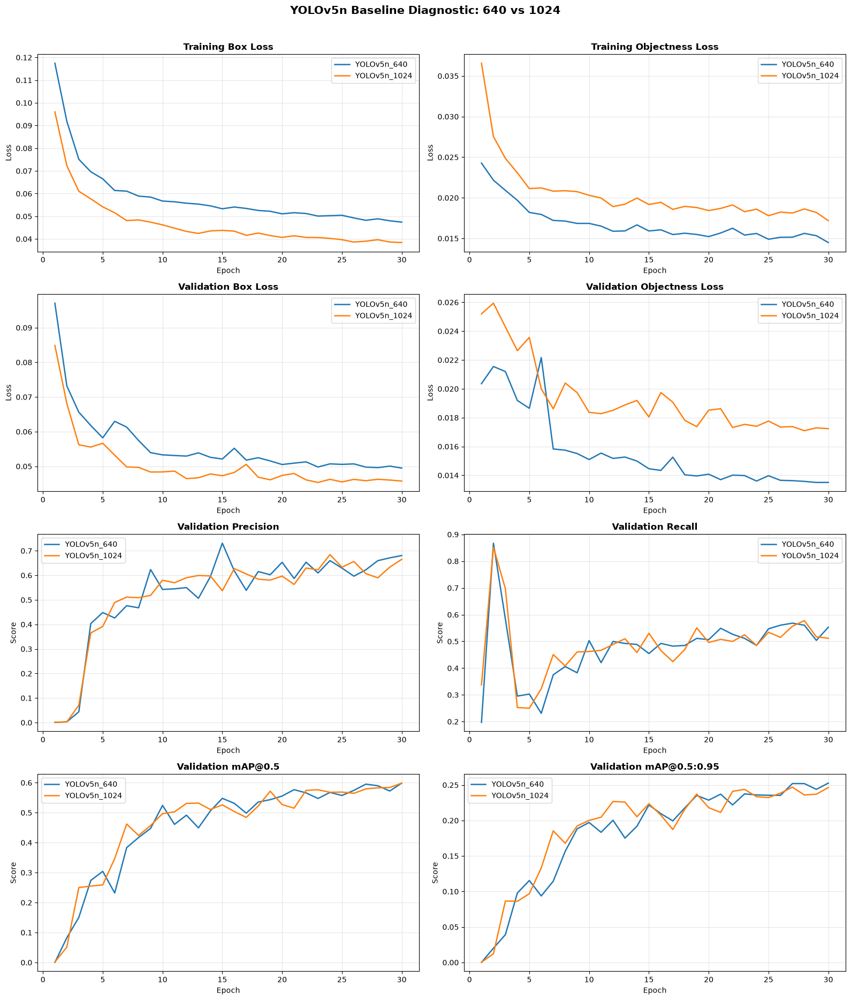


08.7.1 — BASELINE DIAGNOSTIC COMPLETED
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_1_baseline_diagnostic
Summary: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_1_baseline_diagnostic\nb08_7_1_baseline_diagnostic_summary.csv
Curves: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_1_baseline_diagnostic\nb08_7_1_baseline_diagnostic_curves.png
Validation only — Test set was not accessed.


In [1]:
# 08.7.1 — Baseline Diagnostic 

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cấu hình đường dẫn
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

RUNS = {
    "YOLOv5n_640": (
        OUTPUT_ROOT
        / "nb08_6_yolov5_baseline"
        / "yolov5n_baseline_640_b4_20261115_013121"
    ),
    "YOLOv5n_1024": (
        OUTPUT_ROOT
        / "nb08_6_7_yolov5_1024_full_training"
        / "yolov5n_1024_b1_30ep_20261115_1952162"
    )
}

DIAGNOSTIC_DIR = OUTPUT_ROOT / "nb08_7_1_baseline_diagnostic"
DIAGNOSTIC_DIR.mkdir(parents=True, exist_ok=True)

# 2. Kiểm tra dữ liệu và checkpoint
required_columns = [
    "epoch",
    "train/box_loss",
    "train/obj_loss",
    "val/box_loss",
    "val/obj_loss",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95"
]

results_data = {}
summary_rows = []

for config, run_dir in RUNS.items():
    results_path = run_dir / "results.csv"
    best_path = run_dir / "weights" / "best.pt"
    last_path = run_dir / "weights" / "last.pt"

    print(f"\n{'=' * 65}")
    print(f"CONFIGURATION: {config}")
    print(f"Run directory: {run_dir}")

    if not run_dir.exists():
        raise FileNotFoundError(f"Không tìm thấy thư mục: {run_dir}")

    if not results_path.exists():
        raise FileNotFoundError(f"Không tìm thấy results.csv: {results_path}")

    if not best_path.exists() or not last_path.exists():
        raise FileNotFoundError(
            f"Thiếu checkpoint best.pt hoặc last.pt tại {run_dir / 'weights'}"
        )

    df = pd.read_csv(results_path)
    df.columns = df.columns.str.strip()

    missing_columns = [c for c in required_columns if c not in df.columns]
    if missing_columns:
        raise ValueError(
            f"{config} thiếu các cột cần thiết: {missing_columns}\n"
            f"Các cột hiện có: {df.columns.tolist()}"
        )

    df = df.sort_values("epoch").reset_index(drop=True)
    results_data[config] = df

    print(f"Completed epochs: {len(df)}")
    print(f"best.pt: {best_path.stat().st_size / (1024**2):.2f} MB")
    print(f"last.pt: {last_path.stat().st_size / (1024**2):.2f} MB")

    # 3. Tổng hợp chỉ số
    metric_columns = {
        "Precision": "metrics/precision",
        "Recall": "metrics/recall",
        "mAP50": "metrics/mAP_0.5",
        "mAP50_95": "metrics/mAP_0.5:0.95"
    }

    row = {
        "configuration": config,
        "completed_epochs": len(df),
        "best_checkpoint_exists": best_path.exists(),
        "last_checkpoint_exists": last_path.exists()
    }

    for metric_name, column in metric_columns.items():
        best_idx = df[column].idxmax()
        best_row = df.loc[best_idx]

        row[f"best_{metric_name}"] = best_row[column]
        row[f"best_{metric_name}_epoch"] = int(best_row["epoch"]) + 1
        row[f"final_{metric_name}"] = df.iloc[-1][column]

    loss_columns = [
        "train/box_loss",
        "train/obj_loss",
        "val/box_loss",
        "val/obj_loss"
    ]

    for column in loss_columns:
        row[f"initial_{column}"] = df.iloc[0][column]
        row[f"final_{column}"] = df.iloc[-1][column]

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

# 4. Hiển thị bảng chẩn đoán
print("\n" + "=" * 65)
print("BASELINE METRIC DIAGNOSTIC")
display(
    summary_df[
        [
            "configuration",
            "completed_epochs",
            "best_Precision",
            "best_Precision_epoch",
            "best_Recall",
            "best_Recall_epoch",
            "best_mAP50",
            "best_mAP50_epoch",
            "best_mAP50_95",
            "best_mAP50_95_epoch",
            "final_Precision",
            "final_Recall",
            "final_mAP50",
            "final_mAP50_95"
        ]
    ].round(5)
)

print("\nLOSS CHANGE")
display(
    summary_df[
        [
            "configuration",
            "initial_train/box_loss",
            "final_train/box_loss",
            "initial_train/obj_loss",
            "final_train/obj_loss",
            "initial_val/box_loss",
            "final_val/box_loss",
            "initial_val/obj_loss",
            "final_val/obj_loss"
        ]
    ].round(5)
)

# 5. Vẽ đường cong huấn luyện
plot_specs = [
    ("train/box_loss", "Training Box Loss", "Loss"),
    ("train/obj_loss", "Training Objectness Loss", "Loss"),
    ("val/box_loss", "Validation Box Loss", "Loss"),
    ("val/obj_loss", "Validation Objectness Loss", "Loss"),
    ("metrics/precision", "Validation Precision", "Score"),
    ("metrics/recall", "Validation Recall", "Score"),
    ("metrics/mAP_0.5", "Validation mAP@0.5", "Score"),
    ("metrics/mAP_0.5:0.95", "Validation mAP@0.5:0.95", "Score")
]

fig, axes = plt.subplots(4, 2, figsize=(16, 19))
axes = axes.flatten()

for ax, (column, title, ylabel) in zip(axes, plot_specs):
    for config, df in results_data.items():
        ax.plot(
            df["epoch"] + 1,
            df[column],
            label=config,
            linewidth=1.8
        )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "YOLOv5n Baseline Diagnostic: 640 vs 1024",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.97])

plot_path = DIAGNOSTIC_DIR / "nb08_7_1_baseline_diagnostic_curves.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

# 6. Xuất báo cáo
summary_path = DIAGNOSTIC_DIR / "nb08_7_1_baseline_diagnostic_summary.csv"

summary_df.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 65)
print("08.7.1 — BASELINE DIAGNOSTIC COMPLETED")
print(f"Output directory: {DIAGNOSTIC_DIR}")
print(f"Summary: {summary_path}")
print(f"Curves: {plot_path}")
print("Validation only — Test set was not accessed.")


Validation images: 249
YOLO repository: C:\Breast-Cancer-CBIS-DDSM\external\yolov5
Dataset YAML: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\data.yaml

INFERENCE: YOLOv5n_640
Image size: 640
Inference completed: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_2_validation_error_analysis\inference\YOLOv5n_640\labels

INFERENCE: YOLOv5n_1024
Image size: 1024
Inference completed: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_2_validation_error_analysis\inference\YOLOv5n_1024\labels

Đang phân tích: YOLOv5n_640

Đang phân tích: YOLOv5n_1024

VALIDATION METRICS BY CONFIDENCE AND IoU


,configuration,confidence_threshold,IoU_threshold,TP,FP,FN,Precision,Recall,F1
0,YOLOv5n_640,0.05,0.50,201,468,63,0.3004,0.7614,0.4309
1,YOLOv5n_640,0.05,0.75,88,581,176,0.1315,0.3333,0.1886
2,YOLOv5n_640,0.10,0.50,181,269,83,0.4022,0.6856,0.5070
3,YOLOv5n_640,0.10,0.75,80,370,184,0.1778,0.3030,0.2241
4,YOLOv5n_640,0.25,0.50,142,81,122,0.6368,0.5379,0.5832
5,YOLOv5n_640,0.25,0.75,71,152,193,0.3184,0.2689,0.2916
6,YOLOv5n_1024,0.05,0.50,188,390,76,0.3253,0.7121,0.4466
7,YOLOv5n_1024,0.05,0.75,79,499,185,0.1367,0.2992,0.1876
8,YOLOv5n_1024,0.10,0.50,163,197,101,0.4528,0.6174,0.5224
9,YOLOv5n_1024,0.10,0.75,71,289,193,0.1972,0.2689,0.2276



IMAGE-LEVEL ERROR SUMMARY


,configuration,images,total_GT,total_predictions,total_TP,total_FP,total_FN,images_with_FN,images_with_FP
0,YOLOv5n_1024,249,264,360,163,197,101,97,138
1,YOLOv5n_640,249,264,450,181,269,83,80,168


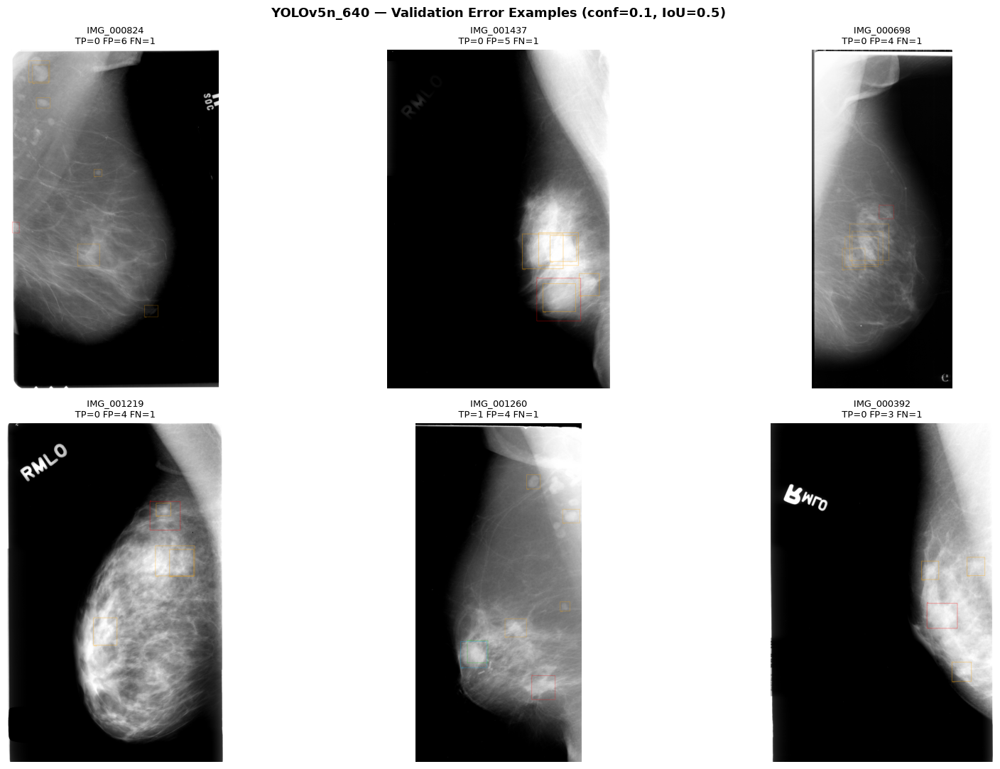

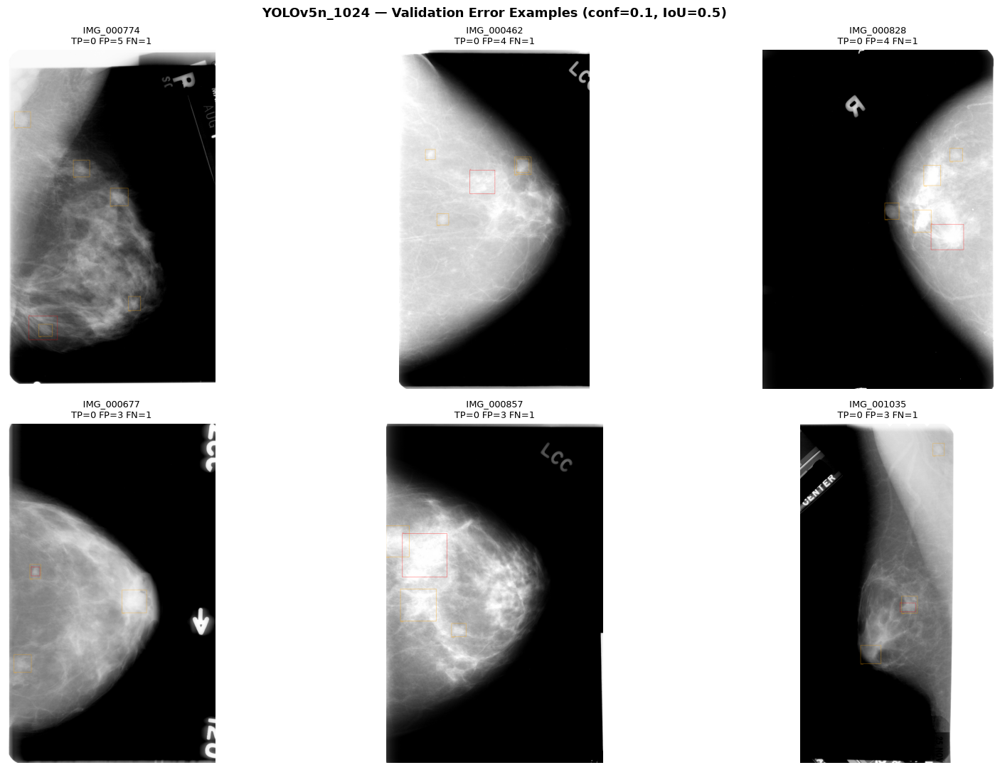


08.7.2 — VALIDATION ERROR ANALYSIS COMPLETED
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_2_validation_error_analysis
Metrics: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_2_validation_error_analysis\nb08_7_2_validation_metrics.csv
Image errors: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_2_validation_error_analysis\nb08_7_2_image_level_errors.csv
Error summary: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_2_validation_error_analysis\nb08_7_2_error_summary.csv
Inference and error analysis used Validation only.


In [2]:
# 08.7.2 — Validation Error Analysis
import os
import sys
import subprocess
import cv2

# 1. Cấu hình
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"
YOLO_REPO = PROJECT_ROOT / "external" / "yolov5"
DETECT_SCRIPT = YOLO_REPO / "detect.py"

DATASET_ROOT = OUTPUT_ROOT / "nb08_3_yolo_dataset"
DATA_YAML = DATASET_ROOT / "data.yaml"
VAL_IMAGE_DIR = DATASET_ROOT / "images" / "validation"
VAL_LABEL_DIR = DATASET_ROOT / "labels" / "validation"

BASELINE_RUNS = {
    "YOLOv5n_640": {
        "weights": OUTPUT_ROOT / "nb08_6_yolov5_baseline"
                   / "yolov5n_baseline_640_b4_20261115_013121"
                   / "weights" / "best.pt",
        "imgsz": 640
    },
    "YOLOv5n_1024": {
        "weights": OUTPUT_ROOT / "nb08_6_7_yolov5_1024_full_training"
                   / "yolov5n_1024_b1_30ep_20261115_1952162"
                   / "weights" / "best.pt",
        "imgsz": 1024
    }
}

OUTPUT_DIR = OUTPUT_ROOT / "nb08_7_2_validation_error_analysis"
INFERENCE_ROOT = OUTPUT_DIR / "inference"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONF_THRESHOLDS = [0.05, 0.10, 0.25]
IOU_THRESHOLDS = [0.50, 0.75]
VISUAL_CONF_THRESHOLD = 0.10
MATCH_IOU_THRESHOLD = 0.50

# 2. Kiểm tra nguồn dữ liệu
for path in [
    YOLO_REPO,
    DETECT_SCRIPT,
    DATA_YAML,
    VAL_IMAGE_DIR,
    VAL_LABEL_DIR
]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

image_paths = sorted(
    p for p in VAL_IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
)

if not image_paths:
    raise RuntimeError("Không tìm thấy ảnh Validation.")

image_stems = [p.stem for p in image_paths]

if len(image_stems) != len(set(image_stems)):
    raise ValueError("Tên ảnh trùng nhau, không thể ánh xạ prediction an toàn.")

missing_gt = [
    p.stem for p in image_paths
    if not (VAL_LABEL_DIR / f"{p.stem}.txt").exists()
]

if missing_gt:
    raise FileNotFoundError(
        f"Có {len(missing_gt)} ảnh thiếu Ground Truth label. "
        f"Ví dụ: {missing_gt[:5]}"
    )

print(f"Validation images: {len(image_paths)}")
print(f"YOLO repository: {YOLO_REPO}")
print(f"Dataset YAML: {DATA_YAML}")

# 3. Chạy inference cho hai baseline
prediction_dirs = {}

for config, settings in BASELINE_RUNS.items():
    weights_path = settings["weights"]
    imgsz = settings["imgsz"]

    if not weights_path.exists():
        raise FileNotFoundError(f"Không tìm thấy checkpoint: {weights_path}")

    inference_dir = INFERENCE_ROOT / config
    inference_dir.mkdir(parents=True, exist_ok=True)

    command = [
        sys.executable,
        str(DETECT_SCRIPT),
        "--weights", str(weights_path),
        "--source", str(VAL_IMAGE_DIR),
        "--data", str(DATA_YAML),
        "--imgsz", str(imgsz),
        "--conf-thres", "0.001",
        "--iou-thres", "0.60",
        "--max-det", "1000",
        "--device", "0",
        "--save-txt",
        "--save-conf",
        "--nosave",
        "--project", str(INFERENCE_ROOT),
        "--name", config,
        "--exist-ok"
    ]

    print(f"\n{'=' * 65}")
    print(f"INFERENCE: {config}")
    print(f"Image size: {imgsz}")

    result = subprocess.run(
        command,
        cwd=str(YOLO_REPO),
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace"
    )

    log_path = inference_dir / "inference.log"
    log_path.write_text(
        result.stdout + "\n" + result.stderr,
        encoding="utf-8"
    )

    if result.returncode != 0:
        print(result.stdout[-5000:])
        print(result.stderr[-5000:])
        raise RuntimeError(
            f"Inference thất bại ở {config}. Xem log: {log_path}"
        )

    prediction_dir = inference_dir / "labels"

    if not prediction_dir.exists():
        raise FileNotFoundError(
            f"Không tìm thấy thư mục prediction: {prediction_dir}"
        )

    prediction_dirs[config] = prediction_dir
    print(f"Inference completed: {prediction_dir}")

# 4. Đọc YOLO labels và chuyển đổi tọa độ
def read_yolo_labels(path, has_confidence=False):
    if not path.exists() or path.stat().st_size == 0:
        return np.empty((0, 6 if has_confidence else 5), dtype=float)

    data = np.loadtxt(path, dtype=float, ndmin=2)

    expected_cols = 6 if has_confidence else 5
    if data.shape[1] != expected_cols:
        raise ValueError(
            f"Label không đúng định dạng tại {path}: "
            f"có {data.shape[1]} cột, cần {expected_cols}."
        )

    return data


def xywh_to_xyxy(boxes, width, height):
    if len(boxes) == 0:
        return np.empty((0, 4), dtype=float)

    x, y, w, h = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]

    return np.column_stack([
        (x - w / 2) * width,
        (y - h / 2) * height,
        (x + w / 2) * width,
        (y + h / 2) * height
    ])


def calculate_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, box_a[2] - box_a[0]) * max(0, box_a[3] - box_a[1])
    area_b = max(0, box_b[2] - box_b[0]) * max(0, box_b[3] - box_b[1])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


# 5. Ghép prediction với Ground Truth
def match_detections(gt_boxes, pred_boxes, pred_scores, iou_threshold):
    matched_gt = set()
    matched_pred = set()
    matches = []

    order = np.argsort(-pred_scores)

    for pred_idx in order:
        if len(gt_boxes) == 0:
            continue

        candidates = [
            (gt_idx, calculate_iou(pred_boxes[pred_idx], gt_boxes[gt_idx]))
            for gt_idx in range(len(gt_boxes))
            if gt_idx not in matched_gt
        ]

        if not candidates:
            continue

        best_gt, best_iou = max(candidates, key=lambda x: x[1])

        if best_iou >= iou_threshold:
            matched_gt.add(best_gt)
            matched_pred.add(pred_idx)
            matches.append((best_gt, pred_idx, best_iou))

    false_negatives = [
        idx for idx in range(len(gt_boxes))
        if idx not in matched_gt
    ]

    false_positives = [
        idx for idx in range(len(pred_boxes))
        if idx not in matched_pred
    ]

    return matches, false_positives, false_negatives


# 6. Đọc dữ liệu và tính kết quả
all_results = {}
metric_rows = []
image_error_rows = []

for config, prediction_dir in prediction_dirs.items():
    print(f"\nĐang phân tích: {config}")

    image_data = {}

    for image_path in image_paths:
        image = cv2.imread(str(image_path))

        if image is None:
            raise RuntimeError(f"Không đọc được ảnh: {image_path}")

        height, width = image.shape[:2]

        gt_raw = read_yolo_labels(
            VAL_LABEL_DIR / f"{image_path.stem}.txt"
        )

        pred_raw = read_yolo_labels(
            prediction_dir / f"{image_path.stem}.txt",
            has_confidence=True
        )

        gt_boxes = xywh_to_xyxy(gt_raw[:, 1:5], width, height)

        pred_boxes = xywh_to_xyxy(pred_raw[:, 1:5], width, height)
        pred_scores = pred_raw[:, 5] if len(pred_raw) else np.empty(0)

        image_data[image_path.stem] = {
            "path": image_path,
            "width": width,
            "height": height,
            "gt_boxes": gt_boxes,
            "pred_boxes": pred_boxes,
            "pred_scores": pred_scores
        }

    all_results[config] = image_data

    for conf_threshold in CONF_THRESHOLDS:
        for iou_threshold in IOU_THRESHOLDS:
            total_tp = total_fp = total_fn = 0

            for image_id, data in image_data.items():
                keep = data["pred_scores"] >= conf_threshold

                pred_boxes = data["pred_boxes"][keep]
                pred_scores = data["pred_scores"][keep]

                matches, fps, fns = match_detections(
                    data["gt_boxes"],
                    pred_boxes,
                    pred_scores,
                    iou_threshold
                )

                total_tp += len(matches)
                total_fp += len(fps)
                total_fn += len(fns)

            precision = (
                total_tp / (total_tp + total_fp)
                if total_tp + total_fp else 0.0
            )
            recall = (
                total_tp / (total_tp + total_fn)
                if total_tp + total_fn else 0.0
            )
            f1 = (
                2 * precision * recall / (precision + recall)
                if precision + recall else 0.0
            )

            metric_rows.append({
                "configuration": config,
                "confidence_threshold": conf_threshold,
                "IoU_threshold": iou_threshold,
                "TP": total_tp,
                "FP": total_fp,
                "FN": total_fn,
                "Precision": precision,
                "Recall": recall,
                "F1": f1
            })

    # Lưu lỗi theo từng ảnh tại confidence 0.10 và IoU 0.50
    for image_id, data in image_data.items():
        keep = data["pred_scores"] >= VISUAL_CONF_THRESHOLD

        pred_boxes = data["pred_boxes"][keep]
        pred_scores = data["pred_scores"][keep]

        matches, fps, fns = match_detections(
            data["gt_boxes"],
            pred_boxes,
            pred_scores,
            MATCH_IOU_THRESHOLD
        )

        image_error_rows.append({
            "configuration": config,
            "image_id": image_id,
            "ground_truth_count": len(data["gt_boxes"]),
            "prediction_count": len(pred_boxes),
            "TP": len(matches),
            "FP": len(fps),
            "FN": len(fns),
            "error_count": len(fps) + len(fns),
            "mean_matched_IoU": (
                np.mean([m[2] for m in matches])
                if matches else np.nan
            )
        })

# 7. Xuất và hiển thị bảng kết quả
metrics_df = pd.DataFrame(metric_rows)
errors_df = pd.DataFrame(image_error_rows)

print("\n" + "=" * 65)
print("VALIDATION METRICS BY CONFIDENCE AND IoU")
display(metrics_df.round(4))

print("\nIMAGE-LEVEL ERROR SUMMARY")
error_summary = (
    errors_df.groupby("configuration")
    .agg(
        images=("image_id", "count"),
        total_GT=("ground_truth_count", "sum"),
        total_predictions=("prediction_count", "sum"),
        total_TP=("TP", "sum"),
        total_FP=("FP", "sum"),
        total_FN=("FN", "sum"),
        images_with_FN=("FN", lambda x: int((x > 0).sum())),
        images_with_FP=("FP", lambda x: int((x > 0).sum()))
    )
    .reset_index()
)

display(error_summary)

# 8. Trực quan hóa các ảnh có lỗi
for config, image_data in all_results.items():
    subset = errors_df[
        (errors_df["configuration"] == config)
        & (errors_df["error_count"] > 0)
    ].sort_values(
        ["error_count", "FN", "FP"],
        ascending=False
    ).head(6)

    if subset.empty:
        print(f"{config}: Không có lỗi tại ngưỡng đã chọn.")
        continue

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, subset.iterrows()):
        image_id = row["image_id"]
        data = image_data[image_id]

        image = cv2.imread(str(data["path"]))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        keep = data["pred_scores"] >= VISUAL_CONF_THRESHOLD
        pred_boxes = data["pred_boxes"][keep]
        pred_scores = data["pred_scores"][keep]

        matches, fps, fns = match_detections(
            data["gt_boxes"],
            pred_boxes,
            pred_scores,
            MATCH_IOU_THRESHOLD
        )

        matched_gt = {m[0] for m in matches}
        matched_pred = {m[1] for m in matches}

        # Ground Truth: xanh lá nếu khớp, đỏ nếu bị bỏ sót
        for idx, box in enumerate(data["gt_boxes"]):
            x1, y1, x2, y2 = map(int, box)
            is_missed = idx not in matched_gt

            color = (255, 0, 0) if is_missed else (0, 200, 0)
            cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

            label = "FN" if is_missed else "GT matched"
            cv2.putText(
                image, label, (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1
            )

        # Prediction: xanh dương nếu khớp, cam nếu FP
        pred_indices = np.where(keep)[0]

        for local_idx, box in enumerate(pred_boxes):
            x1, y1, x2, y2 = map(int, box)
            is_fp = local_idx in fps

            color = (255, 165, 0) if is_fp else (0, 180, 255)
            score = pred_scores[local_idx]

            cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
            cv2.putText(
                image,
                f"{'FP' if is_fp else 'Pred'} {score:.2f}",
                (x1, min(image.shape[0] - 5, y2 + 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                color,
                1
            )

        ax.imshow(image)
        ax.set_title(
            f"{image_id}\nTP={row['TP']} FP={row['FP']} FN={row['FN']}",
            fontsize=9
        )
        ax.axis("off")

    for ax in axes[len(subset):]:
        ax.axis("off")

    fig.suptitle(
        f"{config} — Validation Error Examples "
        f"(conf={VISUAL_CONF_THRESHOLD}, IoU={MATCH_IOU_THRESHOLD})",
        fontsize=13,
        fontweight="bold"
    )
    plt.tight_layout()

    figure_path = OUTPUT_DIR / f"{config}_error_examples.png"
    fig.savefig(figure_path, dpi=160, bbox_inches="tight")
    plt.show()

# 9. Lưu báo cáo
metrics_path = OUTPUT_DIR / "nb08_7_2_validation_metrics.csv"
errors_path = OUTPUT_DIR / "nb08_7_2_image_level_errors.csv"
summary_path = OUTPUT_DIR / "nb08_7_2_error_summary.csv"

metrics_df.to_csv(metrics_path, index=False, encoding="utf-8-sig")
errors_df.to_csv(errors_path, index=False, encoding="utf-8-sig")
error_summary.to_csv(summary_path, index=False, encoding="utf-8-sig")

print("\n" + "=" * 65)
print("08.7.2 — VALIDATION ERROR ANALYSIS COMPLETED")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Metrics: {metrics_path}")
print(f"Image errors: {errors_path}")
print(f"Error summary: {summary_path}")
print("Inference and error analysis used Validation only.")


In [4]:
# 08.7.3 — YOLOv5n 640 Fine-tuning

from datetime import datetime
import os
import sys
import subprocess
import yaml
import pandas as pd

# 1. Paths and configuration
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLO_REPO = PROJECT_ROOT / "external" / "yolov5"
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

BASELINE_RUN = (
    OUTPUT_ROOT
    / "nb08_6_yolov5_baseline"
    / "yolov5n_baseline_640_b4_20261115_013121"
)

BASELINE_WEIGHTS = BASELINE_RUN / "weights" / "best.pt"
BASELINE_HYP = BASELINE_RUN / "hyp.yaml"
DATA_YAML = OUTPUT_ROOT / "nb08_3_yolo_dataset" / "data.yaml"
TRAIN_SCRIPT = YOLO_REPO / "train.py"

IMAGE_SIZE = 640
BATCH_SIZE = 4
EPOCHS = 20
PATIENCE = 8
LEARNING_RATE = 0.001
SEED = 42

# 2. Validate input files
for path in [
    YOLO_REPO,
    TRAIN_SCRIPT,
    BASELINE_WEIGHTS,
    BASELINE_HYP,
    DATA_YAML
]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

with open(BASELINE_HYP, "r", encoding="utf-8") as f:
    baseline_hyp = yaml.safe_load(f)

if not isinstance(baseline_hyp, dict) or "lr0" not in baseline_hyp:
    raise ValueError("Không đọc được lr0 từ baseline hyp.yaml.")

original_lr = float(baseline_hyp["lr0"])

# 3. Create local NumPy compatibility patch
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

EXPERIMENT_ROOT = OUTPUT_ROOT / "nb08_7_3_yolov5_640_finetuning"
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

COMPAT_DIR = EXPERIMENT_ROOT / f"numpy_compat_{TIMESTAMP}"
COMPAT_DIR.mkdir(parents=True, exist_ok=True)

SITECUSTOMIZE_PATH = COMPAT_DIR / "sitecustomize.py"

SITECUSTOMIZE_PATH.write_text(
    "import numpy as np\n"
    "if not hasattr(np, 'trapz') and hasattr(np, 'trapezoid'):\n"
    "    np.trapz = np.trapezoid\n",
    encoding="utf-8"
)

# Pass compatibility directory to the child Python process
ENV = os.environ.copy()
EXISTING_PYTHONPATH = ENV.get("PYTHONPATH", "")

ENV["PYTHONPATH"] = (
    str(COMPAT_DIR)
    + (os.pathsep + EXISTING_PYTHONPATH if EXISTING_PYTHONPATH else "")
)

# 4. Verify compatibility before training
compat_check = subprocess.run(
    [
        sys.executable,
        "-c",
        "import numpy as np; "
        "print('NumPy:', np.__version__); "
        "print('np.trapz available:', hasattr(np, 'trapz')); "
        "assert hasattr(np, 'trapz')"
    ],
    cwd=str(YOLO_REPO),
    env=ENV,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print("NUMPY COMPATIBILITY CHECK")
print(compat_check.stdout)
if compat_check.returncode != 0:
    print(compat_check.stderr)
    raise RuntimeError("NumPy compatibility check failed. Chưa chạy training.")

# 5. Prepare fine-tuning hyperparameters
fine_tune_hyp = baseline_hyp.copy()
fine_tune_hyp["lr0"] = LEARNING_RATE

if "warmup_epochs" in fine_tune_hyp:
    fine_tune_hyp["warmup_epochs"] = 1.0

HYP_PATH = EXPERIMENT_ROOT / f"hyp_finetune_{TIMESTAMP}.yaml"

with open(HYP_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        fine_tune_hyp,
        f,
        sort_keys=False,
        allow_unicode=True
    )

RUN_NAME = f"yolov5n_640_finetune_lr001_{TIMESTAMP}"
LOG_PATH = EXPERIMENT_ROOT / f"{RUN_NAME}_training.log"

# 6. Training command
command = [
    sys.executable,
    str(TRAIN_SCRIPT),
    "--weights", str(BASELINE_WEIGHTS),
    "--data", str(DATA_YAML),
    "--hyp", str(HYP_PATH),
    "--img", str(IMAGE_SIZE),
    "--batch-size", str(BATCH_SIZE),
    "--epochs", str(EPOCHS),
    "--optimizer", "SGD",
    "--workers", "0",
    "--patience", str(PATIENCE),
    "--seed", str(SEED),
    "--device", "0",
    "--project", str(EXPERIMENT_ROOT),
    "--name", RUN_NAME,
    "--exist-ok",
    "--save-period", "5"
]

print("=" * 65)
print("YOLOv5n 640 FINE-TUNING")
print(f"Initial checkpoint: {BASELINE_WEIGHTS}")
print(f"Baseline learning rate: {original_lr}")
print(f"Fine-tuning learning rate: {LEARNING_RATE}")
print(f"Image size: {IMAGE_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Maximum epochs: {EPOCHS}")
print(f"Patience: {PATIENCE}")
print(f"Seed: {SEED}")
print(f"Compatibility patch: {SITECUSTOMIZE_PATH}")
print(f"Output run: {RUN_NAME}")

# 7. Execute training and save full log
with open(LOG_PATH, "w", encoding="utf-8") as log_file:
    process = subprocess.Popen(
        command,
        cwd=str(YOLO_REPO),
        env=ENV,
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True
    )
    return_code = process.wait()

# 8. Audit training outputs
RUN_DIR = EXPERIMENT_ROOT / RUN_NAME
RESULTS_PATH = RUN_DIR / "results.csv"
BEST_PATH = RUN_DIR / "weights" / "best.pt"
LAST_PATH = RUN_DIR / "weights" / "last.pt"

print("\n" + "=" * 65)
print("FINE-TUNING EXECUTION SUMMARY")
print(f"Return code: {return_code}")
print(f"Run directory: {RUN_DIR}")
print(f"Results CSV: {RESULTS_PATH.exists()}")
print(f"Best checkpoint: {BEST_PATH.exists()}")
print(f"Last checkpoint: {LAST_PATH.exists()}")
print(f"Training log: {LOG_PATH}")

if return_code != 0:
    log_lines = LOG_PATH.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    print("\nLast 60 log lines:")
    print("\n".join(log_lines[-60:]))
    raise RuntimeError("Fine-tuning thất bại. Kiểm tra training log.")

if not RESULTS_PATH.exists() or not BEST_PATH.exists():
    raise RuntimeError("Thiếu results.csv hoặc best.pt sau training.")

# 9. Summarize completed epochs and validation metrics
results = pd.read_csv(RESULTS_PATH)
results.columns = results.columns.str.strip()

metric_columns = [
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95"
]

missing_columns = [c for c in metric_columns if c not in results.columns]
if missing_columns:
    raise ValueError(f"Thiếu các cột metric: {missing_columns}")

print(f"\nCompleted epochs: {len(results)}")
print(f"Best checkpoint size: {BEST_PATH.stat().st_size / 1024**2:.2f} MB")
print(f"Last checkpoint exists: {LAST_PATH.exists()}")

display(
    results[["epoch"] + metric_columns]
    .tail(10)
    .round(5)
)

print("\nBEST VALIDATION METRICS")
best_idx = results["metrics/mAP_0.5:0.95"].idxmax()
display(
    results.loc[[best_idx], ["epoch"] + metric_columns].round(5)
)

print("\n" + "=" * 65)
print("08.7.3 — FINE-TUNING COMPLETED")
print(f"Run directory: {RUN_DIR}")
print(f"Best checkpoint: {BEST_PATH}")
print(f"Results CSV: {RESULTS_PATH}")
print(f"Training log: {LOG_PATH}")
print("Validation used for model selection. Test set was not accessed.")


NUMPY COMPATIBILITY CHECK
NumPy: 2.4.6
np.trapz available: True

YOLOv5n 640 FINE-TUNING
Initial checkpoint: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121\weights\best.pt
Baseline learning rate: 0.01
Fine-tuning learning rate: 0.001
Image size: 640
Batch size: 4
Maximum epochs: 20
Patience: 8
Seed: 42
Compatibility patch: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\numpy_compat_20261116_205312\sitecustomize.py
Output run: yolov5n_640_finetune_lr001_20261116_205312

FINE-TUNING EXECUTION SUMMARY
Return code: 0
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\yolov5n_640_finetune_lr001_20261116_205312
Results CSV: True
Best checkpoint: True
Last checkpoint: True
Training log: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\yolov5n_640_finetune_lr001_20261116_2

,epoch,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95
2,2,0.65012,0.56308,0.59867,0.25209
3,3,0.56632,0.60985,0.60121,0.25610
4,4,0.61487,0.59848,0.61014,0.25280
5,5,0.64616,0.57955,0.59958,0.24972
6,6,0.63503,0.56681,0.59388,0.24931
7,7,0.66232,0.55303,0.58842,0.24004
8,8,0.61330,0.59474,0.59204,0.24058
9,9,0.61172,0.62500,0.59591,0.24786
10,10,0.60276,0.60227,0.60465,0.25090
11,11,0.68111,0.56818,0.60561,0.25239



BEST VALIDATION METRICS


,epoch,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95
3,3,0.56632,0.60985,0.60121,0.2561



08.7.3 — FINE-TUNING COMPLETED
Run directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\yolov5n_640_finetune_lr001_20261116_205312
Best checkpoint: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\yolov5n_640_finetune_lr001_20261116_205312\weights\best.pt
Results CSV: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\yolov5n_640_finetune_lr001_20261116_205312\results.csv
Training log: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\yolov5n_640_finetune_lr001_20261116_205312_training.log
Validation used for model selection. Test set was not accessed.


In [5]:
# 08.7.4 — Baseline vs Fine-tuning Comparison

import cv2
import yaml

# 1. Configuration
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
YOLO_REPO = PROJECT_ROOT / "external" / "yolov5"
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

DATASET_ROOT = OUTPUT_ROOT / "nb08_3_yolo_dataset"
DATA_YAML = DATASET_ROOT / "data.yaml"
VAL_IMAGE_DIR = DATASET_ROOT / "images" / "validation"
VAL_LABEL_DIR = DATASET_ROOT / "labels" / "validation"
DETECT_SCRIPT = YOLO_REPO / "detect.py"

BASELINE_WEIGHTS = (
    OUTPUT_ROOT / "nb08_6_yolov5_baseline"
    / "yolov5n_baseline_640_b4_20261115_013121"
    / "weights" / "best.pt"
)

FINETUNE_RUN = (
    OUTPUT_ROOT / "nb08_7_3_yolov5_640_finetuning"
    / "yolov5n_640_finetune_lr001_20261116_205312"
)

FINETUNE_WEIGHTS = FINETUNE_RUN / "weights" / "best.pt"

BASELINE_PRED_DIR = (
    OUTPUT_ROOT / "nb08_7_2_validation_error_analysis"
    / "inference" / "YOLOv5n_640" / "labels"
)

OUTPUT_DIR = OUTPUT_ROOT / "nb08_7_4_finetune_comparison"
INFERENCE_ROOT = OUTPUT_DIR / "inference"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONF_THRESHOLDS = [0.05, 0.10, 0.25]
IOU_THRESHOLDS = [0.50, 0.75]

# 2. Validate inputs
for path in [
    YOLO_REPO, DETECT_SCRIPT, DATA_YAML,
    VAL_IMAGE_DIR, VAL_LABEL_DIR,
    BASELINE_WEIGHTS, FINETUNE_WEIGHTS
]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

image_paths = sorted(
    p for p in VAL_IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
)

if len(image_paths) != 249:
    raise ValueError(
        f"Số ảnh Validation khác dự kiến: {len(image_paths)}. "
        "Kiểm tra lại dataset trước khi đánh giá."
    )

for p in image_paths:
    if not (VAL_LABEL_DIR / f"{p.stem}.txt").exists():
        raise FileNotFoundError(f"Thiếu Ground Truth: {p.stem}")

# 3. Run fine-tuned inference
FINETUNE_PRED_DIR = INFERENCE_ROOT / "YOLOv5n_640_finetuned"
FINETUNE_PRED_DIR.mkdir(parents=True, exist_ok=True)

command = [
    sys.executable,
    str(DETECT_SCRIPT),
    "--weights", str(FINETUNE_WEIGHTS),
    "--source", str(VAL_IMAGE_DIR),
    "--data", str(DATA_YAML),
    "--imgsz", "640",
    "--conf-thres", "0.001",
    "--iou-thres", "0.60",
    "--max-det", "1000",
    "--device", "0",
    "--save-txt",
    "--save-conf",
    "--nosave",
    "--project", str(INFERENCE_ROOT),
    "--name", "YOLOv5n_640_finetuned",
    "--exist-ok"
]

print("=" * 65)
print("FINE-TUNED MODEL INFERENCE")

result = subprocess.run(
    command,
    cwd=str(YOLO_REPO),
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

log_path = OUTPUT_DIR / "finetuned_inference.log"
log_path.write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)

if result.returncode != 0:
    print(result.stdout[-4000:])
    print(result.stderr[-4000:])
    raise RuntimeError("Fine-tuned inference thất bại.")

if not FINETUNE_PRED_DIR.joinpath("labels").exists():
    raise FileNotFoundError("Không tìm thấy prediction labels của fine-tuning.")

FINETUNE_PRED_DIR = FINETUNE_PRED_DIR / "labels"

# 4. Verify baseline prediction cache
if not BASELINE_PRED_DIR.exists():
    raise FileNotFoundError(
        "Không tìm thấy prediction baseline từ 08.7.2. "
        "Cần chạy lại inference baseline trước."
    )

def read_labels(path, with_conf=False):
    columns = 6 if with_conf else 5

    if not path.exists() or path.stat().st_size == 0:
        return np.empty((0, columns), dtype=float)

    data = np.loadtxt(path, dtype=float, ndmin=2)

    if data.shape[1] != columns:
        raise ValueError(f"Định dạng label không hợp lệ: {path}")

    return data


def xywh_to_xyxy(boxes, width, height):
    if len(boxes) == 0:
        return np.empty((0, 4), dtype=float)

    x, y, w, h = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]

    return np.column_stack([
        (x - w / 2) * width,
        (y - h / 2) * height,
        (x + w / 2) * width,
        (y + h / 2) * height
    ])


def calculate_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def match_boxes(gt, pred, scores, threshold):
    order = np.argsort(-scores)
    used_gt = set()
    used_pred = set()
    matched_ious = []

    for pred_idx in order:
        candidates = [
            (gt_idx, calculate_iou(pred[pred_idx], gt[gt_idx]))
            for gt_idx in range(len(gt))
            if gt_idx not in used_gt
        ]

        if not candidates:
            continue

        gt_idx, best_iou = max(candidates, key=lambda x: x[1])

        if best_iou >= threshold:
            used_gt.add(gt_idx)
            used_pred.add(pred_idx)
            matched_ious.append(best_iou)

    tp = len(used_pred)
    fp = len(pred) - tp
    fn = len(gt) - tp

    return tp, fp, fn, matched_ious


# 5. Load predictions and ground truth
models = {
    "Baseline_640": BASELINE_PRED_DIR,
    "Fine-tuned_640": FINETUNE_PRED_DIR
}

metric_rows = []
image_rows = []

for model_name, pred_dir in models.items():
    print(f"\nLoading: {model_name}")

    for image_path in image_paths:
        image = cv2.imread(str(image_path))
        if image is None:
            raise RuntimeError(f"Không đọc được ảnh: {image_path}")

        height, width = image.shape[:2]

        gt_raw = read_labels(
            VAL_LABEL_DIR / f"{image_path.stem}.txt"
        )

        pred_raw = read_labels(
            pred_dir / f"{image_path.stem}.txt",
            with_conf=True
        )

        gt_boxes = xywh_to_xyxy(gt_raw[:, 1:5], width, height)
        pred_boxes = xywh_to_xyxy(pred_raw[:, 1:5], width, height)

        scores = pred_raw[:, 5] if len(pred_raw) else np.empty(0)

        for conf in CONF_THRESHOLDS:
            keep = scores >= conf
            boxes = pred_boxes[keep]
            box_scores = scores[keep]

            for iou_threshold in IOU_THRESHOLDS:
                tp, fp, fn, matched_ious = match_boxes(
                    gt_boxes, boxes, box_scores, iou_threshold
                )

                image_rows.append({
                    "model": model_name,
                    "image_id": image_path.stem,
                    "confidence": conf,
                    "IoU_threshold": iou_threshold,
                    "GT": len(gt_boxes),
                    "predictions": len(boxes),
                    "TP": tp,
                    "FP": fp,
                    "FN": fn,
                    "mean_matched_IoU": (
                        np.mean(matched_ious) if matched_ious else np.nan
                    )
                })

# 6. Aggregate metrics
image_df = pd.DataFrame(image_rows)

for (model_name, conf, iou_threshold), group in image_df.groupby(
    ["model", "confidence", "IoU_threshold"]
):
    tp = int(group["TP"].sum())
    fp = int(group["FP"].sum())
    fn = int(group["FN"].sum())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    metric_rows.append({
        "model": model_name,
        "confidence": conf,
        "IoU_threshold": iou_threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "mean_matched_IoU": group["mean_matched_IoU"].mean()
    })

metrics_df = pd.DataFrame(metric_rows)

# 7. Compare changes against baseline
comparison_rows = []

for conf in CONF_THRESHOLDS:
    for iou_threshold in IOU_THRESHOLDS:
        base = metrics_df[
            (metrics_df["model"] == "Baseline_640")
            & (metrics_df["confidence"] == conf)
            & (metrics_df["IoU_threshold"] == iou_threshold)
        ].iloc[0]

        tuned = metrics_df[
            (metrics_df["model"] == "Fine-tuned_640")
            & (metrics_df["confidence"] == conf)
            & (metrics_df["IoU_threshold"] == iou_threshold)
        ].iloc[0]

        comparison_rows.append({
            "confidence": conf,
            "IoU_threshold": iou_threshold,
            "baseline_TP": base["TP"],
            "finetuned_TP": tuned["TP"],
            "delta_TP": tuned["TP"] - base["TP"],
            "baseline_FP": base["FP"],
            "finetuned_FP": tuned["FP"],
            "delta_FP": tuned["FP"] - base["FP"],
            "baseline_FN": base["FN"],
            "finetuned_FN": tuned["FN"],
            "delta_FN": tuned["FN"] - base["FN"],
            "baseline_Precision": base["Precision"],
            "finetuned_Precision": tuned["Precision"],
            "delta_Precision": tuned["Precision"] - base["Precision"],
            "baseline_Recall": base["Recall"],
            "finetuned_Recall": tuned["Recall"],
            "delta_Recall": tuned["Recall"] - base["Recall"],
            "baseline_F1": base["F1"],
            "finetuned_F1": tuned["F1"],
            "delta_F1": tuned["F1"] - base["F1"]
        })

comparison_df = pd.DataFrame(comparison_rows)

# 8. Display results
print("\n" + "=" * 65)
print("BASELINE VS FINE-TUNED — VALIDATION METRICS")
display(metrics_df.round(4))

print("\nFINE-TUNING IMPROVEMENT")
display(comparison_df.round(4))

# 9. Save reports
metrics_path = OUTPUT_DIR / "nb08_7_4_validation_metrics.csv"
comparison_path = OUTPUT_DIR / "nb08_7_4_baseline_vs_finetuning.csv"
image_path = OUTPUT_DIR / "nb08_7_4_image_level_metrics.csv"

metrics_df.to_csv(metrics_path, index=False, encoding="utf-8-sig")
comparison_df.to_csv(comparison_path, index=False, encoding="utf-8-sig")
image_df.to_csv(image_path, index=False, encoding="utf-8-sig")

print("\n" + "=" * 65)
print("08.7.4 — BASELINE VS FINE-TUNING COMPLETED")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Metrics: {metrics_path}")
print(f"Comparison: {comparison_path}")
print(f"Image-level results: {image_path}")
print("Same 249 Validation images, same GT, same matching procedure.")
print("Test set was not accessed.")


FINE-TUNED MODEL INFERENCE

Loading: Baseline_640

Loading: Fine-tuned_640

BASELINE VS FINE-TUNED — VALIDATION METRICS


,model,confidence,IoU_threshold,TP,FP,FN,Precision,Recall,F1,mean_matched_IoU
0,Baseline_640,0.05,0.50,201,468,63,0.3004,0.7614,0.4309,0.7170
1,Baseline_640,0.05,0.75,88,581,176,0.1315,0.3333,0.1886,0.8247
2,Baseline_640,0.10,0.50,181,269,83,0.4022,0.6856,0.5070,0.7226
3,Baseline_640,0.10,0.75,80,370,184,0.1778,0.3030,0.2241,0.8249
4,Baseline_640,0.25,0.50,142,81,122,0.6368,0.5379,0.5832,0.7384
5,Baseline_640,0.25,0.75,71,152,193,0.3184,0.2689,0.2916,0.8280
6,Fine-tuned_640,0.05,0.50,196,491,68,0.2853,0.7424,0.4122,0.7168
7,Fine-tuned_640,0.05,0.75,91,596,173,0.1325,0.3447,0.1914,0.8137
8,Fine-tuned_640,0.10,0.50,185,272,79,0.4048,0.7008,0.5132,0.7215
9,Fine-tuned_640,0.10,0.75,87,370,177,0.1904,0.3295,0.2413,0.8137



FINE-TUNING IMPROVEMENT


,confidence,IoU_threshold,baseline_TP,finetuned_TP,delta_TP,baseline_FP,finetuned_FP,delta_FP,baseline_FN,finetuned_FN,delta_FN,baseline_Precision,finetuned_Precision,delta_Precision,baseline_Recall,finetuned_Recall,delta_Recall,baseline_F1,finetuned_F1,delta_F1
0,0.05,0.50,201,196,-5,468,491,23,63,68,5,0.3004,0.2853,-0.0152,0.7614,0.7424,-0.0189,0.4309,0.4122,-0.0187
1,0.05,0.75,88,91,3,581,596,15,176,173,-3,0.1315,0.1325,0.0009,0.3333,0.3447,0.0114,0.1886,0.1914,0.0027
2,0.10,0.50,181,185,4,269,272,3,83,79,-4,0.4022,0.4048,0.0026,0.6856,0.7008,0.0152,0.5070,0.5132,0.0062
3,0.10,0.75,80,87,7,370,370,0,184,177,-7,0.1778,0.1904,0.0126,0.3030,0.3295,0.0265,0.2241,0.2413,0.0172
4,0.25,0.50,142,145,3,81,87,6,122,119,-3,0.6368,0.6250,-0.0118,0.5379,0.5492,0.0114,0.5832,0.5847,0.0015
5,0.25,0.75,71,73,2,152,159,7,193,191,-2,0.3184,0.3147,-0.0037,0.2689,0.2765,0.0076,0.2916,0.2944,0.0028



08.7.4 — BASELINE VS FINE-TUNING COMPLETED
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_4_finetune_comparison
Metrics: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_4_finetune_comparison\nb08_7_4_validation_metrics.csv
Comparison: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_4_finetune_comparison\nb08_7_4_baseline_vs_finetuning.csv
Image-level results: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_4_finetune_comparison\nb08_7_4_image_level_metrics.csv
Same 249 Validation images, same GT, same matching procedure.
Test set was not accessed.


In [6]:
# 08.7.5 — Comparative Error Analysis

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Locate existing 08.7.4 outputs
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

ANALYSIS_DIR = OUTPUT_ROOT / "nb08_7_4_finetune_comparison"
IMAGE_FILE = ANALYSIS_DIR / "nb08_7_4_image_level_metrics.csv"
METRIC_FILE = ANALYSIS_DIR / "nb08_7_4_validation_metrics.csv"

if not IMAGE_FILE.exists():
    raise FileNotFoundError(f"Không tìm thấy: {IMAGE_FILE}")

if not METRIC_FILE.exists():
    raise FileNotFoundError(f"Không tìm thấy: {METRIC_FILE}")

image_df = pd.read_csv(IMAGE_FILE)
metric_df = pd.read_csv(METRIC_FILE)

print("=" * 65)
print("08.7.5 — COMPARATIVE ERROR ANALYSIS")
print("\nImage-level columns:")
print(image_df.columns.tolist())
print("\nMetric columns:")
print(metric_df.columns.tolist())

# 2. Normalize column names for robust matching
def normalize_columns(df):
    result = df.copy()
    result.columns = (
        result.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )
    return result

image_df = normalize_columns(image_df)
metric_df = normalize_columns(metric_df)

# 3. Validate image-level schema
required_identity = ["image_id"]
if not any(c in image_df.columns for c in required_identity):
    raise ValueError(
        "Image-level CSV chưa có image_id. "
        "Kiểm tra cấu trúc CSV trước khi phân tích."
    )

# Detect model identifier
model_col = next(
    (c for c in ["model", "configuration", "model_name"] if c in image_df.columns),
    None
)

if model_col is None:
    raise ValueError("Không tìm thấy cột định danh model.")

# Detect per-image TP/FP/FN fields
possible_fields = {
    "tp": ["tp", "total_tp"],
    "fp": ["fp", "total_fp"],
    "fn": ["fn", "total_fn"]
}

selected = {}
for key, candidates in possible_fields.items():
    selected[key] = next(
        (c for c in candidates if c in image_df.columns),
        None
    )

if any(v is None for v in selected.values()):
    raise ValueError(
        "Image-level CSV không có đủ TP/FP/FN theo ảnh. "
        f"Các cột hiện có: {image_df.columns.tolist()}"
    )

# 4. Select operating point if confidence / IoU are recorded
confidence_col = next(
    (c for c in ["confidence", "confidence_threshold", "conf"] if c in image_df.columns),
    None
)

iou_col = next(
    (c for c in ["iou_threshold", "iou"] if c in image_df.columns),
    None
)

if confidence_col is not None:
    image_df[confidence_col] = pd.to_numeric(
        image_df[confidence_col], errors="coerce"
    )

if iou_col is not None:
    image_df[iou_col] = pd.to_numeric(
        image_df[iou_col], errors="coerce"
    )

if confidence_col is not None and iou_col is not None:
    image_df = image_df[
        np.isclose(image_df[confidence_col], 0.10)
        & np.isclose(image_df[iou_col], 0.50)
    ].copy()

if image_df.empty:
    raise ValueError(
        "Không có dữ liệu image-level tại confidence 0.10, IoU 0.50."
    )

# 5. Identify baseline and fine-tuned model rows
model_values = image_df[model_col].astype(str)

baseline = image_df[
    model_values.str.contains("baseline", case=False, na=False)
].copy()

finetuned = image_df[
    model_values.str.contains("fine", case=False, na=False)
].copy()

if baseline.empty or finetuned.empty:
    raise ValueError(
        "Không tìm thấy đầy đủ baseline và fine-tuned trong image-level CSV. "
        f"Model values: {image_df[model_col].unique().tolist()}"
    )

# 6. Ensure one row per image and model
for name, df in [("Baseline", baseline), ("Fine-tuned", finetuned)]:
    if df["image_id"].duplicated().any():
        raise ValueError(
            f"{name} có nhiều dòng cho cùng image_id. "
            "Cần lọc confidence/IoU chính xác trước khi ghép."
        )

baseline = baseline.set_index("image_id")
finetuned = finetuned.set_index("image_id")

common_ids = baseline.index.intersection(finetuned.index)

if len(common_ids) == 0:
    raise ValueError("Không có image_id chung giữa hai mô hình.")

comparison = pd.DataFrame(index=common_ids)

for metric in ["tp", "fp", "fn"]:
    comparison[f"baseline_{metric}"] = pd.to_numeric(
        baseline.loc[common_ids, selected[metric]], errors="coerce"
    )
    comparison[f"finetuned_{metric}"] = pd.to_numeric(
        finetuned.loc[common_ids, selected[metric]], errors="coerce"
    )
    comparison[f"delta_{metric}"] = (
        comparison[f"finetuned_{metric}"]
        - comparison[f"baseline_{metric}"]
    )

comparison = comparison.reset_index()

# 7. Classify image-level changes
def classify_row(row):
    b_tp, f_tp = row["baseline_tp"], row["finetuned_tp"]
    b_fp, f_fp = row["baseline_fp"], row["finetuned_fp"]
    b_fn, f_fn = row["baseline_fn"], row["finetuned_fn"]

    if f_tp > b_tp and f_fp <= b_fp and f_fn < b_fn:
        return "Improved detection"
    if f_tp < b_tp and f_fp >= b_fp and f_fn > b_fn:
        return "Detection degraded"
    if f_fp < b_fp and f_tp >= b_tp and f_fn <= b_fn:
        return "Fewer false positives"
    if f_fp > b_fp and f_tp <= b_tp and f_fn >= b_fn:
        return "More false positives"
    if f_tp == b_tp and f_fp == b_fp and f_fn == b_fn:
        return "Unchanged"
    return "Mixed changes"

comparison["change_category"] = comparison.apply(classify_row, axis=1)

# 8. Summary by error category
category_summary = (
    comparison["change_category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="image_count")
)

# 9. Aggregate image-level comparison
aggregate = pd.DataFrame([
    {
        "model": "Baseline_640",
        "images": len(baseline),
        "TP": baseline[selected["tp"]].sum(),
        "FP": baseline[selected["fp"]].sum(),
        "FN": baseline[selected["fn"]].sum()
    },
    {
        "model": "Fine-tuned_640",
        "images": len(finetuned),
        "TP": finetuned[selected["tp"]].sum(),
        "FP": finetuned[selected["fp"]].sum(),
        "FN": finetuned[selected["fn"]].sum()
    }
])

aggregate["Precision"] = aggregate["TP"] / (
    aggregate["TP"] + aggregate["FP"]
).replace(0, np.nan)

aggregate["Recall"] = aggregate["TP"] / (
    aggregate["TP"] + aggregate["FN"]
).replace(0, np.nan)

aggregate["F1"] = (
    2 * aggregate["Precision"] * aggregate["Recall"]
    / (aggregate["Precision"] + aggregate["Recall"])
)

# 10. Save results
RESULT_DIR = OUTPUT_ROOT / "nb08_7_5_comparative_error_analysis"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = RESULT_DIR / "nb08_7_5_image_comparison.csv"
category_path = RESULT_DIR / "nb08_7_5_error_categories.csv"
aggregate_path = RESULT_DIR / "nb08_7_5_aggregate_metrics.csv"

comparison.to_csv(comparison_path, index=False, encoding="utf-8-sig")
category_summary.to_csv(category_path, index=False, encoding="utf-8-sig")
aggregate.to_csv(aggregate_path, index=False, encoding="utf-8-sig")

# 11. Display results
print("\n" + "=" * 65)
print("COMMON VALIDATION IMAGES:", len(common_ids))

print("\nIMAGE-LEVEL CHANGE CATEGORIES")
display(category_summary)

print("\nAGGREGATE METRICS AT CONFIDENCE 0.10 / IoU 0.50")
display(aggregate.round(4))

print("\nIMAGES WITH DETECTION IMPROVEMENT")
display(
    comparison[
        comparison["change_category"] == "Improved detection"
    ].sort_values("delta_tp", ascending=False).head(20)
)

print("\nIMAGES WITH MORE FALSE POSITIVES")
display(
    comparison[
        comparison["change_category"] == "More false positives"
    ].sort_values("delta_fp", ascending=False).head(20)
)

print("\nIMAGES WITH DETECTION DEGRADATION")
display(
    comparison[
        comparison["change_category"] == "Detection degraded"
    ].sort_values("delta_fn", ascending=False).head(20)
)

print("\n" + "=" * 65)
print("08.7.5 — COMPARATIVE ERROR ANALYSIS COMPLETED")
print("Output:", RESULT_DIR)
print("Image comparison:", comparison_path)
print("Error categories:", category_path)
print("Aggregate metrics:", aggregate_path)
print("Validation only. Test set was not accessed.")


08.7.5 — COMPARATIVE ERROR ANALYSIS

Image-level columns:
['model', 'image_id', 'confidence', 'IoU_threshold', 'GT', 'predictions', 'TP', 'FP', 'FN', 'mean_matched_IoU']

Metric columns:
['model', 'confidence', 'IoU_threshold', 'TP', 'FP', 'FN', 'Precision', 'Recall', 'F1', 'mean_matched_IoU']

COMMON VALIDATION IMAGES: 249

IMAGE-LEVEL CHANGE CATEGORIES


,category,image_count
0,Unchanged,168
1,Fewer false positives,36
2,More false positives,33
3,Mixed changes,5
4,Improved detection,4
5,Detection degraded,3



AGGREGATE METRICS AT CONFIDENCE 0.10 / IoU 0.50


,model,images,TP,FP,FN,Precision,Recall,F1
0,Baseline_640,249,181,269,83,0.4022,0.6856,0.5070
1,Fine-tuned_640,249,185,272,79,0.4048,0.7008,0.5132



IMAGES WITH DETECTION IMPROVEMENT


,image_id,baseline_tp,finetuned_tp,delta_tp,baseline_fp,finetuned_fp,delta_fp,baseline_fn,finetuned_fn,delta_fn,change_category
51,IMG_000618,0,1,1,0,0,0,1,0,-1,Improved detection
121,IMG_000941,0,1,1,1,1,0,1,0,-1,Improved detection
222,IMG_001437,0,1,1,5,4,-1,1,0,-1,Improved detection
240,IMG_001542,0,1,1,1,1,0,1,0,-1,Improved detection



IMAGES WITH MORE FALSE POSITIVES


,image_id,baseline_tp,finetuned_tp,delta_tp,baseline_fp,finetuned_fp,delta_fp,baseline_fn,finetuned_fn,delta_fn,change_category
46,IMG_000611,1,1,0,3,5,2,0,0,0,More false positives
160,IMG_001151,0,0,0,1,3,2,1,1,0,More false positives
235,IMG_001522,1,1,0,3,5,2,0,0,0,More false positives
136,IMG_001021,0,0,0,1,3,2,1,1,0,More false positives
3,IMG_000395,1,1,0,0,1,1,0,0,0,More false positives
53,IMG_000629,0,0,0,0,1,1,1,1,0,More false positives
12,IMG_000432,1,1,0,1,2,1,0,0,0,More false positives
27,IMG_000519,1,1,0,0,1,1,0,0,0,More false positives
30,IMG_000536,1,1,0,0,1,1,0,0,0,More false positives
100,IMG_000842,1,1,0,0,1,1,0,0,0,More false positives



IMAGES WITH DETECTION DEGRADATION


,image_id,baseline_tp,finetuned_tp,delta_tp,baseline_fp,finetuned_fp,delta_fp,baseline_fn,finetuned_fn,delta_fn,change_category
60,IMG_000667,1,0,-1,1,4,3,0,1,1,Detection degraded
225,IMG_001448,1,0,-1,0,1,1,0,1,1,Detection degraded
236,IMG_001523,1,0,-1,2,2,0,0,1,1,Detection degraded



08.7.5 — COMPARATIVE ERROR ANALYSIS COMPLETED
Output: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_5_comparative_error_analysis
Image comparison: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_5_comparative_error_analysis\nb08_7_5_image_comparison.csv
Error categories: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_5_comparative_error_analysis\nb08_7_5_error_categories.csv
Aggregate metrics: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_5_comparative_error_analysis\nb08_7_5_aggregate_metrics.csv
Validation only. Test set was not accessed.


Baseline prediction files: 249
Fine-tuned prediction files: 249
Ground Truth label files: 249


,image_id,category,delta_TP,delta_FP,delta_FN
0,IMG_000611,More false positives,0,2,0
1,IMG_001021,More false positives,0,2,0
2,IMG_001151,More false positives,0,2,0
3,IMG_001522,More false positives,0,2,0
4,IMG_000725,Fewer false positives,0,-2,0
5,IMG_000824,Fewer false positives,0,-2,0
6,IMG_001179,Fewer false positives,0,-2,0
7,IMG_001219,Fewer false positives,0,-2,0
8,IMG_000618,Improved detection,1,0,-1
9,IMG_000941,Improved detection,1,0,-1


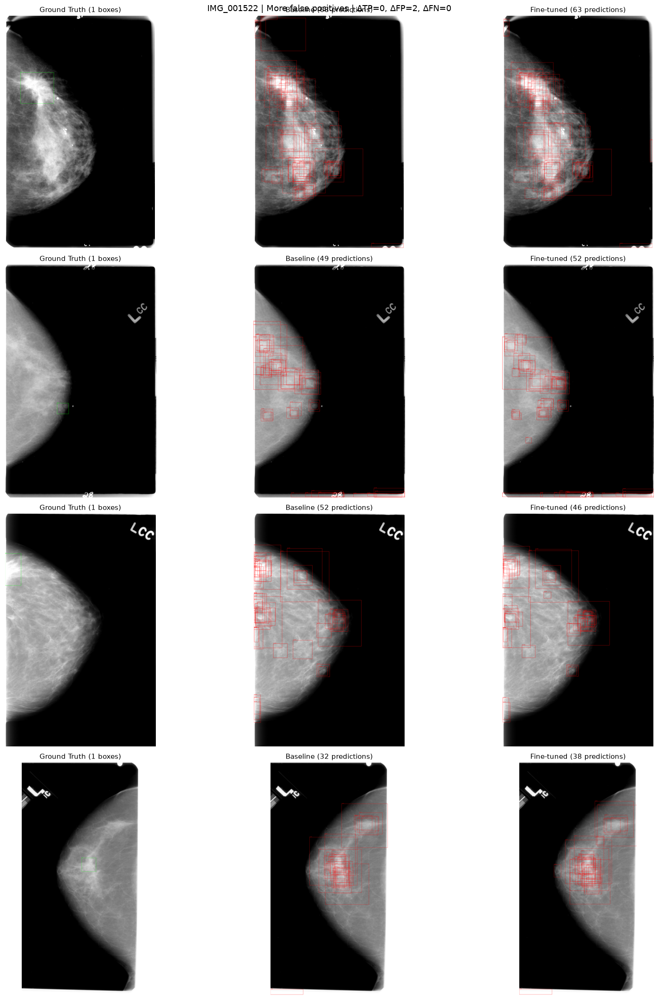

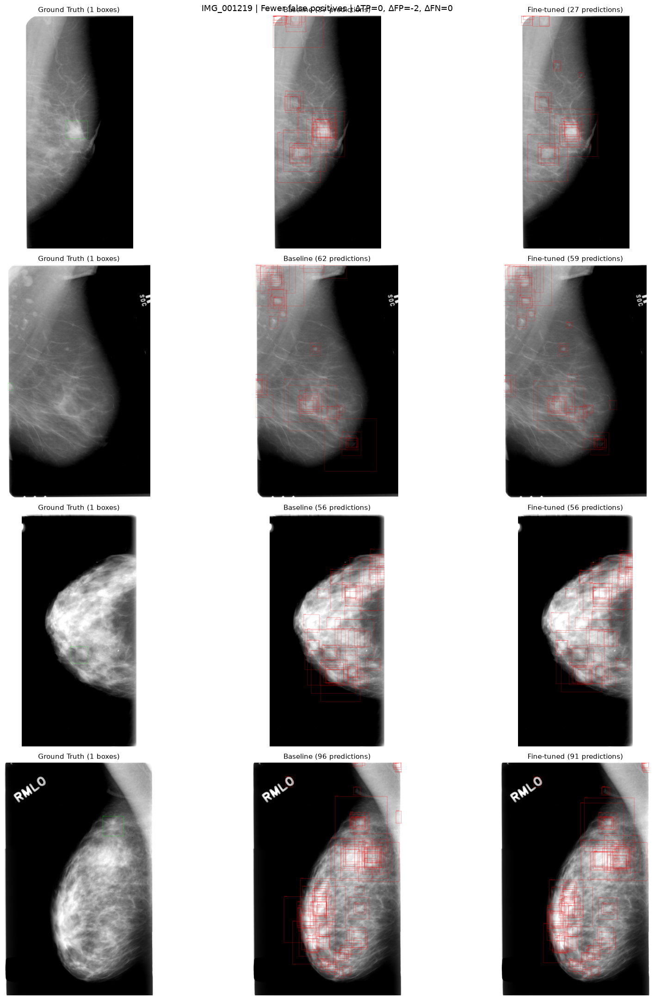

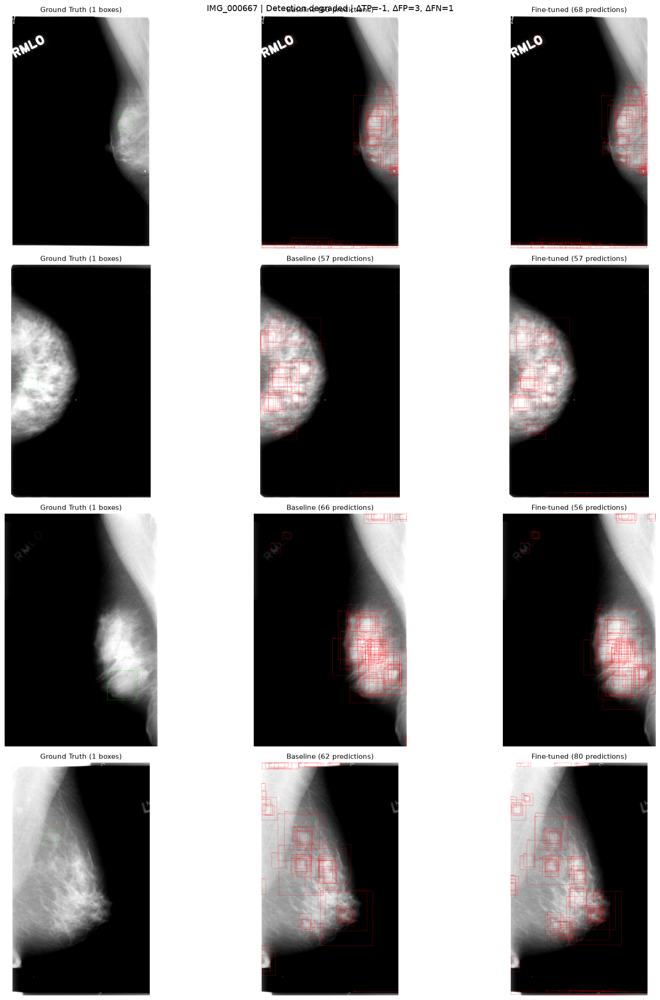

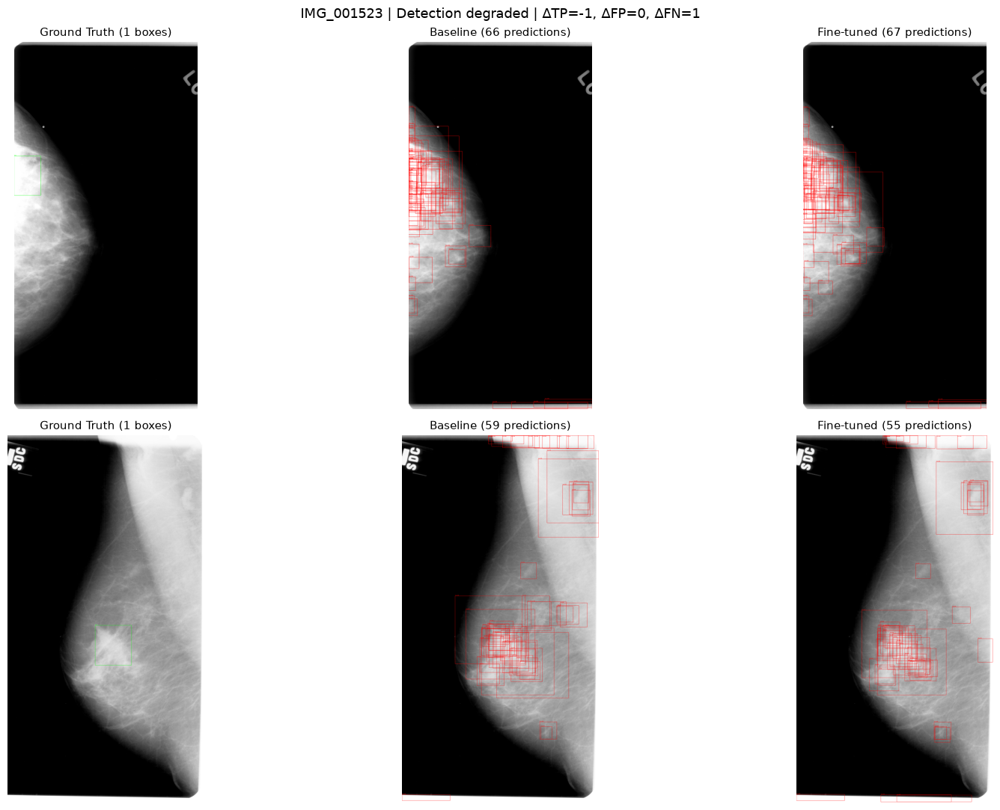


08.7.6 — VISUAL ERROR INSPECTION COMPLETED
Green: Ground Truth | Red: Model predictions
Validation only; no training or Test-set access.


In [8]:
# 08.7.6 — Trực quan hóa lỗi

from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Paths
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

COMPARISON_FILE = (
    OUTPUT_ROOT / "nb08_7_5_comparative_error_analysis" /
    "nb08_7_5_image_comparison.csv"
)

MANIFEST_FILE = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb06_detection_dataset" / "nb06_7_detection_dataset" /
    "nb06_7_detection_image_manifest.csv"
)

YOLO_DATASET_DIR = OUTPUT_ROOT / "nb08_3_yolo_dataset"
GT_LABEL_DIR = YOLO_DATASET_DIR / "labels" / "validation"
IMAGE_DIR = YOLO_DATASET_DIR / "images" / "validation"

# Baseline predictions from 08.7.2
BASELINE_LABEL_DIR = (
    OUTPUT_ROOT / "nb08_7_2_validation_error_analysis" /
    "inference" / "YOLOv5n_640" / "labels"
)

# Fine-tuned predictions from 08.7.4
FINETUNED_LABEL_DIR = (
    OUTPUT_ROOT / "nb08_7_4_finetune_comparison" /
    "inference" / "YOLOv5n_640_finetuned" / "labels"
)

required_paths = [
    COMPARISON_FILE, MANIFEST_FILE, GT_LABEL_DIR, IMAGE_DIR,
    BASELINE_LABEL_DIR, FINETUNED_LABEL_DIR
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

# 2. Load data
comparison = pd.read_csv(COMPARISON_FILE)
manifest = pd.read_csv(MANIFEST_FILE)

comparison["image_id"] = comparison["image_id"].astype(str)
manifest["image_id"] = manifest["image_id"].astype(str)

manifest = manifest.drop_duplicates("image_id").set_index("image_id")

print("Baseline prediction files:", len(list(BASELINE_LABEL_DIR.glob("*.txt"))))
print("Fine-tuned prediction files:", len(list(FINETUNED_LABEL_DIR.glob("*.txt"))))
print("Ground Truth label files:", len(list(GT_LABEL_DIR.glob("*.txt"))))

# 3. Read YOLO labels
def read_yolo_labels(label_path):
    boxes = []

    if not label_path.exists():
        return boxes

    for line in label_path.read_text(encoding="utf-8").splitlines():
        values = line.strip().split()

        if len(values) < 5:
            continue

        try:
            cls, xc, yc, bw, bh = map(float, values[:5])
            conf = float(values[5]) if len(values) >= 6 else None

            boxes.append({
                "class": int(cls),
                "xc": xc,
                "yc": yc,
                "w": bw,
                "h": bh,
                "confidence": conf
            })
        except ValueError:
            continue

    return boxes


def draw_boxes(image, boxes, color, show_conf=False):
    canvas = image.copy()
    height, width = canvas.shape[:2]

    for box in boxes:
        x1 = int((box["xc"] - box["w"] / 2) * width)
        y1 = int((box["yc"] - box["h"] / 2) * height)
        x2 = int((box["xc"] + box["w"] / 2) * width)
        y2 = int((box["yc"] + box["h"] / 2) * height)

        x1 = max(0, min(width - 1, x1))
        x2 = max(0, min(width - 1, x2))
        y1 = max(0, min(height - 1, y1))
        y2 = max(0, min(height - 1, y2))

        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)

        label = "Mass"
        if show_conf and box["confidence"] is not None:
            label += f" {box['confidence']:.2f}"

        cv2.putText(
            canvas, label, (x1, max(18, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1,
            cv2.LINE_AA
        )

    return canvas


# 4. Select representative error cases
category_selection = {
    "More false positives": 4,
    "Fewer false positives": 4,
    "Improved detection": 3,
    "Detection degraded": 3
}

selected_parts = []

for category, limit in category_selection.items():
    subset = comparison[
        comparison["change_category"] == category
    ].copy()

    if category == "More false positives":
        subset = subset.sort_values(
            ["delta_fp", "delta_fn"], ascending=[False, False]
        )
    elif category == "Fewer false positives":
        subset = subset.sort_values(
            ["delta_fp", "delta_fn"], ascending=[True, True]
        )
    elif category == "Improved detection":
        subset = subset.sort_values(
            ["delta_tp", "delta_fn"], ascending=[False, True]
        )
    else:
        subset = subset.sort_values(
            ["delta_fn", "delta_tp"], ascending=[False, True]
        )

    selected_parts.append(subset.head(limit))

selected = (
    pd.concat(selected_parts, ignore_index=True)
    .drop_duplicates("image_id")
)

# 5. Resolve image and label paths
records = []

for _, row in selected.iterrows():
    image_id = row["image_id"]

    if image_id not in manifest.index:
        print(f"Skip {image_id}: không có trong manifest.")
        continue

    image_path = Path(
        str(manifest.loc[image_id, "normalized_image_path"])
    )

    if not image_path.exists():
        candidates = list(IMAGE_DIR.glob(f"{image_id}.*"))
        if not candidates:
            print(f"Skip {image_id}: không tìm thấy ảnh.")
            continue
        image_path = candidates[0]

    records.append({
        "image_id": image_id,
        "category": row["change_category"],
        "delta_tp": row["delta_tp"],
        "delta_fp": row["delta_fp"],
        "delta_fn": row["delta_fn"],
        "image_path": image_path,
        "gt_path": GT_LABEL_DIR / f"{image_id}.txt",
        "baseline_path": BASELINE_LABEL_DIR / f"{image_id}.txt",
        "finetuned_path": FINETUNED_LABEL_DIR / f"{image_id}.txt"
    })

if not records:
    raise RuntimeError("Không có ảnh hợp lệ để trực quan hóa.")

# 6. Display selected image cases
display(pd.DataFrame([
    {
        "image_id": r["image_id"],
        "category": r["category"],
        "delta_TP": r["delta_tp"],
        "delta_FP": r["delta_fp"],
        "delta_FN": r["delta_fn"]
    }
    for r in records
]))

for start in range(0, len(records), 4):
    batch = records[start:start + 4]

    fig, axes = plt.subplots(
        len(batch), 3,
        figsize=(18, 5.5 * len(batch)),
        squeeze=False
    )

    for i, record in enumerate(batch):
        image = cv2.imread(
            str(record["image_path"]), cv2.IMREAD_UNCHANGED
        )

        if image is None:
            for ax in axes[i]:
                ax.axis("off")
            continue

        if image.ndim == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        elif image.ndim == 3:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if image.dtype != np.uint8:
            image = cv2.normalize(
                image, None, 0, 255, cv2.NORM_MINMAX
            ).astype(np.uint8)

        gt_boxes = read_yolo_labels(record["gt_path"])
        baseline_boxes = read_yolo_labels(record["baseline_path"])
        finetuned_boxes = read_yolo_labels(record["finetuned_path"])

        panels = [
            (
                draw_boxes(image, gt_boxes, (0, 255, 0)),
                f"Ground Truth ({len(gt_boxes)} boxes)"
            ),
            (
                draw_boxes(image, baseline_boxes, (255, 0, 0), True),
                f"Baseline ({len(baseline_boxes)} predictions)"
            ),
            (
                draw_boxes(image, finetuned_boxes, (255, 0, 0), True),
                f"Fine-tuned ({len(finetuned_boxes)} predictions)"
            )
        ]

        for j, (panel, title) in enumerate(panels):
            axes[i, j].imshow(panel)
            axes[i, j].set_title(title, fontsize=11)
            axes[i, j].axis("off")

        fig.suptitle(
            f"{record['image_id']} | {record['category']} | "
            f"ΔTP={record['delta_tp']}, "
            f"ΔFP={record['delta_fp']}, "
            f"ΔFN={record['delta_fn']}",
            fontsize=13
        )

    plt.tight_layout()
    plt.show()

print("\n08.7.6 — VISUAL ERROR INSPECTION COMPLETED")
print("Green: Ground Truth | Red: Model predictions")
print("Validation only; no training or Test-set access.")


Selected image count: 6
Matched annotation count: 6

Annotations per image:


,image_id,annotation_count
0,IMG_000611,1
1,IMG_000618,1
2,IMG_000941,1
3,IMG_001021,1
4,IMG_001151,1
5,IMG_001522,1


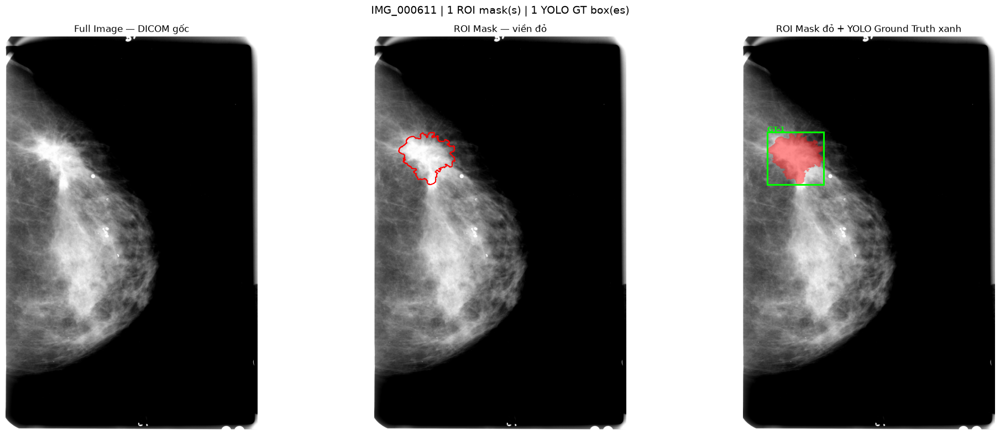

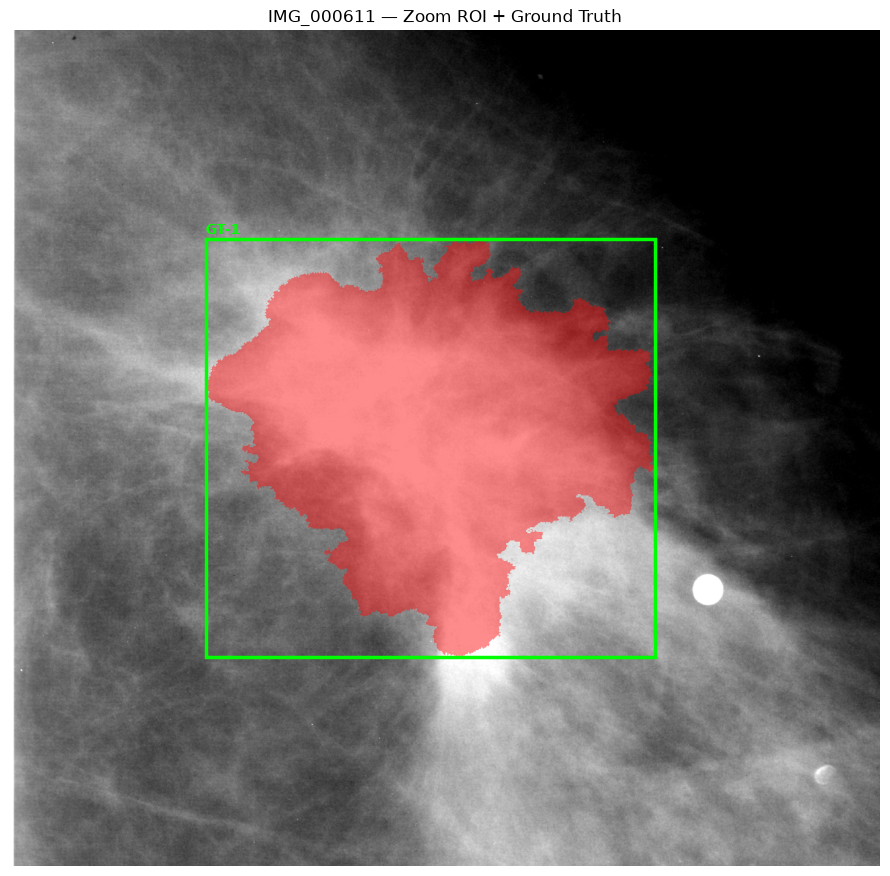

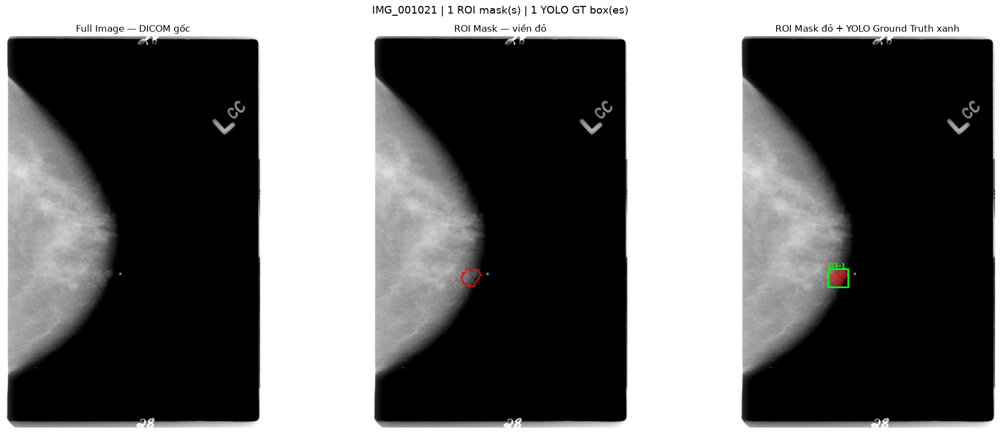

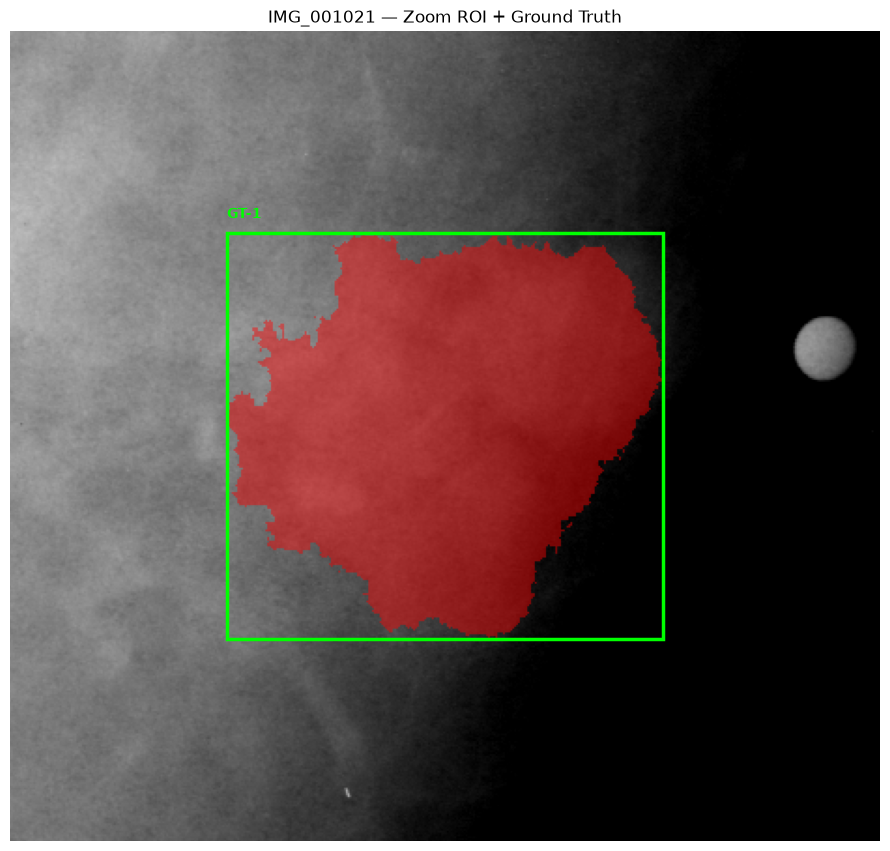

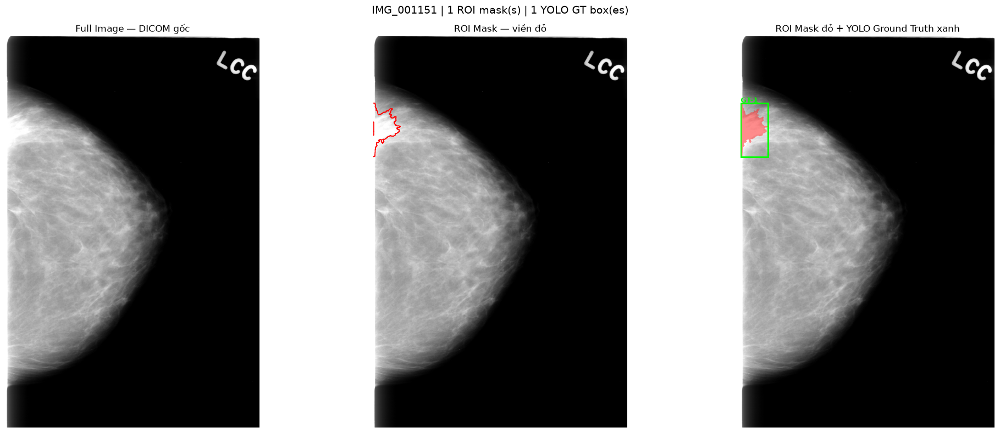

...

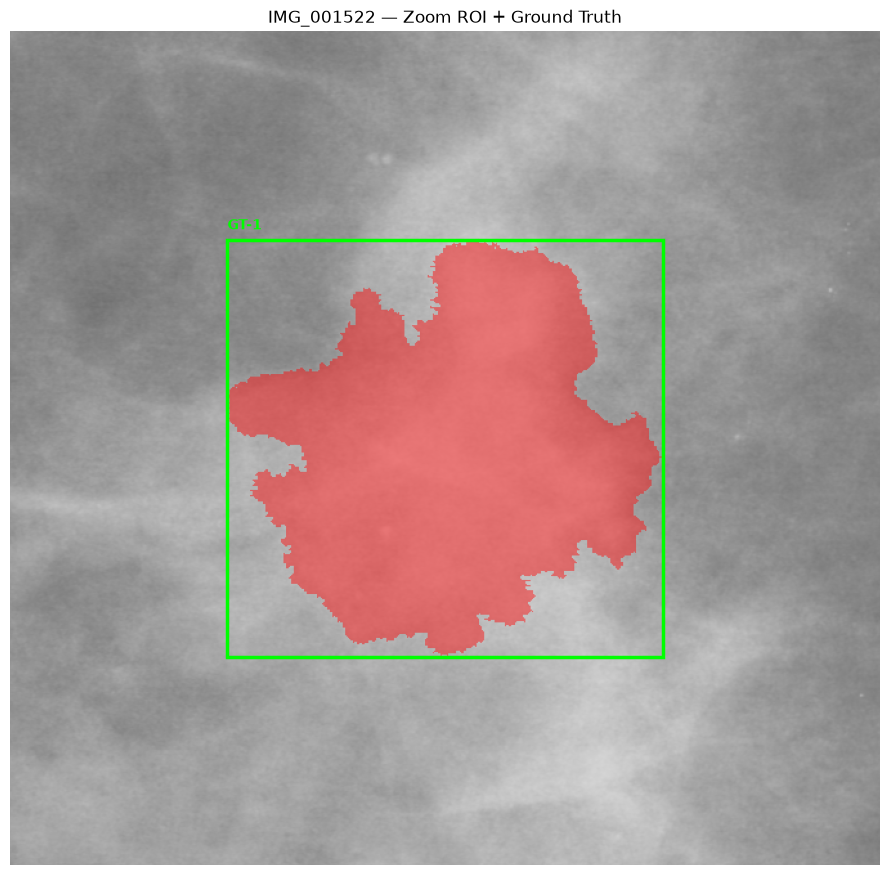

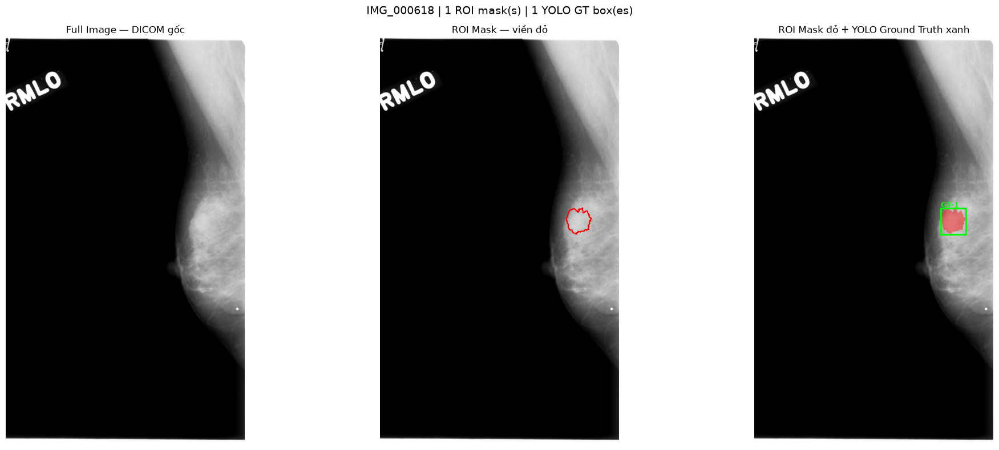

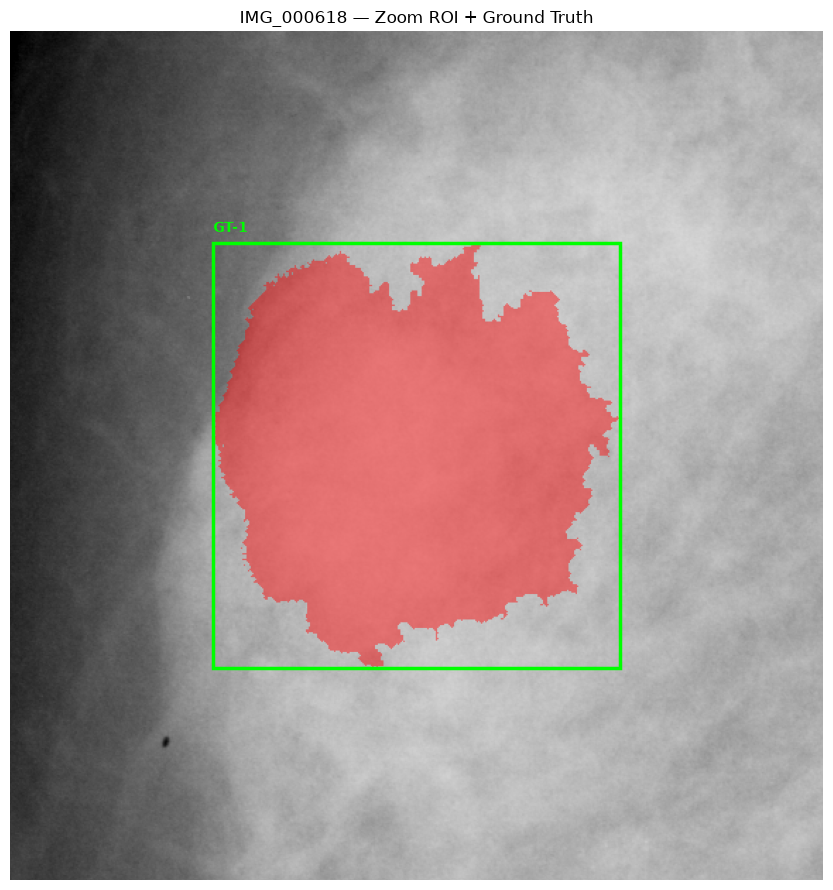

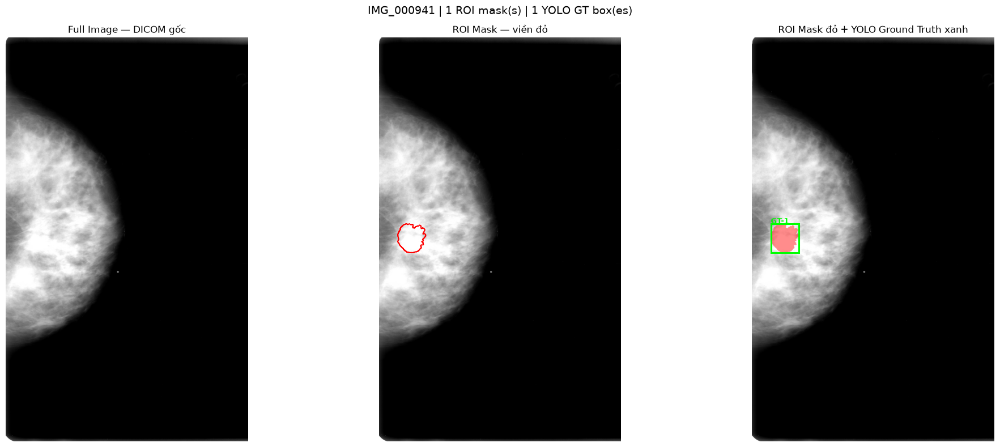

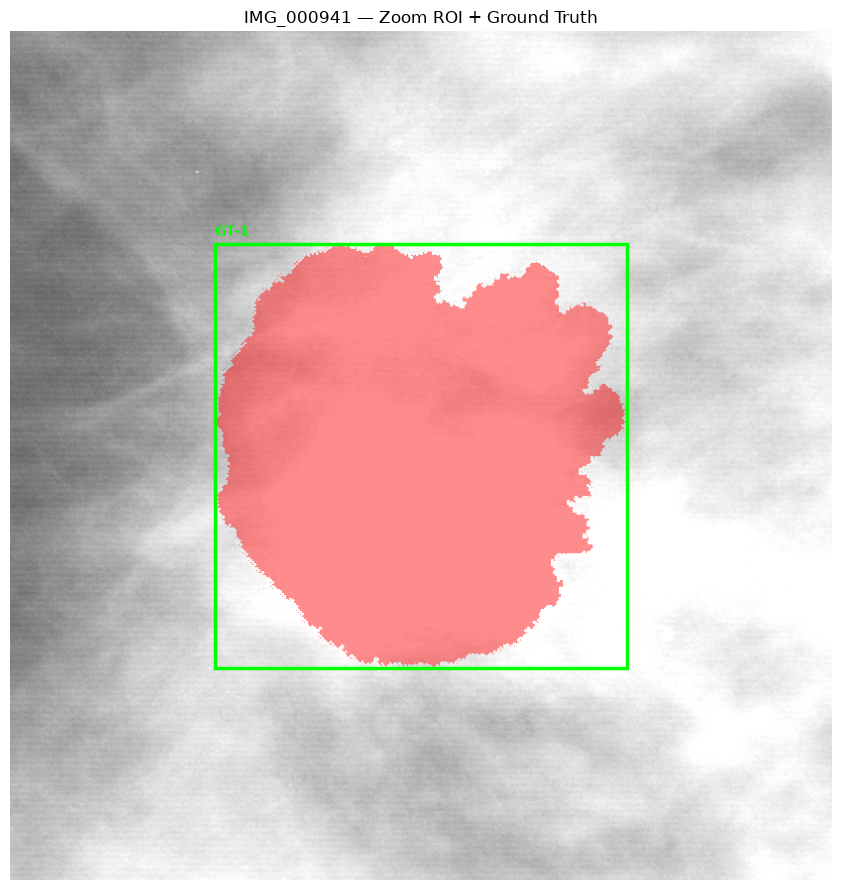


08.7.7 — ROI MASK / GROUND TRUTH BBOX OVERLAY COMPLETED


,image_id,annotation_id,mask_shape,mask_foreground_pixels,mask_bbox_xyxy,yolo_gt_box_count_for_image,full_image_shape
0,IMG_000611,mass_train__00279,"(4752, 3040)",249877,"(296, 1155, 976, 1787)",1,"(4752, 3040)"
1,IMG_001021,mass_train__00723,"(4680, 3048)",33873,"(1056, 2781, 1289, 2998)",1,"(4680, 3048)"
2,IMG_001151,mass_train__00859,"(4528, 2936)",87885,"(0, 774, 315, 1395)",1,"(4528, 2936)"
3,IMG_001522,mass_train__01248,"(5491, 2776)",66074,"(1421, 2249, 1759, 2573)",1,"(5491, 2776)"
4,IMG_000618,mass_train__00286,"(4680, 2752)",58492,"(2144, 1960, 2432, 2261)",1,"(4680, 2752)"
5,IMG_000941,mass_train__00630,"(5960, 3576)",130569,"(278, 2750, 693, 3178)",1,"(5960, 3576)"


Audit saved: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_7_gt_mask_bbox_overlay\nb08_7_7_mask_bbox_overlay_audit.csv
Red: ROI Mask | Green: YOLO Ground Truth Bounding Box


In [10]:
# 08.7.7 — ROI Mask và Ground Truth Bounding Box Overlay

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pydicom
import cv2

# 1. Paths
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
PROCESSED_DIR = PROJECT_ROOT / "Data" / "processed"
OUTPUT_ROOT = PROCESSED_DIR / "nb08_model_training"

MASS_MANIFEST = (
    PROCESSED_DIR / "nb05_mass_annotation_dataset" /
    "nb05_9_mass_experimental_dataset_20261109_011240" /
    "mass_experimental_dataset.csv"
)

DETECTION_ANNOTATIONS = (
    PROCESSED_DIR / "nb06_detection_dataset" /
    "nb06_7_detection_dataset" /
    "nb06_7_detection_annotations.csv"
)

YOLO_GT_DIR = OUTPUT_ROOT / "nb08_3_yolo_dataset" / "labels" / "validation"

RESULT_DIR = OUTPUT_ROOT / "nb08_7_7_gt_mask_bbox_overlay"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

CHECK_IDS = [
    "IMG_000611", "IMG_001021", "IMG_001151", "IMG_001522",
    "IMG_000618", "IMG_000941"
]

for path in [MASS_MANIFEST, DETECTION_ANNOTATIONS, YOLO_GT_DIR]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

# 2. Load source manifests and validate schema
mass_df = pd.read_csv(MASS_MANIFEST)
det_df = pd.read_csv(DETECTION_ANNOTATIONS)

required_mass = {
    "annotation_id", "full_image_path", "normalized_mask_path"
}
required_det = {
    "annotation_id", "image_id", "dataset_split"
}

if not required_mass.issubset(mass_df.columns):
    raise ValueError(
        f"Mass manifest thiếu cột: {required_mass - set(mass_df.columns)}"
    )

if not required_det.issubset(det_df.columns):
    raise ValueError(
        f"Detection annotations thiếu cột: {required_det - set(det_df.columns)}"
    )

mass_df["annotation_id"] = mass_df["annotation_id"].astype(str)
det_df["annotation_id"] = det_df["annotation_id"].astype(str)
det_df["image_id"] = det_df["image_id"].astype(str)

# Only Validation annotations
validation_det = det_df[
    det_df["dataset_split"].astype(str).str.lower().eq("validation")
].copy()

# Join original Full Image and normalized ROI Mask paths by annotation_id
source_df = validation_det[
    validation_det["image_id"].isin(CHECK_IDS)
].merge(
    mass_df[
        ["annotation_id", "full_image_path", "normalized_mask_path"]
    ],
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

if source_df.empty:
    raise ValueError("Không tìm thấy annotation thuộc các ảnh được chọn.")

if source_df["full_image_path"].isna().any():
    raise ValueError("Có annotation không tìm thấy full_image_path.")

if source_df["normalized_mask_path"].isna().any():
    raise ValueError("Có annotation không tìm thấy normalized_mask_path.")

print("Selected image count:", source_df["image_id"].nunique())
print("Matched annotation count:", len(source_df))
print("\nAnnotations per image:")
display(
    source_df.groupby("image_id")
    .size()
    .rename("annotation_count")
    .reset_index()
)

# 3. DICOM/image readers
def read_full_dicom(path):
    ds = pydicom.dcmread(str(path))
    image = ds.pixel_array.astype(np.float32)

    p1, p99 = np.percentile(image, [1, 99])
    if p99 <= p1:
        raise ValueError(f"Ảnh có khoảng cường độ không hợp lệ: {path}")

    image = np.clip((image - p1) / (p99 - p1), 0, 1)

    if str(getattr(ds, "PhotometricInterpretation", "")).upper() == "MONOCHROME1":
        image = 1.0 - image

    return image


def read_mask(path):
    path = Path(path)

    try:
        ds = pydicom.dcmread(str(path))
        mask = ds.pixel_array
    except Exception:
        mask = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        if mask is None:
            raise ValueError(f"Không đọc được ROI mask: {path}")
        if mask.ndim == 3:
            mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

    if mask.ndim == 3:
        mask = np.squeeze(mask)

    if mask.ndim != 2:
        raise ValueError(
            f"ROI mask không phải ảnh 2D: {path}, shape={mask.shape}"
        )

    return mask > 0


def read_yolo_gt(path, width, height):
    boxes = []

    if not path.exists():
        return boxes

    for line_no, line in enumerate(
        path.read_text(encoding="utf-8").splitlines(), start=1
    ):
        values = line.strip().split()

        if not values:
            continue

        if len(values) != 5:
            raise ValueError(
                f"YOLO GT không đúng 5 trường: {path}, dòng {line_no}"
            )

        cls, xc, yc, bw, bh = map(float, values)

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height
        x2 = (xc + bw / 2) * width
        y2 = (yc + bh / 2) * height

        boxes.append({
            "class": int(cls),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

    return boxes


# 4. Render ROI mask and YOLO Ground Truth bbox
audit_rows = []

for image_id in CHECK_IDS:
    image_rows = source_df[source_df["image_id"] == image_id].copy()

    if image_rows.empty:
        print(f"Skip {image_id}: không có annotation.")
        continue

    full_paths = image_rows["full_image_path"].dropna().astype(str).unique()

    if len(full_paths) != 1:
        raise ValueError(
            f"{image_id}: có nhiều Full Image paths: {full_paths.tolist()}"
        )

    full_path = Path(full_paths[0])

    if not full_path.exists():
        raise FileNotFoundError(f"Không tìm thấy Full Image: {full_path}")

    full_image = read_full_dicom(full_path)
    height, width = full_image.shape

    # Load all ROI masks belonging to this image
    masks = []

    for _, row in image_rows.iterrows():
        mask_path = Path(str(row["normalized_mask_path"]))

        if not mask_path.exists():
            raise FileNotFoundError(f"Không tìm thấy ROI mask: {mask_path}")

        mask = read_mask(mask_path)

        if mask.shape != full_image.shape:
            raise ValueError(
                f"{image_id} | Mask dimensions {mask.shape} "
                f"không khớp Full Image {full_image.shape}. "
                f"Mask: {mask_path}"
            )

        masks.append({
            "annotation_id": row["annotation_id"],
            "mask": mask,
            "mask_path": mask_path
        })

    # Read YOLO GT boxes for this image
    gt_path = YOLO_GT_DIR / f"{image_id}.txt"
    boxes = read_yolo_gt(gt_path, width, height)

    # Build red ROI overlay
    overlay = np.dstack([full_image, full_image, full_image])

    union_mask = np.zeros((height, width), dtype=bool)

    for item in masks:
        union_mask |= item["mask"]

    # Red translucent fill and red contour
    overlay[union_mask, 0] = (
        0.55 * overlay[union_mask, 0] + 0.45
    )
    overlay[union_mask, 1] *= 0.55
    overlay[union_mask, 2] *= 0.55

    # Determine zoom region from ROI masks
    ys, xs = np.where(union_mask)

    if len(xs):
        pad_x = max(40, int((xs.max() - xs.min() + 1) * 0.5))
        pad_y = max(40, int((ys.max() - ys.min() + 1) * 0.5))

        zx1 = max(0, int(xs.min()) - pad_x)
        zy1 = max(0, int(ys.min()) - pad_y)
        zx2 = min(width, int(xs.max()) + pad_x + 1)
        zy2 = min(height, int(ys.max()) + pad_y + 1)
    else:
        zx1, zy1, zx2, zy2 = 0, 0, width, height

    # 3 panels: original, ROI mask, ROI + GT bbox
    fig, axes = plt.subplots(1, 3, figsize=(21, 8))

    axes[0].imshow(full_image, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Full Image — DICOM gốc")

    axes[1].imshow(full_image, cmap="gray", vmin=0, vmax=1)
    for item in masks:
        mask = item["mask"]
        if mask.any():
            axes[1].contour(
                mask.astype(np.uint8),
                levels=[0.5],
                colors=["red"],
                linewidths=1.2
            )
    axes[1].set_title("ROI Mask — viền đỏ")

    axes[2].imshow(overlay, vmin=0, vmax=1)

    for box_index, box in enumerate(boxes, start=1):
        rect = patches.Rectangle(
            (box["x1"], box["y1"]),
            box["x2"] - box["x1"],
            box["y2"] - box["y1"],
            linewidth=2.2,
            edgecolor="lime",
            facecolor="none"
        )
        axes[2].add_patch(rect)
        axes[2].text(
            box["x1"],
            max(0, box["y1"] - 8),
            f"GT-{box_index}",
            color="lime",
            fontsize=9,
            weight="bold"
        )

    axes[2].set_title("ROI Mask đỏ + YOLO Ground Truth xanh")

    for ax in axes:
        ax.set_xlim(0, width)
        ax.set_ylim(height, 0)
        ax.axis("off")

    fig.suptitle(
        f"{image_id} | {len(masks)} ROI mask(s) | "
        f"{len(boxes)} YOLO GT box(es)",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

    # Zoomed overlay for spatial alignment inspection
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(overlay, vmin=0, vmax=1)

    for box_index, box in enumerate(boxes, start=1):
        rect = patches.Rectangle(
            (box["x1"], box["y1"]),
            box["x2"] - box["x1"],
            box["y2"] - box["y1"],
            linewidth=2.5,
            edgecolor="lime",
            facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            box["x1"],
            max(0, box["y1"] - 8),
            f"GT-{box_index}",
            color="lime",
            fontsize=10,
            weight="bold"
        )

    ax.set_xlim(zx1, zx2)
    ax.set_ylim(zy2, zy1)
    ax.set_title(f"{image_id} — Zoom ROI + Ground Truth")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

    # Record mask and bbox audit
    for item in masks:
        ys_mask, xs_mask = np.where(item["mask"])

        if len(xs_mask):
            mask_bbox = (
                int(xs_mask.min()),
                int(ys_mask.min()),
                int(xs_mask.max()) + 1,
                int(ys_mask.max()) + 1
            )
        else:
            mask_bbox = None

        audit_rows.append({
            "image_id": image_id,
            "annotation_id": item["annotation_id"],
            "mask_shape": str(item["mask"].shape),
            "mask_foreground_pixels": int(item["mask"].sum()),
            "mask_bbox_xyxy": str(mask_bbox),
            "yolo_gt_box_count_for_image": len(boxes),
            "full_image_shape": str(full_image.shape)
        })

# 5. Export audit
audit_df = pd.DataFrame(audit_rows)
audit_path = RESULT_DIR / "nb08_7_7_mask_bbox_overlay_audit.csv"
audit_df.to_csv(audit_path, index=False, encoding="utf-8-sig")

print("\n" + "=" * 70)
print("08.7.7 — ROI MASK / GROUND TRUTH BBOX OVERLAY COMPLETED")
display(audit_df)
print("Audit saved:", audit_path)
print("Red: ROI Mask | Green: YOLO Ground Truth Bounding Box")


=== VALIDATION DATA ===
Validation annotations : 264
Validation images      : 249
Patient overlap        : 0 (đã xác nhận ở các bước trước)
Confidence threshold   : 0.1
IoU threshold          : 0.5

Analyzing Baseline_640 ...

Analyzing Finetuned_640 ...

=== METRIC CROSS-CHECK ===
Baseline_640: TP=181, FP=269, FN=83
  08.7.4: TP=181, FP=269, FN=83
  Cross-check: PASS
Finetuned_640: TP=185, FP=272, FN=79

=== MODEL SUMMARY ===


,model,images,GT,predictions,TP,FP,FN,Precision,Recall,F1
0,Baseline_640,249,264,450,181,269,83,0.4022,0.6856,0.5070
1,Finetuned_640,249,264,457,185,272,79,0.4048,0.7008,0.5132



=== FALSE POSITIVE CATEGORY SUMMARY ===


,model,fp_category,FP_count,mean_confidence,mean_bbox_roi_fraction,mean_roi_coverage
0,Baseline_640,Near GT / possible duplicate or localization m...,60,0.2584,0.6043,0.6944
1,Baseline_640,Outside annotated ROI,206,0.2217,0.0002,0.0003
2,Baseline_640,ROI-overlapping FP / localization mismatch,3,0.1957,0.1405,0.1228
3,Finetuned_640,Near GT / possible duplicate or localization m...,54,0.2737,0.5618,0.6633
4,Finetuned_640,Outside annotated ROI,214,0.2288,0.0002,0.0001
5,Finetuned_640,ROI-overlapping FP / localization mismatch,4,0.1647,0.1428,0.1103


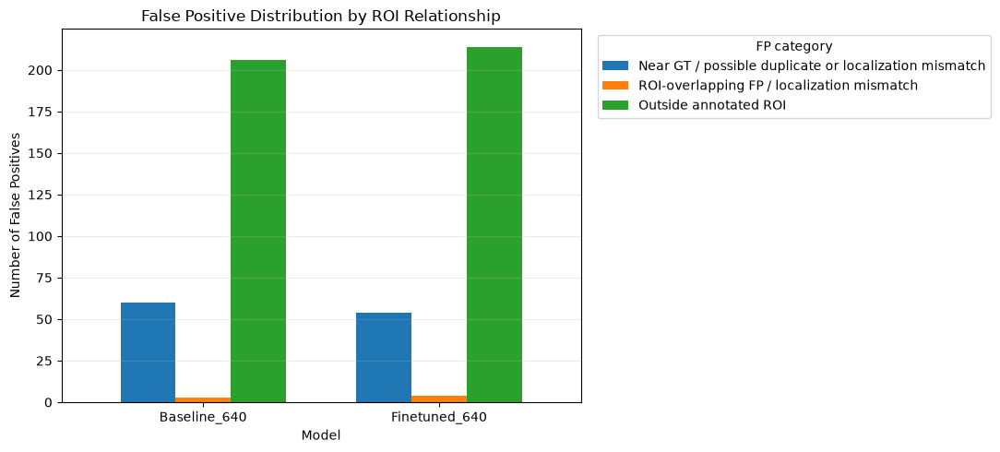


=== VISUAL REVIEW: 6 IMAGES ===
Red: ROI Mask | Green: Ground Truth | Blue: matched prediction | Orange: False Positive


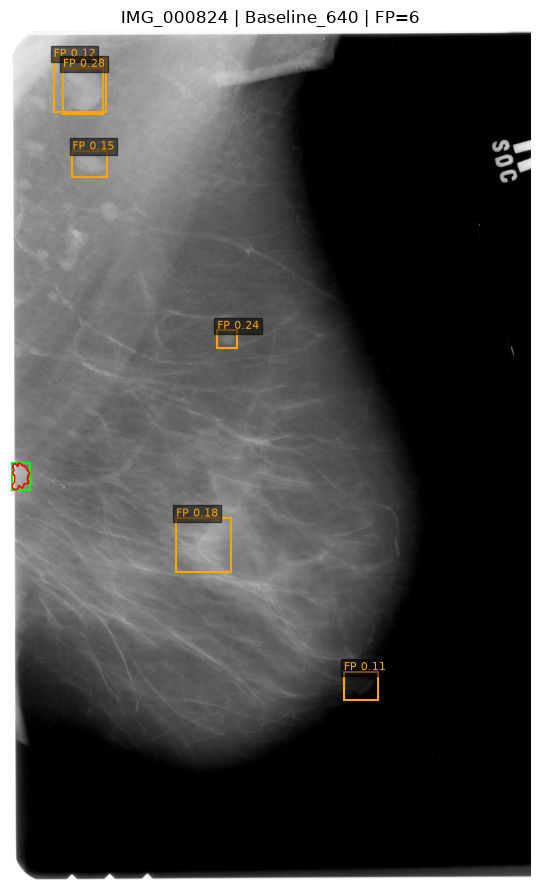

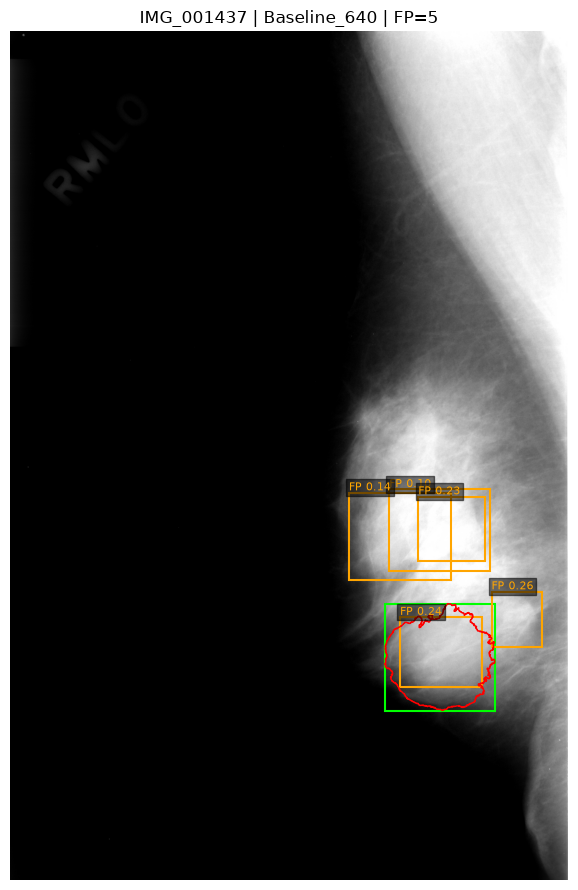

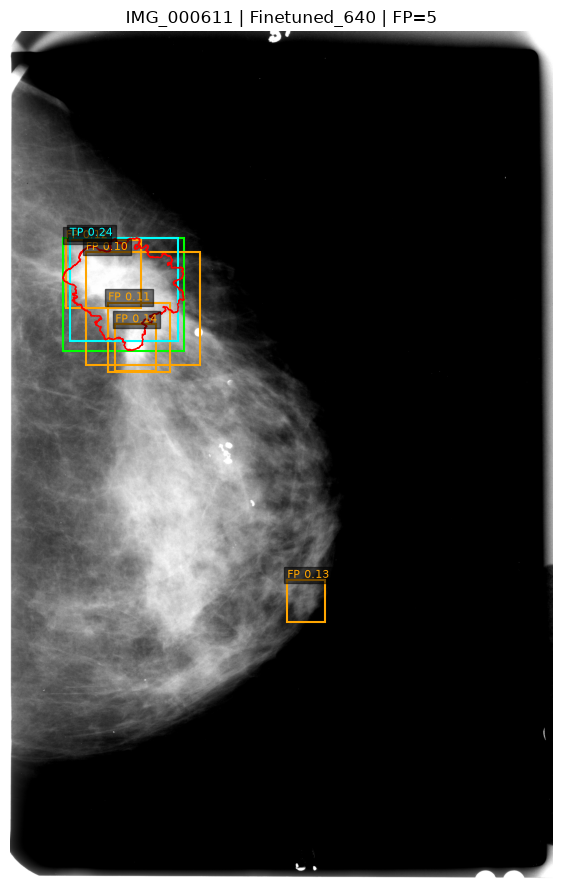

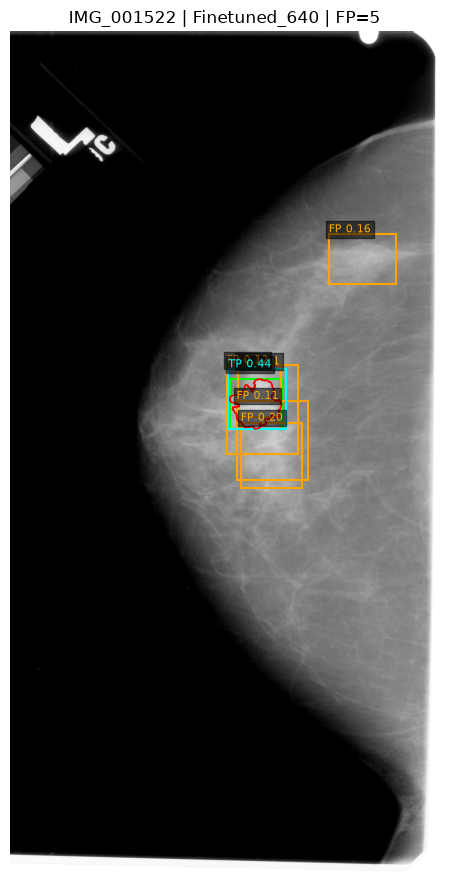

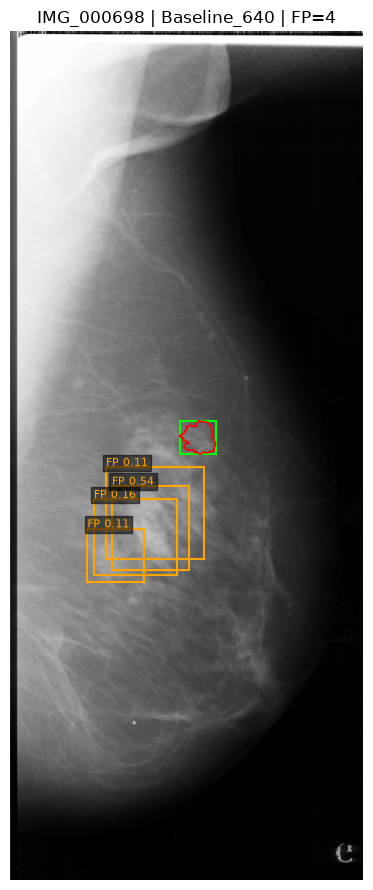

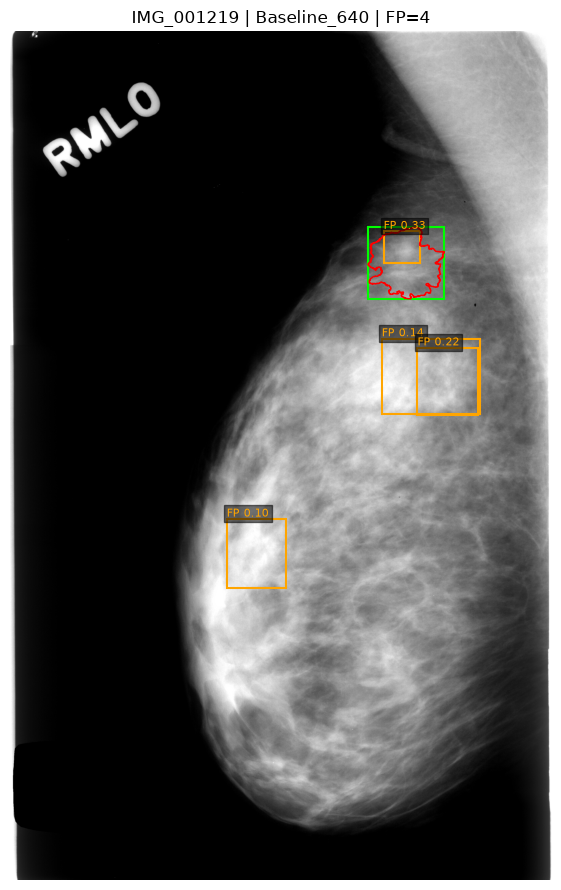


08.7.8 — FALSE POSITIVE ANALYSIS COMPLETED
Validation images analyzed : 249
Models analyzed            : 2
Total FP records           : 541
Output directory           : C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_8_false_positive_analysis

Saved files:
- nb08_7_8_false_positive_details.csv
- nb08_7_8_image_level_metrics.csv
- nb08_7_8_false_positive_summary.csv
- nb08_7_8_model_summary.csv

Interpretation boundary:
- Outside annotated ROI does NOT mean outside breast tissue.
- ROI overlap does NOT automatically mean a clinically correct detection.


In [11]:
# 08.7.8 — FALSE POSITIVE ANALYSIS

import warnings
import matplotlib.pyplot as plt
import cv2
import pydicom
from IPython.display import display

warnings.filterwarnings("ignore")

# 1. CONFIGURATION

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

MASS_MANIFEST = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb05_mass_annotation_dataset" /
    "nb05_9_mass_experimental_dataset_20261109_011240" /
    "mass_experimental_dataset.csv"
)

DETECTION_ANNOTATIONS = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb06_detection_dataset" / "nb06_7_detection_dataset" /
    "nb06_7_detection_annotations.csv"
)

BASELINE_PRED_DIR = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb08_model_training" /
    "nb08_7_2_validation_error_analysis" /
    "inference" / "YOLOv5n_640" / "labels"
)

FINETUNED_PRED_DIR = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb08_model_training" /
    "nb08_7_4_finetune_comparison" /
    "inference" / "YOLOv5n_640_finetuned" / "labels"
)

PREVIOUS_IMAGE_METRICS = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb08_model_training" /
    "nb08_7_4_finetune_comparison" /
    "nb08_7_4_image_level_metrics.csv"
)

YOLO_IMAGE_DIR = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb08_model_training" /
    "nb08_3_yolo_dataset" / "images" / "validation"
)

OUTPUT_DIR = (
    PROJECT_ROOT / "Data" / "processed" /
    "nb08_model_training" /
    "nb08_7_8_false_positive_analysis"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONF_THRESHOLD = 0.10
IOU_THRESHOLD = 0.50
ROI_OVERLAP_THRESHOLD = 0.05
NEAR_GT_IOU_THRESHOLD = 0.10
MAX_VISUAL_IMAGES = 6

MODEL_DIRS = {
    "Baseline_640": BASELINE_PRED_DIR,
    "Finetuned_640": FINETUNED_PRED_DIR,
}

# 2. LOAD AND VALIDATE DATA

for path in [
    MASS_MANIFEST,
    DETECTION_ANNOTATIONS,
    BASELINE_PRED_DIR,
    FINETUNED_PRED_DIR,
    PREVIOUS_IMAGE_METRICS,
]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy: {path}")

mass_df = pd.read_csv(MASS_MANIFEST)
det_df = pd.read_csv(DETECTION_ANNOTATIONS)
previous_metrics = pd.read_csv(PREVIOUS_IMAGE_METRICS)

required_mass = {
    "annotation_id", "full_image_path", "normalized_mask_path"
}
required_det = {
    "annotation_id", "image_id", "patient_id", "dataset_split",
    "x_min", "y_min", "x_max", "y_max",
    "image_width", "image_height"
}

if not required_mass.issubset(mass_df.columns):
    raise ValueError(
        f"Thiếu cột trong Mass Manifest: "
        f"{sorted(required_mass - set(mass_df.columns))}"
    )

if not required_det.issubset(det_df.columns):
    raise ValueError(
        f"Thiếu cột trong Detection Annotations: "
        f"{sorted(required_det - set(det_df.columns))}"
    )

val_df = det_df[
    det_df["dataset_split"].astype(str).str.lower().eq("validation")
].copy()

val_df = val_df.merge(
    mass_df[
        ["annotation_id", "full_image_path", "normalized_mask_path"]
    ],
    on="annotation_id",
    how="left",
    validate="many_to_one"
)

if val_df["normalized_mask_path"].isna().any():
    missing = val_df.loc[
        val_df["normalized_mask_path"].isna(), "annotation_id"
    ].tolist()
    raise ValueError(f"Thiếu ROI Mask cho annotation: {missing[:10]}")

if val_df["full_image_path"].isna().any():
    raise ValueError("Có annotation Validation thiếu full_image_path.")

val_df["image_id"] = val_df["image_id"].astype(str)

image_info = (
    val_df.groupby("image_id", as_index=False)
    .agg(
        image_width=("image_width", "first"),
        image_height=("image_height", "first"),
        full_image_path=("full_image_path", "first"),
        annotation_count=("annotation_id", "nunique"),
    )
)

print("=== VALIDATION DATA ===")
print(f"Validation annotations : {len(val_df):,}")
print(f"Validation images      : {len(image_info):,}")
print(f"Patient overlap        : 0 (đã xác nhận ở các bước trước)")
print(f"Confidence threshold   : {CONF_THRESHOLD}")
print(f"IoU threshold          : {IOU_THRESHOLD}")

# 3. HELPER FUNCTIONS

def read_mask(mask_path):
    path = Path(str(mask_path))

    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy ROI Mask: {path}")

    if path.suffix.lower() in [".dcm", ".dicom"]:
        arr = pydicom.dcmread(str(path)).pixel_array
    else:
        arr = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

        if arr is None:
            raise ValueError(f"Không đọc được ROI Mask: {path}")

        if arr.ndim == 3:
            arr = cv2.cvtColor(arr, cv2.COLOR_BGR2GRAY)

    arr = np.asarray(arr)
    if arr.ndim > 2:
        arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(f"ROI Mask không phải ảnh 2D: {path}, {arr.shape}")

    return arr > 0


def read_full_image(image_path):
    ds = pydicom.dcmread(str(image_path))
    arr = ds.pixel_array.astype(np.float32)

    p1, p99 = np.percentile(arr, [1, 99])
    if p99 <= p1:
        raise ValueError(f"Không thể chuẩn hóa ảnh: {image_path}")

    arr = np.clip((arr - p1) / (p99 - p1), 0, 1)

    if str(getattr(ds, "PhotometricInterpretation", "")).upper() == "MONOCHROME1":
        arr = 1 - arr

    return arr


def read_predictions(label_path, width, height):
    path = Path(label_path)

    if not path.exists():
        return []

    predictions = []

    for line in path.read_text(encoding="utf-8").splitlines():
        values = line.strip().split()

        if len(values) < 5:
            continue

        values = [float(x) for x in values]

        class_id = int(values[0])
        xc, yc, bw, bh = values[1:5]
        confidence = values[5] if len(values) >= 6 else 1.0

        if confidence < CONF_THRESHOLD:
            continue

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height
        x2 = (xc + bw / 2) * width
        y2 = (yc + bh / 2) * height

        x1 = float(np.clip(x1, 0, width))
        y1 = float(np.clip(y1, 0, height))
        x2 = float(np.clip(x2, 0, width))
        y2 = float(np.clip(y2, 0, height))

        if x2 <= x1 or y2 <= y1:
            continue

        predictions.append({
            "class_id": class_id,
            "confidence": confidence,
            "x1": x1, "y1": y1,
            "x2": x2, "y2": y2,
        })

    return predictions


def calculate_iou(box_a, box_b):
    ix1 = max(box_a[0], box_b[0])
    iy1 = max(box_a[1], box_b[1])
    ix2 = min(box_a[2], box_b[2])
    iy2 = min(box_a[3], box_b[3])

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)
    intersection = iw * ih

    area_a = max(0.0, box_a[2] - box_a[0]) * max(
        0.0, box_a[3] - box_a[1]
    )
    area_b = max(0.0, box_b[2] - box_b[0]) * max(
        0.0, box_b[3] - box_b[1]
    )

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def match_predictions(predictions, gt_boxes):
    """
    Ghép prediction và GT theo IoU giảm dần.
    Mỗi prediction và mỗi GT chỉ được ghép tối đa một lần.
    """
    pairs = []

    for pred_idx, pred in enumerate(predictions):
        pred_box = [pred["x1"], pred["y1"], pred["x2"], pred["y2"]]

        for gt_idx, gt in enumerate(gt_boxes):
            iou = calculate_iou(
                pred_box,
                [gt["x1"], gt["y1"], gt["x2"], gt["y2"]]
            )

            if iou >= IOU_THRESHOLD:
                pairs.append((iou, pred_idx, gt_idx))

    pairs.sort(reverse=True)

    matched_preds = set()
    matched_gts = set()
    matched_iou = {}

    for iou, pred_idx, gt_idx in pairs:
        if pred_idx in matched_preds or gt_idx in matched_gts:
            continue

        matched_preds.add(pred_idx)
        matched_gts.add(gt_idx)
        matched_iou[pred_idx] = iou

    return matched_preds, matched_gts, matched_iou


def load_image_roi_mask(image_id, group, width, height):
    union_mask = np.zeros((height, width), dtype=bool)

    for mask_path in group["normalized_mask_path"].dropna().unique():
        mask = read_mask(mask_path)

        if mask.shape != (height, width):
            raise ValueError(
                f"{image_id}: ROI Mask shape {mask.shape} "
                f"không khớp ảnh {(height, width)}"
            )

        union_mask |= mask

    return union_mask


def analyze_fp_roi(pred, union_mask, gt_boxes):
    height, width = union_mask.shape

    x1 = max(0, int(np.floor(pred["x1"])))
    y1 = max(0, int(np.floor(pred["y1"])))
    x2 = min(width, int(np.ceil(pred["x2"])))
    y2 = min(height, int(np.ceil(pred["y2"])))

    bbox_area = max(0, x2 - x1) * max(0, y2 - y1)
    roi_pixels = int(union_mask.sum())

    intersection_pixels = 0
    if x2 > x1 and y2 > y1:
        intersection_pixels = int(union_mask[y1:y2, x1:x2].sum())

    bbox_roi_fraction = (
        intersection_pixels / bbox_area if bbox_area else 0.0
    )
    roi_coverage = (
        intersection_pixels / roi_pixels if roi_pixels else 0.0
    )

    cx = int(np.clip((pred["x1"] + pred["x2"]) / 2, 0, width - 1))
    cy = int(np.clip((pred["y1"] + pred["y2"]) / 2, 0, height - 1))
    center_in_roi = bool(union_mask[cy, cx])

    pred_box = [pred["x1"], pred["y1"], pred["x2"], pred["y2"]]
    max_gt_iou = max(
        [
            calculate_iou(
                pred_box,
                [gt["x1"], gt["y1"], gt["x2"], gt["y2"]]
            )
            for gt in gt_boxes
        ],
        default=0.0
    )

    if max_gt_iou >= NEAR_GT_IOU_THRESHOLD:
        category = "Near GT / possible duplicate or localization mismatch"
    elif (
        bbox_roi_fraction >= ROI_OVERLAP_THRESHOLD
        or roi_coverage >= ROI_OVERLAP_THRESHOLD
        or center_in_roi
    ):
        category = "ROI-overlapping FP / localization mismatch"
    else:
        category = "Outside annotated ROI"

    return {
        "mask_intersection_pixels": intersection_pixels,
        "bbox_roi_fraction": bbox_roi_fraction,
        "roi_coverage": roi_coverage,
        "center_in_roi": center_in_roi,
        "max_gt_iou": max_gt_iou,
        "fp_category": category,
    }

# 4. BUILD GT BOXES AND ANALYZE BOTH MODELS

all_fp_records = []
all_image_records = []
all_visual_records = []

for model_name, pred_dir in MODEL_DIRS.items():

    if not pred_dir.exists():
        raise FileNotFoundError(f"Prediction directory missing: {pred_dir}")

    print(f"\nAnalyzing {model_name} ...")

    for _, info in image_info.iterrows():

        image_id = info["image_id"]
        width = int(info["image_width"])
        height = int(info["image_height"])

        group = val_df[val_df["image_id"] == image_id]

        gt_boxes = []
        for _, row in group.iterrows():
            gt_boxes.append({
                "annotation_id": row["annotation_id"],
                "x1": float(row["x_min"]),
                "y1": float(row["y_min"]),
                "x2": float(row["x_max"]),
                "y2": float(row["y_max"]),
            })

        pred_path = pred_dir / f"{image_id}.txt"
        predictions = read_predictions(pred_path, width, height)

        matched_preds, matched_gts, matched_iou = match_predictions(
            predictions, gt_boxes
        )

        tp = len(matched_preds)
        fp = len(predictions) - tp
        fn = len(gt_boxes) - len(matched_gts)

        all_image_records.append({
            "model": model_name,
            "image_id": image_id,
            "GT": len(gt_boxes),
            "predictions": len(predictions),
            "TP": tp,
            "FP": fp,
            "FN": fn,
        })

        if fp == 0:
            continue

        union_mask = load_image_roi_mask(
            image_id, group, width, height
        )

        for pred_idx, pred in enumerate(predictions):

            if pred_idx in matched_preds:
                continue

            roi_result = analyze_fp_roi(
                pred, union_mask, gt_boxes
            )

            record = {
                "model": model_name,
                "image_id": image_id,
                "prediction_index": pred_idx,
                "confidence": pred["confidence"],
                "x1": pred["x1"],
                "y1": pred["y1"],
                "x2": pred["x2"],
                "y2": pred["y2"],
                "image_width": width,
                "image_height": height,
                **roi_result,
            }

            all_fp_records.append(record)

        # Store candidate image for visual inspection
        all_visual_records.append({
            "model": model_name,
            "image_id": image_id,
            "fp_count": fp,
            "full_image_path": group["full_image_path"].iloc[0],
            "group": group.copy(),
            "gt_boxes": gt_boxes,
            "predictions": predictions,
            "matched_preds": matched_preds,
            "union_mask": union_mask,
        })

# 5. CREATE OUTPUT TABLES

fp_df = pd.DataFrame(all_fp_records)
image_metrics_df = pd.DataFrame(all_image_records)

if fp_df.empty:
    fp_summary_df = pd.DataFrame()
else:
    fp_summary_df = (
        fp_df.groupby(["model", "fp_category"])
        .agg(
            FP_count=("image_id", "size"),
            mean_confidence=("confidence", "mean"),
            mean_bbox_roi_fraction=("bbox_roi_fraction", "mean"),
            mean_roi_coverage=("roi_coverage", "mean"),
        )
        .reset_index()
    )

model_summary_df = (
    image_metrics_df.groupby("model")
    .agg(
        images=("image_id", "nunique"),
        GT=("GT", "sum"),
        predictions=("predictions", "sum"),
        TP=("TP", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum"),
    )
    .reset_index()
)

model_summary_df["Precision"] = (
    model_summary_df["TP"] /
    (model_summary_df["TP"] + model_summary_df["FP"]).replace(0, np.nan)
)
model_summary_df["Recall"] = (
    model_summary_df["TP"] /
    (model_summary_df["TP"] + model_summary_df["FN"]).replace(0, np.nan)
)

model_summary_df["F1"] = (
    2 * model_summary_df["Precision"] * model_summary_df["Recall"] /
    (model_summary_df["Precision"] + model_summary_df["Recall"])
)

# 6. CROSS-CHECK WITH NOTEBOOK 08.7.4

print("\n=== METRIC CROSS-CHECK ===")

previous_subset = previous_metrics[
    (previous_metrics["confidence"].round(4) == CONF_THRESHOLD) &
    (previous_metrics["IoU_threshold"].round(4) == IOU_THRESHOLD)
].copy()

for model_name in MODEL_DIRS:
    current = model_summary_df[
        model_summary_df["model"] == model_name
    ]

    if current.empty:
        continue

    previous_name = (
        "Baseline_640" if model_name == "Baseline_640"
        else "Finetuned_640"
    )

    previous = previous_subset[
        previous_subset["model"].astype(str).str.contains(
            "Baseline" if previous_name == "Baseline_640"
            else "Finetuned",
            case=False,
            na=False
        )
    ]

    row = current.iloc[0]

    print(
        f"{model_name}: "
        f"TP={int(row['TP'])}, FP={int(row['FP'])}, FN={int(row['FN'])}"
    )

    if not previous.empty:
        prev_tp = int(previous["TP"].sum())
        prev_fp = int(previous["FP"].sum())
        prev_fn = int(previous["FN"].sum())

        print(
            f"  08.7.4: TP={prev_tp}, FP={prev_fp}, FN={prev_fn}"
        )

        if (
            int(row["TP"]) == prev_tp and
            int(row["FP"]) == prev_fp and
            int(row["FN"]) == prev_fn
        ):
            print("  Cross-check: PASS")
        else:
            print(
                "  Cross-check: CHECK — khác biệt có thể do "
                "quy tắc ghép prediction/GT."
            )

# 7. SAVE RESULTS

fp_path = OUTPUT_DIR / "nb08_7_8_false_positive_details.csv"
image_path = OUTPUT_DIR / "nb08_7_8_image_level_metrics.csv"
summary_path = OUTPUT_DIR / "nb08_7_8_false_positive_summary.csv"
model_path = OUTPUT_DIR / "nb08_7_8_model_summary.csv"

fp_df.to_csv(fp_path, index=False, encoding="utf-8-sig")
image_metrics_df.to_csv(
    image_path, index=False, encoding="utf-8-sig"
)
fp_summary_df.to_csv(
    summary_path, index=False, encoding="utf-8-sig"
)
model_summary_df.to_csv(
    model_path, index=False, encoding="utf-8-sig"
)

# 8. DISPLAY SUMMARY AND PLOTS

print("\n=== MODEL SUMMARY ===")
display(model_summary_df.round(4))

print("\n=== FALSE POSITIVE CATEGORY SUMMARY ===")
if not fp_summary_df.empty:
    display(fp_summary_df.round(4))
else:
    print("Không có False Positive ở ngưỡng đã chọn.")

if not fp_df.empty:

    category_order = [
        "Near GT / possible duplicate or localization mismatch",
        "ROI-overlapping FP / localization mismatch",
        "Outside annotated ROI",
    ]

    plot_data = (
        fp_df.groupby(["model", "fp_category"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=category_order, fill_value=0)
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(11, 5),
        width=0.7
    )
    ax.set_title(
        "False Positive Distribution by ROI Relationship"
    )
    ax.set_xlabel("Model")
    ax.set_ylabel("Number of False Positives")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(
        title="FP category",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

# 9. VISUALIZE REPRESENTATIVE FALSE POSITIVES

if all_visual_records:

    visual_candidates = sorted(
        all_visual_records,
        key=lambda x: x["fp_count"],
        reverse=True
    )

    selected = []
    used_images = set()

    for item in visual_candidates:
        if item["image_id"] not in used_images:
            selected.append(item)
            used_images.add(item["image_id"])

        if len(selected) >= MAX_VISUAL_IMAGES:
            break

    print(
        f"\n=== VISUAL REVIEW: {len(selected)} IMAGES ==="
    )
    print(
        "Red: ROI Mask | Green: Ground Truth | "
        "Blue: matched prediction | Orange: False Positive"
    )

    for item in selected:

        image = read_full_image(item["full_image_path"])
        mask = item["union_mask"]

        fig, ax = plt.subplots(figsize=(10, 9))
        ax.imshow(image, cmap="gray")

        # ROI Mask contour
        ax.contour(
            mask.astype(np.uint8),
            levels=[0.5],
            colors="red",
            linewidths=1.0
        )

        # Ground Truth boxes
        for gt in item["gt_boxes"]:
            rect = plt.Rectangle(
                (gt["x1"], gt["y1"]),
                gt["x2"] - gt["x1"],
                gt["y2"] - gt["y1"],
                fill=False,
                edgecolor="lime",
                linewidth=1.5
            )
            ax.add_patch(rect)

        # Predictions: matched vs false positive
        for pred_idx, pred in enumerate(item["predictions"]):

            if pred_idx in item["matched_preds"]:
                color = "cyan"
                status = "TP"
            else:
                color = "orange"
                status = "FP"

            rect = plt.Rectangle(
                (pred["x1"], pred["y1"]),
                pred["x2"] - pred["x1"],
                pred["y2"] - pred["y1"],
                fill=False,
                edgecolor=color,
                linewidth=1.5
            )
            ax.add_patch(rect)

            ax.text(
                pred["x1"],
                max(0, pred["y1"] - 12),
                f"{status} {pred['confidence']:.2f}",
                color=color,
                fontsize=8,
                bbox=dict(facecolor="black", alpha=0.55, pad=2)
            )

        ax.set_title(
            f"{item['image_id']} | {item['model']} | "
            f"FP={item['fp_count']}"
        )
        ax.axis("off")
        plt.tight_layout()
        plt.show()

# 
# 10. FINAL AUDIT

print("\n" + "=" * 65)
print("08.7.8 — FALSE POSITIVE ANALYSIS COMPLETED")
print("=" * 65)

print(f"Validation images analyzed : {image_metrics_df['image_id'].nunique():,}")
print(f"Models analyzed            : {image_metrics_df['model'].nunique()}")
print(f"Total FP records           : {len(fp_df):,}")
print(f"Output directory           : {OUTPUT_DIR}")
print("\nSaved files:")
for path in [fp_path, image_path, summary_path, model_path]:
    print(f"- {path.name}")

print("\nInterpretation boundary:")
print("- Outside annotated ROI does NOT mean outside breast tissue.")
print("- ROI overlap does NOT automatically mean a clinically correct detection.")

In [12]:
# 08.6.10 — CONFIDENCE & NMS THRESHOLD TUNING

from datetime import datetime
import os

# 1. CẤU HÌNH ĐƯỜNG DẪN
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
DATA_ROOT = PROJECT_ROOT / "Data" / "processed"

YOLO_ROOT = PROJECT_ROOT / "external" / "yolov5"
DETECT_SCRIPT = YOLO_ROOT / "detect.py"

VAL_IMAGES = (
    DATA_ROOT / "nb08_model_training" /
    "nb08_3_yolo_dataset" / "images" / "validation"
)
VAL_LABELS = (
    DATA_ROOT / "nb08_model_training" /
    "nb08_3_yolo_dataset" / "labels" / "validation"
)

MODEL_PATHS = {
    "Baseline_640": (
        DATA_ROOT / "nb08_model_training" /
        "nb08_6_yolov5_baseline" /
        "yolov5n_baseline_640_b4_20261115_013121" /
        "weights" / "best.pt"
    ),
    "Finetuned_640": (
        DATA_ROOT / "nb08_model_training" /
        "nb08_7_3_yolov5_640_finetuning" /
        "yolov5n_640_finetune_lr001_20261116_205312" /
        "weights" / "best.pt"
    )
}

COMPAT_DIR = (
    DATA_ROOT / "nb08_model_training" /
    "nb08_7_3_yolov5_640_finetuning" /
    "numpy_compat_20261116_205312"
)

OUTPUT_ROOT = (
    DATA_ROOT / "nb08_model_training" /
    "nb08_6_10_conf_nms_tuning"
)

CONF_THRESHOLDS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
NMS_THRESHOLDS = [0.40, 0.50, 0.60, 0.70]
MATCH_IOU = 0.50
INFERENCE_MIN_CONF = 0.001
IMAGE_SIZE = 640

# 2. KIỂM TRA ĐẦU VÀO
required_paths = [
    DETECT_SCRIPT, VAL_IMAGES, VAL_LABELS,
    COMPAT_DIR / "sitecustomize.py",
    *MODEL_PATHS.values()
]

missing = [str(p) for p in required_paths if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Thiếu các đường dẫn đầu vào:\n" + "\n".join(missing)
    )

image_files = sorted(
    p for p in VAL_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if len(image_files) != 249:
    raise ValueError(
        f"Số ảnh Validation không đúng: {len(image_files)}, kỳ vọng 249."
    )

def read_yolo_labels(path, has_confidence=False):
    boxes = []
    if not path.exists():
        return boxes

    for line in path.read_text(encoding="utf-8").splitlines():
        values = [float(x) for x in line.split()]
        expected = 6 if has_confidence else 5

        if len(values) != expected:
            raise ValueError(
                f"Nhãn không đúng định dạng tại {path}: {line}"
            )

        cls, xc, yc, w, h = values[:5]

        boxes.append({
            "class": int(cls),
            "xyxy": np.array([
                xc - w / 2,
                yc - h / 2,
                xc + w / 2,
                yc + h / 2
            ], dtype=float),
            "confidence": values[5] if has_confidence else 1.0
        })

    return boxes

gt_by_image = {}
total_gt = 0

for image_path in image_files:
    label_path = VAL_LABELS / f"{image_path.stem}.txt"
    gt = read_yolo_labels(label_path)

    if not gt:
        raise ValueError(
            f"Không tìm thấy Ground Truth cho ảnh {image_path.stem}"
        )

    if any(x["class"] != 0 for x in gt):
        raise ValueError(f"Phát hiện class khác 0 tại {label_path}")

    gt_by_image[image_path.stem] = gt
    total_gt += len(gt)

if total_gt != 264:
    raise ValueError(
        f"Tổng Ground Truth = {total_gt}, kỳ vọng 264."
    )

print("=== VALIDATION INPUT CHECK ===")
print("Images:", len(image_files))
print("Ground Truth:", total_gt)
print("Patient overlap:", 0)
print("Matching IoU:", MATCH_IOU)

# 3. TẠO MÔI TRƯỜNG SUBPROCESS
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

env = os.environ.copy()
old_pythonpath = env.get("PYTHONPATH", "")
env["PYTHONPATH"] = (
    str(COMPAT_DIR) +
    (os.pathsep + old_pythonpath if old_pythonpath else "")
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
INFERENCE_ROOT = OUTPUT_ROOT / f"inference_{timestamp}"
INFERENCE_ROOT.mkdir(parents=True, exist_ok=True)

# 4. CHẠY INFERENCE THEO TỪNG NGƯỠNG NMS
prediction_dirs = {}

for model_name, weights in MODEL_PATHS.items():
    for nms_threshold in NMS_THRESHOLDS:

        run_name = f"{model_name}_nms_{nms_threshold:.2f}"
        save_dir = INFERENCE_ROOT / run_name

        command = [
            sys.executable,
            str(DETECT_SCRIPT),
            "--weights", str(weights),
            "--source", str(VAL_IMAGES),
            "--imgsz", str(IMAGE_SIZE),
            "--conf-thres", str(INFERENCE_MIN_CONF),
            "--iou-thres", str(nms_threshold),
            "--max-det", "1000",
            "--device", "0",
            "--save-txt",
            "--save-conf",
            "--nosave",
            "--project", str(INFERENCE_ROOT),
            "--name", run_name,
            "--exist-ok"
        ]

        print(f"\nRunning: {run_name}")

        result = subprocess.run(
            command,
            cwd=str(YOLO_ROOT),
            env=env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace"
        )

        log_path = OUTPUT_ROOT / f"{run_name}.log"
        log_path.write_text(
            result.stdout or "",
            encoding="utf-8"
        )

        if result.returncode != 0:
            raise RuntimeError(
                f"Inference thất bại: {run_name}\n"
                f"Xem log: {log_path}\n"
                f"{(result.stdout or '')[-4000:]}"
            )

        pred_dir = save_dir / "labels"

        if not pred_dir.exists():
            raise FileNotFoundError(
                f"Không tìm thấy prediction labels: {pred_dir}"
            )

        prediction_dirs[(model_name, nms_threshold)] = pred_dir

        print("Completed:", run_name)

# 5. TÍNH IoU VÀ MATCHING
def calculate_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)

    area_a = max(0.0, box_a[2] - box_a[0]) * max(
        0.0, box_a[3] - box_a[1]
    )
    area_b = max(0.0, box_b[2] - box_b[0]) * max(
        0.0, box_b[3] - box_b[1]
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def evaluate_image(gt_boxes, pred_boxes, confidence_threshold):
    gt = [x["xyxy"] for x in gt_boxes]

    predictions = [
        x for x in pred_boxes
        if x["confidence"] >= confidence_threshold
    ]
    predictions.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    matched_gt = set()
    tp = 0

    for prediction in predictions:
        best_iou = 0.0
        best_gt_index = None

        for gt_index, gt_box in enumerate(gt):
            if gt_index in matched_gt:
                continue

            overlap = calculate_iou(
                prediction["xyxy"], gt_box
            )

            if overlap > best_iou:
                best_iou = overlap
                best_gt_index = gt_index

        if best_gt_index is not None and best_iou >= MATCH_IOU:
            tp += 1
            matched_gt.add(best_gt_index)

    fp = len(predictions) - tp
    fn = len(gt) - tp

    return tp, fp, fn, len(predictions)


# 6. ĐÁNH GIÁ CÁC NGƯỠNG CONFIDENCE
records = []

for (model_name, nms_threshold), pred_dir in prediction_dirs.items():

    predictions_by_image = {}

    for image_path in image_files:
        pred_path = pred_dir / f"{image_path.stem}.txt"
        predictions_by_image[image_path.stem] = (
            read_yolo_labels(pred_path, has_confidence=True)
        )

    for conf_threshold in CONF_THRESHOLDS:

        total_tp = total_fp = total_fn = total_predictions = 0

        for image_path in image_files:
            image_id = image_path.stem

            tp, fp, fn, n_predictions = evaluate_image(
                gt_by_image[image_id],
                predictions_by_image[image_id],
                conf_threshold
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_predictions += n_predictions

        precision = (
            total_tp / (total_tp + total_fp)
            if total_tp + total_fp else 0.0
        )
        recall = (
            total_tp / (total_tp + total_fn)
            if total_tp + total_fn else 0.0
        )
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        records.append({
            "model": model_name,
            "NMS_IoU": nms_threshold,
            "confidence": conf_threshold,
            "images": len(image_files),
            "GT": total_gt,
            "predictions": total_predictions,
            "TP": total_tp,
            "FP": total_fp,
            "FN": total_fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

results_df = pd.DataFrame(records)

# 7. CHỌN CẤU HÌNH THEO F1 TRÊN VALIDATION
best_configs = (
    results_df.sort_values(
        ["model", "F1", "Recall", "Precision"],
        ascending=[True, False, False, False]
    )
    .groupby("model", as_index=False)
    .first()
)

# 8. LƯU KẾT QUẢ
results_path = OUTPUT_ROOT / "nb08_6_10_conf_nms_results.csv"
best_path = OUTPUT_ROOT / "nb08_6_10_best_thresholds.csv"

results_df.to_csv(results_path, index=False, encoding="utf-8-sig")
best_configs.to_csv(best_path, index=False, encoding="utf-8-sig")

print("\n" + "=" * 70)
print("08.6.10 — CONFIDENCE & NMS TUNING COMPLETED")
print("=" * 70)

print("\n=== BEST CONFIGURATION PER MODEL ===")
display(
    best_configs[
        [
            "model", "NMS_IoU", "confidence",
            "TP", "FP", "FN",
            "Precision", "Recall", "F1"
        ]
    ].round(4)
)

print("\n=== ALL VALIDATION CONFIGURATIONS ===")
display(
    results_df.sort_values(
        ["model", "F1"],
        ascending=[True, False]
    ).round(4)
)

print("\nResults:", results_path)
print("Best thresholds:", best_path)
print("Inference outputs:", INFERENCE_ROOT)


=== VALIDATION INPUT CHECK ===
Images: 249
Ground Truth: 264
Patient overlap: 0
Matching IoU: 0.5

Running: Baseline_640_nms_0.40
Completed: Baseline_640_nms_0.40

Running: Baseline_640_nms_0.50
Completed: Baseline_640_nms_0.50

Running: Baseline_640_nms_0.60
Completed: Baseline_640_nms_0.60

Running: Baseline_640_nms_0.70
Completed: Baseline_640_nms_0.70

Running: Finetuned_640_nms_0.40
Completed: Finetuned_640_nms_0.40

Running: Finetuned_640_nms_0.50
Completed: Finetuned_640_nms_0.50

Running: Finetuned_640_nms_0.60
Completed: Finetuned_640_nms_0.60

Running: Finetuned_640_nms_0.70
Completed: Finetuned_640_nms_0.70

08.6.10 — CONFIDENCE & NMS TUNING COMPLETED

=== BEST CONFIGURATION PER MODEL ===


,model,NMS_IoU,confidence,TP,FP,FN,Precision,Recall,F1
0,Baseline_640,0.6,0.25,142,81,122,0.6368,0.5379,0.5832
1,Finetuned_640,0.6,0.20,164,125,100,0.5675,0.6212,0.5931



=== ALL VALIDATION CONFIGURATIONS ===


,model,NMS_IoU,confidence,images,GT,predictions,TP,FP,FN,Precision,Recall,F1
16,Baseline_640,0.6,0.25,249,264,223,142,81,122,0.6368,0.5379,0.5832
4,Baseline_640,0.4,0.25,249,264,222,141,81,123,0.6351,0.5341,0.5802
10,Baseline_640,0.5,0.25,249,264,222,141,81,123,0.6351,0.5341,0.5802
5,Baseline_640,0.4,0.30,249,264,185,129,56,135,0.6973,0.4886,0.5746
11,Baseline_640,0.5,0.30,249,264,185,129,56,135,0.6973,0.4886,0.5746
17,Baseline_640,0.6,0.30,249,264,185,129,56,135,0.6973,0.4886,0.5746
23,Baseline_640,0.7,0.30,249,264,191,130,61,134,0.6806,0.4924,0.5714
22,Baseline_640,0.7,0.25,249,264,237,143,94,121,0.6034,0.5417,0.5709
15,Baseline_640,0.6,0.20,249,264,272,152,120,112,0.5588,0.5758,0.5672
3,Baseline_640,0.4,0.20,249,264,270,151,119,113,0.5593,0.5720,0.5655



Results: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_10_conf_nms_tuning\nb08_6_10_conf_nms_results.csv
Best thresholds: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_10_conf_nms_tuning\nb08_6_10_best_thresholds.csv
Inference outputs: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_10_conf_nms_tuning\inference_20261117_011754


## 08.6.10 — Confidence & NMS Threshold Tuning

### Mục tiêu
Khảo sát ảnh hưởng của ngưỡng **Confidence** và **NMS IoU** đến hiệu quả phát hiện *Mass* của **YOLOv5n** trên tập Validation, nhằm giảm False Positive (FP) và tối ưu sự cân bằng Precision–Recall.

---

### Thiết lập thực nghiệm
* **Checkpoints:** `Baseline 640`, `Fine-tuned 640`
* **Dữ liệu Validation:** 249 ảnh (264 Ground Truth annotations)
* **Không gian tham số (48 cấu hình — 24 cấu hình/checkpoint):**
  * **Confidence threshold:** `0.05`, `0.10`, `0.15`, `0.20`, `0.25`, `0.30`
  * **NMS IoU:** `0.40`, `0.50`, `0.60`, `0.70`
  * **IoU matching (cố định):** `0.50`

---

### Kết quả

#### 1. Cấu hình tối ưu (theo F1-score)

| Checkpoint | Conf | NMS IoU | Precision | Recall | F1-score |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline 640** | `0.25` | `0.60` | 0.6368 | 0.5379 | 0.5832 |
| **Fine-tuned 640** | `0.20` | `0.60` | 0.5675 | 0.6212 | **0.5931** |

#### 2. So sánh Fine-tuned 640 (Trước vs. Sau Tuning)

| Trạng thái | Cấu hình (Conf / NMS) | Precision | Recall | F1-score | False Positives |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Ban đầu** | `0.10` / `0.50` | 0.4048 | 0.7008 | 0.5132 | 272 |
| **Sau Tuning** | `0.20` / `0.60` | **0.5675** *(+0.1627)* | 0.6212 *(-0.0796)* | **0.5931** *(+0.0799)* | **125** *(-147)* |

---

### Nhận xét
* **Hiệu quả cân bằng:** Tuning ngưỡng giúp cải thiện rõ rệt tỷ lệ Precision–Recall và cắt giảm mạnh các dự đoán dư thừa (giảm >54% lượng FP ở `Fine-tuned 640`), nhưng vẫn tồn tại sự đánh đổi (trade-off) giữa việc loại bỏ FP và giữ vững độ nhạy (Recall).
* **Hướng tiếp theo:** `Fine-tuned 640` đạt F1 cao nhất nhưng chưa tạo cách biệt quá lớn so với `Baseline 640`. Tiếp tục giữ lại cả hai checkpoint cho các bước tối ưu kế tiếp.

---

### Giới hạn
* Việc chọn ngưỡng chỉ thực hiện trên tập **Validation** (không dùng tập Test).
* Kết quả tốt nhất có thể chịu ảnh hưởng từ việc dò tìm trên nhiều tổ hợp tham số (grid search); cần **cố định (lock) cấu hình** trước khi đánh giá cuối cùng trên tập Test.

In [13]:
# 08.7.9 — XÂY DỰNG TẬP DỮ LIỆU PHÂN LOẠI TỪ MASS CROP

from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

# 1. Thiết lập đường dẫn và tham số

THU_MUC_GOC = Path(r"C:\Breast-Cancer-CBIS-DDSM")

DUONG_DAN_ANNOTATION = (
    THU_MUC_GOC
    / "Data/processed/nb06_detection_dataset/nb06_7_detection_dataset"
    / "nb06_7_detection_annotations.csv"
)

THU_MUC_KET_QUA = (
    THU_MUC_GOC
    / "Data/processed/nb08_model_training"
    / "nb08_7_classification_dataset"
)

SO_ANNOTATION_MONG_DOI = 1696
TY_LE_NGU_CANH = 0.10

ANH_XA_PATHOLOGY = {
    "BENIGN": "BENIGN",
    "BENIGN_WITHOUT_CALLBACK": "BENIGN",
    "MALIGNANT": "MALIGNANT"
}

ANH_XA_SPLIT = {
    "train": "train",
    "validation": "validation",
    "val": "validation",
    "test": "test"
}

# 2. Đọc và kiểm tra dữ liệu nguồn

if not DUONG_DAN_ANNOTATION.exists():
    raise FileNotFoundError(
        f"Không tìm thấy tệp annotation: {DUONG_DAN_ANNOTATION}"
    )

du_lieu = pd.read_csv(DUONG_DAN_ANNOTATION)

cot_bat_buoc = [
    "annotation_id",
    "image_id",
    "patient_id",
    "dataset_split",
    "normalized_image_path",
    "image_height",
    "image_width",
    "pathology",
    "x_min",
    "y_min",
    "x_max",
    "y_max"
]

cot_thieu = [
    cot for cot in cot_bat_buoc
    if cot not in du_lieu.columns
]

if cot_thieu:
    raise ValueError(f"Dữ liệu thiếu các cột: {cot_thieu}")

if len(du_lieu) != SO_ANNOTATION_MONG_DOI:
    raise ValueError(
        f"Số annotation hiện tại: {len(du_lieu)}, "
        f"mong đợi: {SO_ANNOTATION_MONG_DOI}"
    )

if du_lieu[cot_bat_buoc].isna().any().any():
    cot_co_gia_tri_thieu = (
        du_lieu[cot_bat_buoc]
        .columns[du_lieu[cot_bat_buoc].isna().any()]
        .tolist()
    )
    raise ValueError(
        f"Phát hiện giá trị thiếu tại các cột: {cot_co_gia_tri_thieu}"
    )

if du_lieu["annotation_id"].duplicated().any():
    raise ValueError("Phát hiện annotation_id bị trùng.")

du_lieu["pathology"] = (
    du_lieu["pathology"].astype(str).str.strip().str.upper()
)

du_lieu["split_goc"] = (
    du_lieu["dataset_split"].astype(str).str.strip().str.lower()
)

pathology_chua_ho_tro = (
    set(du_lieu["pathology"].unique())
    - set(ANH_XA_PATHOLOGY)
)

split_chua_ho_tro = (
    set(du_lieu["split_goc"].unique())
    - set(ANH_XA_SPLIT)
)

if pathology_chua_ho_tro:
    raise ValueError(
        f"Pathology chưa có quy tắc ánh xạ: "
        f"{sorted(pathology_chua_ho_tro)}"
    )

if split_chua_ho_tro:
    raise ValueError(
        f"Split chưa được hỗ trợ: {sorted(split_chua_ho_tro)}"
    )

du_lieu["nhan_nhi_phan"] = du_lieu["pathology"].map(
    ANH_XA_PATHOLOGY
)

du_lieu["split"] = du_lieu["split_goc"].map(
    ANH_XA_SPLIT
)

for cot in ["image_height", "image_width", "x_min", "y_min", "x_max", "y_max"]:
    du_lieu[cot] = pd.to_numeric(du_lieu[cot], errors="raise")

if not np.isfinite(
    du_lieu[
        ["image_height", "image_width", "x_min", "y_min", "x_max", "y_max"]
    ].to_numpy(dtype=float)
).all():
    raise ValueError("Phát hiện tọa độ hoặc kích thước ảnh không hữu hạn.")

# Kiểm tra phân chia cấp bệnh nhân

so_split_moi_benh_nhan = (
    du_lieu.groupby("patient_id")["split"].nunique()
)

if (so_split_moi_benh_nhan > 1).any():
    raise ValueError(
        "Phát hiện bệnh nhân xuất hiện ở nhiều tập dữ liệu."
    )

print("KẾT QUẢ KIỂM TRA DỮ LIỆU NGUỒN")
print(f"Số annotation: {len(du_lieu):,}")
print(f"Số ảnh: {du_lieu['image_id'].nunique():,}")
print(f"Số bệnh nhân: {du_lieu['patient_id'].nunique():,}")

print("\nPhân bố pathology gốc:")
display(
    du_lieu["pathology"]
    .value_counts()
    .rename_axis("Pathology")
    .to_frame("Số lượng")
)

print("\nPhân bố nhãn nhị phân:")
display(
    du_lieu["nhan_nhi_phan"]
    .value_counts()
    .rename_axis("Nhãn")
    .to_frame("Số lượng")
)

print("\nPhân bố theo tập dữ liệu:")
display(
    du_lieu.groupby("split").agg(
        so_annotation=("annotation_id", "count"),
        so_anh=("image_id", "nunique"),
        so_benh_nhan=("patient_id", "nunique")
    )
)

# 3. Tạo cấu trúc thư mục đầu ra

thoi_gian = datetime.now().strftime("%Y%m%d_%H%M%S")

THU_MUC_DAU_RA = (
    THU_MUC_KET_QUA / f"mass_crops_{thoi_gian}"
)

if THU_MUC_DAU_RA.exists():
    raise FileExistsError(
        f"Thư mục đầu ra đã tồn tại: {THU_MUC_DAU_RA}"
    )

for split in ["train", "validation", "test"]:
    for nhan in ["BENIGN", "MALIGNANT"]:
        (
            THU_MUC_DAU_RA / split / nhan
        ).mkdir(parents=True, exist_ok=True)

# 4. Tạo ảnh crop từ Ground Truth Bounding Box

danh_sach_crop = []
danh_sach_loi = []

for vi_tri, dong in enumerate(du_lieu.itertuples(index=False), start=1):

    ma_annotation = str(dong.annotation_id)
    ma_anh = str(dong.image_id)
    ma_benh_nhan = str(dong.patient_id)

    duong_dan_anh = Path(str(dong.normalized_image_path))
    split = str(dong.split)
    pathology_goc = str(dong.pathology)
    nhan = str(dong.nhan_nhi_phan)

    try:
        if not duong_dan_anh.exists():
            raise FileNotFoundError(
                f"Không tìm thấy ảnh nguồn: {duong_dan_anh}"
            )

        with Image.open(duong_dan_anh) as anh:
            anh.load()
            anh_goc = anh.copy()

        chieu_rong, chieu_cao = anh_goc.size

        if (
            chieu_rong != int(dong.image_width)
            or chieu_cao != int(dong.image_height)
        ):
            raise ValueError(
                f"Kích thước ảnh thực tế {chieu_rong}x{chieu_cao} "
                f"không khớp metadata "
                f"{int(dong.image_width)}x{int(dong.image_height)}."
            )

        x_min = float(dong.x_min)
        y_min = float(dong.y_min)
        x_max = float(dong.x_max)
        y_max = float(dong.y_max)

        if (
            x_min < 0 or y_min < 0
            or x_max > chieu_rong or y_max > chieu_cao
            or x_max <= x_min or y_max <= y_min
        ):
            raise ValueError("Bounding Box không hợp lệ hoặc nằm ngoài ảnh.")

        rong_bbox = x_max - x_min
        cao_bbox = y_max - y_min

        le_x = rong_bbox * TY_LE_NGU_CANH
        le_y = cao_bbox * TY_LE_NGU_CANH

        crop_x_min = max(0, int(np.floor(x_min - le_x)))
        crop_y_min = max(0, int(np.floor(y_min - le_y)))
        crop_x_max = min(chieu_rong, int(np.ceil(x_max + le_x)))
        crop_y_max = min(chieu_cao, int(np.ceil(y_max + le_y)))

        if (
            crop_x_max <= crop_x_min
            or crop_y_max <= crop_y_min
        ):
            raise ValueError("Kích thước vùng crop không hợp lệ.")

        crop = anh_goc.crop(
            (crop_x_min, crop_y_min, crop_x_max, crop_y_max)
        )

        chieu_rong_crop, chieu_cao_crop = crop.size

        if chieu_rong_crop <= 0 or chieu_cao_crop <= 0:
            raise ValueError("Ảnh crop rỗng.")

        ten_tep = f"{ma_annotation}.png"

        duong_dan_crop = (
            THU_MUC_DAU_RA
            / split
            / nhan
            / ten_tep
        )

        crop.save(duong_dan_crop, format="PNG")

        danh_sach_crop.append({
            "annotation_id": ma_annotation,
            "image_id": ma_anh,
            "patient_id": ma_benh_nhan,
            "dataset_split": split,
            "original_pathology": pathology_goc,
            "binary_pathology": nhan,
            "source_image_path": str(duong_dan_anh),
            "crop_path": str(duong_dan_crop),
            "image_width": chieu_rong,
            "image_height": chieu_cao,
            "gt_x_min": x_min,
            "gt_y_min": y_min,
            "gt_x_max": x_max,
            "gt_y_max": y_max,
            "crop_x_min": crop_x_min,
            "crop_y_min": crop_y_min,
            "crop_x_max": crop_x_max,
            "crop_y_max": crop_y_max,
            "crop_width": chieu_rong_crop,
            "crop_height": chieu_cao_crop,
            "crop_margin_ratio": TY_LE_NGU_CANH
        })

    except Exception as loi:
        danh_sach_loi.append({
            "annotation_id": ma_annotation,
            "image_id": ma_anh,
            "error": str(loi)
        })

    if vi_tri % 200 == 0 or vi_tri == len(du_lieu):
        print(f"Đã xử lý: {vi_tri:,}/{len(du_lieu):,} annotation")

# 5. Lưu manifest và kiểm tra ảnh crop

manifest = pd.DataFrame(danh_sach_crop)
bang_loi = pd.DataFrame(danh_sach_loi)

DUONG_DAN_MANIFEST = (
    THU_MUC_DAU_RA / "nb08_7_9_mass_crop_manifest.csv"
)

DUONG_DAN_LOI = (
    THU_MUC_DAU_RA / "nb08_7_9_crop_errors.csv"
)

manifest.to_csv(
    DUONG_DAN_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)

bang_loi.to_csv(
    DUONG_DAN_LOI,
    index=False,
    encoding="utf-8-sig"
)

trang_thai_doc_anh = []

for dong in manifest.itertuples(index=False):
    try:
        with Image.open(dong.crop_path) as anh:
            anh.verify()
        trang_thai_doc_anh.append(True)
    except Exception:
        trang_thai_doc_anh.append(False)

manifest["crop_readable"] = trang_thai_doc_anh

manifest.to_csv(
    DUONG_DAN_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)

# 6. Tổng hợp phân bố dữ liệu

bang_phan_bo = (
    manifest.groupby(["dataset_split", "binary_pathology"])
    .agg(
        so_crop=("annotation_id", "count"),
        so_benh_nhan=("patient_id", "nunique"),
        so_anh=("image_id", "nunique")
    )
    .reset_index()
)

bang_phan_bo.to_csv(
    THU_MUC_DAU_RA / "nb08_7_9_split_class_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

bang_pathology = (
    du_lieu.groupby(["pathology", "nhan_nhi_phan"])
    .size()
    .reset_index(name="so_luong")
)

bang_pathology.to_csv(
    THU_MUC_DAU_RA / "nb08_7_9_pathology_mapping.csv",
    index=False,
    encoding="utf-8-sig"
)

# 7. Kiểm tra tính toàn vẹn của tập dữ liệu

so_split_moi_benh_nhan_sau_crop = (
    manifest.groupby("patient_id")["dataset_split"].nunique()
)

so_benh_nhan_ro_ri_leakage = int(
    (so_split_moi_benh_nhan_sau_crop > 1).sum()
)

so_annotation_trung = int(
    manifest["annotation_id"].duplicated().sum()
)

so_crop_doc_duoc = int(
    manifest["crop_readable"].sum()
)

so_crop_khong_doc_duoc = int(
    (~manifest["crop_readable"]).sum()
)

so_split_hien_co = set(manifest["dataset_split"].unique())
so_nhan_hien_co = set(manifest["binary_pathology"].unique())

tom_tat = {
    "so_annotation_nguon": int(len(du_lieu)),
    "so_crop_tao_thanh_cong": int(len(manifest)),
    "so_crop_that_bai": int(len(bang_loi)),
    "so_crop_doc_duoc": so_crop_doc_duoc,
    "so_crop_khong_doc_duoc": so_crop_khong_doc_duoc,
    "so_benh_nhan": int(manifest["patient_id"].nunique()),
    "so_anh": int(manifest["image_id"].nunique()),
    "benh_nhan_bi_ro_ri_split": so_benh_nhan_ro_ri_leakage,
    "annotation_crop_bi_trung": so_annotation_trung,
    "du_3_tap_du_lieu": {"train", "validation", "test"}.issubset(so_split_hien_co),
    "du_2_nhan": {"BENIGN", "MALIGNANT"}.issubset(so_nhan_hien_co),
    "ty_le_ngu_canh": TY_LE_NGU_CANH,
    "thu_muc_dau_ra": str(THU_MUC_DAU_RA)
}

with open(
    THU_MUC_DAU_RA / "nb08_7_9_integrity_summary.json",
    "w",
    encoding="utf-8"
) as tep:
    json.dump(tom_tat, tep, ensure_ascii=False, indent=4)

# 8. Kết luận kiểm tra

print("\nKẾT QUẢ XÂY DỰNG TẬP DỮ LIỆU MASS CROP")
print("=" * 60)

for ten, gia_tri in tom_tat.items():
    print(f"{ten}: {gia_tri}")

print("\nPHÂN BỐ THEO TẬP DỮ LIỆU VÀ NHÃN")
display(bang_phan_bo)

print("\nÁNH XẠ PATHOLOGY GỐC SANG NHÃN NHỊ PHÂN")
display(bang_pathology)

if (
    len(manifest) != len(du_lieu)
    or len(bang_loi) > 0
    or so_crop_khong_doc_duoc > 0
    or so_benh_nhan_ro_ri_leakage > 0
    or so_annotation_trung > 0
    or not tom_tat["du_3_tap_du_lieu"]
    or not tom_tat["du_2_nhan"]
):
    print("\nKẾT QUẢ: CẦN KIỂM TRA LẠI TẬP DỮ LIỆU.")
else:
    print("\nKẾT QUẢ: PASS — TẬP DỮ LIỆU MASS CROP ĐÃ ĐƯỢC TẠO.")

print(f"\nThư mục kết quả: {THU_MUC_DAU_RA}")


KẾT QUẢ KIỂM TRA DỮ LIỆU NGUỒN
Số annotation: 1,696
Số ảnh: 1,592
Số bệnh nhân: 892

Phân bố pathology gốc:


,Số lượng
Pathology,
MALIGNANT,784
BENIGN,771
BENIGN_WITHOUT_CALLBACK,141



Phân bố nhãn nhị phân:


,Số lượng
Nhãn,
BENIGN,912
MALIGNANT,784



Phân bố theo tập dữ liệu:


,so_annotation,so_anh,so_benh_nhan
split,,,
test,378,361,201
train,1054,982,552
validation,264,249,139


Đã xử lý: 200/1,696 annotation
Đã xử lý: 400/1,696 annotation
Đã xử lý: 600/1,696 annotation
Đã xử lý: 800/1,696 annotation
Đã xử lý: 1,000/1,696 annotation
Đã xử lý: 1,200/1,696 annotation
Đã xử lý: 1,400/1,696 annotation
Đã xử lý: 1,600/1,696 annotation
Đã xử lý: 1,696/1,696 annotation

KẾT QUẢ XÂY DỰNG TẬP DỮ LIỆU MASS CROP
so_annotation_nguon: 1696
so_crop_tao_thanh_cong: 1696
so_crop_that_bai: 0
so_crop_doc_duoc: 1696
so_crop_khong_doc_duoc: 0
so_benh_nhan: 892
so_anh: 1592
benh_nhan_bi_ro_ri_split: 0
annotation_crop_bi_trung: 0
du_3_tap_du_lieu: True
du_2_nhan: True
ty_le_ngu_canh: 0.1
thu_muc_dau_ra: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_classification_dataset\mass_crops_20261117_015211

PHÂN BỐ THEO TẬP DỮ LIỆU VÀ NHÃN


,dataset_split,binary_pathology,so_crop,so_benh_nhan,so_anh
0,test,BENIGN,231,121,218
1,test,MALIGNANT,147,85,145
2,train,BENIGN,546,286,508
3,train,MALIGNANT,508,278,480
4,validation,BENIGN,135,72,127
5,validation,MALIGNANT,129,68,122



ÁNH XẠ PATHOLOGY GỐC SANG NHÃN NHỊ PHÂN


,pathology,nhan_nhi_phan,so_luong
0,BENIGN,BENIGN,771
1,BENIGN_WITHOUT_CALLBACK,BENIGN,141
2,MALIGNANT,MALIGNANT,784



KẾT QUẢ: PASS — TẬP DỮ LIỆU MASS CROP ĐÃ ĐƯỢC TẠO.

Thư mục kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_classification_dataset\mass_crops_20261117_015211


In [ ]:
# 08.8.1 — KIỂM TRA DỮ LIỆU VÀ MÔI TRƯỜNG HUẤN LUYỆN CNN

from datetime import datetime
import json
import torch
import torchvision
from torchvision import models
from PIL import Image
from IPython.display import display

# 1. Khai báo đường dẫn

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

CROP_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
)

MANIFEST_PATH = CROP_DIR / "nb08_7_9_mass_crop_manifest.csv"

OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_8_cnn_training"
    / "nb08_8_1_cnn_environment_audit"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("08.8.1 — KIỂM TRA DỮ LIỆU VÀ MÔI TRƯỜNG HUẤN LUYỆN CNN")
print("=" * 75)

# 2. Kiểm tra tệp dữ liệu đầu vào

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy tệp manifest:\n{MANIFEST_PATH}"
    )

manifest = pd.read_csv(MANIFEST_PATH)

print("\nTHÔNG TIN MANIFEST")
print(f"Số dòng: {len(manifest):,}")
print(f"Số cột: {len(manifest.columns)}")
print("\nDanh sách cột:")
print(manifest.columns.tolist())

required_columns = [
    "annotation_id",
    "image_id",
    "patient_id",
    "dataset_split",
    "original_pathology",
    "binary_pathology",
    "crop_path",
]

missing_columns = [
    col for col in required_columns
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Manifest thiếu các cột bắt buộc: {missing_columns}"
    )

# 3. Kiểm tra số lượng mẫu và phân bố nhãn

print("\nPHÂN BỐ MẪU THEO TẬP DỮ LIỆU")

split_summary = (
    manifest
    .groupby(["dataset_split", "binary_pathology"], dropna=False)
    .agg(
        so_crop=("annotation_id", "count"),
        so_benh_nhan=("patient_id", "nunique"),
        so_anh=("image_id", "nunique"),
    )
    .reset_index()
)

display(split_summary)

print("\nPHÂN BỐ NHÃN GỐC")

original_pathology_summary = (
    manifest["original_pathology"]
    .value_counts(dropna=False)
    .rename_axis("original_pathology")
    .reset_index(name="so_luong")
)

display(original_pathology_summary)

print("\nPHÂN BỐ NHÃN NHỊ PHÂN")

binary_pathology_summary = (
    manifest["binary_pathology"]
    .value_counts(dropna=False)
    .rename_axis("binary_pathology")
    .reset_index(name="so_luong")
)

display(binary_pathology_summary)

# 4. Kiểm tra tính toàn vẹn của phân chia dữ liệu

expected_splits = {"train", "validation", "test"}
actual_splits = set(manifest["dataset_split"].dropna().unique())

split_patients = (
    manifest.groupby("dataset_split")["patient_id"]
    .apply(lambda x: set(x.dropna().astype(str)))
)

split_overlap = {}

split_names = list(split_patients.index)

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        split_a = split_names[i]
        split_b = split_names[j]

        overlap = split_patients[split_a] & split_patients[split_b]

        split_overlap[f"{split_a} - {split_b}"] = len(overlap)

duplicate_annotation_count = int(
    manifest["annotation_id"].duplicated().sum()
)

duplicate_crop_path_count = int(
    manifest["crop_path"].duplicated().sum()
)

print("\nKIỂM TRA PHÂN CHIA DỮ LIỆU")
print(f"Các tập dữ liệu: {sorted(actual_splits)}")
print(f"Số annotation ID trùng: {duplicate_annotation_count}")
print(f"Số đường dẫn crop trùng: {duplicate_crop_path_count}")

for pair, count in split_overlap.items():
    print(f"Bệnh nhân trùng giữa {pair}: {count}")

# 5. Kiểm tra sự tồn tại và khả năng đọc của toàn bộ crop

print("\nKIỂM TRA TỆP ẢNH CROP")

crop_records = []
missing_crop_paths = []
unreadable_crop_paths = []
dimension_mismatches = []

for row in manifest.itertuples(index=False):
    crop_path = Path(str(getattr(row, "crop_path")))

    if not crop_path.is_absolute():
        crop_path = PROJECT_ROOT / crop_path

    if not crop_path.exists():
        missing_crop_paths.append(str(crop_path))
        continue

    try:
        with Image.open(crop_path) as img:
            img.verify()

        with Image.open(crop_path) as img:
            width, height = img.size
            image_format = img.format
            image_mode = img.mode

        if width <= 0 or height <= 0:
            raise ValueError("Kích thước ảnh không hợp lệ")

        record = {
            "annotation_id": getattr(row, "annotation_id"),
            "image_id": getattr(row, "image_id"),
            "patient_id": getattr(row, "patient_id"),
            "dataset_split": getattr(row, "dataset_split"),
            "binary_pathology": getattr(row, "binary_pathology"),
            "crop_path": str(crop_path),
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "image_format": image_format,
            "image_mode": image_mode,
        }

        crop_records.append(record)

        # Đối chiếu kích thước thực tế với manifest nếu có thông tin
        if (
            hasattr(row, "crop_width")
            and hasattr(row, "crop_height")
        ):
            expected_width = getattr(row, "crop_width")
            expected_height = getattr(row, "crop_height")

            if (
                pd.notna(expected_width)
                and pd.notna(expected_height)
                and (
                    width != int(expected_width)
                    or height != int(expected_height)
                )
            ):
                dimension_mismatches.append({
                    "annotation_id": getattr(row, "annotation_id"),
                    "kich_thuoc_thuc_te": f"{width}x{height}",
                    "kich_thuoc_manifest": (
                        f"{int(expected_width)}x{int(expected_height)}"
                    ),
                })

    except Exception as exc:
        unreadable_crop_paths.append({
            "crop_path": str(crop_path),
            "error": str(exc),
        })

crop_audit = pd.DataFrame(crop_records)

print(f"Tổng số crop trong manifest: {len(manifest):,}")
print(f"Số crop tồn tại và đọc được: {len(crop_audit):,}")
print(f"Số crop không tìm thấy: {len(missing_crop_paths):,}")
print(f"Số crop không đọc được: {len(unreadable_crop_paths):,}")
print(f"Số crop sai kích thước so với manifest: {len(dimension_mismatches):,}")

# 6. Thống kê kích thước crop

if not crop_audit.empty:
    dimension_summary = crop_audit[
        ["width", "height", "aspect_ratio"]
    ].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).T

    print("\nTHỐNG KÊ KÍCH THƯỚC CROP")
    display(dimension_summary)

    print("\nPHÂN BỐ ĐỊNH DẠNG ẢNH")
    display(
        crop_audit["image_format"]
        .value_counts(dropna=False)
        .rename_axis("định_dạng")
        .reset_index(name="số_lượng")
    )

    print("\nPHÂN BỐ CHẾ ĐỘ ẢNH")
    display(
        crop_audit["image_mode"]
        .value_counts(dropna=False)
        .rename_axis("chế_độ_ảnh")
        .reset_index(name="số_lượng")
    )

# 7. Kiểm tra môi trường PyTorch và GPU

print("\nMÔI TRƯỜNG HUẤN LUYỆN")

print(f"Python: {os.sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"CUDA khả dụng: {torch.cuda.is_available()}")

gpu_name = None
gpu_total_gb = None
gpu_free_gb = None
gpu_allocated_gb = None

if torch.cuda.is_available():
    gpu_properties = torch.cuda.get_device_properties(0)

    gpu_name = gpu_properties.name
    gpu_total_gb = gpu_properties.total_memory / (1024 ** 3)

    free_bytes, total_bytes = torch.cuda.mem_get_info(0)

    gpu_free_gb = free_bytes / (1024 ** 3)
    gpu_allocated_gb = (
        torch.cuda.memory_allocated(0) / (1024 ** 3)
    )

    print(f"GPU: {gpu_name}")
    print(f"VRAM tổng: {gpu_total_gb:.2f} GB")
    print(f"VRAM còn trống: {gpu_free_gb:.2f} GB")
    print(f"VRAM đang cấp phát: {gpu_allocated_gb:.3f} GB")

# 8. Kiểm tra pretrained weights trong bộ nhớ đệm cục bộ

checkpoint_dir = (
    Path(torch.hub.get_dir())
    / "checkpoints"
)

model_weight_info = []

weight_candidates = {
    "VGG16": models.VGG16_Weights.IMAGENET1K_V1,
    "ResNet50": models.ResNet50_Weights.IMAGENET1K_V2,
    "InceptionV3": models.Inception_V3_Weights.IMAGENET1K_V1,
}

print("\nKIỂM TRA PRETRAINED WEIGHTS")
print(f"Thư mục checkpoint: {checkpoint_dir}")

for model_name, weights in weight_candidates.items():
    weight_filename = Path(weights.url).name
    weight_path = checkpoint_dir / weight_filename

    exists = weight_path.exists()
    file_size_mb = (
        weight_path.stat().st_size / (1024 ** 2)
        if exists else None
    )

    model_weight_info.append({
        "model": model_name,
        "weight_version": weights.name,
        "weight_file": weight_filename,
        "local_path": str(weight_path),
        "available_locally": exists,
        "file_size_mb": file_size_mb,
    })

weights_df = pd.DataFrame(model_weight_info)
display(weights_df)

# 9. Tổng hợp kết quả kiểm tra

checks = {
    "manifest_exists": MANIFEST_PATH.exists(),
    "manifest_row_count_1696": len(manifest) == 1696,
    "required_columns_present": len(missing_columns) == 0,
    "all_expected_splits_present": expected_splits.issubset(actual_splits),
    "both_binary_classes_present": (
        {"BENIGN", "MALIGNANT"}.issubset(
            set(manifest["binary_pathology"].dropna().unique())
        )
    ),
    "no_patient_leakage": all(
        count == 0 for count in split_overlap.values()
    ),
    "no_duplicate_annotation_id": duplicate_annotation_count == 0,
    "no_duplicate_crop_path": duplicate_crop_path_count == 0,
    "all_crops_exist_and_readable": (
        len(crop_audit) == len(manifest)
        and len(missing_crop_paths) == 0
        and len(unreadable_crop_paths) == 0
    ),
    "crop_dimensions_match_manifest": len(dimension_mismatches) == 0,
    "pytorch_available": True,
    "torchvision_models_available": hasattr(models, "vgg16")
        and hasattr(models, "resnet50")
        and hasattr(models, "inception_v3"),
    "cuda_available": torch.cuda.is_available(),
}

print("\nTỔNG HỢP KIỂM TRA")

for check_name, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'} | {check_name}")

passed_count = sum(checks.values())
total_checks = len(checks)

print(f"\nKết quả: {passed_count}/{total_checks} điều kiện đạt")

# 10. Lưu báo cáo kiểm tra

split_summary.to_csv(
    OUTPUT_DIR / "nb08_8_1_split_class_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

crop_audit.to_csv(
    OUTPUT_DIR / "nb08_8_1_crop_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

weights_df.to_csv(
    OUTPUT_DIR / "nb08_8_1_pretrained_weights_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

if dimension_mismatches:
    pd.DataFrame(dimension_mismatches).to_csv(
        OUTPUT_DIR / "nb08_8_1_dimension_mismatches.csv",
        index=False,
        encoding="utf-8-sig",
    )

if missing_crop_paths:
    pd.DataFrame({
        "missing_crop_path": missing_crop_paths
    }).to_csv(
        OUTPUT_DIR / "nb08_8_1_missing_crops.csv",
        index=False,
        encoding="utf-8-sig",
    )

if unreadable_crop_paths:
    pd.DataFrame(unreadable_crop_paths).to_csv(
        OUTPUT_DIR / "nb08_8_1_unreadable_crops.csv",
        index=False,
        encoding="utf-8-sig",
    )

audit_report = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "manifest_path": str(MANIFEST_PATH),
    "crop_directory": str(CROP_DIR),
    "manifest_rows": len(manifest),
    "readable_crops": len(crop_audit),
    "missing_crops": len(missing_crop_paths),
    "unreadable_crops": len(unreadable_crop_paths),
    "dimension_mismatches": len(dimension_mismatches),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": gpu_name,
    "gpu_total_gb": gpu_total_gb,
    "gpu_free_gb": gpu_free_gb,
    "checks": checks,
    "passed_checks": passed_count,
    "total_checks": total_checks,
}

with open(
    OUTPUT_DIR / "nb08_8_1_environment_audit.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        audit_report,
        file,
        ensure_ascii=False,
        indent=4,
    )

print("\nĐÃ LƯU BÁO CÁO")
print(f"Thư mục: {OUTPUT_DIR}")

08.8.1 — KIỂM TRA DỮ LIỆU VÀ MÔI TRƯỜNG HUẤN LUYỆN CNN

THÔNG TIN MANIFEST
Số dòng: 1,696
Số cột: 22

Danh sách cột:
['annotation_id', 'image_id', 'patient_id', 'dataset_split', 'original_pathology', 'binary_pathology', 'source_image_path', 'crop_path', 'image_width', 'image_height', 'gt_x_min', 'gt_y_min', 'gt_x_max', 'gt_y_max', 'crop_x_min', 'crop_y_min', 'crop_x_max', 'crop_y_max', 'crop_width', 'crop_height', 'crop_margin_ratio', 'crop_readable']

PHÂN BỐ MẪU THEO TẬP DỮ LIỆU


,dataset_split,binary_pathology,so_crop,so_benh_nhan,so_anh
0,test,BENIGN,231,121,218
1,test,MALIGNANT,147,85,145
2,train,BENIGN,546,286,508
3,train,MALIGNANT,508,278,480
4,validation,BENIGN,135,72,127
5,validation,MALIGNANT,129,68,122



PHÂN BỐ NHÃN GỐC


,original_pathology,so_luong
0,MALIGNANT,784
1,BENIGN,771
2,BENIGN_WITHOUT_CALLBACK,141



PHÂN BỐ NHÃN NHỊ PHÂN


,binary_pathology,so_luong
0,BENIGN,912
1,MALIGNANT,784


... (5 outputs left out)

,chế_độ_ảnh,số_lượng
0,L,1696



MÔI TRƯỜNG HUẤN LUYỆN
Python: 3.11.18
PyTorch: 2.5.1+cu121
Torchvision: 0.20.1+cu121
CUDA khả dụng: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM tổng: 6.00 GB
VRAM còn trống: 4.95 GB
VRAM đang cấp phát: 0.000 GB

KIỂM TRA PRETRAINED WEIGHTS
Thư mục checkpoint: C:\Users\HOANG YEN\.cache\torch\hub\checkpoints


,model,weight_version,weight_file,local_path,available_locally,file_size_mb
0,VGG16,IMAGENET1K_V1,vgg16-397923af.pth,C:\Users\HOANG YEN\.cache\torch\hub\checkpoint...,False,None
1,ResNet50,IMAGENET1K_V2,resnet50-11ad3fa6.pth,C:\Users\HOANG YEN\.cache\torch\hub\checkpoint...,False,None
2,InceptionV3,IMAGENET1K_V1,inception_v3_google-0cc3c7bd.pth,C:\Users\HOANG YEN\.cache\torch\hub\checkpoint...,False,None



TỔNG HỢP KIỂM TRA
PASS | manifest_exists
PASS | manifest_row_count_1696
PASS | required_columns_present
PASS | all_expected_splits_present
PASS | both_binary_classes_present
PASS | no_patient_leakage
PASS | no_duplicate_annotation_id
PASS | no_duplicate_crop_path
PASS | all_crops_exist_and_readable
PASS | crop_dimensions_match_manifest
PASS | pytorch_available
PASS | torchvision_models_available
PASS | cuda_available

Kết quả: 13/13 điều kiện đạt

ĐÃ LƯU BÁO CÁO
Thư mục: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_1_cnn_environment_audit


In [16]:
# 08.8.2 — TẢI VÀ KIỂM TRA TRỌNG SỐ IMAGENET

import gc
import json
import torch
from torchvision import models

# 1. Khai báo thư mục lưu trọng số

CHECKPOINT_DIR = (
    Path(torch.hub.get_dir())
    / "checkpoints"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = (
    Path(r"C:\Breast-Cancer-CBIS-DDSM")
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_8_cnn_training"
    / "nb08_8_2_pretrained_weights"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Khai báo trọng số sử dụng

WEIGHT_CONFIGS = {
    "VGG16": models.VGG16_Weights.IMAGENET1K_V1,
    "ResNet50": models.ResNet50_Weights.IMAGENET1K_V2,
    "InceptionV3": models.Inception_V3_Weights.IMAGENET1K_V1,
}

print("=" * 75)
print("08.8.2 — TẢI VÀ KIỂM TRA TRỌNG SỐ IMAGENET")
print("=" * 75)

print(f"\nThư mục lưu trọng số: {CHECKPOINT_DIR}")

# 3. Tải hoặc xác nhận trọng số đã có

weight_results = []

for model_name, weights in WEIGHT_CONFIGS.items():

    weight_filename = Path(weights.url).name
    weight_path = CHECKPOINT_DIR / weight_filename

    print(f"\nMô hình: {model_name}")
    print(f"Phiên bản: {weights.name}")
    print(f"Tệp trọng số: {weight_filename}")

    download_status = "Đã có sẵn"
    error_message = None

    try:
        if not weight_path.exists():
            print("Chưa có trọng số trong cache. Bắt đầu tải...")

            state_dict = torch.hub.load_state_dict_from_url(
                weights.url,
                model_dir=str(CHECKPOINT_DIR),
                map_location="cpu",
                progress=True,
                check_hash=True,
            )

            del state_dict
            gc.collect()

            download_status = "Tải mới thành công"

        else:
            print("Tìm thấy trọng số trong cache.")

        if not weight_path.exists():
            raise FileNotFoundError(
                f"Không tìm thấy tệp sau khi tải: {weight_path}"
            )

        file_size_mb = weight_path.stat().st_size / (1024 ** 2)

        # Kiểm tra khả năng đọc checkpoint
        checkpoint = torch.load(
            weight_path,
            map_location="cpu",
            weights_only=True,
        )

        if not isinstance(checkpoint, dict):
            raise ValueError("Định dạng checkpoint không hợp lệ.")

        parameter_count = len(checkpoint)

        del checkpoint
        gc.collect()

        validation_status = "PASS"

        print(f"Kích thước: {file_size_mb:.2f} MB")
        print(f"Số thành phần trọng số: {parameter_count}")
        print("Kiểm tra checkpoint: PASS")

    except Exception as exc:
        file_size_mb = (
            weight_path.stat().st_size / (1024 ** 2)
            if weight_path.exists()
            else None
        )

        parameter_count = None
        validation_status = "FAIL"
        download_status = "Thất bại"
        error_message = str(exc)

        print(f"LỖI: {error_message}")

    weight_results.append({
        "model": model_name,
        "weight_version": weights.name,
        "weight_file": weight_filename,
        "local_path": str(weight_path),
        "download_status": download_status,
        "validation_status": validation_status,
        "file_size_mb": file_size_mb,
        "parameter_entries": parameter_count,
        "error": error_message,
    })

# 4. Tổng hợp kết quả

weights_summary = pd.DataFrame(weight_results)

print("\nTỔNG HỢP KIỂM TRA TRỌNG SỐ")
display(weights_summary)

all_weights_pass = (
    weights_summary["validation_status"] == "PASS"
).all()

print(
    f"\nKết quả: "
    f"{int((weights_summary['validation_status'] == 'PASS').sum())}"
    f"/{len(weights_summary)} mô hình có trọng số hợp lệ."
)

# 5. Lưu báo cáo

weights_summary.to_csv(
    OUTPUT_DIR / "nb08_8_2_pretrained_weights_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

audit_report = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "checkpoint_directory": str(CHECKPOINT_DIR),
    "all_weights_pass": bool(all_weights_pass),
    "models": weight_results,
}

with open(
    OUTPUT_DIR / "nb08_8_2_pretrained_weights_audit.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        audit_report,
        file,
        ensure_ascii=False,
        indent=4,
    )

print(f"\nĐã lưu báo cáo tại: {OUTPUT_DIR}")

if all_weights_pass:
    print("08.8.2 hoàn tất — CẢ BA BỘ TRỌNG SỐ ĐỀU HỢP LỆ.")
else:
    print("08.8.2 hoàn tất nhưng còn trọng số chưa đạt.")
    print("Chưa tiến hành huấn luyện CNN.")

08.8.2 — TẢI VÀ KIỂM TRA TRỌNG SỐ IMAGENET

Thư mục lưu trọng số: C:\Users\HOANG YEN\.cache\torch\hub\checkpoints

Mô hình: VGG16
Phiên bản: IMAGENET1K_V1
Tệp trọng số: vgg16-397923af.pth
Chưa có trọng số trong cache. Bắt đầu tải...


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\HOANG YEN\.cache\torch\hub\checkpoints\vgg16-397923af.pth
100%|██████████| 528M/528M [02:21<00:00, 3.91MB/s] 


Kích thước: 527.80 MB
Số thành phần trọng số: 32
Kiểm tra checkpoint: PASS

Mô hình: ResNet50
Phiên bản: IMAGENET1K_V2
Tệp trọng số: resnet50-11ad3fa6.pth
Chưa có trọng số trong cache. Bắt đầu tải...


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\HOANG YEN\.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:25<00:00, 3.96MB/s]


Kích thước: 97.79 MB
Số thành phần trọng số: 320
Kiểm tra checkpoint: PASS

Mô hình: InceptionV3
Phiên bản: IMAGENET1K_V1
Tệp trọng số: inception_v3_google-0cc3c7bd.pth
Chưa có trọng số trong cache. Bắt đầu tải...


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to C:\Users\HOANG YEN\.cache\torch\hub\checkpoints\inception_v3_google-0cc3c7bd.pth
100%|██████████| 104M/104M [00:28<00:00, 3.81MB/s] 


Kích thước: 103.90 MB
Số thành phần trọng số: 484
Kiểm tra checkpoint: PASS

TỔNG HỢP KIỂM TRA TRỌNG SỐ


,model,weight_version,weight_file,local_path,download_status,validation_status,file_size_mb,parameter_entries,error
0,VGG16,IMAGENET1K_V1,vgg16-397923af.pth,C:\Users\HOANG YEN\.cache\torch\hub\checkpoint...,Tải mới thành công,PASS,527.795678,32,None
1,ResNet50,IMAGENET1K_V2,resnet50-11ad3fa6.pth,C:\Users\HOANG YEN\.cache\torch\hub\checkpoint...,Tải mới thành công,PASS,97.790162,320,None
2,InceptionV3,IMAGENET1K_V1,inception_v3_google-0cc3c7bd.pth,C:\Users\HOANG YEN\.cache\torch\hub\checkpoint...,Tải mới thành công,PASS,103.902575,484,None



Kết quả: 3/3 mô hình có trọng số hợp lệ.

Đã lưu báo cáo tại: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_2_pretrained_weights
08.8.2 hoàn tất — CẢ BA BỘ TRỌNG SỐ ĐỀU HỢP LỆ.


In [20]:
# 08.8.3 — KIỂM TRA DATALOADER VÀ KHẢ NĂNG HUẤN LUYỆN CNN

from datetime import datetime
import gc
import json
import torch
import torch.nn as nn
import torchvision
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from IPython.display import display

# 1. Khai báo đường dẫn và cấu hình

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

CROP_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
)

MANIFEST_PATH = CROP_DIR / "nb08_7_9_mass_crop_manifest.csv"

OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_8_cnn_training"
    / "nb08_8_3_dataloader_feasibility"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 4
NUM_WORKERS = 0
NUM_CLASSES = 2

CLASS_TO_INDEX = {
    "BENIGN": 0,
    "MALIGNANT": 1,
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("=" * 75)
print("08.8.3 — KIỂM TRA DATALOADER VÀ KHẢ NĂNG HUẤN LUYỆN CNN")
print("=" * 75)

# 2. Đọc manifest và kiểm tra dữ liệu

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(MANIFEST_PATH)

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "crop_path",
    "dataset_split",
    "binary_pathology",
    "patient_id",
]

missing_columns = [
    col for col in required_columns
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Manifest thiếu cột: {missing_columns}"
    )

manifest = manifest.copy()

def resolve_crop_path(value):
    path = Path(str(value))

    if path.is_absolute():
        return path

    candidate_project = PROJECT_ROOT / path

    if candidate_project.exists():
        return candidate_project

    return CROP_DIR / path

manifest["crop_path"] = manifest["crop_path"].apply(
    resolve_crop_path
)

manifest["label"] = manifest["binary_pathology"].map(
    CLASS_TO_INDEX
)

if manifest["label"].isna().any():
    raise ValueError("Phát hiện nhãn không hợp lệ.")

manifest["label"] = manifest["label"].astype(int)

train_df = manifest[
    manifest["dataset_split"] == "train"
].reset_index(drop=True)

val_df = manifest[
    manifest["dataset_split"] == "validation"
].reset_index(drop=True)

if train_df.empty or val_df.empty:
    raise ValueError("Train hoặc Validation không có dữ liệu.")

for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
]:
    missing_files = [
        str(path)
        for path in split_df["crop_path"]
        if not path.exists()
    ]

    if missing_files:
        raise FileNotFoundError(
            f"{split_name} có {len(missing_files)} ảnh bị thiếu."
        )

print("\nTHÔNG TIN DỮ LIỆU")
print(f"Train: {len(train_df):,} crop")
print(f"Validation: {len(val_df):,} crop")
print(f"Batch size kiểm tra: {BATCH_SIZE}")
print(f"Thiết bị: {DEVICE}")

# 3. Dataset giữ nguyên tỷ lệ ảnh

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

class MassCropDataset(Dataset):

    def __init__(self, dataframe, image_size):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

        self.mean = torch.tensor(
            IMAGENET_MEAN,
            dtype=torch.float32
        ).view(3, 1, 1)

        self.std = torch.tensor(
            IMAGENET_STD,
            dtype=torch.float32
        ).view(3, 1, 1)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["crop_path"]) as source:
            image = source.convert("RGB")

        original_width, original_height = image.size

        scale = self.image_size / max(
            original_width,
            original_height
        )

        resized_width = max(
            1,
            int(round(original_width * scale))
        )

        resized_height = max(
            1,
            int(round(original_height * scale))
        )

        image = image.resize(
            (resized_width, resized_height),
            Image.Resampling.BILINEAR
        )

        square_image = Image.new(
            "RGB",
            (self.image_size, self.image_size),
            (0, 0, 0)
        )

        paste_x = (self.image_size - resized_width) // 2
        paste_y = (self.image_size - resized_height) // 2

        square_image.paste(
            image,
            (paste_x, paste_y)
        )

        image_array = np.asarray(
            square_image,
            dtype=np.float32
        ) / 255.0

        image_tensor = torch.from_numpy(
            image_array
        ).permute(2, 0, 1)

        image_tensor = (
            image_tensor - self.mean
        ) / self.std

        label = int(
            CLASS_TO_INDEX[row["binary_pathology"]]
        )

        return image_tensor, label

# 4. Cấu hình ba mô hình

MODEL_CONFIGS = {
    "VGG16": {
        "image_size": 224,
        "weights": models.VGG16_Weights.IMAGENET1K_V1,
    },
    "ResNet50": {
        "image_size": 224,
        "weights": models.ResNet50_Weights.IMAGENET1K_V2,
    },
    "InceptionV3": {
        "image_size": 299,
        "weights": models.Inception_V3_Weights.IMAGENET1K_V1,
    },
}

def build_model(model_name, weights):

    if model_name == "VGG16":
        model = models.vgg16(weights=weights)

        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            NUM_CLASSES
        )

    elif model_name == "ResNet50":
        model = models.resnet50(weights=weights)

        model.fc = nn.Linear(
            model.fc.in_features,
            NUM_CLASSES
        )

    elif model_name == "InceptionV3":
        model = models.inception_v3(
            weights=weights,
            aux_logits=True
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            NUM_CLASSES
        )

        if model.AuxLogits is not None:
            model.AuxLogits.fc = nn.Linear(
                model.AuxLogits.fc.in_features,
                NUM_CLASSES
            )

    else:
        raise ValueError(
            f"Mô hình không được hỗ trợ: {model_name}"
        )

    return model

def extract_main_logits(outputs):
    """
    Lấy logits chính từ đầu ra của mô hình.
    InceptionV3 có thể trả về InceptionOutputs khi train
    và Tensor khi eval.
    """

    if hasattr(outputs, "logits"):
        return outputs.logits

    if isinstance(outputs, (tuple, list)):
        return outputs[0]

    return outputs

# 5. Hàm kiểm tra một mô hình

def run_feasibility_test(model_name, config):

    image_size = config["image_size"]
    weights = config["weights"]

    result = {
        "model": model_name,
        "input_size": image_size,
        "batch_size": BATCH_SIZE,
        "train_batch_shape": None,
        "validation_batch_shape": None,
        "train_loss": None,
        "validation_loss": None,
        "peak_allocated_vram_gb": None,
        "peak_reserved_vram_gb": None,
        "allocated_after_cleanup_gb": None,
        "status": "FAIL",
        "error": None,
    }

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    try:
        train_dataset = MassCropDataset(
            train_df,
            image_size
        )

        val_dataset = MassCropDataset(
            val_df,
            image_size
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),
            drop_last=True,
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),
            drop_last=False,
        )

        train_images, train_labels = next(iter(train_loader))
        val_images, val_labels = next(iter(val_loader))

        result["train_batch_shape"] = list(train_images.shape)
        result["validation_batch_shape"] = list(val_images.shape)

        print(f"Kích thước đầu vào: {image_size}x{image_size}")
        print(f"Batch Train: {result['train_batch_shape']}")
        print(f"Batch Validation: {result['validation_batch_shape']}")

        model = build_model(
            model_name,
            weights
        ).to(DEVICE)

        criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=1e-4,
            momentum=0.9
        )

        scaler = torch.amp.GradScaler(
            "cuda",
            enabled=torch.cuda.is_available()
        )

        # Kiểm tra huấn luyện một batch

        model.train()

        train_images = train_images.to(
            DEVICE,
            non_blocking=True
        )

        train_labels = train_labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            train_outputs = model(train_images)

            train_logits = extract_main_logits(
                train_outputs
            )

            train_loss = criterion(
                train_logits,
                train_labels
            )

            # InceptionV3 có thêm nhánh phân loại phụ khi train
            if (
                model_name == "InceptionV3"
                and hasattr(train_outputs, "aux_logits")
                and train_outputs.aux_logits is not None
            ):
                train_loss = (
                    train_loss
                    + 0.4 * criterion(
                        train_outputs.aux_logits,
                        train_labels
                    )
                )

        scaler.scale(train_loss).backward()
        scaler.step(optimizer)
        scaler.update()

        result["train_loss"] = float(
            train_loss.detach().cpu()
        )

        print(
            f"Train loss: {result['train_loss']:.6f}"
        )
        print("Forward, loss, backward và optimizer: PASS")

        # Giải phóng tensor Train trước khi kiểm tra Validation

        del train_images
        del train_labels
        del train_outputs
        del train_logits
        del train_loss

        optimizer.zero_grad(set_to_none=True)

        # Kiểm tra Validation

        model.eval()

        val_images = val_images.to(
            DEVICE,
            non_blocking=True
        )

        val_labels = val_labels.to(
            DEVICE,
            non_blocking=True
        )

        with torch.no_grad():
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                val_outputs = model(val_images)

                # Khi eval, InceptionV3 thường trả về Tensor trực tiếp
                val_logits = extract_main_logits(
                    val_outputs
                )

                val_loss = criterion(
                    val_logits,
                    val_labels
                )

        result["validation_loss"] = float(
            val_loss.detach().cpu()
        )

        print(
            f"Validation loss: {result['validation_loss']:.6f}"
        )
        print("Validation forward: PASS")

        if torch.cuda.is_available():
            torch.cuda.synchronize()

            result["peak_allocated_vram_gb"] = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            result["peak_reserved_vram_gb"] = (
                torch.cuda.max_memory_reserved()
                / (1024 ** 3)
            )

        result["status"] = "PASS"

    except Exception as exc:
        result["error"] = str(exc)
        print(f"KIỂM TRA THẤT BẠI: {exc}")

    finally:
        # Xóa các đối tượng trong phạm vi hàm kiểm tra
        for variable_name in [
            "model",
            "optimizer",
            "scaler",
            "train_dataset",
            "val_dataset",
            "train_loader",
            "val_loader",
            "train_images",
            "train_labels",
            "val_images",
            "val_labels",
            "train_outputs",
            "train_logits",
            "train_loss",
            "val_outputs",
            "val_logits",
            "val_loss",
        ]:
            if variable_name in locals():
                del locals()[variable_name]

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.synchronize()

            result["allocated_after_cleanup_gb"] = (
                torch.cuda.memory_allocated()
                / (1024 ** 3)
            )

    return result

# 6. Chạy lần lượt ba mô hình

feasibility_results = []

for model_name, config in MODEL_CONFIGS.items():

    print("\n" + "=" * 75)
    print(f"KIỂM TRA MÔ HÌNH: {model_name}")
    print("=" * 75)

    result = run_feasibility_test(
        model_name,
        config
    )

    feasibility_results.append(result)

    print(
        f"Kết quả kiểm tra {model_name}: "
        f"{result['status']}"
    )

# 7. Tổng hợp kết quả

feasibility_df = pd.DataFrame(
    feasibility_results
)

print("\n" + "=" * 75)
print("TỔNG HỢP KHẢ NĂNG HUẤN LUYỆN")
print("=" * 75)

display(feasibility_df)

passed_models = int(
    (feasibility_df["status"] == "PASS").sum()
)

print(
    f"\nSố mô hình đạt: "
    f"{passed_models}/{len(MODEL_CONFIGS)}"
)

# 8. Lưu báo cáo

feasibility_df.to_csv(
    OUTPUT_DIR / "nb08_8_3_cnn_feasibility.csv",
    index=False,
    encoding="utf-8-sig",
)

audit_report = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "device": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "class_to_index": CLASS_TO_INDEX,
    "models_passed": passed_models,
    "models_total": len(MODEL_CONFIGS),
    "results": feasibility_results,
}

with open(
    OUTPUT_DIR / "nb08_8_3_cnn_feasibility.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        audit_report,
        file,
        ensure_ascii=False,
        indent=4,
    )

print(f"\nĐã lưu báo cáo tại: {OUTPUT_DIR}")

if passed_models == len(MODEL_CONFIGS):
    print("08.8.3 hoàn tất — CẢ BA MÔ HÌNH ĐỀU VƯỢT QUA KIỂM TRA.")
else:
    print("08.8.3 hoàn tất — CẦN XỬ LÝ MÔ HÌNH CHƯA ĐẠT TRƯỚC KHI HUẤN LUYỆN.")

08.8.3 — KIỂM TRA DATALOADER VÀ KHẢ NĂNG HUẤN LUYỆN CNN

THÔNG TIN DỮ LIỆU
Train: 1,054 crop
Validation: 264 crop
Batch size kiểm tra: 4
Thiết bị: cuda

KIỂM TRA MÔ HÌNH: VGG16
Kích thước đầu vào: 224x224
Batch Train: [4, 3, 224, 224]
Batch Validation: [4, 3, 224, 224]
Train loss: 0.789673
Forward, loss, backward và optimizer: PASS
Validation loss: 0.665039
Validation forward: PASS
Kết quả kiểm tra VGG16: PASS

KIỂM TRA MÔ HÌNH: ResNet50
Kích thước đầu vào: 224x224
Batch Train: [4, 3, 224, 224]
Batch Validation: [4, 3, 224, 224]
Train loss: 0.669067
Forward, loss, backward và optimizer: PASS
Validation loss: 0.705811
Validation forward: PASS
Kết quả kiểm tra ResNet50: PASS

KIỂM TRA MÔ HÌNH: InceptionV3
Kích thước đầu vào: 299x299
Batch Train: [4, 3, 299, 299]
Batch Validation: [4, 3, 299, 299]
Train loss: 0.745984
Forward, loss, backward và optimizer: PASS
Validation loss: 0.666138
Validation forward: PASS
Kết quả kiểm tra InceptionV3: PASS

TỔNG HỢP KHẢ NĂNG HUẤN LUYỆN


,model,input_size,batch_size,train_batch_shape,validation_batch_shape,train_loss,validation_loss,peak_allocated_vram_gb,peak_reserved_vram_gb,allocated_after_cleanup_gb,status,error
0,VGG16,224,4,"[4, 3, 224, 224]","[4, 3, 224, 224]",0.789673,0.665039,1.541931,1.837891,0.714304,PASS,None
1,ResNet50,224,4,"[4, 3, 224, 224]","[4, 3, 224, 224]",0.669067,0.705811,0.547659,0.574219,0.302646,PASS,None
2,InceptionV3,299,4,"[4, 3, 299, 299]","[4, 3, 299, 299]",0.745984,0.666138,0.573530,0.630859,0.307672,PASS,None



Số mô hình đạt: 3/3

Đã lưu báo cáo tại: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_3_dataloader_feasibility
08.8.3 hoàn tất — CẢ BA MÔ HÌNH ĐỀU VƯỢT QUA KIỂM TRA.


In [21]:
# 08.8.4 — KIỂM TRA BATCH SIZE 8 TRÊN GPU

import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from IPython.display import display

# 1. Khai báo cấu hình

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

CROP_DIR = (
    PROJECT_ROOT / "Data" / "processed"
    / "nb08_model_training" / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
)

MANIFEST_PATH = CROP_DIR / "nb08_7_9_mass_crop_manifest.csv"

OUTPUT_DIR = (
    PROJECT_ROOT / "Data" / "processed"
    / "nb08_model_training" / "nb08_8_cnn_training"
    / "nb08_8_4_batch_size_test"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 8
NUM_WORKERS = 0
NUM_CLASSES = 2

CLASS_TO_INDEX = {
    "BENIGN": 0,
    "MALIGNANT": 1,
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_CONFIGS = {
    "VGG16": {
        "image_size": 224,
        "weights": models.VGG16_Weights.IMAGENET1K_V1,
    },
    "ResNet50": {
        "image_size": 224,
        "weights": models.ResNet50_Weights.IMAGENET1K_V2,
    },
    "InceptionV3": {
        "image_size": 299,
        "weights": models.Inception_V3_Weights.IMAGENET1K_V1,
    },
}

# 2. Đọc dữ liệu

manifest = pd.read_csv(MANIFEST_PATH)

manifest["crop_path"] = manifest["crop_path"].apply(
    lambda value: (
        Path(value)
        if Path(value).is_absolute()
        else PROJECT_ROOT / Path(value)
    )
)

manifest["label"] = manifest["binary_pathology"].map(
    CLASS_TO_INDEX
)

if manifest["label"].isna().any():
    raise ValueError("Có nhãn không hợp lệ trong manifest.")

train_df = manifest[
    manifest["dataset_split"] == "train"
].reset_index(drop=True)

val_df = manifest[
    manifest["dataset_split"] == "validation"
].reset_index(drop=True)

# 3. Dataset giữ nguyên tỷ lệ ảnh

class MassCropDataset(Dataset):

    def __init__(self, dataframe, image_size):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

        self.mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        self.std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["crop_path"]) as source:
            image = source.convert("RGB")

        width, height = image.size

        scale = self.image_size / max(width, height)

        new_width = max(1, int(round(width * scale)))
        new_height = max(1, int(round(height * scale)))

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "RGB",
            (self.image_size, self.image_size),
            (0, 0, 0)
        )

        left = (self.image_size - new_width) // 2
        top = (self.image_size - new_height) // 2

        canvas.paste(image, (left, top))

        array = np.asarray(
            canvas,
            dtype=np.float32
        ) / 255.0

        tensor = torch.from_numpy(array).permute(2, 0, 1)

        tensor = (tensor - self.mean) / self.std

        return tensor, int(row["label"])

# 4. Khởi tạo mô hình

def build_model(model_name, weights):

    if model_name == "VGG16":
        model = models.vgg16(weights=weights)
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            NUM_CLASSES
        )

    elif model_name == "ResNet50":
        model = models.resnet50(weights=weights)
        model.fc = nn.Linear(
            model.fc.in_features,
            NUM_CLASSES
        )

    else:
        model = models.inception_v3(
            weights=weights,
            aux_logits=True
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            NUM_CLASSES
        )

        if model.AuxLogits is not None:
            model.AuxLogits.fc = nn.Linear(
                model.AuxLogits.fc.in_features,
                NUM_CLASSES
            )

    return model

def get_logits(outputs):
    if hasattr(outputs, "logits"):
        return outputs.logits
    if isinstance(outputs, (tuple, list)):
        return outputs[0]
    return outputs

# 5. Kiểm tra từng mô hình

results = []

print("=" * 75)
print("08.8.4 — KIỂM TRA BATCH SIZE 8")
print("=" * 75)

for model_name, config in MODEL_CONFIGS.items():

    print(f"\nKIỂM TRA {model_name}")

    model = None
    optimizer = None
    scaler = None
    status = "FAIL"
    error_message = None

    result = {
        "model": model_name,
        "image_size": config["image_size"],
        "batch_size": BATCH_SIZE,
        "peak_allocated_vram_gb": None,
        "peak_reserved_vram_gb": None,
        "train_loss": None,
        "validation_loss": None,
        "status": "FAIL",
        "error": None,
    }

    try:
        train_dataset = MassCropDataset(
            train_df,
            config["image_size"]
        )

        val_dataset = MassCropDataset(
            val_df,
            config["image_size"]
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=True,
            drop_last=True,
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=True,
        )

        train_images, train_labels = next(iter(train_loader))
        val_images, val_labels = next(iter(val_loader))

        print(f"Batch Train: {list(train_images.shape)}")
        print(f"Batch Validation: {list(val_images.shape)}")

        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

        model = build_model(
            model_name,
            config["weights"]
        ).to(DEVICE)

        criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=1e-4,
            momentum=0.9
        )

        scaler = torch.amp.GradScaler(
            "cuda",
            enabled=torch.cuda.is_available()
        )

        # Kiểm tra huấn luyện

        model.train()

        train_images = train_images.to(DEVICE)
        train_labels = train_labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            outputs = model(train_images)
            logits = get_logits(outputs)

            train_loss = criterion(
                logits,
                train_labels
            )

            if (
                model_name == "InceptionV3"
                and hasattr(outputs, "aux_logits")
                and outputs.aux_logits is not None
            ):
                train_loss = (
                    train_loss
                    + 0.4 * criterion(
                        outputs.aux_logits,
                        train_labels
                    )
                )

        scaler.scale(train_loss).backward()
        scaler.step(optimizer)
        scaler.update()

        result["train_loss"] = float(
            train_loss.detach().cpu()
        )

        print(f"Train loss: {result['train_loss']:.6f}")

        del train_images, train_labels
        del outputs, logits, train_loss

        optimizer.zero_grad(set_to_none=True)

        # Kiểm tra Validation

        model.eval()

        val_images = val_images.to(DEVICE)
        val_labels = val_labels.to(DEVICE)

        with torch.no_grad():
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):
                val_outputs = model(val_images)
                val_logits = get_logits(val_outputs)

                val_loss = criterion(
                    val_logits,
                    val_labels
                )

        result["validation_loss"] = float(
            val_loss.detach().cpu()
        )

        print(
            f"Validation loss: "
            f"{result['validation_loss']:.6f}"
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

            result["peak_allocated_vram_gb"] = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            result["peak_reserved_vram_gb"] = (
                torch.cuda.max_memory_reserved()
                / (1024 ** 3)
            )

        result["status"] = "PASS"

    except Exception as exc:
        result["error"] = str(exc)
        print(f"Lỗi: {exc}")

    finally:
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.synchronize()

    results.append(result)

    del model, optimizer, scaler
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"Kết quả: {result['status']}")

# 6. Tổng hợp kết quả

results_df = pd.DataFrame(results)

print("\nTỔNG HỢP KIỂM TRA BATCH SIZE 8")
display(results_df)

passed = int(
    (results_df["status"] == "PASS").sum()
)

print(f"\nSố mô hình đạt: {passed}/3")

# 7. Lưu báo cáo

results_df.to_csv(
    OUTPUT_DIR / "nb08_8_4_batch_size_8_results.csv",
    index=False,
    encoding="utf-8-sig",
)

report = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "batch_size": BATCH_SIZE,
    "device": str(DEVICE),
    "models_passed": passed,
    "models_total": 3,
    "results": results,
}

with open(
    OUTPUT_DIR / "nb08_8_4_batch_size_8_report.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=4,
    )

print(f"\nĐã lưu báo cáo: {OUTPUT_DIR}")

if passed == 3:
    print("08.8.4 hoàn tất — BATCH SIZE 8 ĐẠT CHO CẢ BA MÔ HÌNH.")
else:
    print("08.8.4 hoàn tất — CẦN XEM XÉT BATCH SIZE RIÊNG CHO TỪNG MÔ HÌNH.")

08.8.4 — KIỂM TRA BATCH SIZE 8

KIỂM TRA VGG16
Batch Train: [8, 3, 224, 224]
Batch Validation: [8, 3, 224, 224]
Train loss: 0.651154
Validation loss: 0.736725
Kết quả: PASS

KIỂM TRA ResNet50
Batch Train: [8, 3, 224, 224]
Batch Validation: [8, 3, 224, 224]
Train loss: 0.716492
Validation loss: 0.653625
Kết quả: PASS

KIỂM TRA InceptionV3
Batch Train: [8, 3, 299, 299]
Batch Validation: [8, 3, 299, 299]
Train loss: 0.905084
Validation loss: 0.618256
Kết quả: PASS

TỔNG HỢP KIỂM TRA BATCH SIZE 8


,model,image_size,batch_size,peak_allocated_vram_gb,peak_reserved_vram_gb,train_loss,validation_loss,status,error
0,VGG16,224,8,1.695673,1.992188,0.651154,0.736725,PASS,None
1,ResNet50,224,8,0.696888,0.759766,0.716492,0.653625,PASS,None
2,InceptionV3,299,8,0.758935,0.875000,0.905084,0.618256,PASS,None



Số mô hình đạt: 3/3

Đã lưu báo cáo: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_4_batch_size_test
08.8.4 hoàn tất — BATCH SIZE 8 ĐẠT CHO CẢ BA MÔ HÌNH.


In [22]:
# 08.8.5 — THIẾT LẬP CẤU HÌNH HUẤN LUYỆN CNN

# 1. Khai báo đường dẫn

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

CROP_DIR = (
    PROJECT_ROOT / "Data" / "processed"
    / "nb08_model_training" / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
)

MANIFEST_PATH = CROP_DIR / "nb08_7_9_mass_crop_manifest.csv"

OUTPUT_DIR = (
    PROJECT_ROOT / "Data" / "processed"
    / "nb08_model_training" / "nb08_8_cnn_training"
    / "nb08_8_5_training_configuration"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Cấu hình chung

SEED = 42
BATCH_SIZE = 8
NUM_WORKERS = 0
NUM_CLASSES = 2
MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 7

CLASS_TO_INDEX = {
    "BENIGN": 0,
    "MALIGNANT": 1,
}

INDEX_TO_CLASS = {
    0: "BENIGN",
    1: "MALIGNANT",
}

DEVICE = "cuda" if __import__("torch").cuda.is_available() else "cpu"

# 3. Cấu hình từng mô hình

MODEL_CONFIGS = {
    "VGG16": {
        "image_size": 224,
        "pretrained_weights": "IMAGENET1K_V1",
        "backbone_learning_rate": 1e-5,
        "classifier_learning_rate": 1e-4,
        "auxiliary_loss_weight": 0.0,
    },
    "ResNet50": {
        "image_size": 224,
        "pretrained_weights": "IMAGENET1K_V2",
        "backbone_learning_rate": 1e-5,
        "classifier_learning_rate": 1e-4,
        "auxiliary_loss_weight": 0.0,
    },
    "InceptionV3": {
        "image_size": 299,
        "pretrained_weights": "IMAGENET1K_V1",
        "backbone_learning_rate": 1e-5,
        "classifier_learning_rate": 1e-4,
        "auxiliary_loss_weight": 0.4,
    },
}

COMMON_CONFIG = {
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "num_classes": NUM_CLASSES,
    "class_to_index": CLASS_TO_INDEX,
    "index_to_class": INDEX_TO_CLASS,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "optimizer": "AdamW",
    "weight_decay": 1e-4,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "min",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "scheduler_min_lr": 1e-7,
    "mixed_precision": True,
    "loss_function": "CrossEntropyLoss",
    "checkpoint_monitor": "validation_loss",
    "checkpoint_mode": "min",
    "initial_classification_threshold": 0.5,
    "device": DEVICE,
}

# 4. Đọc và kiểm tra manifest

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "annotation_id",
    "patient_id",
    "dataset_split",
    "binary_pathology",
    "crop_path",
]

missing_columns = [
    column for column in required_columns
    if column not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Manifest thiếu các cột: {missing_columns}"
    )

manifest["crop_path"] = manifest["crop_path"].apply(
    lambda value: (
        Path(value)
        if Path(value).is_absolute()
        else PROJECT_ROOT / Path(value)
    )
)

manifest["label"] = manifest["binary_pathology"].map(
    CLASS_TO_INDEX
)

if manifest["label"].isna().any():
    raise ValueError("Phát hiện nhãn phân loại không hợp lệ.")

if manifest["annotation_id"].duplicated().any():
    raise ValueError("Phát hiện annotation_id trùng lặp.")

if manifest["crop_path"].astype(str).duplicated().any():
    raise ValueError("Phát hiện đường dẫn crop trùng lặp.")

if not manifest["crop_path"].apply(
    lambda path: path.is_file()
).all():
    raise FileNotFoundError(
        "Có crop không tồn tại. Cần kiểm tra lại dữ liệu."
    )

# 5. Kiểm tra số lượng và phân chia dữ liệu

expected_split_counts = {
    "train": 1054,
    "validation": 264,
    "test": 378,
}

expected_class_counts = {
    "train": {
        "BENIGN": 546,
        "MALIGNANT": 508,
    },
    "validation": {
        "BENIGN": 135,
        "MALIGNANT": 129,
    },
    "test": {
        "BENIGN": 231,
        "MALIGNANT": 147,
    },
}

actual_splits = set(manifest["dataset_split"].unique())

if actual_splits != set(expected_split_counts):
    raise ValueError(
        f"Phân chia dữ liệu không đúng: {actual_splits}"
    )

split_summary = []

for split_name, expected_count in expected_split_counts.items():

    split_df = manifest[
        manifest["dataset_split"] == split_name
    ]

    if len(split_df) != expected_count:
        raise ValueError(
            f"Số lượng {split_name} không đúng: "
            f"{len(split_df)} thay vì {expected_count}"
        )

    class_counts = (
        split_df["binary_pathology"]
        .value_counts()
        .to_dict()
    )

    for class_name, expected_count_class in (
        expected_class_counts[split_name].items()
    ):
        actual_count_class = class_counts.get(class_name, 0)

        if actual_count_class != expected_count_class:
            raise ValueError(
                f"Sai số lượng lớp {class_name} "
                f"trong tập {split_name}."
            )

    split_summary.append({
        "dataset_split": split_name,
        "total_crops": len(split_df),
        "benign": class_counts.get("BENIGN", 0),
        "malignant": class_counts.get("MALIGNANT", 0),
        "patient_count": split_df["patient_id"].nunique(),
        "image_count": split_df["image_id"].nunique()
        if "image_id" in split_df.columns else None,
    })

# 6. Kiểm tra rò rỉ Patient ID

patient_sets = {
    split_name: set(
        manifest.loc[
            manifest["dataset_split"] == split_name,
            "patient_id"
        ].dropna().unique()
    )
    for split_name in expected_split_counts
}

overlap_train_val = patient_sets["train"] & patient_sets["validation"]
overlap_train_test = patient_sets["train"] & patient_sets["test"]
overlap_val_test = patient_sets["validation"] & patient_sets["test"]

if overlap_train_val or overlap_train_test or overlap_val_test:
    raise ValueError(
        "Phát hiện rò rỉ Patient ID giữa các tập dữ liệu."
    )

split_summary_df = pd.DataFrame(split_summary)

# 7. Kiểm tra mức độ cân bằng lớp

train_class_counts = (
    manifest.loc[
        manifest["dataset_split"] == "train",
        "binary_pathology"
    ]
    .value_counts()
)

minority_count = int(train_class_counts.min())
majority_count = int(train_class_counts.max())

class_imbalance_ratio = majority_count / minority_count

# Không sử dụng class weight hoặc weighted sampler ở cấu hình ban đầu.
# Tỷ lệ hai lớp trong tập Train tương đối cân bằng.

# 8. Tổng hợp cấu hình huấn luyện

training_configuration = {
    "project": "CBIS-DDSM Mass Pathology Classification",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "dataset": {
        "manifest_path": str(MANIFEST_PATH),
        "total_crops": len(manifest),
        "train_samples": expected_split_counts["train"],
        "validation_samples": expected_split_counts["validation"],
        "test_samples": expected_split_counts["test"],
        "patient_leakage": False,
        "class_imbalance_ratio_train": round(
            class_imbalance_ratio, 6
        ),
    },
    "common_configuration": COMMON_CONFIG,
    "models": MODEL_CONFIGS,
    "preprocessing": {
        "input_channels": 3,
        "source_image_mode": "grayscale",
        "conversion": "grayscale_to_RGB",
        "resize_method": "BILINEAR",
        "resize_strategy": "preserve_aspect_ratio",
        "padding": "centered_black_padding",
        "normalization": "ImageNet_mean_std",
    },
    "augmentation": {
        "training_only": True,
        "horizontal_flip_probability": 0.5,
        "rotation_degrees": 5,
        "validation_augmentation": False,
        "test_augmentation": False,
    },
    "training_policy": {
        "train": "Update model parameters",
        "validation": (
            "Monitor learning, early stopping, "
            "checkpoint selection and threshold selection"
        ),
        "test": (
            "Keep untouched until final evaluation "
            "after model and configuration selection"
        ),
        "drop_last": False,
        "all_backbone_layers_trainable": True,
        "learning_rate_strategy": (
            "Lower learning rate for backbone, "
            "higher learning rate for classifier heads"
        ),
    },
    "evaluation_policy": {
        "primary_model_selection_metric": "ROC-AUC",
        "secondary_metrics": [
            "F1-score",
            "Recall",
            "Precision",
            "Specificity",
            "Accuracy",
        ],
        "initial_threshold": 0.5,
        "threshold_tuning_dataset": "validation",
    },
}

# 9. Hiển thị kết quả kiểm tra

print("=" * 75)
print("08.8.5 — THIẾT LẬP CẤU HÌNH HUẤN LUYỆN CNN")
print("=" * 75)

print(f"Tổng số crop: {len(manifest):,}")
print(f"Thiết bị: {DEVICE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Số epoch tối đa: {MAX_EPOCHS}")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"Tỷ lệ lớp Train (lớp lớn/lớp nhỏ): {class_imbalance_ratio:.4f}")

print("\nPHÂN CHIA DỮ LIỆU")
display(split_summary_df)

print("\nKIỂM TRA RÒ RỈ PATIENT ID")
print(f"Train - Validation: {len(overlap_train_val)}")
print(f"Train - Test: {len(overlap_train_test)}")
print(f"Validation - Test: {len(overlap_val_test)}")

print("\nCẤU HÌNH BA MÔ HÌNH")

model_summary = pd.DataFrame([
    {
        "model": model_name,
        "image_size": config["image_size"],
        "batch_size": BATCH_SIZE,
        "backbone_lr": config["backbone_learning_rate"],
        "classifier_lr": config["classifier_learning_rate"],
        "auxiliary_loss_weight": config["auxiliary_loss_weight"],
    }
    for model_name, config in MODEL_CONFIGS.items()
])

display(model_summary)

# 10. Lưu cấu hình và báo cáo

split_summary_df.to_csv(
    OUTPUT_DIR / "nb08_8_5_split_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

model_summary.to_csv(
    OUTPUT_DIR / "nb08_8_5_model_configuration.csv",
    index=False,
    encoding="utf-8-sig",
)

with open(
    OUTPUT_DIR / "nb08_8_5_training_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        training_configuration,
        file,
        ensure_ascii=False,
        indent=4,
    )

print("\nĐÃ LƯU CẤU HÌNH")
print(OUTPUT_DIR)

print("\n08.8.5 HOÀN TẤT — CẤU HÌNH HUẤN LUYỆN ĐÃ ĐƯỢC THIẾT LẬP.")


08.8.5 — THIẾT LẬP CẤU HÌNH HUẤN LUYỆN CNN
Tổng số crop: 1,696
Thiết bị: cuda
Batch size: 8
Số epoch tối đa: 30
Early stopping patience: 7
Tỷ lệ lớp Train (lớp lớn/lớp nhỏ): 1.0748

PHÂN CHIA DỮ LIỆU


,dataset_split,total_crops,benign,malignant,patient_count,image_count
0,train,1054,546,508,552,982
1,validation,264,135,129,139,249
2,test,378,231,147,201,361



KIỂM TRA RÒ RỈ PATIENT ID
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

CẤU HÌNH BA MÔ HÌNH


,model,image_size,batch_size,backbone_lr,classifier_lr,auxiliary_loss_weight
0,VGG16,224,8,0.00001,0.0001,0.0
1,ResNet50,224,8,0.00001,0.0001,0.0
2,InceptionV3,299,8,0.00001,0.0001,0.4



ĐÃ LƯU CẤU HÌNH
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_5_training_configuration

08.8.5 HOÀN TẤT — CẤU HÌNH HUẤN LUYỆN ĐÃ ĐƯỢC THIẾT LẬP.


In [24]:
# 08.8.6 — HUẤN LUYỆN BA MÔ HÌNH CNN

import gc
import time
import random
import torch
import torch.nn as nn
from PIL import Image
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)
from IPython.display import display

# 1. Khai báo đường dẫn và cấu hình

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

CROP_DIR = (
    PROJECT_ROOT / "Data" / "processed"
    / "nb08_model_training" / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
)

MANIFEST_PATH = CROP_DIR / "nb08_7_9_mass_crop_manifest.csv"

CONFIG_PATH = (
    PROJECT_ROOT / "Data" / "processed"
    / "nb08_model_training" / "nb08_8_cnn_training"
    / "nb08_8_5_training_configuration"
    / "nb08_8_5_training_configuration.json"
)

OUTPUT_DIR = (
    PROJECT_ROOT / "Data" / "processed"
    / "nb08_model_training" / "nb08_8_cnn_training"
    / "nb08_8_6_cnn_training"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy manifest: {MANIFEST_PATH}")

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy cấu hình: {CONFIG_PATH}")

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    saved_configuration = json.load(file)

COMMON_CONFIG = saved_configuration["common_configuration"]
MODEL_CONFIGS = saved_configuration["models"]

SEED = COMMON_CONFIG["seed"]
BATCH_SIZE = COMMON_CONFIG["batch_size"]
NUM_WORKERS = COMMON_CONFIG["num_workers"]
MAX_EPOCHS = COMMON_CONFIG["max_epochs"]
PATIENCE = COMMON_CONFIG["early_stopping_patience"]
WEIGHT_DECAY = COMMON_CONFIG["weight_decay"]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_TO_INDEX = {
    "BENIGN": 0,
    "MALIGNANT": 1,
}

NUM_CLASSES = 2
USE_AMP = DEVICE.type == "cuda"

# 2. Thiết lập khả năng tái lập

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

# 3. Đọc dữ liệu Train và Validation

manifest = pd.read_csv(MANIFEST_PATH)

manifest["crop_path"] = manifest["crop_path"].apply(
    lambda value: (
        Path(value)
        if Path(value).is_absolute()
        else PROJECT_ROOT / Path(value)
    )
)

manifest["label"] = manifest["binary_pathology"].map(
    CLASS_TO_INDEX
)

if manifest["label"].isna().any():
    raise ValueError("Phát hiện nhãn không hợp lệ.")

train_df = manifest[
    manifest["dataset_split"] == "train"
].reset_index(drop=True)

val_df = manifest[
    manifest["dataset_split"] == "validation"
].reset_index(drop=True)

if len(train_df) != 1054 or len(val_df) != 264:
    raise ValueError("Số lượng mẫu Train hoặc Validation không đúng.")

if not train_df["crop_path"].apply(Path.is_file).all():
    raise FileNotFoundError("Có ảnh Train không tồn tại.")

if not val_df["crop_path"].apply(Path.is_file).all():
    raise FileNotFoundError("Có ảnh Validation không tồn tại.")

print("=" * 75)
print("08.8.6 — HUẤN LUYỆN BA MÔ HÌNH CNN")
print("=" * 75)

print(f"Thiết bị: {DEVICE}")
print(f"Số mẫu Train: {len(train_df):,}")
print(f"Số mẫu Validation: {len(val_df):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Số epoch tối đa: {MAX_EPOCHS}")
print(f"Early Stopping: {PATIENCE}")
print("Tập Test: KHÔNG ĐƯỢC SỬ DỤNG TRONG GIAI ĐOẠN NÀY")

# 4. Xây dựng Dataset và tiền xử lý ảnh

class MassCropDataset(Dataset):

    def __init__(self, dataframe, image_size, training=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size
        self.training = training

        self.mean = torch.tensor(
            [0.485, 0.456, 0.406],
            dtype=torch.float32
        ).view(3, 1, 1)

        self.std = torch.tensor(
            [0.229, 0.224, 0.225],
            dtype=torch.float32
        ).view(3, 1, 1)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["crop_path"]) as source:
            image = source.convert("RGB")

        if self.training:
            if random.random() < 0.5:
                image = image.transpose(
                    Image.Transpose.FLIP_LEFT_RIGHT
                )

            angle = random.uniform(-5.0, 5.0)

            image = image.rotate(
                angle,
                resample=Image.Resampling.BILINEAR,
                fillcolor=(0, 0, 0),
            )

        width, height = image.size

        scale = self.image_size / max(width, height)

        new_width = max(1, int(round(width * scale)))
        new_height = max(1, int(round(height * scale)))

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.BILINEAR,
        )

        canvas = Image.new(
            "RGB",
            (self.image_size, self.image_size),
            (0, 0, 0),
        )

        left = (self.image_size - new_width) // 2
        top = (self.image_size - new_height) // 2

        canvas.paste(image, (left, top))

        array = np.asarray(
            canvas,
            dtype=np.float32
        ).copy() / 255.0

        tensor = torch.from_numpy(array).permute(2, 0, 1)
        tensor = (tensor - self.mean) / self.std

        return tensor, int(row["label"])

# 5. Khởi tạo mô hình và xác định các nhóm tham số

def build_model(model_name):

    if model_name == "VGG16":
        model = models.vgg16(
            weights=models.VGG16_Weights.IMAGENET1K_V1
        )

        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            NUM_CLASSES,
        )

        head_parameters = list(model.classifier.parameters())

    elif model_name == "ResNet50":
        model = models.resnet50(
            weights=models.ResNet50_Weights.IMAGENET1K_V2
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            NUM_CLASSES,
        )

        head_parameters = list(model.fc.parameters())

    elif model_name == "InceptionV3":
        model = models.inception_v3(
            weights=models.Inception_V3_Weights.IMAGENET1K_V1,
            aux_logits=True,
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            NUM_CLASSES,
        )

        if model.AuxLogits is not None:
            model.AuxLogits.fc = nn.Linear(
                model.AuxLogits.fc.in_features,
                NUM_CLASSES,
            )

        head_parameters = (
            list(model.fc.parameters())
            + list(model.AuxLogits.parameters())
        )

    else:
        raise ValueError(f"Mô hình không được hỗ trợ: {model_name}")

    head_parameter_ids = {
        id(parameter) for parameter in head_parameters
    }

    backbone_parameters = [
        parameter
        for parameter in model.parameters()
        if id(parameter) not in head_parameter_ids
    ]

    for parameter in model.parameters():
        parameter.requires_grad = True

    return model, backbone_parameters, head_parameters


def get_main_logits(outputs):
    if hasattr(outputs, "logits"):
        return outputs.logits

    if isinstance(outputs, (tuple, list)):
        return outputs[0]

    return outputs


# 6. Hàm tính các chỉ số phân loại

def calculate_metrics(labels, probabilities, threshold=0.5):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(labels, predictions)

    precision = precision_score(
        labels,
        predictions,
        zero_division=0,
    )

    recall = recall_score(
        labels,
        predictions,
        zero_division=0,
    )

    f1 = f1_score(
        labels,
        predictions,
        zero_division=0,
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1],
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0.0
    )

    auc = roc_auc_score(labels, probabilities)

    return {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "f1_score": float(f1),
        "roc_auc": float(auc),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }


# 7. Hàm huấn luyện một epoch

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    model_name,
    auxiliary_loss_weight,
):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            outputs = model(images)
            logits = get_main_logits(outputs)

            loss = criterion(logits, labels)

            if (
                model_name == "InceptionV3"
                and hasattr(outputs, "aux_logits")
                and outputs.aux_logits is not None
            ):
                auxiliary_loss = criterion(
                    outputs.aux_logits,
                    labels,
                )

                loss = (
                    loss
                    + auxiliary_loss_weight * auxiliary_loss
                )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_count = labels.size(0)

        total_loss += loss.detach().item() * batch_count
        total_samples += batch_count

    return total_loss / total_samples


# 8. Hàm đánh giá trên Validation

def evaluate_validation(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                outputs = model(images)
                logits = get_main_logits(outputs)
                loss = criterion(logits, labels)

            probabilities = torch.softmax(
                logits.float(),
                dim=1,
            )[:, 1]

            batch_count = labels.size(0)

            total_loss += loss.item() * batch_count
            total_samples += batch_count

            all_labels.extend(
                labels.detach().cpu().numpy().tolist()
            )

            all_probabilities.extend(
                probabilities.detach().cpu().numpy().tolist()
            )

    average_loss = total_loss / total_samples

    metrics = calculate_metrics(
        np.asarray(all_labels),
        np.asarray(all_probabilities),
        threshold=0.5,
    )

    return average_loss, metrics


# 9. Huấn luyện lần lượt từng mô hình

all_training_summaries = []

for model_name, config in MODEL_CONFIGS.items():

    print("\n" + "=" * 75)
    print(f"BẮT ĐẦU HUẤN LUYỆN {model_name}")
    print("=" * 75)

    set_seed(SEED)

    model_output_dir = OUTPUT_DIR / model_name
    model_output_dir.mkdir(parents=True, exist_ok=True)

    image_size = config["image_size"]

    train_dataset = MassCropDataset(
        train_df,
        image_size=image_size,
        training=True,
    )

    val_dataset = MassCropDataset(
        val_df,
        image_size=image_size,
        training=False,
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        drop_last=False,
        generator=generator,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        drop_last=False,
    )

    model, backbone_parameters, head_parameters = build_model(
        model_name
    )

    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        [
            {
                "params": backbone_parameters,
                "lr": config["backbone_learning_rate"],
            },
            {
                "params": head_parameters,
                "lr": config["classifier_learning_rate"],
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=COMMON_CONFIG["scheduler_factor"],
        patience=COMMON_CONFIG["scheduler_patience"],
        min_lr=COMMON_CONFIG["scheduler_min_lr"],
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP,
    )

    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    history = []

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):

        epoch_start = time.time()

        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            model_name=model_name,
            auxiliary_loss_weight=config["auxiliary_loss_weight"],
        )

        val_loss, val_metrics = evaluate_validation(
            model,
            val_loader,
            criterion,
        )

        scheduler.step(val_loss)

        backbone_lr = optimizer.param_groups[0]["lr"]
        classifier_lr = optimizer.param_groups[1]["lr"]

        epoch_time = time.time() - epoch_start

        epoch_record = {
            "model": model_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": val_loss,
            "validation_accuracy": val_metrics["accuracy"],
            "validation_precision": val_metrics["precision"],
            "validation_recall": val_metrics["recall"],
            "validation_specificity": val_metrics["specificity"],
            "validation_f1": val_metrics["f1_score"],
            "validation_roc_auc": val_metrics["roc_auc"],
            "backbone_learning_rate": backbone_lr,
            "classifier_learning_rate": classifier_lr,
            "epoch_time_seconds": epoch_time,
        }

        history.append(epoch_record)

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train loss: {train_loss:.5f} | "
            f"Val loss: {val_loss:.5f} | "
            f"Val AUC: {val_metrics['roc_auc']:.5f} | "
            f"Val F1: {val_metrics['f1_score']:.5f} | "
            f"Thời gian: {epoch_time:.1f}s"
        )

        # Lưu checkpoint theo Validation loss

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            checkpoint = {
                "model_name": model_name,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "best_validation_loss": best_val_loss,
                "validation_metrics": val_metrics,
                "image_size": image_size,
                "class_to_index": CLASS_TO_INDEX,
                "seed": SEED,
            }

            torch.save(
                checkpoint,
                model_output_dir / "best_checkpoint.pth",
            )

        else:
            epochs_without_improvement += 1

        # Dừng sớm khi Validation loss không cải thiện

        if epochs_without_improvement >= PATIENCE:
            print(
                f"Dừng sớm tại epoch {epoch}: "
                f"Validation loss không cải thiện "
                f"trong {PATIENCE} epoch liên tiếp."
            )
            break

    total_training_time = time.time() - start_time

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        model_output_dir / f"{model_name.lower()}_training_history.csv",
        index=False,
        encoding="utf-8-sig",
    )

    if torch.cuda.is_available():
        peak_allocated = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
        )

        peak_reserved = (
            torch.cuda.max_memory_reserved()
            / (1024 ** 3)
        )
    else:
        peak_allocated = None
        peak_reserved = None

    best_record = history_df[
        history_df["epoch"] == best_epoch
    ].iloc[0]

    model_summary = {
        "model": model_name,
        "image_size": image_size,
        "batch_size": BATCH_SIZE,
        "epochs_completed": len(history_df),
        "best_epoch": best_epoch,
        "best_validation_loss": best_val_loss,
        "best_validation_accuracy": best_record["validation_accuracy"],
        "best_validation_precision": best_record["validation_precision"],
        "best_validation_recall": best_record["validation_recall"],
        "best_validation_specificity": best_record["validation_specificity"],
        "best_validation_f1": best_record["validation_f1"],
        "best_validation_roc_auc": best_record["validation_roc_auc"],
        "total_training_minutes": total_training_time / 60,
        "peak_allocated_vram_gb": peak_allocated,
        "peak_reserved_vram_gb": peak_reserved,
        "checkpoint_path": str(
            model_output_dir / "best_checkpoint.pth"
        ),
    }

    all_training_summaries.append(model_summary)

    with open(
        model_output_dir / "training_summary.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            model_summary,
            file,
            ensure_ascii=False,
            indent=4,
        )

    print(f"\nHOÀN TẤT {model_name}")
    print(f"Epoch tốt nhất: {best_epoch}")
    print(f"Validation loss tốt nhất: {best_val_loss:.6f}")
    print(f"Validation AUC tại epoch tốt nhất: {best_record['validation_roc_auc']:.6f}")
    print(f"Thời gian huấn luyện: {total_training_time / 60:.2f} phút")

    # Giải phóng GPU trước khi chuyển sang mô hình tiếp theo

    del model
    del optimizer
    del scheduler
    del scaler
    del criterion
    del train_loader
    del val_loader
    del train_dataset
    del val_dataset

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


# 10. Tổng hợp kết quả huấn luyện

training_summary_df = pd.DataFrame(
    all_training_summaries
)

training_summary_df.to_csv(
    OUTPUT_DIR / "nb08_8_6_cnn_training_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

display(training_summary_df)

print("\nĐÃ LƯU KẾT QUẢ HUẤN LUYỆN")
print(OUTPUT_DIR)

print(
    "\n08.8.6 HOÀN TẤT — "
    "ĐÃ HUẤN LUYỆN XONG CÁC MÔ HÌNH CNN."
)


08.8.6 — HUẤN LUYỆN BA MÔ HÌNH CNN
Thiết bị: cuda
Số mẫu Train: 1,054
Số mẫu Validation: 264
Batch size: 8
Số epoch tối đa: 30
Early Stopping: 7
Tập Test: KHÔNG ĐƯỢC SỬ DỤNG TRONG GIAI ĐOẠN NÀY

BẮT ĐẦU HUẤN LUYỆN VGG16
Epoch 01/30 | Train loss: 0.71224 | Val loss: 0.69846 | Val AUC: 0.68036 | Val F1: 0.65527 | Thời gian: 48.1s
Epoch 02/30 | Train loss: 0.61342 | Val loss: 0.74980 | Val AUC: 0.72130 | Val F1: 0.40237 | Thời gian: 46.3s
Epoch 03/30 | Train loss: 0.56818 | Val loss: 0.60652 | Val AUC: 0.77336 | Val F1: 0.54545 | Thời gian: 46.1s
Epoch 04/30 | Train loss: 0.48300 | Val loss: 0.60865 | Val AUC: 0.77448 | Val F1: 0.71972 | Thời gian: 46.1s
Epoch 05/30 | Train loss: 0.45662 | Val loss: 0.64802 | Val AUC: 0.77152 | Val F1: 0.63717 | Thời gian: 45.9s
Epoch 06/30 | Train loss: 0.33180 | Val loss: 1.06059 | Val AUC: 0.73804 | Val F1: 0.65455 | Thời gian: 45.8s
Epoch 07/30 | Train loss: 0.26067 | Val loss: 0.87953 | Val AUC: 0.77703 | Val F1: 0.70455 | Thời gian: 45.9s
Epoch 08/3

,model,image_size,batch_size,epochs_completed,best_epoch,best_validation_loss,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_specificity,best_validation_f1,best_validation_roc_auc,total_training_minutes,peak_allocated_vram_gb,peak_reserved_vram_gb,checkpoint_path
0,VGG16,224,8,10,3,0.606518,0.659091,0.782609,0.418605,0.888889,0.545455,0.773356,7.753447,3.537709,4.031250,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...
1,ResNet50,224,8,17,10,0.607034,0.715909,0.754717,0.620155,0.807407,0.680851,0.747545,10.374152,2.398821,2.429688,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...
2,InceptionV3,299,8,15,8,0.565994,0.719697,0.689655,0.775194,0.666667,0.729927,0.795177,13.811568,1.658080,1.691406,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...



ĐÃ LƯU KẾT QUẢ HUẤN LUYỆN
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training

08.8.6 HOÀN TẤT — ĐÃ HUẤN LUYỆN XONG CÁC MÔ HÌNH CNN.


### So sánh hiệu năng các mô hình phân loại (Validation)

| Mô hình | Ưu điểm | Hạn chế | Đánh giá |
| :--- | :--- | :--- | :--- |
| **VGG16** | Precision (`0.7826`) và Specificity (`0.8889`) cao nhất | Recall thấp (`0.4186`), có dấu hiệu overfitting | Khả năng nhận diện `MALIGNANT` còn hạn chế |
| **ResNet50** | Accuracy `0.7159`, Recall `0.6202` | ROC-AUC thấp nhất (`0.7475`) | Kết quả trung gian |
| **InceptionV3** | Loss thấp nhất, F1 (`0.7299`) và AUC (`0.7952`) cao nhất | Specificity thấp hơn hai mô hình còn lại | **Ứng viên nổi bật nhất trên Validation** |

---

### Nhận xét
* **Mô hình tối ưu:** **InceptionV3** đạt kết quả tổng thể tốt nhất trên tập Validation tại ngưỡng `0.5`.
* **Hướng phân tích tiếp theo:** Cần khảo sát thêm các ngưỡng phân loại (threshold tuning) để đánh giá sự cân bằng giữa khả năng phát hiện `MALIGNANT` (Sensitivity/Recall) và khả năng nhận diện `BENIGN` (Specificity).
* **Lưu ý:** Tập Test hoàn toàn chưa được sử dụng trong quá trình lựa chọn mô hình này.

VGG16: 10 epoch | vgg16_training_history.csv
ResNet50: 17 epoch | resnet50_training_history.csv
InceptionV3: 15 epoch | inceptionv3_training_history.csv

CÁC CỘT LỊCH SỬ HUẤN LUYỆN

VGG16:
['model', 'epoch', 'train_loss', 'validation_loss', 'validation_accuracy', 'validation_precision', 'validation_recall', 'validation_specificity', 'validation_f1', 'validation_roc_auc', 'backbone_learning_rate', 'classifier_learning_rate', 'epoch_time_seconds']

ResNet50:
['model', 'epoch', 'train_loss', 'validation_loss', 'validation_accuracy', 'validation_precision', 'validation_recall', 'validation_specificity', 'validation_f1', 'validation_roc_auc', 'backbone_learning_rate', 'classifier_learning_rate', 'epoch_time_seconds']

InceptionV3:
['model', 'epoch', 'train_loss', 'validation_loss', 'validation_accuracy', 'validation_precision', 'validation_recall', 'validation_specificity', 'validation_f1', 'validation_roc_auc', 'backbone_learning_rate', 'classifier_learning_rate', 'epoch_time_seconds']


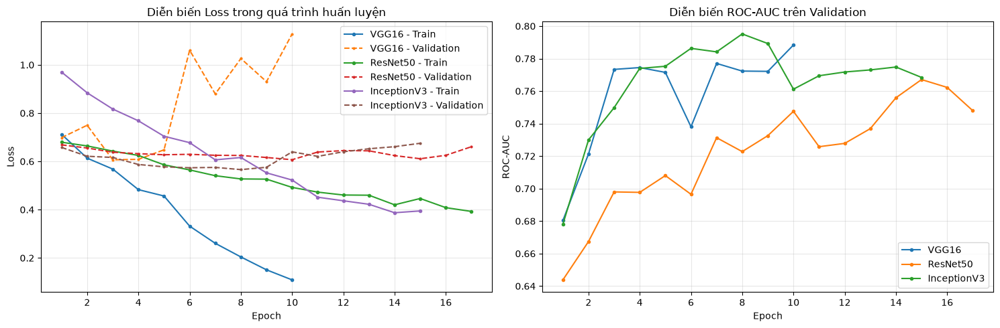


ĐÃ LƯU BIỂU ĐỒ:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_7_cnn_comparison\nb08_8_7_training_curves.png

ĐÃ LƯU LỊCH SỬ HUẤN LUYỆN:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_7_cnn_comparison\nb08_8_7_combined_training_history.csv

BẢNG TỔNG HỢP KẾT QUẢ:


,model,image_size,batch_size,epochs_completed,best_epoch,best_validation_loss,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_specificity,best_validation_f1,best_validation_roc_auc,total_training_minutes,peak_allocated_vram_gb,peak_reserved_vram_gb,checkpoint_path
0,VGG16,224,8,10,3,0.606518,0.659091,0.782609,0.418605,0.888889,0.545455,0.773356,7.753447,3.537709,4.031250,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...
1,ResNet50,224,8,17,10,0.607034,0.715909,0.754717,0.620155,0.807407,0.680851,0.747545,10.374152,2.398821,2.429688,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...
2,InceptionV3,299,8,15,8,0.565994,0.719697,0.689655,0.775194,0.666667,0.729927,0.795177,13.811568,1.658080,1.691406,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...



ĐÃ LƯU BẢNG SO SÁNH:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_7_cnn_comparison\nb08_8_7_model_comparison.csv

08.8.7 HOÀN TẤT — ĐÃ TỔNG HỢP LỊCH SỬ VÀ TRỰC QUAN HÓA QUÁ TRÌNH HUẤN LUYỆN.


In [27]:
# 08.8.7 — SO SÁNH VÀ TRỰC QUAN HÓA QUÁ TRÌNH HUẤN LUYỆN CNN

import json
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_8_cnn_training"
)

TRAINING_ROOT = OUTPUT_ROOT / "nb08_8_6_cnn_training"
ANALYSIS_ROOT = OUTPUT_ROOT / "nb08_8_7_cnn_comparison"
ANALYSIS_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = ["VGG16", "ResNet50", "InceptionV3"]

histories = {}
summaries = {}

for model_name in MODEL_NAMES:
    model_dir = TRAINING_ROOT / model_name

    history_files = list(model_dir.glob("*training_history*.csv"))
    summary_files = list(model_dir.glob("*summary*.json"))

    if not history_files:
        raise FileNotFoundError(
            f"Không tìm thấy lịch sử huấn luyện: {model_name}"
        )

    if not summary_files:
        raise FileNotFoundError(
            f"Không tìm thấy tệp tổng hợp: {model_name}"
        )

    history = pd.read_csv(history_files[0])

    with open(summary_files[0], "r", encoding="utf-8") as file:
        summary = json.load(file)

    # Chuẩn hóa cột tên mô hình, tránh tạo cột trùng
    history["model"] = model_name

    histories[model_name] = history
    summaries[model_name] = summary

    print(
        f"{model_name}: {len(history)} epoch | "
        f"{history_files[0].name}"
    )

# Kiểm tra dữ liệu lịch sử
print("\nCÁC CỘT LỊCH SỬ HUẤN LUYỆN")
for model_name, history in histories.items():
    print(f"\n{model_name}:")
    print(history.columns.tolist())

# Trực quan hóa Loss và ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for model_name, history in histories.items():
    epochs = history["epoch"]

    axes[0].plot(
        epochs,
        history["train_loss"],
        marker="o",
        markersize=3,
        label=f"{model_name} - Train"
    )

    axes[0].plot(
        epochs,
        history["validation_loss"],
        marker=".",
        markersize=4,
        linestyle="--",
        label=f"{model_name} - Validation"
    )

    axes[1].plot(
        epochs,
        history["validation_roc_auc"],
        marker="o",
        markersize=3,
        label=model_name
    )

axes[0].set_title("Diễn biến Loss trong quá trình huấn luyện")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Diễn biến ROC-AUC trên Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    ANALYSIS_ROOT / "nb08_8_7_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nĐÃ LƯU BIỂU ĐỒ:")
print(ANALYSIS_ROOT / "nb08_8_7_training_curves.png")

# Tổng hợp lịch sử của ba mô hình
combined_history = pd.concat(
    list(histories.values()),
    ignore_index=True
)

history_path = (
    ANALYSIS_ROOT / "nb08_8_7_combined_training_history.csv"
)

combined_history.to_csv(
    history_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nĐÃ LƯU LỊCH SỬ HUẤN LUYỆN:")
print(history_path)

# Tổng hợp kết quả checkpoint tốt nhất
summary_rows = []

for model_name, summary in summaries.items():
    row = {"model": model_name}
    row.update(summary)
    summary_rows.append(row)

summary_table = pd.DataFrame(summary_rows)

summary_path = ANALYSIS_ROOT / "nb08_8_7_model_comparison.csv"

summary_table.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nBẢNG TỔNG HỢP KẾT QUẢ:")
display(summary_table)

print("\nĐÃ LƯU BẢNG SO SÁNH:")
print(summary_path)

print(
    "\n08.8.7 HOÀN TẤT — "
    "ĐÃ TỔNG HỢP LỊCH SỬ VÀ TRỰC QUAN HÓA QUÁ TRÌNH HUẤN LUYỆN."
)


### Tóm tắt kết quả đánh giá trên Validation (Ngưỡng `0.5`)

| Mô hình | Val Loss | Accuracy | Precision | Recall | Specificity | F1-score | ROC-AUC | Nhận xét nổi bật |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **InceptionV3** | **0.5660** | - | - | - | - | **0.7299** | **0.7952** | Kết quả tổng thể nổi bật nhất (Loss thấp nhất, F1 & ROC-AUC cao nhất) |
| **ResNet50** | - | 0.7159 | - | 0.6202 | - | - | 0.7475 | Độ nhạy (Recall) khá nhưng ROC-AUC thấp nhất |
| **VGG16** | - | - | **0.7826** | 0.4186 | **0.8889** | - | - | Precision và Specificity cao nhất nhưng Recall thấp |

---

### Kết luận sơ bộ
* Ba mô hình thể hiện đặc tính phân loại khác biệt rõ rệt giữa độ nhạy (**Recall**) và độ đặc hiệu (**Specificity**).
* Chưa thể kết luận mô hình cuối cùng nếu chỉ đánh giá tại một ngưỡng phân loại cố định là `0.5`.

KIỂM TRA LẠI QUY TRÌNH ĐÁNH GIÁ CNN
Manifest: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_classification_dataset\mass_crops_20261117_015211\nb08_7_9_mass_crop_manifest.csv
Số mẫu Validation: 264
Phân bố nhãn:
binary_pathology
BENIGN       135
MALIGNANT    129
Name: count, dtype: int64
Thiết bị: cuda
AMP: True
Tiền xử lý: tái lập cách làm trong 08.8.6
Tập Test: KHÔNG ĐƯỢC SỬ DỤNG
TÌM KIẾM CHECKPOINT
Thư mục: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training
Số file: 3

VGG16
Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\VGG16\best_checkpoint.pth
Epoch: 3

ResNet50
Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\ResNet50\best_checkpoint.pth
Epoch: 10

InceptionV3
Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\InceptionV3\best_check

,model,checkpoint_path,checkpoint_epoch,checkpoint_accuracy,recalculated_accuracy,difference_accuracy,checkpoint_precision,recalculated_precision,difference_precision,checkpoint_recall,...,difference_roc_auc,checkpoint_TN,recalculated_TN,checkpoint_FP,recalculated_FP,checkpoint_FN,recalculated_FN,checkpoint_TP,recalculated_TP,checkpoint_match
0,VGG16,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,3,0.659091,0.659091,0.0,0.782609,0.782609,0.0,0.418605,...,0.0,120,120,15,15,75,75,54,54,True
1,ResNet50,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,10,0.715909,0.715909,0.0,0.754717,0.754717,0.0,0.620155,...,0.0,109,109,26,26,49,49,80,80,True
2,InceptionV3,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08...,8,0.719697,0.719697,0.0,0.689655,0.689655,0.0,0.775194,...,0.0,90,90,45,45,29,29,100,100,True



BẢNG SO SÁNH BA MÔ HÌNH VÀ BA NGƯỠNG


,model,threshold,accuracy,precision,recall,specificity,f1,roc_auc,TP,TN,FP,FN
0,VGG16,0.3,0.6894,0.6497,0.7907,0.5926,0.7133,0.7734,102,80,55,27
1,VGG16,0.5,0.6591,0.7826,0.4186,0.8889,0.5455,0.7734,54,120,15,75
2,VGG16,0.7,0.5758,0.8400,0.1628,0.9704,0.2727,0.7734,21,131,4,108
3,ResNet50,0.3,0.6402,0.6012,0.7829,0.5037,0.6801,0.7475,101,68,67,28
4,ResNet50,0.5,0.7159,0.7547,0.6202,0.8074,0.6809,0.7475,80,109,26,49
5,ResNet50,0.7,0.6553,0.7969,0.3953,0.9037,0.5285,0.7475,51,122,13,78
6,InceptionV3,0.3,0.6742,0.6103,0.9225,0.4370,0.7346,0.7952,119,59,76,10
7,InceptionV3,0.5,0.7197,0.6897,0.7752,0.6667,0.7299,0.7952,100,90,45,29
8,InceptionV3,0.7,0.6932,0.7449,0.5659,0.8148,0.6432,0.7952,73,110,25,56


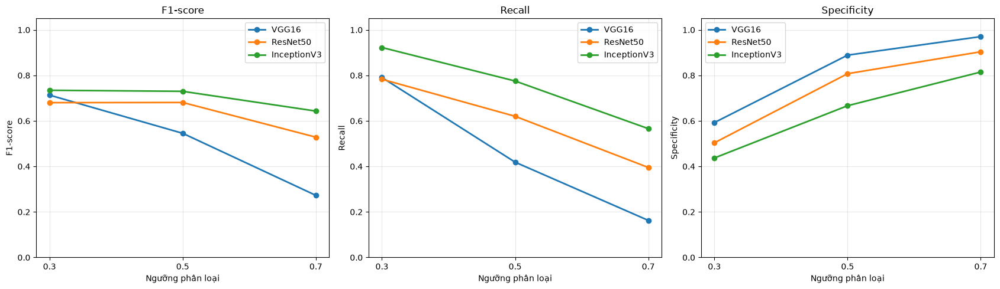


KẾT QUẢ LƯU TRỮ
Bảng kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_8_threshold_analysis\nb08_8_8_threshold_comparison_verified_v3.csv
Bảng đối chiếu: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_8_threshold_analysis\nb08_8_8_checkpoint_verification_v3.csv
Biểu đồ: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_8_threshold_analysis\nb08_8_8_threshold_metrics_verified_v3.png

CẢ BA MÔ HÌNH KHỚP CHECKPOINT.
Không ghi đè kết quả cũ.
Tập Test không được sử dụng.


In [36]:
# 08.8.8 — Đánh giá ngưỡng phân loại và kiểm tra checkpoint

from pathlib import Path
import time
import warnings
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
BATCH_SIZE = 8
NUM_WORKERS = 0
THRESHOLDS = [0.3, 0.5, 0.7]

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"

CROP_DIR = (
    OUTPUT_ROOT
    / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
)

MANIFEST_PATH = CROP_DIR / "nb08_7_9_mass_crop_manifest.csv"

CNN_ROOT = OUTPUT_ROOT / "nb08_8_cnn_training"

OUTPUT_DIR = CNN_ROOT / "nb08_8_8_threshold_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

CLASS_TO_INDEX = {
    "BENIGN": 0,
    "MALIGNANT": 1
}

MODEL_CONFIG = {
    "VGG16": {"image_size": 224},
    "ResNet50": {"image_size": 224},
    "InceptionV3": {"image_size": 299}
}


def chuan_hoa_ten_chi_so(name):
    name = str(name).strip().lower()
    name = name.replace("-", "_").replace(" ", "_")
    name = re.sub(r"[^a-z0-9_]", "", name)
    return name


def tim_gia_tri(metrics, aliases):
    if not isinstance(metrics, dict):
        return None

    normalized = {
        chuan_hoa_ten_chi_so(key): value
        for key, value in metrics.items()
    }

    for alias in aliases:
        key = chuan_hoa_ten_chi_so(alias)
        if key in normalized:
            value = normalized[key]
            if value is not None:
                return value

    return None


def lay_metrics_checkpoint(checkpoint):
    metrics = checkpoint.get("validation_metrics", {})

    if not isinstance(metrics, dict):
        raise TypeError("validation_metrics không phải dictionary.")

    aliases = {
        "accuracy": [
            "accuracy", "acc", "validation_accuracy"
        ],
        "precision": [
            "precision", "validation_precision"
        ],
        "recall": [
            "recall", "sensitivity", "validation_recall"
        ],
        "specificity": [
            "specificity", "validation_specificity"
        ],
        "f1": [
            "f1", "f1_score", "f1-score",
            "validation_f1", "validation_f1_score"
        ],
        "roc_auc": [
            "roc_auc", "auc", "validation_roc_auc",
            "validation_auc"
        ],
        "TN": ["TN", "tn", "true_negative"],
        "FP": ["FP", "fp", "false_positive"],
        "FN": ["FN", "fn", "false_negative"],
        "TP": ["TP", "tp", "true_positive"]
    }

    result = {}

    for metric_name, candidates in aliases.items():
        result[metric_name] = tim_gia_tri(
            metrics,
            candidates
        )

    return result


def tim_checkpoint_theo_model(root, model_names):
    checkpoint_files = (
        list(root.rglob("*.pth"))
        + list(root.rglob("*.pt"))
    )

    if not checkpoint_files:
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint trong: {root}"
        )

    found = {name: [] for name in model_names}

    print("=" * 70)
    print("TÌM KIẾM CHECKPOINT")
    print("=" * 70)
    print(f"Thư mục: {root}")
    print(f"Số file: {len(checkpoint_files)}")

    for file_path in checkpoint_files:
        try:
            checkpoint = torch.load(
                file_path,
                map_location="cpu",
                weights_only=False
            )

            if not isinstance(checkpoint, dict):
                continue

            model_name = checkpoint.get("model_name")

            if (
                model_name in model_names
                and "model_state_dict" in checkpoint
            ):
                found[model_name].append({
                    "path": file_path,
                    "epoch": checkpoint.get("epoch"),
                    "loss": checkpoint.get("best_validation_loss")
                })

        except Exception:
            continue

    selected = {}

    for model_name in model_names:
        candidates = found[model_name]

        if len(candidates) == 0:
            raise FileNotFoundError(
                f"Không tìm thấy checkpoint của {model_name}."
            )

        if len(candidates) == 1:
            selected[model_name] = candidates[0]
        else:
            candidates_with_loss = [
                item for item in candidates
                if item["loss"] is not None
            ]

            if len(candidates_with_loss) != len(candidates):
                raise RuntimeError(
                    f"Có nhiều checkpoint {model_name}, "
                    "không đủ thông tin để chọn."
                )

            selected[model_name] = min(
                candidates_with_loss,
                key=lambda item: float(item["loss"])
            )

        print(f"\n{model_name}")
        print(f"Đường dẫn: {selected[model_name]['path']}")
        print(f"Epoch: {selected[model_name]['epoch']}")

    return selected


def build_model(model_name):
    if model_name == "VGG16":
        model = models.vgg16(weights=None)
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, 2
        )

    elif model_name == "ResNet50":
        model = models.resnet50(weights=None)
        model.fc = nn.Linear(
            model.fc.in_features, 2
        )

    elif model_name == "InceptionV3":
        model = models.inception_v3(
            weights=None,
            aux_logits=True,
            init_weights=False,
            transform_input=True
        )

        model.fc = nn.Linear(
            model.fc.in_features, 2
        )

        if model.AuxLogits is not None:
            model.AuxLogits.fc = nn.Linear(
                model.AuxLogits.fc.in_features, 2
            )

        if model.transform_input is not True:
            raise RuntimeError(
                "InceptionV3 phải có transform_input=True."
            )

    else:
        raise ValueError(model_name)

    return model


class ValidationDataset(Dataset):
    def __init__(self, dataframe, image_size):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

        self.mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        self.std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = Path(row["crop_path"])

        image = Image.open(image_path).convert("RGB")

        width, height = image.size
        scale = self.image_size / max(width, height)

        new_width = max(1, int(round(width * scale)))
        new_height = max(1, int(round(height * scale)))

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "RGB",
            (self.image_size, self.image_size),
            (0, 0, 0)
        )

        left = (self.image_size - new_width) // 2
        top = (self.image_size - new_height) // 2

        canvas.paste(image, (left, top))

        array = np.asarray(
            canvas,
            dtype=np.float32
        ).copy() / 255.0

        tensor = torch.from_numpy(array).permute(2, 0, 1)
        tensor = (tensor - self.mean) / self.std

        return tensor, int(row["label"])


def tinh_chi_so(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "specificity": tn / (tn + fp) if tn + fp else 0,
        "f1": f1_score(
            labels, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(labels, probabilities),
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn)
    }


if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(MANIFEST_PATH)

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "dataset_split",
    "binary_pathology",
    "crop_path"
]

missing = [
    col for col in required_columns
    if col not in manifest.columns
]

if missing:
    raise ValueError(f"Manifest thiếu cột: {missing}")

val_df = manifest[
    manifest["dataset_split"].astype(str).str.strip().str.lower()
    == "validation"
].copy().reset_index(drop=True)

val_df["binary_pathology"] = (
    val_df["binary_pathology"].astype(str).str.strip().str.upper()
)

val_df["label"] = val_df["binary_pathology"].map(CLASS_TO_INDEX)

if val_df["label"].isna().any():
    raise ValueError("Có nhãn không hợp lệ.")

val_df["label"] = val_df["label"].astype(int)

if len(val_df) != 264:
    raise ValueError(f"Số mẫu Validation không đúng: {len(val_df)}")

if val_df["label"].nunique() != 2:
    raise ValueError("Validation không có đủ hai lớp.")

if not val_df["crop_path"].apply(
    lambda x: Path(x).is_file()
).all():
    raise FileNotFoundError("Có ảnh crop không tồn tại.")

print("=" * 70)
print("KIỂM TRA LẠI QUY TRÌNH ĐÁNH GIÁ CNN")
print("=" * 70)
print(f"Manifest: {MANIFEST_PATH}")
print(f"Số mẫu Validation: {len(val_df)}")
print("Phân bố nhãn:")
print(val_df["binary_pathology"].value_counts())
print(f"Thiết bị: {DEVICE}")
print(f"AMP: {USE_AMP}")
print("Tiền xử lý: tái lập cách làm trong 08.8.6")
print("Tập Test: KHÔNG ĐƯỢC SỬ DỤNG")

checkpoint_info = tim_checkpoint_theo_model(
    CNN_ROOT,
    list(MODEL_CONFIG.keys())
)

all_results = []
verification_results = []

for model_name, config in MODEL_CONFIG.items():

    print("\n" + "=" * 70)
    print(f"ĐÁNH GIÁ {model_name}")
    print("=" * 70)

    checkpoint_path = checkpoint_info[model_name]["path"]

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    image_size = int(
        checkpoint.get("image_size", config["image_size"])
    )

    if image_size != config["image_size"]:
        raise ValueError(
            f"Kích thước ảnh không khớp: {model_name}"
        )

    if checkpoint.get("class_to_index") != CLASS_TO_INDEX:
        raise ValueError(
            f"Ánh xạ nhãn không khớp: {model_name}"
        )

    dataset = ValidationDataset(val_df, image_size)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        drop_last=False
    )

    model = build_model(model_name)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(DEVICE)
    model.eval()

    if model_name == "InceptionV3":
        print(
            "InceptionV3 transform_input:",
            model.transform_input
        )

    labels_all = []
    probabilities_all = []

    start_time = time.time()

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(images)

                if hasattr(outputs, "logits"):
                    logits = outputs.logits
                elif isinstance(outputs, (tuple, list)):
                    logits = outputs[0]
                else:
                    logits = outputs

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]

            labels_all.extend(labels.numpy().tolist())
            probabilities_all.extend(
                probabilities.cpu().numpy().tolist()
            )

    elapsed = time.time() - start_time

    labels_all = np.asarray(labels_all, dtype=int)
    probabilities_all = np.asarray(
        probabilities_all,
        dtype=np.float64
    )

    if len(probabilities_all) != len(val_df):
        raise RuntimeError("Số mẫu dự đoán không khớp.")

    metrics_at_05 = tinh_chi_so(
        labels_all,
        probabilities_all,
        0.5
    )

    checkpoint_metrics = lay_metrics_checkpoint(checkpoint)

    print(f"Số mẫu dự đoán: {len(probabilities_all)}")
    print(f"Thời gian đánh giá: {elapsed:.2f} giây")

    print("\nĐỐI CHIẾU VỚI CHECKPOINT")

    row = {
        "model": model_name,
        "checkpoint_path": str(checkpoint_path),
        "checkpoint_epoch": checkpoint.get("epoch")
    }

    all_match = True

    for metric_name in [
        "accuracy", "precision", "recall",
        "specificity", "f1", "roc_auc"
    ]:

        expected = checkpoint_metrics.get(metric_name)
        actual = metrics_at_05[metric_name]

        if expected is None:
            print(
                f"{metric_name}: Checkpoint không lưu trực tiếp; "
                f"Tính lại={actual:.8f}"
            )
            row[f"checkpoint_{metric_name}"] = np.nan
            row[f"recalculated_{metric_name}"] = actual
            row[f"difference_{metric_name}"] = np.nan
            all_match = False
            continue

        expected = float(expected)
        difference = abs(expected - actual)

        print(
            f"{metric_name}: "
            f"Checkpoint={expected:.8f} | "
            f"Tính lại={actual:.8f} | "
            f"Chênh lệch={difference:.8f}"
        )

        row[f"checkpoint_{metric_name}"] = expected
        row[f"recalculated_{metric_name}"] = actual
        row[f"difference_{metric_name}"] = difference

        if difference > 1e-5:
            all_match = False

    for key in ["TN", "FP", "FN", "TP"]:

        expected = checkpoint_metrics.get(key)
        actual = metrics_at_05[key]

        row[f"checkpoint_{key}"] = (
            int(expected) if expected is not None else np.nan
        )
        row[f"recalculated_{key}"] = actual

        if expected is not None and int(expected) != actual:
            all_match = False

    row["checkpoint_match"] = all_match
    verification_results.append(row)

    print(
        "\nMa trận nhầm lẫn tại ngưỡng 0.5: "
        f"TN={metrics_at_05['TN']}, "
        f"FP={metrics_at_05['FP']}, "
        f"FN={metrics_at_05['FN']}, "
        f"TP={metrics_at_05['TP']}"
    )

    for threshold in THRESHOLDS:

        metrics = tinh_chi_so(
            labels_all,
            probabilities_all,
            threshold
        )

        all_results.append({
            "model": model_name,
            "threshold": threshold,
            **metrics
        })

    del model, dataset, loader, checkpoint

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


results_df = pd.DataFrame(all_results)
verification_df = pd.DataFrame(verification_results)

results_path = (
    OUTPUT_DIR
    / "nb08_8_8_threshold_comparison_verified_v3.csv"
)

verification_path = (
    OUTPUT_DIR
    / "nb08_8_8_checkpoint_verification_v3.csv"
)

plot_path = (
    OUTPUT_DIR
    / "nb08_8_8_threshold_metrics_verified_v3.png"
)

results_df.to_csv(
    results_path,
    index=False,
    encoding="utf-8-sig"
)

verification_df.to_csv(
    verification_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("BẢNG ĐỐI CHIẾU CHECKPOINT VÀ KẾT QUẢ TÍNH LẠI")
print("=" * 70)

display(
    verification_df.round(6)
)

print("\nBẢNG SO SÁNH BA MÔ HÌNH VÀ BA NGƯỠNG")

display(
    results_df[
        [
            "model", "threshold",
            "accuracy", "precision", "recall",
            "specificity", "f1", "roc_auc",
            "TP", "TN", "FP", "FN"
        ]
    ].round(4)
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics_to_plot = [
    ("f1", "F1-score"),
    ("recall", "Recall"),
    ("specificity", "Specificity")
]

for ax, (metric, title) in zip(axes, metrics_to_plot):

    for model_name in MODEL_CONFIG:

        subset = results_df[
            results_df["model"] == model_name
        ]

        ax.plot(
            subset["threshold"],
            subset[metric],
            marker="o",
            linewidth=2,
            label=model_name
        )

    ax.set_title(title)
    ax.set_xlabel("Ngưỡng phân loại")
    ax.set_ylabel(title)
    ax.set_xticks(THRESHOLDS)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\n" + "=" * 70)
print("KẾT QUẢ LƯU TRỮ")
print("=" * 70)
print(f"Bảng kết quả: {results_path}")
print(f"Bảng đối chiếu: {verification_path}")
print(f"Biểu đồ: {plot_path}")

if verification_df["checkpoint_match"].all():
    print("\nCẢ BA MÔ HÌNH KHỚP CHECKPOINT.")
else:
    print(
        "\nCÒN CHỈ SỐ CHƯA ĐƯỢC XÁC NHẬN HOẶC CHƯA KHỚP. "
        "Cần kiểm tra bảng đối chiếu trước khi kết luận."
    )

print("Không ghi đè kết quả cũ.")
print("Tập Test không được sử dụng.")


08.8.9 — TỔNG HỢP KẾT QUẢ HUẤN LUYỆN CNN VÀ QUẢN LÝ CHECKPOINT
Thư mục huấn luyện: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training
Thư mục kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_9_training_summary

KIỂM TRA ĐẦU VÀO
Số checkpoint đã xác minh: 3
Số cấu hình đánh giá ngưỡng: 9
Tình trạng xác minh: PASS

VGG16
  Số epoch huấn luyện: 10
  Epoch có Validation Loss thấp nhất: 3
  Validation Loss: 0.606518
  Checkpoint: best_checkpoint.pth

ResNet50
  Số epoch huấn luyện: 17
  Epoch có Validation Loss thấp nhất: 10
  Validation Loss: 0.607034
  Checkpoint: best_checkpoint.pth

InceptionV3
  Số epoch huấn luyện: 15
  Epoch có Validation Loss thấp nhất: 8
  Validation Loss: 0.565994
  Checkpoint: best_checkpoint.pth

BẢNG KẾT QUẢ VALIDATION TẠI NGƯỠNG 0.5
      model  threshold  accuracy  precision  recall  specificity     f1  roc_auc  TP  TN  FP  FN
      VGG16     0.5000    0.6591

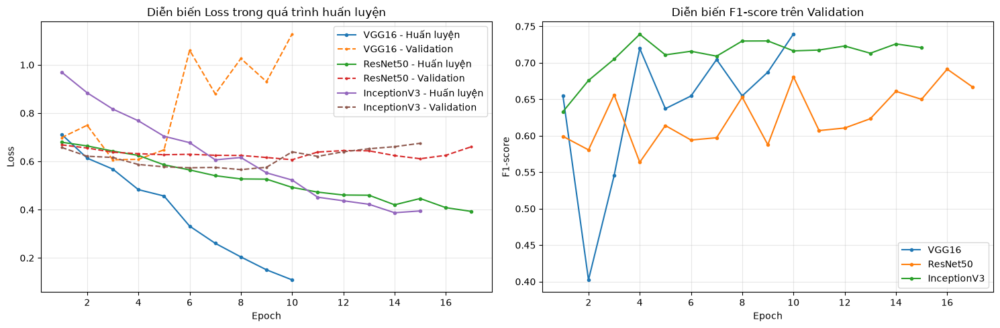


KẾT QUẢ HOÀN TẤT 08.8.9

TỔNG HỢP BA MÔ HÌNH
      model  total_epochs  best_epoch  best_validation_loss  validation_f1  validation_roc_auc
      VGG16            10           3                0.6065         0.5455              0.7734
   ResNet50            17          10                0.6070         0.6809              0.7475
InceptionV3            15           8                0.5660         0.7299              0.7952

KIỂM TRA CHECKPOINT
Số checkpoint: 3
Số checkpoint khớp: 3/3
Tính toàn vẹn tệp: PASS

CÁC TỆP ĐÃ LƯU
  C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_9_training_summary\nb08_8_9_combined_training_history.csv
  C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_9_training_summary\nb08_8_9_model_training_summary.csv
  C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_9_training_summary\nb08_8_9_threshold_summary.csv
  C:\Breast-Cancer-CBIS-DDSM\Data\pr

In [38]:
# 08.8.9 — TỔNG HỢP KẾT QUẢ HUẤN LUYỆN CNN VÀ QUẢN LÝ CHECKPOINT

import hashlib
import json

CNN_ROOT = (
    Path(r"C:\Breast-Cancer-CBIS-DDSM")
    / "Data" / "processed" / "nb08_model_training"
    / "nb08_8_cnn_training"
)

TRAIN_DIR = CNN_ROOT / "nb08_8_6_cnn_training"
COMPARISON_DIR = CNN_ROOT / "nb08_8_7_cnn_comparison"
THRESHOLD_DIR = CNN_ROOT / "nb08_8_8_threshold_analysis"

OUTPUT_DIR = CNN_ROOT / "nb08_8_9_training_summary"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = ["VGG16", "ResNet50", "InceptionV3"]
THRESHOLDS = [0.3, 0.5, 0.7]

print("=" * 75)
print("08.8.9 — TỔNG HỢP KẾT QUẢ HUẤN LUYỆN CNN VÀ QUẢN LÝ CHECKPOINT")
print("=" * 75)

print(f"Thư mục huấn luyện: {TRAIN_DIR}")
print(f"Thư mục kết quả: {OUTPUT_DIR}")

# 1. KIỂM TRA CÁC TỆP KẾT QUẢ ĐẦU VÀO

verification_path = (
    THRESHOLD_DIR / "nb08_8_8_checkpoint_verification_v3.csv"
)

threshold_path = (
    THRESHOLD_DIR / "nb08_8_8_threshold_comparison_verified_v3.csv"
)

if not verification_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy bảng xác minh checkpoint: {verification_path}"
    )

if not threshold_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy bảng phân tích ngưỡng: {threshold_path}"
    )

verification_df = pd.read_csv(verification_path)
threshold_df = pd.read_csv(threshold_path)

required_verification_columns = {
    "model",
    "checkpoint_path",
    "checkpoint_epoch",
    "checkpoint_match"
}

missing_columns = (
    required_verification_columns - set(verification_df.columns)
)

if missing_columns:
    raise ValueError(
        f"Bảng xác minh checkpoint thiếu cột: {sorted(missing_columns)}"
    )

required_threshold_columns = {
    "model",
    "threshold",
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc",
    "TP",
    "TN",
    "FP",
    "FN"
}

missing_columns = required_threshold_columns - set(threshold_df.columns)

if missing_columns:
    raise ValueError(
        f"Bảng phân tích ngưỡng thiếu cột: {sorted(missing_columns)}"
    )

if len(verification_df) != 3:
    raise ValueError(
        f"Cần đúng 3 checkpoint, hiện có {len(verification_df)} dòng."
    )

if len(threshold_df) != 9:
    raise ValueError(
        f"Cần đúng 9 kết quả (3 mô hình × 3 ngưỡng), "
        f"hiện có {len(threshold_df)} dòng."
    )

if not verification_df["checkpoint_match"].astype(bool).all():
    raise ValueError(
        "Có checkpoint chưa khớp kết quả đánh giá. "
        "Không thể xác nhận hoàn tất bước tổng hợp."
    )

print("\nKIỂM TRA ĐẦU VÀO")
print(f"Số checkpoint đã xác minh: {len(verification_df)}")
print(f"Số cấu hình đánh giá ngưỡng: {len(threshold_df)}")
print("Tình trạng xác minh: PASS")

# 2. TỔNG HỢP LỊCH SỬ HUẤN LUYỆN

history_records = []
summary_records = []

for model_name in MODEL_NAMES:

    history_filename = f"{model_name.lower()}_training_history.csv"

    history_candidates = list(TRAIN_DIR.rglob(history_filename))

    if len(history_candidates) == 0:
        raise FileNotFoundError(
            f"Không tìm thấy lịch sử huấn luyện của {model_name}: "
            f"{history_filename}"
        )

    if len(history_candidates) > 1:
        raise RuntimeError(
            f"Có nhiều tệp lịch sử của {model_name}. "
            "Cần kiểm tra để tránh chọn nhầm tệp."
        )

    history_path = history_candidates[0]
    history = pd.read_csv(history_path)

    required_history_columns = {
        "epoch",
        "train_loss",
        "validation_loss",
        "validation_accuracy",
        "validation_precision",
        "validation_recall",
        "validation_specificity",
        "validation_f1",
        "validation_roc_auc"
    }

    missing = required_history_columns - set(history.columns)

    if missing:
        raise ValueError(
            f"Lịch sử {model_name} thiếu cột: {sorted(missing)}"
        )

    history["model"] = model_name
    history_records.append(history)

    best_index = history["validation_loss"].idxmin()
    best_row = history.loc[best_index]

    checkpoint_row = verification_df.loc[
        verification_df["model"].astype(str).str.lower()
        == model_name.lower()
    ]

    if len(checkpoint_row) != 1:
        raise ValueError(
            f"Không xác định được duy nhất checkpoint của {model_name}."
        )

    checkpoint_row = checkpoint_row.iloc[0]

    checkpoint_path = Path(str(checkpoint_row["checkpoint_path"]))

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Checkpoint không tồn tại: {checkpoint_path}"
        )

    checkpoint_epoch = int(checkpoint_row["checkpoint_epoch"])
    history_best_epoch = int(best_row["epoch"])

    if checkpoint_epoch != history_best_epoch:
        raise ValueError(
            f"Epoch checkpoint của {model_name} không khớp "
            f"epoch có validation_loss thấp nhất trong lịch sử."
        )

    summary_records.append({
        "model": model_name,
        "total_epochs": int(len(history)),
        "best_epoch": history_best_epoch,
        "best_train_loss": float(best_row["train_loss"]),
        "best_validation_loss": float(best_row["validation_loss"]),
        "validation_accuracy": float(best_row["validation_accuracy"]),
        "validation_precision": float(best_row["validation_precision"]),
        "validation_recall": float(best_row["validation_recall"]),
        "validation_specificity": float(best_row["validation_specificity"]),
        "validation_f1": float(best_row["validation_f1"]),
        "validation_roc_auc": float(best_row["validation_roc_auc"]),
        "checkpoint_path": str(checkpoint_path),
        "checkpoint_match": bool(checkpoint_row["checkpoint_match"])
    })

    print(f"\n{model_name}")
    print(f"  Số epoch huấn luyện: {len(history)}")
    print(f"  Epoch có Validation Loss thấp nhất: {history_best_epoch}")
    print(f"  Validation Loss: {best_row['validation_loss']:.6f}")
    print(f"  Checkpoint: {checkpoint_path.name}")

history_all = pd.concat(history_records, ignore_index=True)
summary_df = pd.DataFrame(summary_records)

# 3. TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ BA NGƯỠNG

threshold_summary = threshold_df.copy()

threshold_summary["model"] = pd.Categorical(
    threshold_summary["model"],
    categories=MODEL_NAMES,
    ordered=True
)

threshold_summary = threshold_summary.sort_values(
    ["model", "threshold"]
).reset_index(drop=True)

for model_name in MODEL_NAMES:
    model_thresholds = threshold_summary[
        threshold_summary["model"] == model_name
    ]["threshold"].astype(float).tolist()

    if sorted(model_thresholds) != THRESHOLDS:
        raise ValueError(
            f"Ngưỡng đánh giá của {model_name} không đúng "
            f"ba ngưỡng {THRESHOLDS}."
        )

print("\nBẢNG KẾT QUẢ VALIDATION TẠI NGƯỠNG 0.5")

threshold_05 = threshold_summary[
    threshold_summary["threshold"].astype(float) == 0.5
].copy()

display_columns = [
    "model", "threshold", "accuracy", "precision",
    "recall", "specificity", "f1", "roc_auc",
    "TP", "TN", "FP", "FN"
]

print(
    threshold_05[display_columns]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

# 4. LẬP DANH MỤC VÀ KIỂM TRA TÍNH TOÀN VẸN CHECKPOINT

def tinh_sha256(file_path, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


checkpoint_records = []

for _, row in verification_df.iterrows():

    model_name = str(row["model"])
    checkpoint_path = Path(str(row["checkpoint_path"]))

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    if not isinstance(checkpoint, dict):
        raise TypeError(
            f"Checkpoint {model_name} không có cấu trúc dict."
        )

    if "model_state_dict" not in checkpoint:
        raise KeyError(
            f"Checkpoint {model_name} thiếu model_state_dict."
        )

    if "best_validation_loss" not in checkpoint:
        raise KeyError(
            f"Checkpoint {model_name} thiếu best_validation_loss."
        )

    checkpoint_model_name = checkpoint.get("model_name")

    if (
        checkpoint_model_name is not None
        and str(checkpoint_model_name).lower() != model_name.lower()
    ):
        raise ValueError(
            f"Tên mô hình trong checkpoint không khớp: {model_name}"
        )

    checkpoint_records.append({
        "model": model_name,
        "checkpoint_path": str(checkpoint_path),
        "checkpoint_filename": checkpoint_path.name,
        "checkpoint_epoch": int(row["checkpoint_epoch"]),
        "best_validation_loss": float(
            checkpoint["best_validation_loss"]
        ),
        "file_size_MB": round(
            checkpoint_path.stat().st_size / (1024 ** 2), 4
        ),
        "sha256": tinh_sha256(checkpoint_path),
        "state_dict_parameters": len(
            checkpoint["model_state_dict"]
        ),
        "checkpoint_match": bool(row["checkpoint_match"]),
        "integrity_status": "PASS"
    })

    del checkpoint

checkpoint_inventory = pd.DataFrame(checkpoint_records)

print("\nDANH MỤC CHECKPOINT")
print(
    checkpoint_inventory[
        [
            "model",
            "checkpoint_epoch",
            "best_validation_loss",
            "file_size_MB",
            "state_dict_parameters",
            "integrity_status"
        ]
    ].to_string(index=False)
)

# 5. LƯU CÁC BẢNG TỔNG HỢP

history_output = (
    OUTPUT_DIR / "nb08_8_9_combined_training_history.csv"
)

summary_output = (
    OUTPUT_DIR / "nb08_8_9_model_training_summary.csv"
)

threshold_output = (
    OUTPUT_DIR / "nb08_8_9_threshold_summary.csv"
)

checkpoint_output = (
    OUTPUT_DIR / "nb08_8_9_checkpoint_inventory.csv"
)

history_all.to_csv(
    history_output,
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    summary_output,
    index=False,
    encoding="utf-8-sig"
)

threshold_summary.to_csv(
    threshold_output,
    index=False,
    encoding="utf-8-sig"
)

checkpoint_inventory.to_csv(
    checkpoint_output,
    index=False,
    encoding="utf-8-sig"
)

# 6. VẼ BIỂU ĐỒ TỔNG HỢP QUÁ TRÌNH HUẤN LUYỆN

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for model_name in MODEL_NAMES:

    model_history = history_all[
        history_all["model"] == model_name
    ].sort_values("epoch")

    axes[0].plot(
        model_history["epoch"],
        model_history["train_loss"],
        marker="o",
        markersize=3,
        label=f"{model_name} - Huấn luyện"
    )

    axes[0].plot(
        model_history["epoch"],
        model_history["validation_loss"],
        marker=".",
        markersize=4,
        linestyle="--",
        label=f"{model_name} - Validation"
    )

    axes[1].plot(
        model_history["epoch"],
        model_history["validation_f1"],
        marker="o",
        markersize=3,
        label=model_name
    )

axes[0].set_title("Diễn biến Loss trong quá trình huấn luyện")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Diễn biến F1-score trên Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("F1-score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plot_output = (
    OUTPUT_DIR / "nb08_8_9_training_summary.png"
)

plt.savefig(
    plot_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# 7. LƯU THÔNG TIN TỔNG KẾT

report = {
    "section": "08.8.9",
    "section_name": "Tổng hợp kết quả huấn luyện CNN và quản lý Checkpoint",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "models": MODEL_NAMES,
    "training_epochs": {
        row["model"]: row["total_epochs"]
        for row in summary_records
    },
    "best_epochs": {
        row["model"]: row["best_epoch"]
        for row in summary_records
    },
    "validation_samples": 264,
    "validation_class_distribution": {
        "BENIGN": 135,
        "MALIGNANT": 129
    },
    "thresholds_evaluated": THRESHOLDS,
    "checkpoint_verification": {
        "total": len(checkpoint_inventory),
        "passed": int(
            checkpoint_inventory["integrity_status"].eq("PASS").sum()
        ),
        "all_matched": bool(
            checkpoint_inventory["checkpoint_match"].all()
        )
    },
    "test_set_used": False,
    "original_checkpoints_overwritten": False,
    "output_directory": str(OUTPUT_DIR),
    "output_files": [
        history_output.name,
        summary_output.name,
        threshold_output.name,
        checkpoint_output.name,
        plot_output.name,
        "nb08_8_9_summary.json"
    ]
}

report_output = OUTPUT_DIR / "nb08_8_9_summary.json"

with open(report_output, "w", encoding="utf-8") as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=4
    )

# 8. KIỂM TRA KẾT QUẢ CUỐI CÙNG

expected_files = [
    history_output,
    summary_output,
    threshold_output,
    checkpoint_output,
    plot_output,
    report_output
]

missing_outputs = [
    str(path) for path in expected_files
    if not path.exists()
]

if missing_outputs:
    raise RuntimeError(
        f"Các tệp đầu ra chưa được tạo đầy đủ: {missing_outputs}"
    )

if len(checkpoint_inventory) != 3:
    raise RuntimeError("Số checkpoint tổng hợp không bằng 3.")

if not checkpoint_inventory["checkpoint_match"].all():
    raise RuntimeError("Có checkpoint chưa được xác minh khớp.")

print("\n" + "=" * 75)
print("KẾT QUẢ HOÀN TẤT 08.8.9")
print("=" * 75)

print("\nTỔNG HỢP BA MÔ HÌNH")
print(
    summary_df[
        [
            "model",
            "total_epochs",
            "best_epoch",
            "best_validation_loss",
            "validation_f1",
            "validation_roc_auc"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\nKIỂM TRA CHECKPOINT")
print(f"Số checkpoint: {len(checkpoint_inventory)}")
print(
    "Số checkpoint khớp: "
    f"{int(checkpoint_inventory['checkpoint_match'].sum())}/3"
)
print("Tính toàn vẹn tệp: PASS")

print("\nCÁC TỆP ĐÃ LƯU")
for path in expected_files:
    print(f"  {path}")

print("\nTẬP TEST: KHÔNG SỬ DỤNG")
print("Checkpoint gốc: KHÔNG GHI ĐÈ")
print("KẾT QUẢ: PASS")
print("=" * 75)


### TỔNG KẾT NOTEBOOK 08 — HUẤN LUYỆN VÀ TỐI ƯU HÓA MÔ HÌNH

Notebook 08 hoàn thành việc huấn luyện và tối ưu hóa các mô hình cho hệ thống **Two-stage Pipeline** trên tập dữ liệu CBIS-DDSM Mass (tuân thủ chia tập theo *Patient ID*; giữ nguyên tập **Test** độc lập).

---

## 1. Giai đoạn 1: Phát hiện & Định vị Mass (YOLOv5n)

Thực nghiệm các cấu hình YOLOv5n trên tập Validation được triển khai với số epoch khác nhau tùy giai đoạn huấn luyện và tối ưu hóa:

| Chỉ số | YOLOv5n (640×640) | YOLOv5n (1024×1024) | Fine-tuned (640×640) |
| :--- | :---: | :---: | :---: |
| **Số Epoch** | 30 | 30 | 12 |
| **Batch Size** | 4 | 1 | 4 |
| **Thời gian (phút)** | 431,36 | 595,84 | — |
| **Precision** | 0,73111 | — | 0,56632 |
| **Recall** | 0,86742 | — | 0,60985 |
| **`mAP@0.5`** | 0,59867 | 0,59878 | **0,60121** |
| **`mAP@0.5:0.95`** | 0,25263 | 0,24694 | **0,25610** |

> *Lưu ý phương pháp đo:* Các chỉ số Precision, Recall và mAP trong bảng trên được ghi nhận tại epoch đạt giá trị tốt nhất tương ứng trong quá trình huấn luyện (ví dụ: ở Baseline 640×640, Precision cao nhất tại epoch 14, Recall cao nhất tại epoch 1, mAP cao nhất tại epoch 29); do đó, không nhất thiết thuộc cùng một epoch.

* **Nhận xét chính**:
  * Cấu hình $1024 \times 1024$ đạt `mAP@0.5` tương đương $640 \times 640$ nhưng tốn thời gian hơn (do khác biệt về `Batch Size`, chưa thể tách bạch ảnh hưởng riêng lẻ của độ phân giải).
  * Quá trình Fine-tuning và điều chỉnh ngưỡng (`Confidence` / `NMS IoU`) cải thiện khả năng thu hồi tổn thương (Recall) nhưng làm tăng số lượng dự đoán sai (*False Positives*), đòi hỏi tối ưu đồng thời cả `Precision`, `Recall` và `F1-score`.

---

## 2. Giai đoạn 2: Xây dựng dữ liệu & Phân loại Mass (CNN)

### 2.1. Tập dữ liệu ảnh Crop
Trích xuất thành công **1.696 / 1.696** ảnh Crop từ Ground Truth Bounding Box (mở rộng thêm **10%** vùng biên ngữ cảnh) và gộp nhãn nhị phân:
* **Train**: 1.054 mẫu (546 `BENIGN` | 508 `MALIGNANT`)
* **Validation**: 264 mẫu (135 `BENIGN` | 129 `MALIGNANT`)
* **Test**: 378 mẫu (231 `BENIGN` | 147 `MALIGNANT`)

### 2.2. So sánh hiệu suất 3 mô hình CNN (tại Checkpoint tốt nhất)
Cấu hình chung: Pretrained ImageNet, `Batch Size = 8`, tối đa 30 epochs, `AdamW`, `Early Stopping`, `ReduceLROnPlateau` và `Mixed Precision`.

| Chỉ số (Validation) | VGG16 | ResNet50 | InceptionV3 |
| :--- | :---: | :---: | :---: |
| **Epoch tốt nhất / Tổng** | 3 / 10 | 10 / 17 | 8 / 15 |
| **Validation Loss** | 0,606518 | 0,607034 | **0,565994** |
| **Accuracy** | 0,659091 | 0,715909 | **0,719697** |
| **Precision** | **0,782609** | 0,754717 | 0,689655 |
| **Recall** | 0,418605 | 0,620155 | **0,775194** |
| **Specificity** | **0,888889** | 0,807407 | 0,666667 |
| **F1-score** | 0,545455 | 0,680851 | **0,729927** |
| **ROC-AUC** | 0,773356 | 0,747545 | **0,795177** |

* **Phân tích ngưỡng phân loại (`0.3`, `0.5`, `0.7`)**:
  * Giảm ngưỡng xuống **0.3** giúp tăng `Recall`, qua đó giảm số trường hợp `MALIGNANT` bị bỏ sót trên tập Validation, nhưng đồng thời làm tăng *False Positive*. Đây là một xu hướng có thể cân nhắc khi nghiên cứu bài toán ưu tiên khả năng thu hồi mẫu `MALIGNANT` (tại ngưỡng 0.3, **InceptionV3** đạt `F1-score` cao nhất là **0,7346**).
  * Tăng ngưỡng lên **0.7** giúp tăng `Precision` và `Specificity` (**VGG16** đạt Specificity **0,9704** nhưng Recall giảm sâu còn 0,1628).
  * **InceptionV3** thể hiện hiệu năng tổng thể vượt trội nhất trên Validation nhưng cần kiểm chứng thêm trên tập Test.

### 2.3. Xác minh Checkpoint
Cả 3 checkpoint tốt nhất của `VGG16` (Epoch 3), `ResNet50` (Epoch 10) và `InceptionV3` (Epoch 8) đều đạt trạng thái **PASS**: tính toàn vẹn tệp được xác nhận bằng mã băm **SHA-256**, và khả năng tái lập được xác nhận thông qua đối chiếu các chỉ số đánh giá khớp hoàn toàn khi nạp lại mô hình.

---

## 3. Giới hạn & Định hướng Notebook 09

* **Giới hạn hiện tại**: Quy mô dữ liệu Mass còn khiêm tốn; mô hình CNN mới chỉ đánh giá trên *Ground Truth Crop* nên chưa phản ánh đầy đủ sai số dây chuyền từ bước phát hiện của YOLOv5n.
* **Kế hoạch Notebook 09 (Đánh giá & Phân tích lỗi)**:
  1. Đánh giá khả năng phát hiện và định vị của **YOLOv5n** trên tập Test bằng `Precision`, `Recall`, `mAP` và các tiêu chí định vị không gian.
  2. Đánh giá độc lập 3 mô hình **CNN** trên tập Test bằng các chỉ số phân loại.
  3. Phân tích chuyên sâu lỗi qua *Confusion Matrix*, *ROC Curve*, *PR Curve* và các ca *False Positives*.
  4. Khi đánh giá CNN trên vùng Crop dự đoán từ YOLOv5n (đánh giá end-to-end của toàn bộ **Two-stage Pipeline**), cần phân tích **cả trường hợp không phát hiện được tổn thương (False Negative ở Stage 1) và trường hợp phát hiện sai (False Positive ở Stage 1)**, không chỉ đánh giá trên những Crop dự đoán thành công để tránh đánh giá quá lạc quan hiệu quả hệ thống.
  5. Tổng hợp kết quả để chọn cấu hình tối ưu cho bước trực quan hóa và triển khai **Web Demo**.